<a href="https://colab.research.google.com/github/mdsantia/FEM_repro/blob/main/FEM_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [108]:
!wget "https://fem-on-colab.github.io/releases/firedrake-install-release-real.sh" \
        -O "/tmp/firedrake-install.sh"

!bash "/tmp/firedrake-install.sh"
# !rm -r ./*
import os
import sys

PROJECT_ROOT = "/content/fem-matrix-free"

os.makedirs(PROJECT_ROOT, exist_ok=True)
os.makedirs(f"{PROJECT_ROOT}/markdowns", exist_ok=True)
os.makedirs(f"{PROJECT_ROOT}/src", exist_ok=True)
os.makedirs(f"{PROJECT_ROOT}/tests", exist_ok=True)
os.makedirs(f"{PROJECT_ROOT}/experiments", exist_ok=True)
os.makedirs(f"{PROJECT_ROOT}/results", exist_ok=True)

# Add project root to Python import path
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Set working directory
os.chdir(PROJECT_ROOT)

print("Working directory:", os.getcwd())

--2026-11-24 07:38:20--  https://fem-on-colab.github.io/releases/firedrake-install-release-real.sh
Resolving fem-on-colab.github.io (fem-on-colab.github.io)... 185.199.108.153, 185.199.109.153, 185.199.110.153, ...
Connecting to fem-on-colab.github.io (fem-on-colab.github.io)|185.199.108.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4868 (4.8K) [application/x-sh]
Saving to: ‘/tmp/firedrake-install.sh’

/tmp/firedrake-inst 100%[===================>]   4.75K  --.-KB/s    in 0s      

2026-11-24 07:38:20 (35.7 MB/s) - ‘/tmp/firedrake-install.sh’ saved [4868/4868]

+ INSTALL_PREFIX=/usr/local
++ echo /usr/local
++ awk -F/ '{print NF-1}'
+ INSTALL_PREFIX_DEPTH=2
+ PROJECT_NAME=fem-on-colab
+ SHARE_PREFIX=/usr/local/share/fem-on-colab
+ FIREDRAKE_INSTALLED=/usr/local/share/fem-on-colab/firedrake.installed
+ [[ ! -f /usr/local/share/fem-on-colab/firedrake.installed ]]
+ set +x
























#############################################################

In [144]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# File structure
```text
fem-matrix-free/
├── README.md
├── environment.yml or requirements notes
├── src/
│   ├── problem.py
│   ├── assembled.py
│   ├── firedrake_matfree.py
│   ├── local_operator.py
│   ├── functionals.py
│   └── diagnostics.py
├── experiments/
│   ├── convergence.py
│   ├── access_model.py
│   └── operator_equivalence.py
├── tests/
│   ├── test_single_element.py
│   ├── test_operator_action.py
│   └── test_functionals.py
└── results/
```
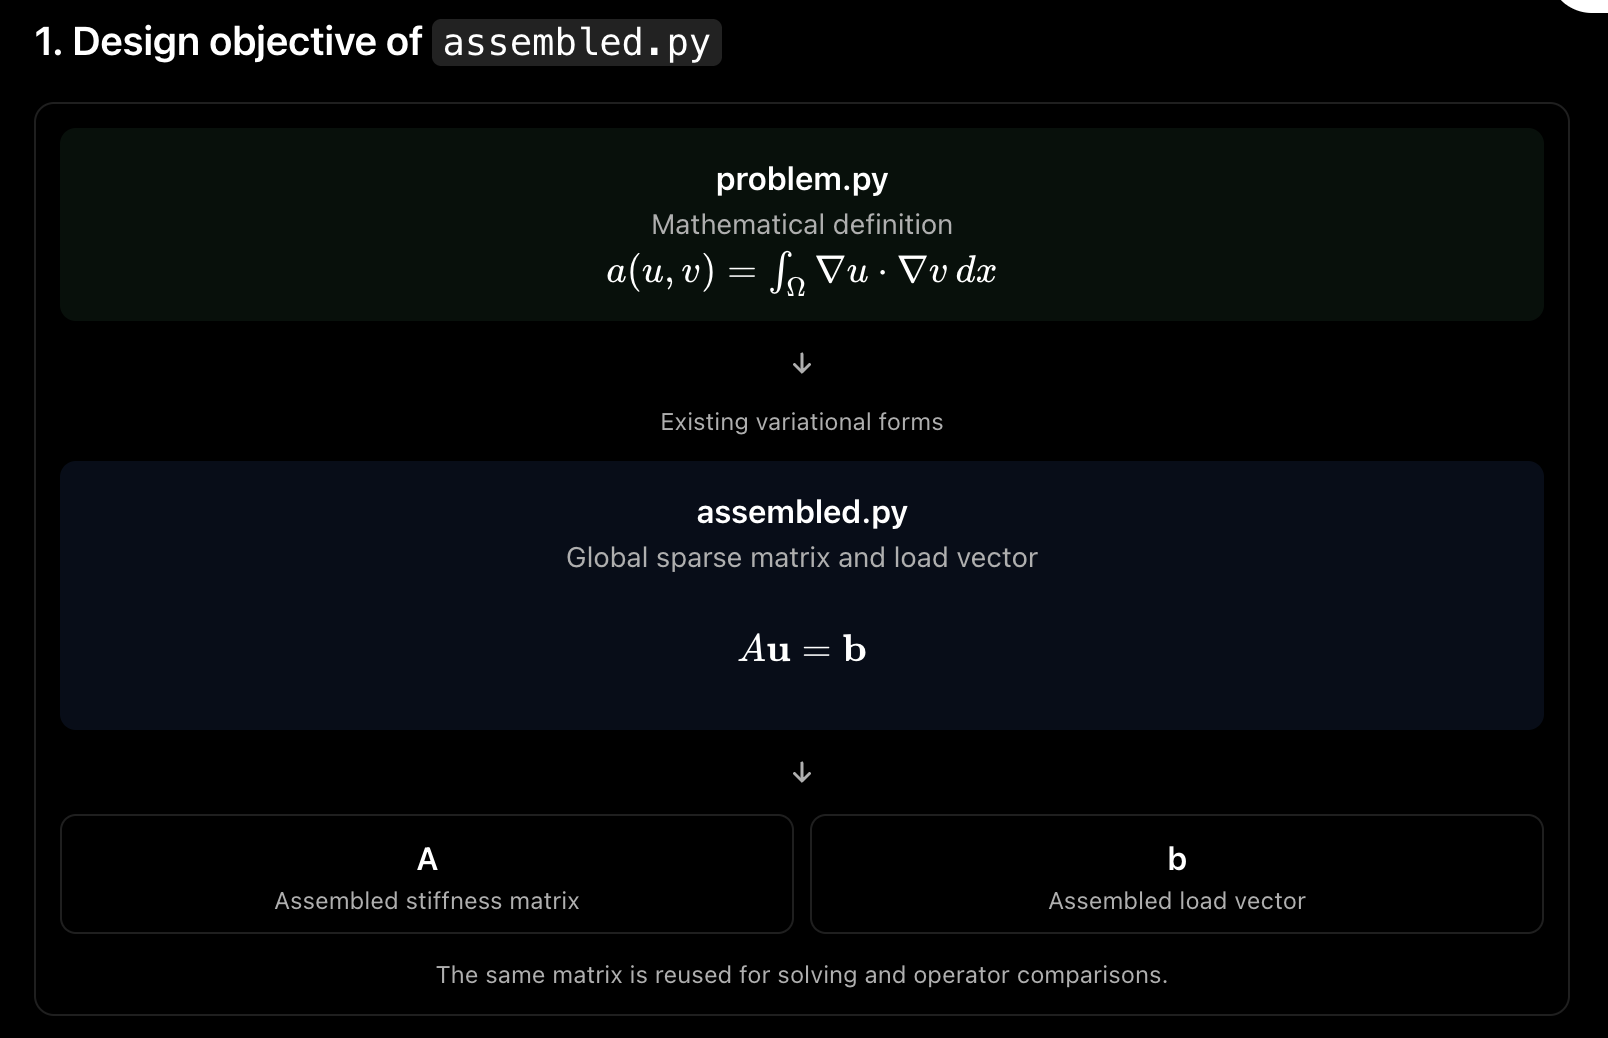

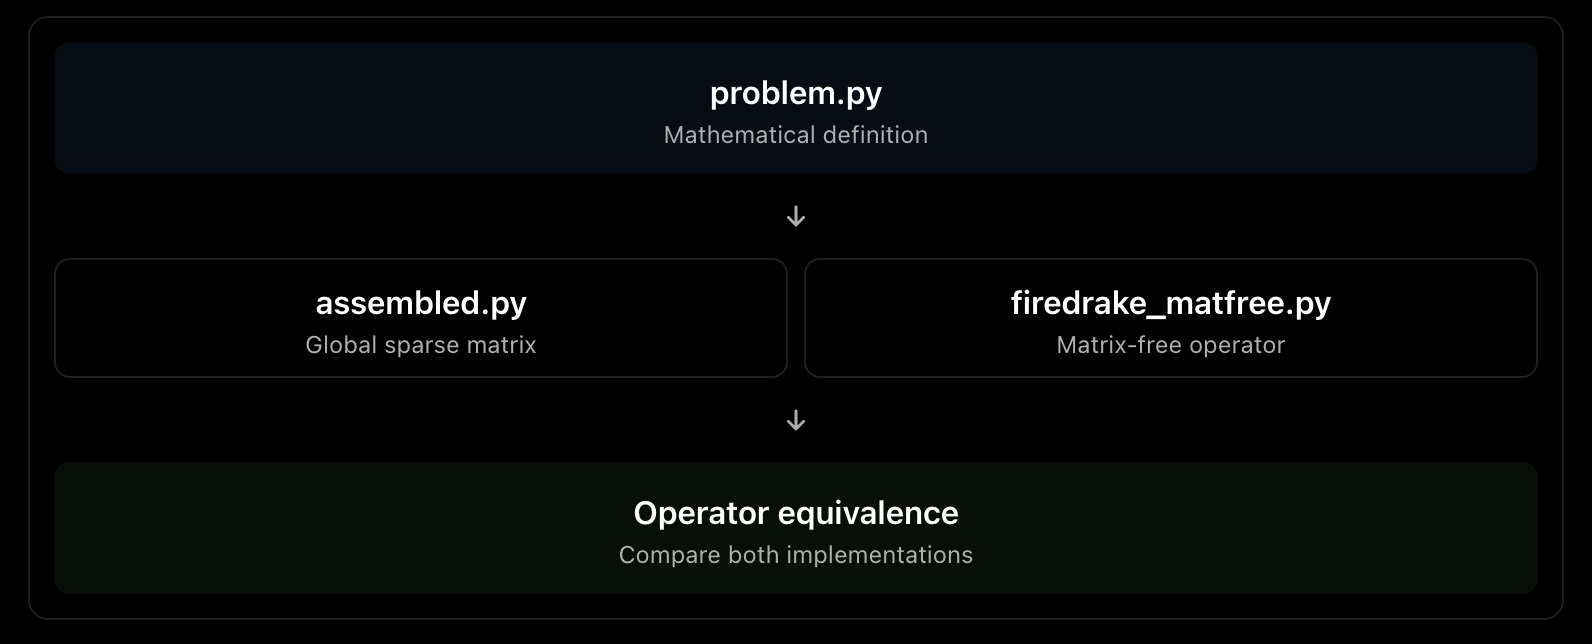

## Markdowns

In [109]:
%%writefile markdowns/solvers.md
# Matrix-Free Finite Element Methods: Implementation Design

## 1. Project objective

This project develops and validates three implementations of the same conforming finite-element discretization of the Poisson equation:

1. an explicitly assembled sparse operator;
2. Firedrake's matrix-free operator;
3. an independent element-local operator implemented with NumPy and exposed to PETSc through a Python matrix.

The implementations are developed in stages so that mathematical correctness, algebraic equivalence, solver behavior, and finite-element convergence can be tested separately. The assembled implementation is the numerical reference. The independent local operator is the principal object of study because its gather, element-action, and scatter-add structure makes the local data requirements explicit.

The manufactured problem is

$$
-\Delta u=f \quad \text{in } \Omega=(0,1)^2,
\qquad
u=0 \quad \text{on } \partial\Omega,
$$

with exact solution and forcing

$$
u_{\mathrm{exact}}(x,y)=\sin(\pi x)\sin(\pi y),
$$

$$
f(x,y)=2\pi^2\sin(\pi x)\sin(\pi y).
$$

The conforming finite-element space uses continuous Lagrange elements on affine triangular meshes. The initial implementation and experiments use polynomial degree one.

The expected discretization-error rates are

$$
\|u-u_h\|_{L^2(\Omega)}=O(h^2),
\qquad
|u-u_h|_{H^1(\Omega)}=O(h).
$$

---

## 2. File structure

```text
fem-matrix-free/
├── README.md
├── environment.yml or requirements notes
├── src/
│   ├── __init__.py
│   ├── problem.py
│   ├── assembled.py
│   ├── firedrake_matfree.py
│   ├── local_operator.py
│   ├── functionals.py
│   └── diagnostics.py
├── experiments/
│   ├── convergence.py
│   └── operator_equivalence.py
├── tests/
│   ├── test_problem.py
│   ├── test_assembled.py
│   ├── test_firedrake_matfree.py
│   ├── test_single_element.py
│   ├── test_local_operator.py
│   └── test_functionals.py
└── results/
```

The current implemented sequence is:

```text
problem.py
    ↓
assembled.py
    ↓
firedrake_matfree.py
    ↓
local_operator.py
```

The remaining modules will use these implementations rather than redefine the PDE or operators.

---

# 3. `src/problem.py`

## 3.1 Purpose

`problem.py` is the mathematical source of truth. It defines the mesh, function space, manufactured solution, forcing term, weak form, boundary condition, and finite-element error measures.

It must not choose a matrix representation, preconditioner, or Krylov solver. Those decisions belong to the operator-specific modules.

## 3.2 Mathematical definition

The weak problem is: find $u\in H_0^1(\Omega)$ such that

$$
a(u,v)=L(v)
\qquad \text{for every } v\in H_0^1(\Omega),
$$

where

$$
a(u,v)=\int_\Omega \nabla u\cdot\nabla v\,dx,
$$

and

$$
L(v)=\int_\Omega f v\,dx.
$$

The analytical gradient used for the $H^1$-seminorm error is

$$
\nabla u_{\mathrm{exact}}=
\begin{bmatrix}
\pi\cos(\pi x)\sin(\pi y)\\
\pi\sin(\pi x)\cos(\pi y)
\end{bmatrix}.
$$

## 3.3 Main data structure

`PoissonProblem` stores:

- the mesh;
- the finite-element space `V`;
- trial and test functions;
- the exact solution;
- the analytical exact gradient;
- the forcing term;
- the bilinear form `a`;
- the linear form `L`;
- the homogeneous Dirichlet condition;
- the nominal mesh size `h`;
- polynomial degree;
- refinement level;
- triangle-diagonal convention.

This object is passed unchanged to every solver implementation. Consequently, differences among assembled, Firedrake matrix-free, and independent local results cannot originate from separately defined PDEs.

## 3.4 Main functions

### `create_mesh(refinement_level, diagonal="left")`

Creates `UnitSquareMesh(N, N)` with

$$
N=2^{\text{refinement level}},
\qquad h=\frac{1}{N}.
$$

The stored value $h$ is the Cartesian grid spacing. The maximum diameter of the resulting right triangles is $\sqrt{2}h$.

### `exact_solution(mesh)`

Returns the UFL expression $\sin(\pi x)\sin(\pi y)$.

### `exact_gradient(mesh)`

Returns the analytical gradient explicitly, independently of `grad(u_exact)`.

### `forcing_term(mesh)`

Returns $f=-\Delta u_{\mathrm{exact}}$.

### `create_problem(...)`

Creates the mesh, function space, forms, and boundary condition and returns a `PoissonProblem`.

### `empty_solution(problem, name="u_h")`

Allocates an unsolved Firedrake `Function` in the problem space.

### Error routines

The current draft includes:

```python
l2_error(problem, u_h)
h1_seminorm_error(problem, u_h)
energy_error(problem, u_h)
assemble_scalar(form)
```

For the unit-diffusion Poisson problem, the energy norm equals the $H^1$ seminorm.

## 3.5 Tests for `problem.py`

The current test draft verifies:

1. mesh and function-space construction;
2. positive function-space dimension;
3. exact-solution interpolation;
4. zero exact solution on boundary nodes;
5. agreement between the analytical forcing and $-\nabla\cdot\nabla u_{\mathrm{exact}}$;
6. successful assembly of the bilinear and linear forms;
7. positive energy for a nonzero finite-element function;
8. a finite and reasonably accurate numerical solution;
9. correct mesh-size value;
10. agreement between the analytical gradient and `grad(u_exact)`;
11. correct empty-solution allocation;
12. unit-square area from scalar assembly;
13. finite $L^2$, $H^1$-seminorm, and energy errors;
14. equality of the energy error and $H^1$-seminorm error;
15. rejection of invalid refinement levels and polynomial degrees;
16. observed second-order $L^2$ convergence.

### Recommended test organization

`tests/test_problem.py` should contain assertions only. The multi-level convergence table belongs in `experiments/convergence.py`. A compact two-level rate test may remain in the unit tests.

### Current cautions

- Firedrake versions may expose `geometric_dimension()` and `topological_dimension()` as methods.
- Test solves should use explicit solver parameters rather than environment-dependent defaults.
- `h=1/N` should be documented as nominal grid spacing, not triangle diameter.
- Tests should be run through `pytest` or an explicit runner, but not automatically when `src.problem` is imported.

---

# 4. `src/assembled.py`

## 4.1 Purpose

`assembled.py` constructs the classical sparse finite-element reference system. It provides the reference matrix, right-hand side, solution, matrix-vector action, boundary metadata, and algebraic residuals used to validate both matrix-free implementations.

It does not redefine the PDE. It consumes `problem.a`, `problem.L`, and `problem.bc` from `problem.py`.

## 4.2 Algebraic system

The assembled method forms

$$
A u_h=b,
$$

where $A$ is stored as a PETSc AIJ sparse matrix. Homogeneous Dirichlet conditions are applied using Firedrake's constrained assembly convention.

The initial implementation assumes:

- serial execution;
- identity rows at boundary DoFs;
- eliminated boundary coupling consistent with a symmetric constrained matrix.

## 4.3 Main data structures

### `AssembledSystem`

Stores:

- assembled matrix `A`;
- assembled load vector `b`;
- boundary DoFs;
- free DoFs;
- total number of DoFs;
- optionally, the originating function space for compatibility checks.

### `AssembledSolveResult`

Stores:

- the finite-element solution;
- the assembled system;
- absolute residual norm;
- relative residual;
- optional PETSc convergence reason;
- optional iteration count.

## 4.4 Main functions

### `assemble_system(problem)`

Assembles the AIJ matrix and constrained right-hand side and partitions DoFs into boundary and free sets.

### `get_free_dofs(system)`

Returns a copy of the free-DoF indices.

### `apply_assembled_operator(system, x)`

Computes

$$
y=Ax
$$

through PETSc. It validates vector dimension, length, and finite values and returns an independent NumPy array.

### `enforce_homogeneous_boundary(system, x)`

Returns a copy of `x` with boundary entries set to zero.

### Residual functions

```python
compute_residual_vector(system, solution)
compute_residual_norm(system, solution)
compute_relative_residual(system, solution)
```

They evaluate

$$
r=b-Au_h,
$$

and

$$
\rho=\frac{\|b-Au_h\|_2}{\|b\|_2}.
$$

### `solve_assembled(...)`

Solves the explicitly assembled system. The draft supports:

- CG with Jacobi as the default experiment configuration;
- `preonly` with LU as the small-problem direct reference.

## 4.5 Tests for `assembled.py`

The current staged tests verify:

1. matrix and vector dimensions;
2. boundary-DoF identification;
3. free-DoF identification;
4. complete and nonoverlapping DoF partition;
5. finite matrix and right-hand-side entries;
6. agreement with direct assembly from the original problem forms;
7. matrix symmetry;
8. positive definiteness on free DoFs;
9. identity boundary-row convention;
10. matrix-vector application against a dense small-matrix product;
11. preservation of input arrays;
12. rejection of invalid vectors;
13. boundary-enforcement behavior;
14. residual calculations;
15. direct and iterative solver convergence;
16. agreement of direct and CG solutions;
17. satisfaction of boundary conditions;
18. finite-element accuracy;
19. error reduction under mesh refinement;
20. expected $L^2$ convergence rate.

### Important test refinements

- Tests must be in `tests/test_assembled.py`, not inside `src/assembled.py`.
- Dense extraction is limited to small systems. It must not be used in refinement experiments.
- Positive definiteness is best tested through eigenvalues of the free-free block for a small mesh, rather than one random quadratic form.
- Boundary columns should be checked in addition to boundary rows because CG requires symmetry.
- Function-space compatibility should be checked when reusing an `AssembledSystem`.
- The installed Firedrake version currently exposes `.petscmat`; code should not assume `.petscmat_ro` exists.

---

# 5. `src/firedrake_matfree.py`

## 5.1 Purpose

`firedrake_matfree.py` solves the same discrete problem while delegating matrix-free operator evaluation to Firedrake and PETSc.

The operator is implicit:

```python
"mat_type": "matfree"
```

The preconditioning matrix is explicitly assembled:

```python
"pmat_type": "aij"
```

With

```python
"pc_type": "jacobi"
```

PETSc uses the diagonal of the assembled AIJ preconditioning matrix. This distinction should be stated precisely: the operator is matrix-free, while the Jacobi preconditioner is constructed from an explicitly assembled matrix.

## 5.2 Main data structure

`FiredrakeMatfreeResult` stores:

- matrix-free finite-element solution;
- function space;
- PETSc convergence reason;
- iteration count;
- optionally the final KSP residual norm;
- operator matrix type;
- preconditioning matrix type.

## 5.3 Solver configuration

The default configuration is:

```python
DEFAULT_MATFREE_SOLVER_PARAMETERS = {
    "mat_type": "matfree",
    "pmat_type": "aij",
    "ksp_type": "cg",
    "ksp_rtol": 1.0e-12,
    "ksp_atol": 1.0e-14,
    "ksp_max_it": 1000,
    "ksp_error_if_not_converged": None,
    "pc_type": "jacobi",
}
```

The matrix representation is fixed by the module contract. Solver tolerances may be overridden without mutating the defaults.

## 5.4 Main functions

### `_validate_solver_parameters(...)`

Merges user parameters with defaults while enforcing:

- `mat_type="matfree"`;
- `pmat_type="aij"`;
- dictionary input;
- preservation of default and caller dictionaries.

### `solve_firedrake_matfree(problem, solver_parameters=None)`

The solve proceeds through:

1. allocating a solution `Function`;
2. constructing `LinearVariationalProblem` from the shared forms;
3. constructing `LinearVariationalSolver`;
4. solving with PETSc CG;
5. extracting the KSP convergence reason and iteration count;
6. checking convergence;
7. checking that the solution is finite;
8. recording operator and preconditioner matrix types when available.

## 5.5 Tests for `firedrake_matfree.py`

The current draft tests:

1. result type;
2. function-space identity;
3. solution-vector dimensions;
4. finite solution values;
5. positive PETSc convergence reason;
6. nonzero iteration count for the manufactured problem;
7. homogeneous boundary conditions;
8. preservation of default parameter dictionaries;
9. acceptance of custom tolerances;
10. rejection of an assembled operator request;
11. rejection of a non-AIJ preconditioning matrix;
12. rejection of invalid parameter containers;
13. agreement with the direct assembled solution;
14. agreement of $L^2$ errors;
15. agreement of $H^1$-seminorm errors;
16. absolute error thresholds;
17. expected convergence rates.

### Essential structural tests

The defining implementation property must also be tested:

- the Krylov operator is not AIJ and is represented by Firedrake's matrix-free/Python-shell type;
- the preconditioning matrix is AIJ;
- the matrix-free solution has a small residual when inserted into the assembled reference system.

The last test establishes algebraic equivalence more directly than matching FEM error values.

### Timing rule

Reference-matrix assembly must occur outside any timed matrix-free solve. Otherwise, the timing would include validation work that is not part of the matrix-free algorithm.

---

# 6. `src/local_operator.py`

## 6.1 Purpose

`local_operator.py` independently evaluates the $P_1$ Poisson stiffness operator. Firedrake supplies mesh and function-space metadata, but Firedrake's assembled and matrix-free operator actions are not used to compute $Ax$.

For an input vector $x$, the global action is

$$
A_hx=
\sum_{T\in\mathcal T_h}
R_T^T A_T R_Tx.
$$

The computation consists of:

1. gather three scalar DoFs for each triangle;
2. evaluate the local stiffness action;
3. scatter-add three local contributions into the global output;
4. impose the constrained boundary convention.

The initial implementation is restricted to:

- two-dimensional triangular meshes;
- continuous Lagrange $P_1$ elements;
- serial execution;
- homogeneous Dirichlet conditions.

## 6.2 Element geometry

For triangle vertices $(x_i,y_i)$, define the signed double area

$$
\det J=
(x_2-x_1)(y_3-y_1)
-(x_3-x_1)(y_2-y_1).
$$

The physical area is

$$
|T|=\frac12|\det J|.
$$

With

$$
b=
\begin{bmatrix}
y_2-y_3\\
y_3-y_1\\
y_1-y_2
\end{bmatrix},
\qquad
c=
\begin{bmatrix}
x_3-x_2\\
x_1-x_3\\
x_2-x_1
\end{bmatrix},
$$

the basis-function gradients are

$$
\nabla\phi_i=
\frac{1}{\det J}
\begin{bmatrix}
b_i\\c_i
\end{bmatrix}.
$$

The element stiffness matrix is

$$
(A_T)_{ij}
=
|T|\nabla\phi_i\cdot\nabla\phi_j.
$$

## 6.3 Geometry and stiffness helpers

### `p1_triangle_geometry(vertices)`

Validates a `(3, 2)` coordinate array, rejects nonfinite and degenerate triangles, and returns:

- positive triangle area;
- a `(3, 2)` array of physical basis gradients.

The degeneracy tolerance scales with the squared edge lengths.

### `p1_triangle_stiffness(vertices)`

Returns the $3\times3$ scalar Laplacian stiffness matrix.

For the reference triangle

$$
(0,0),\quad(1,0),\quad(0,1),
$$

the exact matrix is

$$
A_T=
\frac12
\begin{bmatrix}
2&-1&-1\\
-1&1&0\\
-1&0&1
\end{bmatrix}.
$$

## 6.4 `LocalP1Operator`

The class extracts scalar cell-to-DoF connectivity and constructs physical coordinates in scalar-DoF order by interpolating the coordinate functions into `problem.V`.

This alignment is important: `cell_coordinates[e, i]` and `vector[dof_connectivity[e, i]]` must refer to the same local basis function.

The class stores:

- scalar DoF connectivity;
- boundary DoFs;
- scalar-DoF physical coordinates;
- cell coordinates;
- element areas;
- element basis gradients;
- optional element stiffness matrices.

### Storage mode 1: precomputed element matrices

With

```python
precompute_matrices=True
```

one $3\times3$ stiffness matrix is stored per triangle. The action is

$$
y_T=A_Tx_T.
$$

This is an element-local precomputed operator. It avoids the global sparse matrix but stores nine floating-point entries per cell.

### Storage mode 2: direct element action

With

```python
precompute_matrices=False
```

the class stores element areas and gradients. Each application evaluates

$$
g_T=\sum_{j=1}^3 x_j\nabla\phi_j,
$$

followed by

$$
(y_T)_i=|T|\nabla\phi_i\cdot g_T.
$$

This is the closer matrix-free element-action model because the local stiffness matrices are not materialized.

## 6.5 Boundary convention

Before gathering element values, the implementation sets input boundary entries to zero. After scattering all element contributions, it sets

$$
y_i=x_i
\qquad \text{for boundary DoFs }i.
$$

Thus:

- boundary rows act as identity;
- boundary-column coupling is eliminated from free equations;
- the constrained operator remains symmetric;
- the action is compatible with CG and the assembled constrained reference.

## 6.6 PETSc interface and solve

`LocalP1Operator.mult(matrix, x, y)` is the multiplication callback for a PETSc Python matrix.

`solve_local_operator(...)` performs the following:

1. validates CG/Jacobi solver parameters;
2. constructs `LocalP1Operator`;
3. assembles the constrained right-hand side;
4. assembles a separate AIJ matrix for Jacobi preconditioning;
5. creates a PETSc Python matrix for the independent operator;
6. marks the operator symmetric;
7. solves with PETSc CG;
8. records convergence reason, iteration count, residual norm, and matrix types;
9. destroys the PETSc KSP and Python matrix after the solve;
10. returns the Firedrake solution in `LocalOperatorResult`.

The installed Firedrake version exposes the PETSc matrix through:

```python
preconditioning_matrix.petscmat
```

rather than `petscmat_ro`. The wrapper object must remain alive for the full solve.

## 6.7 Tests for `local_operator.py`

The current manual suite in `tests/test_local_operator.py` uses `run_all()` and groups tests into stages.

### Stage 1: reference-triangle geometry

Tests:

- exact area and gradients for the reference triangle;
- exact reference stiffness matrix;
- orientation/permutation consistency;
- scaled-triangle geometry;
- rejection of invalid shape;
- rejection of nonfinite coordinates;
- rejection of repeated vertices;
- rejection of collinear vertices.

### Stage 2: operator construction and mesh geometry

Tests:

- total DoF count;
- total cell count;
- connectivity shape and index validity;
- DoF-coordinate shape;
- cell-coordinate shape;
- positive finite areas;
- total mesh area equal to one;
- gradient-array shape;
- partition-of-unity identity $\sum_i\nabla\phi_i=0$;
- valid and unique boundary DoFs.

### Stage 3: element-matrix properties

Tests:

- matrix storage in precomputed mode;
- absence of matrix storage in direct mode;
- `(num_cells, 3, 3)` matrix shape;
- finite values;
- symmetry;
- constant nullspace $A_T\mathbf 1=0$;
- positive semidefiniteness;
- rank two for every nondegenerate triangle;
- agreement with the standalone triangle-stiffness function.

### Stage 4: global action

Tests:

- correct output size;
- finite output;
- input preservation;
- independent output storage;
- linearity;
- symmetry;
- positive quadratic form;
- identity boundary rows;
- elimination of boundary influence on free output entries;
- zero-vector action;
- rejection of multidimensional input;
- rejection of incorrect vector length;
- rejection of nonfinite input.

### Stage 5: storage-mode equivalence

Tests:

- agreement between precomputed and direct actions on several seeded vectors;
- direct-mode linearity;
- direct-mode symmetry.

### Stage 6: assembled-operator equivalence

For several seeded vectors, the suite compares

$$
A_{\mathrm{local}}x
\quad\text{and}\quad
A_{\mathrm{assembled}}x.
$$

It reports or asserts the relative difference

$$
\delta_2=
\frac{
\|A_{\mathrm{local}}x-A_{\mathrm{assembled}}x\|_2
}{
\|A_{\mathrm{assembled}}x\|_2
}.
$$

Separate checks cover:

- precomputed action versus assembled action;
- direct action versus assembled action;
- agreement on free DoFs for zero-boundary inputs;
- boundary-action agreement.

The current target is approximately $10^{-12}$ on the small serial meshes.

### Stage 7: solver-parameter validation

Tests:

- default dictionary preservation;
- caller-dictionary preservation;
- custom tolerance acceptance;
- rejection of non-dictionary input;
- rejection of unknown options;
- enforcement of CG;
- enforcement of Jacobi;
- rejection of negative or nonfinite tolerances;
- rejection of zero, noninteger, or Boolean iteration limits.

### Stage 8: PETSc integration

Tests:

- result type;
- function-space identity;
- solution dimension;
- finite solution;
- positive convergence reason;
- nonzero iteration count;
- finite KSP residual;
- zero boundary values;
- PETSc operator type `python`;
- AIJ preconditioning matrix;
- distinct operator and preconditioner representations;
- convergence of direct-action mode;
- agreement between storage-mode solutions.

### Stage 9: assembled-solution comparison

Tests:

- coefficient-vector agreement;
- relative solution difference;
- direct-mode agreement;
- $L^2$-error agreement;
- $H^1$-seminorm-error agreement;
- small assembled relative residual for both local modes.

### Stage 10: FEM accuracy

Tests:

- absolute $L^2$ error threshold;
- absolute $H^1$-seminorm threshold;
- approximately second-order $L^2$ convergence;
- approximately first-order $H^1$ convergence.

## 6.8 Current implementation cautions

1. Depending on the Firedrake version, mesh dimensions may require method calls:

   ```python
   problem.mesh.topological_dimension()
   problem.mesh.geometric_dimension()
   ```

2. The NumPy `np.add.at` scatter is a correctness reference and is not expected to match PyOP2 performance.

3. The direct-action mode still stores geometry-derived gradients and areas. It avoids local matrices but is not a zero-storage operator.

4. The implementation is serial. MPI support would require owned/ghost DoF treatment, distributed PETSc vectors, and communication-aware scatter operations.

5. The AIJ matrix is used only for preconditioning and validation. Timed local-operator experiments must clearly state whether preconditioner assembly is included.

---

# 7. Validation hierarchy

The project validates each implementation at increasingly global levels.

## Level 1: analytical element identities

- exact triangle area;
- exact basis gradients;
- exact reference stiffness matrix;
- symmetry;
- constant nullspace;
- rank-two local Laplacian.

## Level 2: global operator identities

- linearity;
- symmetry;
- positive quadratic form;
- boundary convention;
- precomputed/direct-mode equality;
- local/assembled action equality.

## Level 3: algebraic solve

- positive PETSc convergence reason;
- finite residual;
- small assembled residual;
- agreement of solution coefficient vectors.

## Level 4: finite-element accuracy

- boundary satisfaction;
- $L^2$ error;
- $H^1$-seminorm error;
- expected convergence rates.

This hierarchy is intentional. A correct solution error alone cannot identify whether an implementation error lies in geometry, local algebra, scatter-add, boundary treatment, or Krylov configuration.

---

# 8. Boundary-condition comparison policy

Operator comparisons must use one explicit convention.

The current convention is the full constrained operator:

- zero boundary inputs before the element action;
- identity boundary rows after scatter-add;
- zero boundary right-hand-side entries.

Under this convention, full-vector comparison is valid:

$$
A_{\mathrm{local}}x
\approx
A_{\mathrm{assembled}}x.
$$

A second diagnostic comparison uses a vector satisfying the homogeneous condition and restricts the result to free DoFs. This isolates the element assembly from boundary-row replacement.

---

# 9. Immediate next modules

## 9.1 `src/diagnostics.py`

This module should centralize reusable comparison metrics:

```python
relative_vector_difference(reference, candidate)
absolute_infinity_difference(reference, candidate)
relative_free_dof_difference(system, reference, candidate)
observed_rate(error_coarse, error_fine, h_coarse, h_fine)
```

It should also hold solution and operator comparison records so experiments do not duplicate formulas.

## 9.2 `experiments/operator_equivalence.py`

For each refinement level and several seeded random vectors, compare:

1. assembled action;
2. precomputed local action;
3. direct local action;
4. optionally Firedrake's matrix-free action if a stable public action interface is available.

Report:

$$
\delta_2=
\frac{\|y_{\mathrm{candidate}}-y_{\mathrm{assembled}}\|_2}
{\|y_{\mathrm{assembled}}\|_2},
$$

and

$$
\delta_\infty=
\|y_{\mathrm{candidate}}-y_{\mathrm{assembled}}\|_\infty.
$$

Both full constrained and free-DoF results should be recorded.

## 9.3 `experiments/convergence.py`

For refinement levels such as $2,3,4,5$, report:

- $h$;
- number of DoFs;
- solver iterations;
- algebraic residual;
- $L^2$ error;
- $H^1$-seminorm error;
- observed rates;
- relative solution difference against assembled reference.

## 9.4 `src/functionals.py`

The proposal's three outputs should be implemented only after operator equivalence is established:

1. global average;
2. subdomain average;
3. smoothly weighted local output.

Each functional should have a reproducible exact or high-accuracy reference value and an explicit quadrature policy.

---

# 10. Running the current draft

From the project root, the source modules should be importable through `src`.

The current manual local-operator suite is run with:

```bash
python tests/test_local_operator.py
```

In a notebook:

```python
%run tests/test_local_operator.py
```

After rewriting a previously imported source module, reload it before running tests:

```python
import importlib
import src.local_operator

importlib.reload(src.local_operator)
```

Then execute the test file. The reload statement should not be embedded inside the test module.

---

# 11. Current status

The current draft establishes:

- one shared manufactured Poisson problem;
- an assembled AIJ reference system;
- a Firedrake matrix-free solve with assembled AIJ preconditioning data;
- an independent PETSc Python operator driven by NumPy element actions;
- two independent local storage modes;
- staged tests from individual triangles through FEM convergence.

The next scientific checkpoint is not additional solver functionality. It is a reproducible operator-equivalence experiment demonstrating that the independent gather–local-action–scatter implementation agrees with the assembled finite-element operator across mesh refinements and seeded input vectors.


Overwriting markdowns/solvers.md


## problem.py

In [110]:
%%writefile src/problem.py
"""
Mathematical definition of the manufactured Poisson problem.

Problem
-------
Find u in H_0^1(Omega) such that

    integral_Omega grad(u) . grad(v) dx
        = integral_Omega f v dx

for every v in H_0^1(Omega), where

    Omega = (0, 1)^2,
    u_exact(x, y) = sin(pi*x) sin(pi*y),
    f(x, y) = 2*pi^2 sin(pi*x) sin(pi*y).

The finite-element discretization uses continuous Lagrange elements on
triangular meshes. The default polynomial degree is one.
"""

from dataclasses import dataclass

from firedrake import (
    Constant,
    DirichletBC,
    Function,
    FunctionSpace,
    SpatialCoordinate,
    TestFunction,
    TrialFunction,
    UnitSquareMesh,
    as_vector,
    cos,
    dx,
    grad,
    inner,
    pi,
    sin,
)


@dataclass(frozen=True)
class PoissonProblem:
    """
    Container for one discretized manufactured Poisson problem.

    The object contains mathematical and discretization data only.
    Solver parameters belong in assembled.py or firedrake_matfree.py.
    """

    mesh: object
    V: object
    u: object
    v: object
    u_exact: object
    grad_u_exact: object
    forcing: object
    a: object
    L: object
    bc: object
    h: float # nominal mesh-size parameter
    degree: int
    refinement_level: int
    diagonal: str


def create_mesh(refinement_level: int, diagonal: str = "left"):
    """
    Create a uniformly refined triangular mesh of the unit square.

    Parameters
    ----------
    refinement_level:
        Defines N = 2**refinement_level cells along each coordinate
        direction. Each square is divided into two triangles.

    diagonal:
        Firedrake diagonal convention for splitting quadrilaterals into
        triangles. Keep this fixed throughout the numerical study.

    Returns
    -------
    mesh:
        Firedrake triangular mesh of the unit square.

    h:
        Nominal Cartesian mesh spacing, h = 1/N.
    """
    if refinement_level < 1:
        raise ValueError("refinement_level must be at least one")

    N = 2**refinement_level
    mesh = UnitSquareMesh(N, N, diagonal=diagonal)

    return mesh, 1.0 / N


def exact_solution(mesh):
    """Return the exact manufactured scalar solution."""
    x, y = SpatialCoordinate(mesh)
    return sin(pi * x) * sin(pi * y)


def exact_gradient(mesh):
    """
    Return the analytical gradient of the exact solution.

    This is defined explicitly rather than obtained through grad(u_exact)
    so that analytical and symbolic-gradient checks can be compared.
    """
    x, y = SpatialCoordinate(mesh)

    return as_vector(
        (
            pi * cos(pi * x) * sin(pi * y),
            pi * sin(pi * x) * cos(pi * y),
        )
    )


def forcing_term(mesh):
    """Return f = -Laplace(u_exact)."""
    x, y = SpatialCoordinate(mesh)
    return 2.0 * pi**2 * sin(pi * x) * sin(pi * y)


def create_problem(
    refinement_level: int,
    degree: int = 1,
    diagonal: str = "left",
) -> PoissonProblem:
    """
    Construct the variational problem on one mesh.

    Parameters
    ----------
    refinement_level:
        Mesh level with N = 2**refinement_level subdivisions per
        coordinate direction.

    degree:
        Polynomial degree of the continuous Lagrange space. The proposal
        uses degree=1, but the argument permits controlled extensions.

    diagonal:
        Orientation used to split each Cartesian cell into triangles.

    Returns
    -------
    PoissonProblem
        All objects needed to solve the manufactured Poisson problem.
    """
    if degree < 1:
        raise ValueError("degree must be at least one")

    mesh, h = create_mesh(
        refinement_level=refinement_level,
        diagonal=diagonal,
    )

    V = FunctionSpace(mesh, "Lagrange", degree)

    u = TrialFunction(V)
    v = TestFunction(V)

    u_exact = exact_solution(mesh)
    grad_u_exact = exact_gradient(mesh)
    forcing = forcing_term(mesh)

    # Weak formulation:
    #
    #   a(u, v) = integral grad(u) . grad(v) dx
    #   L(v)    = integral f v dx
    #
    a = inner(grad(u), grad(v)) * dx
    L = forcing * v * dx

    # The manufactured solution vanishes on the entire boundary.
    bc = DirichletBC(V, Constant(0.0), "on_boundary")

    return PoissonProblem(
        mesh=mesh,
        V=V,
        u=u,
        v=v,
        u_exact=u_exact,
        grad_u_exact=grad_u_exact,
        forcing=forcing,
        a=a,
        L=L,
        bc=bc,
        h=h,
        degree=degree,
        refinement_level=refinement_level,
        diagonal=diagonal,
    )


def empty_solution(problem: PoissonProblem, name: str = "u_h") -> Function:
    """
    Allocate an empty finite-element solution in the problem space.

    Solving is intentionally left to assembled.py or
    firedrake_matfree.py.
    """
    return Function(problem.V, name=name)


def l2_error(problem: PoissonProblem, u_h: Function) -> float:
    """
    Compute ||u_exact - u_h||_L2.
    """
    error_squared = (problem.u_exact - u_h) ** 2
    return assemble_scalar(error_squared * dx) ** 0.5


def h1_seminorm_error(problem: PoissonProblem, u_h: Function) -> float:
    """
    Compute |u_exact - u_h|_H1.

    The analytical exact gradient is used so this routine does not depend
    on differentiating the exact UFL expression again.
    """
    gradient_error = problem.grad_u_exact - grad(u_h)
    error_squared = inner(gradient_error, gradient_error)

    return assemble_scalar(error_squared * dx) ** 0.5


def energy_error(problem: PoissonProblem, u_h: Function) -> float:
    """
    Compute the Poisson energy norm of the discretization error.

    For the unit-diffusion Poisson problem, this equals the H1 seminorm
    error.
    """
    return h1_seminorm_error(problem, u_h)


def assemble_scalar(form) -> float:
    """
    Assemble a scalar UFL form.

    The local wrapper keeps all scalar assembly calls in one place and
    avoids repeating Firedrake-specific conversion code.
    """
    from firedrake import assemble

    return float(assemble(form))

Overwriting src/problem.py


### Testing

In [111]:

# tests/test_problem.py

from firedrake import (
    SpatialCoordinate,
    Function,
    assemble,
    div,
    dx,
    errornorm,
    inner,
    grad,
    solve,
)

from src.problem import (
    create_mesh,
    exact_solution,
    exact_gradient,
    forcing_term,
    create_problem,
    empty_solution,
    l2_error,
    h1_seminorm_error,
    energy_error,
    assemble_scalar,
)

import pytest

# --------------------------------------------------
# Test 1: Mesh and function space
# --------------------------------------------------

def test_mesh_and_function_space():

    problem = create_problem(refinement_level=2)

    assert problem.mesh is not None
    assert problem.V is not None

    assert problem.V.dim() > 0

    assert problem.mesh.geometric_dimension == 2


# --------------------------------------------------
# Test 2: Exact solution
# --------------------------------------------------

def test_exact_solution():

    problem = create_problem(refinement_level=2)

    u_exact_h = Function(problem.V).interpolate(
        problem.u_exact
    )

    assert u_exact_h.dat.data_ro.size > 0


# --------------------------------------------------
# Test 3: Boundary conditions
# --------------------------------------------------

def test_boundary_conditions():

    problem = create_problem(refinement_level=2)

    u_exact_h = Function(problem.V).interpolate(
        problem.u_exact
    )

    boundary_nodes = problem.bc.nodes

    boundary_values = u_exact_h.dat.data_ro[boundary_nodes]

    assert len(boundary_values) > 0

    assert abs(boundary_values).max() < 1.0e-12


# --------------------------------------------------
# Test 4: Forcing function
# --------------------------------------------------

def test_forcing_definition():

    problem = create_problem(refinement_level=3)

    symbolic_forcing = -div(problem.grad_u_exact)

    discrepancy = assemble(
        (symbolic_forcing - problem.forcing)**2 * dx
    )

    assert float(discrepancy) < 1.0e-24


# --------------------------------------------------
# Test 5: Variational forms
# --------------------------------------------------

def test_variational_forms():

    problem = create_problem(refinement_level=2)

    # Assemble the bilinear form
    A = assemble(problem.a, bcs=problem.bc)

    # Assemble the linear form
    b = assemble(problem.L, bcs=problem.bc)

    assert A is not None
    assert b is not None

    # Test positive energy for a nonzero function
    w = Function(problem.V).interpolate(
        problem.u_exact
    )

    energy = assemble(
        inner(grad(w), grad(w)) * dx
    )

    assert float(energy) > 0.0


# --------------------------------------------------
# Test 6: Numerical solution
# --------------------------------------------------

def test_numerical_solution():

    problem = create_problem(refinement_level=3)

    uh = Function(problem.V)

    solve(
        problem.a == problem.L,
        uh,
        bcs=problem.bc,
        solver_parameters={
            "ksp_type": "preonly",
            "pc_type": "lu",
        },
    )
    error = errornorm(
        problem.u_exact,
        uh,
        norm_type="L2"
    )

    assert error > 0.0
    assert error < 0.1

# --------------------------------------------------
# Test 7: Mesh construction
# --------------------------------------------------

def test_create_mesh():

    mesh, h = create_mesh(refinement_level=3)

    assert mesh.geometric_dimension == 2
    assert abs(h - 1.0 / 8.0) < 1.0e-14


# --------------------------------------------------
# Test 8: Analytical gradient
# --------------------------------------------------

def test_exact_gradient():

    problem = create_problem(refinement_level=3)

    symbolic_gradient = grad(problem.u_exact)

    difference = (
        problem.grad_u_exact - symbolic_gradient
    )

    discrepancy = assemble(
        inner(difference, difference) * dx
    )

    assert float(discrepancy) < 1.0e-24


# --------------------------------------------------
# Test 9: Exact solution and forcing functions
# --------------------------------------------------

def test_analytical_functions():

    problem = create_problem(refinement_level=2)

    u = exact_solution(problem.mesh)

    f = forcing_term(problem.mesh)

    gradient = exact_gradient(problem.mesh)

    assert u is not None
    assert f is not None
    assert gradient is not None


# --------------------------------------------------
# Test 10: Empty solution allocation
# --------------------------------------------------

def test_empty_solution():

    problem = create_problem(refinement_level=2)

    uh = empty_solution(problem)

    assert uh.function_space() == problem.V


# --------------------------------------------------
# Test 11: Scalar assembly
# --------------------------------------------------

def test_assemble_scalar():

    problem = create_problem(refinement_level=2)

    area = assemble_scalar(
        1.0 * dx(domain=problem.mesh)
    )

    assert abs(area - 1.0) < 1.0e-12


# --------------------------------------------------
# Test 12: L2 error
# --------------------------------------------------

def test_l2_error():

    problem = create_problem(refinement_level=3)

    uh = Function(problem.V).interpolate(
        problem.u_exact
    )

    error = l2_error(problem, uh)

    assert error >= 0.0
    assert error < 0.1


# --------------------------------------------------
# Test 13: H1 seminorm error
# --------------------------------------------------

def test_h1_seminorm_error():

    problem = create_problem(refinement_level=3)

    uh = Function(problem.V).interpolate(
        problem.u_exact
    )

    error = h1_seminorm_error(problem, uh)

    assert error >= 0.0
    assert error < 1.0


# --------------------------------------------------
# Test 14: Energy error
# --------------------------------------------------

def test_energy_error():

    problem = create_problem(refinement_level=3)

    uh = Function(problem.V).interpolate(
        problem.u_exact
    )

    h1_error = h1_seminorm_error(problem, uh)

    energy = energy_error(problem, uh)

    assert abs(energy - h1_error) < 1.0e-12

def test_invalid_refinement_level():

    try:
        create_mesh(refinement_level=0)
    except ValueError:
        return

    raise AssertionError("Invalid refinement level was accepted")


def test_invalid_polynomial_degree():

    try:
        create_problem(refinement_level=2, degree=0)
    except ValueError:
        return

    raise AssertionError("Invalid polynomial degree was accepted")


def test_problem_structure():
    problem = create_problem(refinement_level=2)

    assert problem.mesh.geometric_dimension == 2
    assert problem.mesh.topological_dimension == 2
    assert problem.V.ufl_element().degree() == 1
    assert problem.u.function_space() == problem.V
    assert problem.v.function_space() == problem.V
    assert problem.h == pytest.approx(0.25)


def test_exact_solution_satisfies_weak_form():

    problem = create_problem(refinement_level=3)

    x, y = SpatialCoordinate(problem.mesh)

    v_h = Function(problem.V).interpolate(
        x * (1.0 - x) * y * (1.0 - y)
    )

    residual = assemble_scalar(
        (
            inner(problem.grad_u_exact, grad(v_h))
            - problem.forcing * v_h
        )
        * dx(metadata={"quadrature_degree": 20})
    )

    print("Weak-form residual:", residual)

    assert abs(residual) < 1.0e-11

import math


def observed_rate(error_coarse, error_fine, h_coarse, h_fine):
    return math.log(error_coarse / error_fine) / math.log(
        h_coarse / h_fine
    )


def solve_direct(problem):
    uh = Function(problem.V)

    solve(
        problem.a == problem.L,
        uh,
        bcs=problem.bc,
        solver_parameters={
            "ksp_type": "preonly",
            "pc_type": "lu",
        },
    )

    return uh


def test_expected_convergence_rates():
    coarse = create_problem(refinement_level=3)
    fine = create_problem(refinement_level=4)

    uh_coarse = solve_direct(coarse)
    uh_fine = solve_direct(fine)

    l2_coarse = l2_error(coarse, uh_coarse)
    l2_fine = l2_error(fine, uh_fine)

    h1_coarse = h1_seminorm_error(coarse, uh_coarse)
    h1_fine = h1_seminorm_error(fine, uh_fine)

    l2_rate = observed_rate(
        l2_coarse,
        l2_fine,
        coarse.h,
        fine.h,
    )
    h1_rate = observed_rate(
        h1_coarse,
        h1_fine,
        coarse.h,
        fine.h,
    )

    assert 1.7 < l2_rate < 2.3
    assert 0.8 < h1_rate < 1.2


# --------------------------------------------------
# Run all tests
# --------------------------------------------------

def run_all_tests():

    tests = [
        test_mesh_and_function_space,
        test_exact_solution,
        test_boundary_conditions,
        test_forcing_definition,
        test_variational_forms,
        test_numerical_solution,
        test_create_mesh,
        test_exact_gradient,
        test_analytical_functions,
        test_empty_solution,
        test_assemble_scalar,
        test_l2_error,
        test_h1_seminorm_error,
        test_energy_error,
        test_invalid_refinement_level,
        test_invalid_polynomial_degree,
        test_problem_structure,
        test_exact_solution_satisfies_weak_form,
        test_expected_convergence_rates,
    ]

    for test in tests:
        test()
        print(f"PASSED: {test.__name__}")

    print("\nAll problem.py tests passed!")


run_all_tests()

PASSED: test_mesh_and_function_space
PASSED: test_exact_solution
PASSED: test_boundary_conditions
PASSED: test_forcing_definition
PASSED: test_variational_forms
PASSED: test_numerical_solution
PASSED: test_create_mesh
PASSED: test_exact_gradient
PASSED: test_analytical_functions
PASSED: test_empty_solution
PASSED: test_assemble_scalar
PASSED: test_l2_error
PASSED: test_h1_seminorm_error
PASSED: test_energy_error
PASSED: test_invalid_refinement_level
PASSED: test_invalid_polynomial_degree
PASSED: test_problem_structure
Weak-form residual: -4.683753385137379e-17
PASSED: test_exact_solution_satisfies_weak_form
PASSED: test_expected_convergence_rates

All problem.py tests passed!


## assembled.py

In [112]:
%%writefile src/assembled.py
"""
Assembled reference implementation for the manufactured Poisson problem.

This module assembles the global finite-element stiffness matrix and
load vector using the variational forms defined in problem.py.

The assembled matrix serves as the reference operator for validating
the matrix-free implementations.
"""

from dataclasses import dataclass
from typing import Any

import numpy as np

from firedrake import assemble, Function, LinearSolver


@dataclass
class AssembledSystem:
    """
    Container for the assembled Dirichlet-constrained system.
    """
    A: Any
    b: Any
    function_space: Any
    boundary_dofs: np.ndarray
    free_dofs: np.ndarray
    ndofs: int


@dataclass
class AssembledSolveResult:
    """
    Container for the assembled solution and solver diagnostics.
    """

    solution: Function
    system: AssembledSystem
    residual_norm: float
    relative_residual: float
    converged_reason: int | None = None
    iterations: int | None = None


def assemble_system(problem) -> AssembledSystem:
    """
    Assemble the global stiffness matrix and load vector.

    The initial implementation supports serial execution only.

    Homogeneous Dirichlet conditions are applied using Firedrake's
    boundary-condition assembly convention.
    """

    # Initial implementation: serial execution only.
    if problem.mesh.comm.size != 1:
        raise NotImplementedError(
            "The initial assembled reference supports serial execution only."
        )

    # Assemble the global stiffness matrix.
    A = assemble(
        problem.a,
        bcs=problem.bc,
        mat_type="aij",
    )

    # Assemble the constrained load vector.
    b = assemble(
        problem.L,
        bcs=problem.bc,
    )

    # Identify boundary degrees of freedom.
    boundary_dofs = np.asarray(
        problem.bc.nodes,
        dtype=np.int64,
    )

    # Total number of degrees of freedom.
    ndofs = problem.V.dim()

    # Identify unconstrained degrees of freedom.
    free_mask = np.ones(ndofs, dtype=bool)
    free_mask[boundary_dofs] = False

    free_dofs = np.flatnonzero(free_mask)

    return AssembledSystem(
        A=A,
        b=b,
        function_space=problem.V,
        boundary_dofs=boundary_dofs,
        free_dofs=np.flatnonzero(free_mask),
        ndofs=ndofs,
    )


def get_free_dofs(system: AssembledSystem) -> np.ndarray:
    """
    Return the unconstrained degrees of freedom.
    """

    return system.free_dofs.copy()


def _validate_vector(system, x, name="x"):

    x = np.asarray(x, dtype=np.float64)

    if x.ndim != 1:
        raise ValueError(
            f"{name} must be a one-dimensional array"
        )

    if x.size != system.ndofs:
        raise ValueError(
            f"Expected {name} of length {system.ndofs}, "
            f"received length {x.size}"
        )

    if not np.isfinite(x).all():
        raise ValueError(
            f"{name} contains NaN or infinite values"
        )

    return x

def apply_assembled_operator(
        system: AssembledSystem,
        x,
    ) -> np.ndarray:
    """
    Apply the assembled constrained matrix to a serial vector.

    Computes:

        y = A*x

    Parameters
    ----------
    system:
        Previously assembled finite-element system.

    x:
        One-dimensional NumPy vector.

    Returns
    -------
    numpy.ndarray
        Result of the assembled matrix-vector product.
    """

    x = np.asarray(x, dtype=np.float64)

    if x.ndim != 1:
        raise ValueError(
            "x must be a one-dimensional array"
        )

    if x.size != system.ndofs:
        raise ValueError(
            f"Expected vector of length {system.ndofs}, "
            f"received length {x.size}"
        )

    if not np.isfinite(x).all():
        raise ValueError(
            "x contains NaN or infinite values"
        )

    A_petsc = system.A.petscmat

    x_petsc = A_petsc.createVecRight()
    y_petsc = A_petsc.createVecLeft()

    x_petsc.setArray(x.copy())

    A_petsc.mult(x_petsc, y_petsc)

    y = y_petsc.getArray(readonly=True).copy()

    return y

def enforce_homogeneous_boundary(
        system: AssembledSystem,
        x,
    ) -> np.ndarray:
    """
    Return a copy of x with all boundary DOFs set to zero.

    The original input vector is not modified.
    """

    x = np.asarray(x, dtype=np.float64)

    if x.ndim != 1:
        raise ValueError(
            "x must be a one-dimensional array"
        )

    if x.size != system.ndofs:
        raise ValueError(
            f"Expected vector of length {system.ndofs}, "
            f"received length {x.size}"
        )

    if not np.isfinite(x).all():
        raise ValueError(
            "x contains NaN or infinite values"
        )

    x_bc = x.copy()

    x_bc[system.boundary_dofs] = 0.0

    return x_bc


def compute_residual_vector(
      system: AssembledSystem,
      solution: Function,
    ) -> np.ndarray:
    """
    Compute the algebraic residual:

        r = b - A*u_h

    The initial implementation supports serial execution.
    """
    # First check function-space compatibility.
    if solution.function_space() is not system.function_space:
        raise ValueError(
            "The solution belongs to a different function space."
        )

    # Only validate vector data after compatibility is established.
    u = _validate_vector(
        system,
        solution.dat.data_ro,
        name="solution",
    )

    Au = apply_assembled_operator(system, u)

    b = np.asarray(
        system.b.dat.data_ro
    ).copy()

    return b - Au


def compute_residual_norm(
        system: AssembledSystem,
        solution: Function,
    ) -> float:
    """
    Compute the Euclidean norm of the algebraic residual.
    """

    residual = compute_residual_vector(
        system,
        solution,
    )

    return float(np.linalg.norm(residual))


def compute_relative_residual(
        system: AssembledSystem,
        solution: Function,
    ) -> float:
    """
    Compute the relative algebraic residual:

        ||b - A*u_h||_2 / ||b||_2
    """

    residual = compute_residual_vector(
        system,
        solution,
    )

    rhs = np.asarray(
        system.b.dat.data_ro,
        dtype=np.float64,
    )

    denominator = np.linalg.norm(rhs)

    if denominator == 0.0:
        return float(np.linalg.norm(residual))

    return float(
        np.linalg.norm(residual) / denominator
    )

DEFAULT_ASSEMBLED_SOLVER_PARAMETERS = {
    "ksp_type": "cg",
    "ksp_rtol": 1.0e-12,
    "ksp_atol": 1.0e-14,
    "ksp_max_it": 1000,
    "ksp_error_if_not_converged": None,
    "pc_type": "jacobi",
}

DIRECT_SOLVER_PARAMETERS = {
    "ksp_type": "preonly",
    "pc_type": "lu",
}

def solve_assembled(
        problem,
        system=None,
        solver_parameters=None,
    ) -> AssembledSolveResult:
    """
    Solve the explicitly assembled finite-element system.

    If a previously assembled system is supplied, it is reused.

    Parameters
    ----------
    problem:
        Manufactured Poisson problem.

    system:
        Existing AssembledSystem. If omitted, assemble once.

    solver_parameters:
        PETSc solver parameters. Defaults to CG with Jacobi
        preconditioning.

    Returns
    -------
    AssembledSolveResult
        Numerical solution and algebraic residual diagnostics.
    """
    if system is None:
        system = assemble_system(problem)

    # Validate compatibility BEFORE creating the solver.
    if system.function_space is not problem.V:
        raise ValueError(
            "The supplied assembled system belongs to a "
            "different function space."
        )

    parameters = DEFAULT_ASSEMBLED_SOLVER_PARAMETERS.copy()

    if solver_parameters is not None:
        parameters.update(solver_parameters)

    uh = Function(
        problem.V,
        name="u_h_assembled",
    )

    solver = LinearSolver(
        system.A,
        solver_parameters=parameters,
    )

    solver.solve(
        uh,
        system.b,
    )

    residual_norm = compute_residual_norm(
        system,
        uh,
    )

    relative_residual = compute_relative_residual(
        system,
        uh,
    )

    ksp = solver.ksp

    converged_reason = int(ksp.getConvergedReason())
    iterations = int(ksp.getIterationNumber())

    return AssembledSolveResult(
        solution=uh,
        system=system,
        residual_norm=residual_norm,
        relative_residual=relative_residual,
        converged_reason=converged_reason,
        iterations=iterations,
    )


Overwriting src/assembled.py


### Testing

In [113]:
# assembled_tests
import numpy as np
import importlib
import src.assembled

from firedrake import assemble, Function, LinearSolver

from src.problem import create_problem
from src.assembled import (
    DEFAULT_ASSEMBLED_SOLVER_PARAMETERS,
    DIRECT_SOLVER_PARAMETERS,
    AssembledSystem,
    AssembledSolveResult,
    assemble_system,
    get_free_dofs,
    apply_assembled_operator,
    enforce_homogeneous_boundary,
    compute_residual_vector,
    compute_residual_norm,
    compute_relative_residual,
    solve_assembled,
)


# --------------------------------------------------
# Test 1: Assembled system dimensions
# --------------------------------------------------

def test_assembled_system_dimensions():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    A_petsc = system.A.petscmat
    rows, cols = A_petsc.getSize()

    assert rows == problem.V.dim()
    assert cols == problem.V.dim()

    assert system.b.dat.data_ro.size == problem.V.dim()
    assert system.ndofs == problem.V.dim()


# --------------------------------------------------
# Test 2: Boundary DOF identification
# --------------------------------------------------

def test_boundary_dof_identification():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    expected_boundary_dofs = np.asarray(
        problem.bc.nodes,
        dtype=np.int64,
    )

    np.testing.assert_array_equal(
        system.boundary_dofs,
        expected_boundary_dofs,
    )

    # For an 8 x 8 square subdivision:
    # Number of boundary vertices = 4*8 = 32.

    assert len(system.boundary_dofs) == 32


# --------------------------------------------------
# Test 3: Free DOF identification
# --------------------------------------------------

def test_free_dof_identification():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    free_dofs = get_free_dofs(system)

    assert len(free_dofs) == 49

    assert np.all(
        ~np.isin(free_dofs, system.boundary_dofs)
    )


# --------------------------------------------------
# Test 4: All DOFs accounted for
# --------------------------------------------------

def test_all_dofs_accounted_for():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    all_dofs = np.concatenate(
        [
            system.boundary_dofs,
            system.free_dofs,
        ]
    )

    assert len(all_dofs) == system.ndofs

    assert len(np.unique(all_dofs)) == system.ndofs

    np.testing.assert_array_equal(
        np.sort(all_dofs),
        np.arange(system.ndofs),
    )


# --------------------------------------------------
# Test 5: Assembled matrix contains finite values
# --------------------------------------------------

def test_assembled_matrix_is_finite():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    A_petsc = system.A.petscmat

    indices = list(range(system.ndofs))

    matrix_values = A_petsc.getValues(
        indices,
        indices,
    )

    assert np.isfinite(matrix_values).all()


# --------------------------------------------------
# Test 6: Assembled RHS contains finite values
# --------------------------------------------------

def test_assembled_rhs_is_finite():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    rhs = system.b.dat.data_ro

    assert np.isfinite(rhs).all()


# --------------------------------------------------
# Test 7: Assembly uses the original problem forms
# --------------------------------------------------

def test_assembled_system_reuses_problem_forms():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    A_reference = assemble(
        problem.a,
        bcs=problem.bc,
        mat_type="aij",
    )

    b_reference = assemble(
        problem.L,
        bcs=problem.bc,
    )

    A_petsc = system.A.petscmat
    A_ref_petsc = A_reference.petscmat

    indices = list(range(system.ndofs))

    actual_matrix = A_petsc.getValues(
        indices, indices
    )

    reference_matrix = A_ref_petsc.getValues(
        indices, indices
    )

    np.testing.assert_allclose(
        actual_matrix,
        reference_matrix,
        rtol=1.0e-13,
        atol=1.0e-13,
    )

    np.testing.assert_allclose(
        system.b.dat.data_ro,
        b_reference.dat.data_ro,
        rtol=1.0e-13,
        atol=1.0e-13,
    )

def test_residual_rejects_incompatible_function_space():

    problem_coarse = create_problem(
        refinement_level=3
    )

    problem_fine = create_problem(
        refinement_level=4
    )

    system_coarse = assemble_system(
        problem_coarse
    )

    solution_fine = Function(
        problem_fine.V
    )

    with pytest.raises(
        ValueError,
        match="different function space",
    ):
        compute_residual_vector(
            system_coarse,
            solution_fine,
        )

def test_solver_rejects_incompatible_system():

    problem_coarse = create_problem(
        refinement_level=3
    )

    problem_fine = create_problem(
        refinement_level=4
    )

    system_coarse = assemble_system(
        problem_coarse
    )

    with pytest.raises(
        ValueError,
        match="different function space",
    ):
        solve_assembled(
            problem_fine,
            system=system_coarse,
        )

def test_residual_rejects_incompatible_solution():

    problem_1 = create_problem(
        refinement_level=3
    )

    problem_2 = create_problem(
        refinement_level=3
    )

    system_1 = assemble_system(problem_1)

    solution_2 = Function(problem_2.V)

    with pytest.raises(ValueError):

        compute_residual_vector(
            system_1,
            solution_2,
        )

# --------------------------------------------------
# Run all Stage 1 tests
# --------------------------------------------------

def run_assembly_tests():

    tests = [
        test_assembled_system_dimensions,
        test_boundary_dof_identification,
        test_free_dof_identification,
        test_all_dofs_accounted_for,
        test_assembled_matrix_is_finite,
        test_assembled_rhs_is_finite,
        test_assembled_system_reuses_problem_forms,
        test_residual_rejects_incompatible_function_space,
        test_solver_rejects_incompatible_system,
        test_residual_rejects_incompatible_solution,
    ]

    for test in tests:
        test()
        print(f"PASSED: {test.__name__}")

    print("\nAll Stage 1 assembly tests passed!")


# --------------------------------------------------
# Stage 2: Matrix symmetry
# --------------------------------------------------

def test_assembled_matrix_is_symmetric():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    A_petsc = system.A.petscmat

    indices = list(range(system.ndofs))

    A_dense = A_petsc.getValues(
        indices,
        indices,
    )

    np.testing.assert_allclose(
        A_dense,
        A_dense.T,
        rtol=1.0e-12,
        atol=1.0e-12,
    )


# --------------------------------------------------
# Stage 2: Positive definiteness on free DOFs
# --------------------------------------------------

def test_assembled_matrix_is_positive_definite():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    A_petsc = system.A.petscmat

    indices = list(range(system.ndofs))

    A_dense = A_petsc.getValues(
        indices,
        indices,
    )

    rng = np.random.default_rng(2026)

    x = np.zeros(system.ndofs)

    x[system.free_dofs] = rng.standard_normal(
        len(system.free_dofs)
    )

    quadratic_form = x @ A_dense @ x

    assert quadratic_form > 0.0


# --------------------------------------------------
# Stage 2: Boundary rows follow identity convention
# --------------------------------------------------

def test_boundary_rows_follow_identity_convention():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    A_petsc = system.A.petscmat

    indices = list(range(system.ndofs))

    A_dense = A_petsc.getValues(
        indices,
        indices,
    )

    boundary_block = A_dense[system.boundary_dofs, :]

    expected_block = np.zeros_like(boundary_block)

    for i, dof in enumerate(system.boundary_dofs):
        expected_block[i, dof] = 1.0

    np.testing.assert_allclose(
        boundary_block,
        expected_block,
        rtol=1.0e-12,
        atol=1.0e-12,
    )

def test_solver_does_not_modify_default_parameters():

    problem = create_problem(
        refinement_level=3
    )

    system = assemble_system(problem)

    original = (
        DEFAULT_ASSEMBLED_SOLVER_PARAMETERS.copy()
    )

    solve_assembled(
        problem,
        system=system,
        solver_parameters={
            "ksp_rtol": 1.0e-10
        },
    )

    assert (
        DEFAULT_ASSEMBLED_SOLVER_PARAMETERS
        == original
    )


# --------------------------------------------------
# Run Stage 2 tests
# --------------------------------------------------

def run_stage2_tests():

    tests = [
        test_assembled_matrix_is_symmetric,
        test_assembled_matrix_is_positive_definite,
        test_boundary_rows_follow_identity_convention,
        test_solver_does_not_modify_default_parameters,
    ]

    for test in tests:
        test()
        print(f"PASSED: {test.__name__}")

    print("\nAll Stage 2 tests passed!")


# --------------------------------------------------
# Stage 3: Operator application
# --------------------------------------------------

def test_operator_application_matches_dense_product():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    A_petsc = system.A.petscmat

    indices = list(range(system.ndofs))

    A_dense = A_petsc.getValues(
        indices,
        indices,
    )

    rng = np.random.default_rng(2026)

    x = rng.standard_normal(system.ndofs)

    y = apply_assembled_operator(system, x)

    y_reference = A_dense @ x

    np.testing.assert_allclose(
        y,
        y_reference,
        rtol=1.0e-12,
        atol=1.0e-12,
    )


def test_operator_application_preserves_input():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    rng = np.random.default_rng(2026)

    x = rng.standard_normal(system.ndofs)
    x_original = x.copy()

    apply_assembled_operator(system, x)

    np.testing.assert_array_equal(
        x,
        x_original,
    )


def test_operator_application_returns_independent_array():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    x = np.ones(system.ndofs)

    y = apply_assembled_operator(system, x)

    assert isinstance(y, np.ndarray)
    assert y.shape == (system.ndofs,)

    y[0] = -999.0

    assert x[0] == 1.0


def test_operator_rejects_wrong_vector_shape():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    x = np.ones((system.ndofs, 1))

    try:
        apply_assembled_operator(system, x)
    except ValueError:
        pass
    else:
        raise AssertionError(
            "Expected ValueError for a two-dimensional input"
        )


def test_operator_rejects_wrong_vector_length():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    x = np.ones(system.ndofs - 1)

    try:
        apply_assembled_operator(system, x)
    except ValueError:
        pass
    else:
        raise AssertionError(
            "Expected ValueError for incorrect vector length"
        )


def test_operator_rejects_nonfinite_values():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    x = np.ones(system.ndofs)
    x[0] = np.nan

    try:
        apply_assembled_operator(system, x)
    except ValueError:
        pass
    else:
        raise AssertionError(
            "Expected ValueError for NaN input"
        )

def _dense_matrix_for_small_serial_test(system):

    if system.ndofs > 500:
        raise ValueError(
            "Dense extraction is restricted "
            "to small serial tests."
        )

    indices = list(range(system.ndofs))

    A_petsc = system.A.petscmat

    return A_petsc.getValues(
        indices,
        indices,
    )

def test_boundary_rows_and_columns_follow_identity():

    problem = create_problem(
        refinement_level=3
    )

    system = assemble_system(problem)

    A_dense = _dense_matrix_for_small_serial_test(
        system
    )

    boundary = system.boundary_dofs

    boundary_rows = A_dense[boundary, :]

    boundary_columns = A_dense[:, boundary]

    expected_rows = np.zeros_like(boundary_rows)

    expected_columns = np.zeros_like(
        boundary_columns
    )

    for i, dof in enumerate(boundary):

        expected_rows[i, dof] = 1.0

        expected_columns[dof, i] = 1.0

    np.testing.assert_allclose(
        boundary_rows,
        expected_rows,
        atol=1.0e-13,
        rtol=0.0,
    )

    np.testing.assert_allclose(
        boundary_columns,
        expected_columns,
        atol=1.0e-13,
        rtol=0.0,
    )


def run_stage3_tests():

    tests = [
        test_operator_application_matches_dense_product,
        test_operator_application_preserves_input,
        test_operator_application_returns_independent_array,
        test_operator_rejects_wrong_vector_shape,
        test_operator_rejects_wrong_vector_length,
        test_operator_rejects_nonfinite_values,
        test_boundary_rows_and_columns_follow_identity,
    ]

    for test in tests:
        test()
        print(f"PASSED: {test.__name__}")

    print("\nAll Stage 3 tests passed!")


# --------------------------------------------------
# Stage 4: Homogeneous boundary enforcement
# --------------------------------------------------

def test_boundary_values_are_zero():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    rng = np.random.default_rng(2026)

    x = rng.standard_normal(system.ndofs)

    x_bc = enforce_homogeneous_boundary(system, x)

    assert np.all(
        x_bc[system.boundary_dofs] == 0.0
    )


def test_free_values_are_preserved():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    rng = np.random.default_rng(2026)

    x = rng.standard_normal(system.ndofs)

    x_bc = enforce_homogeneous_boundary(system, x)

    np.testing.assert_array_equal(
        x_bc[system.free_dofs],
        x[system.free_dofs],
    )


def test_boundary_enforcement_preserves_input():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    rng = np.random.default_rng(2026)

    x = rng.standard_normal(system.ndofs)
    x_original = x.copy()

    enforce_homogeneous_boundary(system, x)

    np.testing.assert_array_equal(
        x,
        x_original,
    )


def test_boundary_enforcement_returns_independent_array():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    x = np.ones(system.ndofs)

    x_bc = enforce_homogeneous_boundary(system, x)

    x_bc[system.free_dofs[0]] = -999.0

    assert x[system.free_dofs[0]] == 1.0


def test_boundary_enforcement_rejects_wrong_shape():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    x = np.ones((system.ndofs, 1))

    try:
        enforce_homogeneous_boundary(system, x)
    except ValueError:
        pass
    else:
        raise AssertionError("Expected ValueError")


def test_boundary_enforcement_rejects_nonfinite_values():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    x = np.ones(system.ndofs)
    x[0] = np.inf

    try:
        enforce_homogeneous_boundary(system, x)
    except ValueError:
        pass
    else:
        raise AssertionError("Expected ValueError")

def test_free_free_matrix_is_positive_definite():

    problem = create_problem(
        refinement_level=3
    )

    system = assemble_system(problem)

    A_dense = _dense_matrix_for_small_serial_test(
        system
    )

    free = system.free_dofs

    A_free = A_dense[
        np.ix_(free, free)
    ]

    eigenvalues = np.linalg.eigvalsh(
        A_free
    )

    assert eigenvalues[0] > 1.0e-12


def run_stage4_tests():

    tests = [
        test_boundary_values_are_zero,
        test_free_values_are_preserved,
        test_boundary_enforcement_preserves_input,
        test_boundary_enforcement_returns_independent_array,
        test_boundary_enforcement_rejects_wrong_shape,
        test_boundary_enforcement_rejects_nonfinite_values,
        test_free_free_matrix_is_positive_definite,
    ]

    for test in tests:
        test()
        print(f"PASSED: {test.__name__}")

    print("\nAll Stage 4 tests passed!")

# --------------------------------------------------
# Stage 5: Algebraic residual calculations
# --------------------------------------------------

from firedrake import Function


def test_residual_vector_for_zero_solution():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    uh = Function(problem.V)

    residual = compute_residual_vector(
        system,
        uh,
    )

    np.testing.assert_allclose(
        residual,
        system.b.dat.data_ro,
        rtol=1.0e-13,
        atol=1.0e-13,
    )


def test_residual_norm_matches_numpy():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    uh = Function(problem.V)

    residual = compute_residual_vector(
        system,
        uh,
    )

    norm = compute_residual_norm(
        system,
        uh,
    )

    np.testing.assert_allclose(
        norm,
        np.linalg.norm(residual),
        rtol=1.0e-13,
        atol=1.0e-13,
    )


def test_relative_residual_matches_numpy():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    uh = Function(problem.V)

    residual = compute_residual_vector(
        system,
        uh,
    )

    expected = (
        np.linalg.norm(residual)
        / np.linalg.norm(system.b.dat.data_ro)
    )

    actual = compute_relative_residual(
        system,
        uh,
    )

    np.testing.assert_allclose(
        actual,
        expected,
        rtol=1.0e-13,
        atol=1.0e-13,
    )


def test_residual_vector_is_finite():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    uh = Function(problem.V)

    residual = compute_residual_vector(
        system,
        uh,
    )

    assert np.isfinite(residual).all()


def test_residual_rejects_nonfinite_solution():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    uh = Function(problem.V)

    uh.dat.data[:] = np.nan

    try:
        compute_residual_vector(
            system,
            uh,
        )
    except ValueError:
        pass
    else:
        raise AssertionError(
            "Expected ValueError for nonfinite solution"
        )


def run_stage5_tests():

    tests = [
        test_residual_vector_for_zero_solution,
        test_residual_norm_matches_numpy,
        test_relative_residual_matches_numpy,
        test_residual_vector_is_finite,
        test_residual_rejects_nonfinite_solution,
    ]

    for test in tests:
        test()
        print(f"PASSED: {test.__name__}")

    print("\nAll Stage 5 tests passed!")


# --------------------------------------------------
# Stage 6: Assembled solver
# --------------------------------------------------

def test_direct_solver_produces_finite_solution():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    result = solve_assembled(
        problem,
        system=system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    values = result.solution.dat.data_ro

    assert np.isfinite(values).all()


def test_direct_solver_has_small_relative_residual():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    result = solve_assembled(
        problem,
        system=system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    assert result.relative_residual < 1.0e-11


def test_solver_reuses_existing_system():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    result = solve_assembled(
        problem,
        system=system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    assert result.system is system


def test_cg_solver_produces_finite_solution():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    result = solve_assembled(
        problem,
        system=system,
    )

    assert np.isfinite(
        result.solution.dat.data_ro
    ).all()

    assert result.relative_residual < 1.0e-10


def test_direct_and_cg_solutions_agree():

    problem = create_problem(refinement_level=3)
    system = assemble_system(problem)

    direct = solve_assembled(
        problem,
        system=system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    iterative = solve_assembled(
        problem,
        system=system,
    )

    np.testing.assert_allclose(
        direct.solution.dat.data_ro,
        iterative.solution.dat.data_ro,
        rtol=1.0e-9,
        atol=1.0e-10,
    )


def run_stage6_tests():

    tests = [
        test_direct_solver_produces_finite_solution,
        test_direct_solver_has_small_relative_residual,
        test_solver_reuses_existing_system,
        test_cg_solver_produces_finite_solution,
        test_direct_and_cg_solutions_agree,
    ]

    for test in tests:
        test()
        print(f"PASSED: {test.__name__}")

    print("\nAll Stage 6 tests passed!")


# --------------------------------------------------
# Stage 7: Numerical solution accuracy
# --------------------------------------------------

from src.problem import (
    l2_error,
    h1_seminorm_error,
)


def test_assembled_solution_has_small_l2_error():

    problem = create_problem(refinement_level=3)

    system = assemble_system(problem)

    result = solve_assembled(
        problem,
        system=system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    error = l2_error(
        problem,
        result.solution,
    )

    assert error < 3.0e-2


def test_assembled_solution_has_small_h1_error():

    problem = create_problem(refinement_level=3)

    system = assemble_system(problem)

    result = solve_assembled(
        problem,
        system=system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    error = h1_seminorm_error(
        problem,
        result.solution,
    )

    assert error < 5.0e-1


def test_assembled_solution_respects_boundary_conditions():

    problem = create_problem(refinement_level=3)

    system = assemble_system(problem)

    result = solve_assembled(
        problem,
        system=system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    boundary_values = (
        result.solution.dat.data_ro[
            system.boundary_dofs
        ]
    )

    assert np.max(np.abs(boundary_values)) < 1.0e-12


def test_assembled_solution_improves_with_refinement():

    errors = []

    for level in [2, 3, 4]:

        problem = create_problem(
            refinement_level=level
        )

        system = assemble_system(problem)

        result = solve_assembled(
            problem,
            system=system,
            solver_parameters=DIRECT_SOLVER_PARAMETERS,
        )

        error = l2_error(
            problem,
            result.solution,
        )

        errors.append(error)

    assert errors[1] < errors[0]
    assert errors[2] < errors[1]


def test_assembled_solution_has_expected_l2_rate():

    coarse = create_problem(refinement_level=3)
    fine = create_problem(refinement_level=4)

    coarse_system = assemble_system(coarse)
    fine_system = assemble_system(fine)

    coarse_result = solve_assembled(
        coarse,
        system=coarse_system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    fine_result = solve_assembled(
        fine,
        system=fine_system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    error_coarse = l2_error(
        coarse,
        coarse_result.solution,
    )

    error_fine = l2_error(
        fine,
        fine_result.solution,
    )

    rate = np.log(
        error_coarse / error_fine
    ) / np.log(
        coarse.h / fine.h
    )

    print(f"Observed assembled L2 rate: {rate:.6f}")

    assert 1.7 < rate < 2.3

def test_assembled_solution_has_expected_h1_rate():
    coarse = create_problem(refinement_level=3)
    fine = create_problem(refinement_level=4)

    coarse_result = solve_assembled(
        coarse,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )
    fine_result = solve_assembled(
        fine,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    error_coarse = h1_seminorm_error(
        coarse,
        coarse_result.solution,
    )
    error_fine = h1_seminorm_error(
        fine,
        fine_result.solution,
    )

    rate = np.log(error_coarse / error_fine) / np.log(
        coarse.h / fine.h
    )

    assert 0.8 < rate < 1.2


def run_stage7_tests():

    tests = [
        test_assembled_solution_has_small_l2_error,
        test_assembled_solution_has_small_h1_error,
        test_assembled_solution_respects_boundary_conditions,
        test_assembled_solution_improves_with_refinement,
        test_assembled_solution_has_expected_l2_rate,
        test_assembled_solution_has_expected_h1_rate,
        test_assembled_solution_has_expected_l2_rate,
    ]

    for test in tests:
        test()
        print(f"PASSED: {test.__name__}")

    print("\nAll Stage 7 tests passed!")

run_assembly_tests()
run_stage2_tests()
run_stage3_tests()
run_stage4_tests()
run_stage5_tests()
run_stage6_tests()
run_stage7_tests()

PASSED: test_assembled_system_dimensions
PASSED: test_boundary_dof_identification
PASSED: test_free_dof_identification
PASSED: test_all_dofs_accounted_for
PASSED: test_assembled_matrix_is_finite
PASSED: test_assembled_rhs_is_finite
PASSED: test_assembled_system_reuses_problem_forms
PASSED: test_residual_rejects_incompatible_function_space
PASSED: test_solver_rejects_incompatible_system
PASSED: test_residual_rejects_incompatible_solution

All Stage 1 assembly tests passed!
PASSED: test_assembled_matrix_is_symmetric
PASSED: test_assembled_matrix_is_positive_definite
PASSED: test_boundary_rows_follow_identity_convention
PASSED: test_solver_does_not_modify_default_parameters

All Stage 2 tests passed!
PASSED: test_operator_application_matches_dense_product
PASSED: test_operator_application_preserves_input
PASSED: test_operator_application_returns_independent_array
PASSED: test_operator_rejects_wrong_vector_shape
PASSED: test_operator_rejects_wrong_vector_length
PASSED: test_operator_reject

## firedrake_matfree.py

In [114]:
%%writefile src/firedrake_matfree.py

"""
Firedrake matrix-free implementation of the manufactured Poisson problem.

The Krylov operator is evaluated matrix-free from the variational form.

Firedrake assembles an AIJ preconditioning matrix, from which PETSc
constructs a Jacobi preconditioner using its diagonal.

The assembled solver remains the numerical reference implementation.

The initial validation interface supports serial execution only.
"""

from dataclasses import dataclass
from typing import Any

import numpy as np

from firedrake import (
    Function,
    LinearVariationalProblem,
    LinearVariationalSolver,
)


# --------------------------------------------------
# Solver configuration
# --------------------------------------------------

DEFAULT_MATFREE_SOLVER_PARAMETERS = {
    "mat_type": "matfree",
    "pmat_type": "aij",
    "ksp_type": "cg",
    "ksp_rtol": 1.0e-12,
    "ksp_atol": 1.0e-14,
    "ksp_max_it": 1000,
    "ksp_error_if_not_converged": None,
    "pc_type": "jacobi",
}


REQUIRED_OPERATOR_PARAMETERS = {
    "mat_type": "matfree",
    "pmat_type": "aij",
}


# --------------------------------------------------
# Result container
# --------------------------------------------------

@dataclass
class FiredrakeMatfreeResult:
    """
    Container for the Firedrake matrix-free solution
    and PETSc solver diagnostics.
    """

    solution: Function
    function_space: Any

    converged_reason: int
    iterations: int

    ksp_residual_norm: float

    operator_type: str
    preconditioner_matrix_type: str


# --------------------------------------------------
# Parameter validation
# --------------------------------------------------

def _validate_solver_parameters(
        solver_parameters=None,
    ) -> dict:
    """
    Merge solver parameters while preserving the required
    matrix-free operator and AIJ preconditioning matrix.

    User-supplied dictionaries are never modified.
    """

    if solver_parameters is not None and not isinstance(
        solver_parameters,
        dict,
    ):
        raise TypeError(
            "solver_parameters must be a dictionary or None."
        )

    parameters = (
        DEFAULT_MATFREE_SOLVER_PARAMETERS.copy()
    )

    if solver_parameters is not None:
        parameters.update(solver_parameters)

    # Validate the final configuration rather than only
    # checking individual user overrides.
    for key, expected in REQUIRED_OPERATOR_PARAMETERS.items():

        if parameters.get(key) != expected:
            raise ValueError(
                f"{key} must be '{expected}' for the "
                "Firedrake matrix-free implementation."
            )

    return parameters


# --------------------------------------------------
# Problem validation
# --------------------------------------------------

def _validate_problem(problem):
    """
    Validate the problem before constructing the solver.

    The current validation interface supports serial execution
    because subsequent reference comparisons use serial NumPy
    vectors and assembled PETSc matrices.
    """

    if problem.mesh.comm.size != 1:
        raise NotImplementedError(
            "The initial matrix-free validation interface "
            "supports serial execution only."
        )

    if problem.V.dim() <= 0:
        raise ValueError(
            "The supplied function space has no degrees of freedom."
        )


# --------------------------------------------------
# Matrix-free solver
# --------------------------------------------------

def solve_firedrake_matfree(
        problem,
        solver_parameters=None,
    ) -> FiredrakeMatfreeResult:
    """
    Solve the supplied variational problem using Firedrake's
    matrix-free operator implementation.

    The same bilinear form, linear form and boundary conditions
    as the assembled implementation are used.

    The operator is matrix-free, while the preconditioning
    matrix is explicitly assembled as AIJ.

    Parameters
    ----------
    problem:
        Manufactured Poisson problem.

    solver_parameters:
        Optional PETSc solver parameters.

        The following parameters are fixed:

            mat_type = matfree
            pmat_type = aij

    Returns
    -------
    FiredrakeMatfreeResult
        Solution and PETSc solver diagnostics.
    """

    # Validate the mathematical problem.
    _validate_problem(problem)

    # Validate and construct solver parameters.
    parameters = _validate_solver_parameters(
        solver_parameters
    )

    # Allocate the finite-element solution.
    solution = Function(
        problem.V,
        name="u_h_firedrake_matfree",
    )

    # Construct the variational problem using the original
    # mathematical forms and boundary conditions.
    variational_problem = LinearVariationalProblem(
        problem.a,
        problem.L,
        solution,
        bcs=problem.bc,
    )

    # Construct the Firedrake matrix-free solver.
    solver = LinearVariationalSolver(
        variational_problem,
        solver_parameters=parameters,
    )

    # Solve the discrete system.
    solver.solve()

    # Obtain PETSc Krylov solver diagnostics.
    ksp = solver.snes.getKSP()

    converged_reason = int(
        ksp.getConvergedReason()
    )

    iterations = int(
        ksp.getIterationNumber()
    )

    ksp_residual_norm = float(
        ksp.getResidualNorm()
    )

    # Explicit convergence validation.
    if converged_reason <= 0:
        raise RuntimeError(
            "Firedrake matrix-free solver did not converge. "
            f"PETSc convergence reason: {converged_reason}."
        )

    # Validate the resulting solution.
    solution_values = solution.dat.data_ro

    if not np.isfinite(solution_values).all():
        raise FloatingPointError(
            "The Firedrake matrix-free solution contains "
            "NaN or infinite values."
        )

    # Inspect the actual PETSc operator and preconditioning
    # matrix constructed by Firedrake.
    operator, preconditioner_matrix = ksp.getOperators()

    operator_type = str(
        operator.getType()
    )

    preconditioner_matrix_type = str(
        preconditioner_matrix.getType()
    )

    return FiredrakeMatfreeResult(
        solution=solution,
        function_space=problem.V,
        converged_reason=converged_reason,
        iterations=iterations,
        ksp_residual_norm=ksp_residual_norm,
        operator_type=operator_type,
        preconditioner_matrix_type=(
            preconditioner_matrix_type
        ),
    )

Overwriting src/firedrake_matfree.py


### Testing

In [115]:
# tests/firedrake_matfee.py
import numpy as np
import pytest

from src.problem import (
    create_problem,
    l2_error,
    h1_seminorm_error,
)

from src.assembled import (
    assemble_system,
    solve_assembled,
    compute_relative_residual,
    DIRECT_SOLVER_PARAMETERS,
)

from src.firedrake_matfree import (
    FiredrakeMatfreeResult,
    DEFAULT_MATFREE_SOLVER_PARAMETERS,
    solve_firedrake_matfree,
)


# --------------------------------------------------
# Stage 1: Result and solution validation
# --------------------------------------------------

def test_matfree_returns_expected_result_type(
    level3_problem,
    level3_matfree_result,
):
    assert isinstance(
        level3_matfree_result,
        FiredrakeMatfreeResult,
    )


def test_matfree_solution_has_correct_function_space(
    level3_problem,
    level3_matfree_result,
):

    assert (
        level3_matfree_result.function_space
        is level3_problem.V
    )

    assert (
        level3_matfree_result.solution.function_space()
        is level3_problem.V
    )


def test_matfree_solution_has_correct_dimensions(
    level3_problem,
    level3_matfree_result,
):

    assert (
        level3_matfree_result.solution.dat.data_ro.size
        == level3_problem.V.dim()
    )


def test_matfree_solution_contains_finite_values(problem, result):

    assert np.isfinite(result.solution.dat.data_ro).all()


# --------------------------------------------------
# Stage 2: Solver convergence and diagnostics
# --------------------------------------------------

def test_matfree_solver_converges(problem, result):

    assert result.converged_reason > 0


def test_matfree_solver_performs_iterations(problem, result):

    assert result.iterations > 0
    assert result.iterations < 1000


def test_matfree_solver_reports_finite_ksp_residual(problem, result):

    residual = result.ksp_residual_norm

    assert np.isfinite(residual)
    assert residual >= 0.0


def test_matfree_solver_respects_boundary_conditions(problem, result):

    boundary_dofs = np.asarray(
        problem.bc.nodes,
        dtype=np.int64,
    )

    boundary_values = result.solution.dat.data_ro[boundary_dofs]

    assert np.max(np.abs(boundary_values)) < 1.0e-12


# --------------------------------------------------
# Stage 3: Solver parameter validation
# --------------------------------------------------

def test_matfree_solver_does_not_modify_defaults(problem, result):

    original = DEFAULT_MATFREE_SOLVER_PARAMETERS.copy()

    solve_firedrake_matfree(
        problem,
        solver_parameters={"ksp_rtol": 1.0e-10},
    )

    assert DEFAULT_MATFREE_SOLVER_PARAMETERS == original


def test_matfree_solver_does_not_modify_user_parameters(problem, result):

    options = {"ksp_rtol": 1.0e-10}
    original = options.copy()

    solve_firedrake_matfree(
        problem,
        solver_parameters=options,
    )

    assert options == original


def test_matfree_solver_accepts_custom_tolerance(problem, result):

    custom_result = solve_firedrake_matfree(
        problem,
        solver_parameters={"ksp_rtol": 1.0e-10},
    )

    assert custom_result.converged_reason > 0


def test_matfree_solver_rejects_assembled_operator(problem, result):

    with pytest.raises(ValueError, match="mat_type must be 'matfree'"):

        solve_firedrake_matfree(
            problem,
            solver_parameters={"mat_type": "aij"},
        )


def test_matfree_solver_rejects_non_aij_preconditioner(problem, result):

    with pytest.raises(ValueError, match="pmat_type must be 'aij'"):

        solve_firedrake_matfree(
            problem,
            solver_parameters={"pmat_type": "matfree"},
        )


def test_matfree_solver_rejects_invalid_parameters(problem, result):

    with pytest.raises(TypeError):

        solve_firedrake_matfree(
            problem,
            solver_parameters=["invalid"],
        )


# --------------------------------------------------
# Stage 4: Matrix-free operator verification
# --------------------------------------------------

def test_matfree_operator_is_matrix_free(problem, result):

    assert result.operator_type == "python"


def test_matfree_preconditioning_matrix_is_aij(
    problem,
    result,
):

    assert (
        result.preconditioner_matrix_type
        in ("aij", "seqaij", "mpiaij")
    )


def test_matfree_operator_and_preconditioner_are_distinct(problem, result):

    assert result.operator_type != result.preconditioner_matrix_type


# --------------------------------------------------
# Stage 5: Assembled versus matrix-free comparison
# --------------------------------------------------

def test_matfree_and_assembled_solutions_agree(problem, result):

    assembled_system = assemble_system(problem)

    assembled_result = solve_assembled(
        problem,
        system=assembled_system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    np.testing.assert_allclose(
        result.solution.dat.data_ro,
        assembled_result.solution.dat.data_ro,
        rtol=1.0e-9,
        atol=1.0e-10,
    )


def test_matfree_and_assembled_relative_difference(problem, result):

    assembled_result = solve_assembled(
        problem,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    u_assembled = assembled_result.solution.dat.data_ro
    u_matfree = result.solution.dat.data_ro

    relative_difference = (
        np.linalg.norm(u_matfree - u_assembled)
        / np.linalg.norm(u_assembled)
    )

    assert relative_difference < 1.0e-10


def test_matfree_and_assembled_l2_errors_agree(problem, result):

    assembled_result = solve_assembled(
        problem,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    assembled_error = l2_error(problem, assembled_result.solution)
    matfree_error = l2_error(problem, result.solution)

    np.testing.assert_allclose(
        matfree_error,
        assembled_error,
        rtol=1.0e-8,
        atol=1.0e-11,
    )


def test_matfree_and_assembled_h1_errors_agree(problem, result):

    assembled_result = solve_assembled(
        problem,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    assembled_error = h1_seminorm_error(
        problem,
        assembled_result.solution,
    )

    matfree_error = h1_seminorm_error(
        problem,
        result.solution,
    )

    np.testing.assert_allclose(
        matfree_error,
        assembled_error,
        rtol=1.0e-8,
        atol=1.0e-11,
    )


# --------------------------------------------------
# Stage 6: Algebraic residual validation
# --------------------------------------------------

def test_matfree_solution_has_small_assembled_residual(problem, result):

    system = assemble_system(problem)

    relative_residual = compute_relative_residual(
        system,
        result.solution,
    )

    assert relative_residual < 1.0e-10


def test_matfree_solution_has_finite_assembled_residual(problem, result):

    system = assemble_system(problem)

    relative_residual = compute_relative_residual(
        system,
        result.solution,
    )

    assert np.isfinite(relative_residual)


# --------------------------------------------------
# Stage 7: Numerical accuracy
# --------------------------------------------------

def test_matfree_solution_has_small_l2_error(problem, result):

    error = l2_error(problem, result.solution)

    assert error < 3.0e-2


def test_matfree_solution_has_small_h1_error(problem, result):

    error = h1_seminorm_error(problem, result.solution)

    assert error < 5.0e-1


# --------------------------------------------------
# Stage 8: Convergence rates
# --------------------------------------------------

def test_matfree_expected_convergence_rates(problem, result):

    coarse = problem
    coarse_result = result

    fine = create_problem(refinement_level=4)

    fine_result = solve_firedrake_matfree(fine)

    coarse_l2 = l2_error(coarse, coarse_result.solution)
    fine_l2 = l2_error(fine, fine_result.solution)

    coarse_h1 = h1_seminorm_error(coarse, coarse_result.solution)
    fine_h1 = h1_seminorm_error(fine, fine_result.solution)

    l2_rate = (
        np.log(coarse_l2 / fine_l2)
        / np.log(coarse.h / fine.h)
    )

    h1_rate = (
        np.log(coarse_h1 / fine_h1)
        / np.log(coarse.h / fine.h)
    )

    print(f"\nObserved matrix-free L2 rate: {l2_rate:.6f}")
    print(f"Observed matrix-free H1 rate: {h1_rate:.6f}")

    assert 1.7 < l2_rate < 2.3
    assert 0.8 < h1_rate < 1.2

# --------------------------------------------------
# Shared test setup
# --------------------------------------------------

def create_test_context():

    problem = create_problem(
        refinement_level=3
    )

    result = solve_firedrake_matfree(problem)

    return problem, result


# --------------------------------------------------
# Test runner
# --------------------------------------------------

def run_matfree_tests():

    problem, result = create_test_context()

    tests = [
        test_matfree_returns_expected_result_type,
        test_matfree_solution_has_correct_function_space,
        test_matfree_solution_has_correct_dimensions,
        test_matfree_solution_contains_finite_values,
        test_matfree_solver_converges,
        test_matfree_solver_performs_iterations,
        test_matfree_solver_reports_finite_ksp_residual,
        test_matfree_solver_respects_boundary_conditions,
        test_matfree_solver_does_not_modify_defaults,
        test_matfree_solver_does_not_modify_user_parameters,
        test_matfree_solver_accepts_custom_tolerance,
        test_matfree_solver_rejects_assembled_operator,
        test_matfree_solver_rejects_non_aij_preconditioner,
        test_matfree_solver_rejects_invalid_parameters,
        test_matfree_operator_is_matrix_free,
        test_matfree_preconditioning_matrix_is_aij,
        test_matfree_operator_and_preconditioner_are_distinct,
        test_matfree_and_assembled_solutions_agree,
        test_matfree_and_assembled_relative_difference,
        test_matfree_and_assembled_l2_errors_agree,
        test_matfree_and_assembled_h1_errors_agree,
        test_matfree_solution_has_small_assembled_residual,
        test_matfree_solution_has_finite_assembled_residual,
        test_matfree_solution_has_small_l2_error,
        test_matfree_solution_has_small_h1_error,
        test_matfree_expected_convergence_rates,
    ]

    for test in tests:
        test(problem, result)
        print(f"PASSED: {test.__name__}")

    print(
        "\nAll Firedrake matrix-free tests passed!"
    )

run_matfree_tests()

PASSED: test_matfree_returns_expected_result_type
PASSED: test_matfree_solution_has_correct_function_space
PASSED: test_matfree_solution_has_correct_dimensions
PASSED: test_matfree_solution_contains_finite_values
PASSED: test_matfree_solver_converges
PASSED: test_matfree_solver_performs_iterations
PASSED: test_matfree_solver_reports_finite_ksp_residual
PASSED: test_matfree_solver_respects_boundary_conditions
PASSED: test_matfree_solver_does_not_modify_defaults
PASSED: test_matfree_solver_does_not_modify_user_parameters
PASSED: test_matfree_solver_accepts_custom_tolerance
PASSED: test_matfree_solver_rejects_assembled_operator
PASSED: test_matfree_solver_rejects_non_aij_preconditioner
PASSED: test_matfree_solver_rejects_invalid_parameters
PASSED: test_matfree_operator_is_matrix_free
PASSED: test_matfree_preconditioning_matrix_is_aij
PASSED: test_matfree_operator_and_preconditioner_are_distinct
PASSED: test_matfree_and_assembled_solutions_agree
PASSED: test_matfree_and_assembled_relative_

## local_operator.py

In [116]:
%%writefile src/local_operator.py


"""
Independent element-local P1 Poisson operator.

Firedrake supplies:
    - Mesh and function-space metadata.
    - Scalar DoF numbering and cell connectivity.
    - Boundary DoFs.
    - Right-hand-side assembly.
    - The assembled AIJ preconditioning matrix.

The stiffness operator action is independently implemented using
NumPy gather, element-local arithmetic, and scatter-add.

Two storage modes are supported:

    precompute_matrices=True:
        Stores one 3x3 stiffness matrix per triangle.
        This is an element-local precomputed operator.

    precompute_matrices=False:
        Stores element gradients and areas and evaluates the
        stiffness action directly during every application.
        This is the matrix-free element-action mode.

The NumPy scatter implementation is a correctness reference,
not a performance-equivalent replacement for Firedrake/PyOP2.
"""

from dataclasses import dataclass
from typing import Any

import numpy as np

from firedrake import (
    Function,
    SpatialCoordinate,
    assemble,
)

from firedrake.petsc import PETSc


DEFAULT_LOCAL_SOLVER_PARAMETERS = {
    "ksp_type": "cg",
    "ksp_rtol": 1.0e-12,
    "ksp_atol": 1.0e-14,
    "ksp_max_it": 1000,
    "pc_type": "jacobi",
}


@dataclass
class LocalOperatorResult:
    solution: Function
    function_space: Any
    converged_reason: int
    iterations: int
    ksp_residual_norm: float
    operator_type: str
    preconditioner_matrix_type: str


def p1_triangle_geometry(vertices):
    """
    Compute P1 triangle geometry.

    Returns
    -------
    area : float
        Positive physical triangle area.

    gradients : ndarray, shape (3, 2)
        Physical gradients of the three P1 basis functions.
    """

    vertices = np.asarray(
        vertices,
        dtype=np.float64,
    )

    if vertices.shape != (3, 2):
        raise ValueError(
            "vertices must have shape (3, 2)."
        )

    if not np.isfinite(vertices).all():
        raise ValueError(
            "Triangle coordinates must be finite."
        )

    x = vertices[:, 0]
    y = vertices[:, 1]

    determinant = (
        (x[1] - x[0]) * (y[2] - y[0])
        - (x[2] - x[0]) * (y[1] - y[0])
    )

    edge_lengths_squared = np.array([
        np.sum((vertices[1] - vertices[0]) ** 2),
        np.sum((vertices[2] - vertices[1]) ** 2),
        np.sum((vertices[0] - vertices[2]) ** 2),
    ])

    scale = np.max(edge_lengths_squared)

    if scale == 0.0:
        raise ValueError(
            "Degenerate triangle encountered."
        )

    tolerance = (
        100.0
        * np.finfo(np.float64).eps
        * scale
    )

    if abs(determinant) <= tolerance:
        raise ValueError(
            "Degenerate triangle encountered."
        )

    b = np.array([
        y[1] - y[2],
        y[2] - y[0],
        y[0] - y[1],
    ])

    c = np.array([
        x[2] - x[1],
        x[0] - x[2],
        x[1] - x[0],
    ])

    gradients = np.column_stack(
        (b, c)
    ) / determinant

    area = 0.5 * abs(determinant)

    return area, gradients


def p1_triangle_stiffness(vertices):
    """
    Compute the 3x3 P1 Laplacian stiffness matrix.
    """

    area, gradients = p1_triangle_geometry(
        vertices
    )

    return (
        area
        * gradients
        @ gradients.T
    )


class LocalP1Operator:

    def __init__(
        self,
        problem,
        precompute_matrices=True,
    ):

        if problem.mesh.comm.size != 1:
            raise NotImplementedError(
                "The initial local operator supports "
                "serial execution only."
            )

        if problem.degree != 1:
            raise NotImplementedError(
                "LocalP1Operator supports only P1 elements."
            )

        if (
            problem.mesh.topological_dimension != 2
            or problem.mesh.geometric_dimension != 2
        ):
            raise NotImplementedError(
                "LocalP1Operator requires a two-dimensional mesh."
            )

        self.problem = problem
        self.V = problem.V

        self.num_dofs = int(
            problem.V.dim()
        )

        self.precompute_matrices = bool(
            precompute_matrices
        )

        # Scalar P1 DoF connectivity.
        self.dof_connectivity = np.asarray(
            problem.V.cell_node_map().values,
            dtype=np.int64,
        ).copy()

        if (
            self.dof_connectivity.ndim != 2
            or self.dof_connectivity.shape[1] != 3
        ):
            raise ValueError(
                "Expected three scalar P1 DoFs per triangle."
            )

        if (
            np.any(self.dof_connectivity < 0)
            or np.any(self.dof_connectivity >= self.num_dofs)
        ):
            raise ValueError(
                "Invalid scalar DoF connectivity."
            )

        self.num_cells = (
            self.dof_connectivity.shape[0]
        )

        # Boundary DoFs.
        self.boundary_dofs = np.asarray(
            problem.bc.nodes,
            dtype=np.int64,
        ).copy()

        if (
            np.any(self.boundary_dofs < 0)
            or np.any(self.boundary_dofs >= self.num_dofs)
        ):
            raise ValueError(
                "Invalid boundary DoF indices."
            )

        if np.unique(self.boundary_dofs).size != (
            self.boundary_dofs.size
        ):
            raise ValueError(
                "Boundary DoF indices must be unique."
            )

        # Construct physical coordinates in scalar-DoF ordering.
        #
        # This ensures that cell_coordinates[e, i] and
        # vector[dof_connectivity[e, i]] refer to the
        # same local P1 basis function.

        x_coordinate, y_coordinate = SpatialCoordinate(
            problem.mesh
        )

        x_dof = Function(
            self.V
        ).interpolate(
            x_coordinate
        ).dat.data_ro.copy()

        y_dof = Function(
            self.V
        ).interpolate(
            y_coordinate
        ).dat.data_ro.copy()

        self.dof_coordinates = np.column_stack(
            (x_dof, y_dof)
        )

        if self.dof_coordinates.shape != (
            self.num_dofs,
            2,
        ):
            raise ValueError(
                "Coordinate and scalar DoF dimensions do not agree."
            )

        self.cell_coordinates = (
            self.dof_coordinates[
                self.dof_connectivity
            ]
        )

        self.areas = None
        self.gradients = None
        self.element_matrices = None

        self._compute_element_geometry()

        if self.precompute_matrices:

            self.element_matrices = (
                self.areas[:, None, None]
                * np.einsum(
                    "eik,ejk->eij",
                    self.gradients,
                    self.gradients,
                )
            )

    def _compute_element_geometry(self):

        self.areas = np.empty(
            self.num_cells,
            dtype=np.float64,
        )

        self.gradients = np.empty(
            (self.num_cells, 3, 2),
            dtype=np.float64,
        )

        for cell in range(self.num_cells):

            area, gradients = p1_triangle_geometry(
                self.cell_coordinates[cell]
            )

            self.areas[cell] = area

            self.gradients[cell] = gradients

    def apply(self, vector):
        """
        Apply the constrained local stiffness operator.

        Boundary convention:
            - Boundary input values are eliminated.
            - Boundary output rows act as identity.

        This corresponds to homogeneous Dirichlet
        elimination used by the assembled reference.
        """

        vector = np.asarray(
            vector,
            dtype=np.float64,
        )

        if vector.ndim != 1:
            raise ValueError(
                "Input vector must be one-dimensional."
            )

        if vector.size != self.num_dofs:
            raise ValueError(
                f"Expected vector of length {self.num_dofs}, "
                f"received length {vector.size}."
            )

        if not np.isfinite(vector).all():
            raise ValueError(
                "Input vector contains nonfinite values."
            )

        # Eliminate boundary input values.
        constrained_input = vector.copy()

        constrained_input[
            self.boundary_dofs
        ] = 0.0

        # Gather element-local DoFs.
        element_values = constrained_input[
            self.dof_connectivity
        ]

        if self.precompute_matrices:

            # Precomputed element stiffness action.
            local_result = np.einsum(
                "eij,ej->ei",
                self.element_matrices,
                element_values,
            )

        else:

            # Direct element-gradient action.
            local_gradient_values = np.einsum(
                "eik,ei->ek",
                self.gradients,
                element_values,
            )

            local_result = (
                self.areas[:, None]
                * np.einsum(
                    "eik,ek->ei",
                    self.gradients,
                    local_gradient_values,
                )
            )

        # Scatter-add element contributions.
        result = np.zeros(
            self.num_dofs,
            dtype=np.float64,
        )

        np.add.at(
            result,
            self.dof_connectivity.ravel(),
            local_result.ravel(),
        )

        # Identity boundary rows.
        result[
            self.boundary_dofs
        ] = vector[
            self.boundary_dofs
        ]

        return result

    def mult(self, matrix, x, y):
        """
        PETSc Python matrix multiplication callback.
        """

        input_values = x.getArray(
            readonly=True
        )

        output_values = y.getArray()

        output_values[:] = self.apply(
            input_values
        )


def _validate_solver_parameters(
    solver_parameters,
):

    if solver_parameters is None:

        parameters = (
            DEFAULT_LOCAL_SOLVER_PARAMETERS.copy()
        )

    elif isinstance(solver_parameters, dict):

        parameters = (
            DEFAULT_LOCAL_SOLVER_PARAMETERS.copy()
        )

        parameters.update(
            solver_parameters
        )

    else:

        raise TypeError(
            "solver_parameters must be a dictionary."
        )

    allowed = set(
        DEFAULT_LOCAL_SOLVER_PARAMETERS
    )

    unknown = (
        set(parameters) - allowed
    )

    if unknown:

        raise ValueError(
            f"Unknown solver parameters: {sorted(unknown)}"
        )

    if parameters["ksp_type"] != "cg":

        raise ValueError(
            "The local solver requires ksp_type='cg'."
        )

    if parameters["pc_type"] != "jacobi":

        raise ValueError(
            "The local solver requires pc_type='jacobi'."
        )

    try:

        rtol = float(
            parameters["ksp_rtol"]
        )

        atol = float(
            parameters["ksp_atol"]
        )

        max_it = int(
            parameters["ksp_max_it"]
        )

    except (TypeError, ValueError, OverflowError) as exc:

        raise ValueError(
            "Invalid numerical solver parameter."
        ) from exc

    if not np.isfinite(rtol) or rtol < 0.0:

        raise ValueError(
            "ksp_rtol must be finite and nonnegative."
        )

    if not np.isfinite(atol) or atol < 0.0:

        raise ValueError(
            "ksp_atol must be finite and nonnegative."
        )

    if isinstance(parameters["ksp_max_it"], bool):

        raise ValueError(
            "ksp_max_it must be a positive integer."
        )

    if (
        max_it <= 0
        or max_it != parameters["ksp_max_it"]
    ):

        raise ValueError(
            "ksp_max_it must be a positive integer."
        )

    parameters["ksp_rtol"] = rtol
    parameters["ksp_atol"] = atol
    parameters["ksp_max_it"] = max_it

    return parameters


def solve_local_operator(
    problem,
    solver_parameters=None,
    precompute_matrices=True,
):
    """
    Solve the P1 Poisson problem using the local operator.

    The local stiffness operator is supplied through a PETSc
    Python matrix. The assembled AIJ matrix is used only
    as the preconditioning matrix.
    """

    parameters = _validate_solver_parameters(
        solver_parameters
    )

    local_operator = LocalP1Operator(
        problem,
        precompute_matrices=precompute_matrices,
    )

    ndofs = local_operator.num_dofs

    # Assemble the constrained right-hand side.
    rhs = assemble(
        problem.L,
        bcs=problem.bc,
    )

    # Assemble the constrained AIJ preconditioning matrix.
    preconditioning_matrix = assemble(
        problem.a,
        bcs=problem.bc,
        mat_type="aij",
    )

    solution = Function(
        problem.V,
        name="u_h_local_operator",
    )

    # Create the independent PETSc Python operator.
    operator = PETSc.Mat().createPython(
        size=(ndofs, ndofs),
        context=local_operator,
        comm=PETSc.COMM_SELF,
    )

    operator.setUp()

    operator.setOption(
        PETSc.Mat.Option.SYMMETRIC,
        True,
    )

    ksp = PETSc.KSP().create(
        comm=PETSc.COMM_SELF
    )

    converged_reason = None
    iterations = None
    residual_norm = None
    operator_type = None
    preconditioner_matrix_type = None

    try:

        ksp.setType(
            parameters["ksp_type"]
        )

        ksp.setTolerances(
            rtol=parameters["ksp_rtol"],
            atol=parameters["ksp_atol"],
            max_it=parameters["ksp_max_it"],
        )

        ksp.getPC().setType(
            parameters["pc_type"]
        )

        # This Firedrake version exposes the underlying
        # PETSc matrix through `.petscmat`.
        #
        # Keep the wrapper `preconditioning_matrix` alive
        # throughout the solve.
        pmat = preconditioning_matrix.petscmat

        ksp.setOperators(
            operator,
            pmat,
        )

        with rhs.dat.vec_ro as b:

            with solution.dat.vec as x:

                # Start from a deterministic zero initial guess.
                x.set(0.0)

                ksp.solve(
                    b,
                    x,
                )

        converged_reason = int(
            ksp.getConvergedReason()
        )

        iterations = int(
            ksp.getIterationNumber()
        )

        residual_norm = float(
            ksp.getResidualNorm()
        )

        operator_type = operator.getType()

        preconditioner_matrix_type = (
            pmat.getType()
        )

    finally:

        ksp.destroy()
        operator.destroy()

    if converged_reason is None:

        raise RuntimeError(
            "The local-operator solve terminated before "
            "PETSc convergence information was available."
        )

    if converged_reason <= 0:

        raise RuntimeError(
            "Local-operator solver failed to converge. "
            f"PETSc converged reason: {converged_reason}."
        )

    solution_values = (
        solution.dat.data_ro
    )

    if not np.isfinite(
        solution_values
    ).all():

        raise FloatingPointError(
            "The local-operator solution contains "
            "NaN or infinite values."
        )

    if not np.isfinite(
        residual_norm
    ):

        raise FloatingPointError(
            "The local-operator KSP residual norm "
            "is not finite."
        )

    return LocalOperatorResult(
        solution=solution,
        function_space=problem.V,
        converged_reason=converged_reason,
        iterations=iterations,
        ksp_residual_norm=residual_norm,
        operator_type=operator_type,
        preconditioner_matrix_type=(
            preconditioner_matrix_type
        ),
    )

Overwriting src/local_operator.py


### Tests

In [117]:
"""
Manual test suite for src.local_operator.

This file intentionally uses run_all() rather than pytest discovery.
The pytest package is used only for concise exception assertions.

Run from the project root with:

    python tests/test_local_operator.py

or in a notebook with:

    %run tests/test_local_operator.py
"""

import numpy as np
import pytest

from src.problem import (
    create_problem,
    l2_error,
    h1_seminorm_error,
)

from src.assembled import (
    DIRECT_SOLVER_PARAMETERS,
    apply_assembled_operator,
    assemble_system,
    compute_relative_residual,
    solve_assembled,
)

from src.local_operator import (
    DEFAULT_LOCAL_SOLVER_PARAMETERS,
    LocalOperatorResult,
    LocalP1Operator,
    p1_triangle_geometry,
    p1_triangle_stiffness,
    solve_local_operator,
)


# ==================================================
# Shared numerical helpers
# ==================================================

def relative_difference(reference, candidate):
    """
    Compute

        ||candidate - reference||_2 / ||reference||_2.

    If the reference is zero, return the absolute difference norm.
    """
    reference = np.asarray(
        reference,
        dtype=np.float64,
    )
    candidate = np.asarray(
        candidate,
        dtype=np.float64,
    )

    difference_norm = np.linalg.norm(
        candidate - reference
    )
    reference_norm = np.linalg.norm(
        reference
    )

    if reference_norm == 0.0:
        return float(difference_norm)

    return float(
        difference_norm / reference_norm
    )


def assert_raises(
    exception_type,
    function,
    *args,
    match=None,
    **kwargs,
):
    """
    Execute a function and verify that it raises the requested exception.

    pytest.raises is used internally, but tests are still run manually
    through run_all().
    """
    with pytest.raises(
        exception_type,
        match=match,
    ):
        function(
            *args,
            **kwargs,
        )


# ==================================================
# Stage 1: Reference triangle geometry
# ==================================================

def test_reference_triangle_geometry(problem, shared):
    vertices = np.array(
        [
            [0.0, 0.0],
            [1.0, 0.0],
            [0.0, 1.0],
        ],
        dtype=np.float64,
    )

    area, gradients = p1_triangle_geometry(
        vertices
    )

    expected_gradients = np.array(
        [
            [-1.0, -1.0],
            [1.0, 0.0],
            [0.0, 1.0],
        ],
        dtype=np.float64,
    )

    assert abs(area - 0.5) < 1.0e-14

    np.testing.assert_allclose(
        gradients,
        expected_gradients,
        rtol=0.0,
        atol=1.0e-14,
    )


def test_reference_triangle_stiffness(problem, shared):
    vertices = np.array(
        [
            [0.0, 0.0],
            [1.0, 0.0],
            [0.0, 1.0],
        ],
        dtype=np.float64,
    )

    expected = 0.5 * np.array(
        [
            [2.0, -1.0, -1.0],
            [-1.0, 1.0, 0.0],
            [-1.0, 0.0, 1.0],
        ],
        dtype=np.float64,
    )

    computed = p1_triangle_stiffness(
        vertices
    )

    np.testing.assert_allclose(
        computed,
        expected,
        rtol=0.0,
        atol=1.0e-14,
    )


def test_triangle_orientation_permutation_consistency(
    problem,
    shared,
):
    vertices_ccw = np.array(
        [
            [0.0, 0.0],
            [1.0, 0.0],
            [0.0, 1.0],
        ],
        dtype=np.float64,
    )

    permutation = np.array(
        [0, 2, 1],
        dtype=np.int64,
    )

    vertices_cw = vertices_ccw[
        permutation
    ]

    stiffness_ccw = p1_triangle_stiffness(
        vertices_ccw
    )
    stiffness_cw = p1_triangle_stiffness(
        vertices_cw
    )

    expected_permuted = stiffness_ccw[
        np.ix_(
            permutation,
            permutation,
        )
    ]

    np.testing.assert_allclose(
        stiffness_cw,
        expected_permuted,
        rtol=0.0,
        atol=1.0e-14,
    )


def test_scaled_reference_triangle_geometry(problem, shared):
    vertices = np.array(
        [
            [0.0, 0.0],
            [2.0, 0.0],
            [0.0, 3.0],
        ],
        dtype=np.float64,
    )

    area, gradients = p1_triangle_geometry(
        vertices
    )

    expected_gradients = np.array(
        [
            [-0.5, -1.0 / 3.0],
            [0.5, 0.0],
            [0.0, 1.0 / 3.0],
        ],
        dtype=np.float64,
    )

    assert abs(area - 3.0) < 1.0e-14

    np.testing.assert_allclose(
        gradients,
        expected_gradients,
        rtol=0.0,
        atol=1.0e-14,
    )


def test_geometry_rejects_wrong_shape(problem, shared):
    assert_raises(
        ValueError,
        p1_triangle_geometry,
        np.zeros((2, 2)),
        match="shape",
    )


def test_geometry_rejects_nonfinite_coordinates(
    problem,
    shared,
):
    vertices = np.array(
        [
            [0.0, 0.0],
            [1.0, np.nan],
            [0.0, 1.0],
        ]
    )

    assert_raises(
        ValueError,
        p1_triangle_geometry,
        vertices,
        match="finite",
    )


def test_geometry_rejects_repeated_vertices(
    problem,
    shared,
):
    vertices = np.array(
        [
            [0.0, 0.0],
            [0.0, 0.0],
            [0.0, 1.0],
        ]
    )

    assert_raises(
        ValueError,
        p1_triangle_geometry,
        vertices,
        match="Degenerate",
    )


def test_geometry_rejects_collinear_vertices(
    problem,
    shared,
):
    vertices = np.array(
        [
            [0.0, 0.0],
            [1.0, 1.0],
            [2.0, 2.0],
        ]
    )

    assert_raises(
        ValueError,
        p1_triangle_geometry,
        vertices,
        match="Degenerate",
    )


# ==================================================
# Stage 2: Operator construction and geometry
# ==================================================

def test_operator_has_correct_number_of_dofs(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.num_dofs == problem.V.dim()


def test_operator_has_correct_number_of_cells(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.num_cells > 0
    assert (
        operator.num_cells
        == operator.dof_connectivity.shape[0]
    )


def test_operator_connectivity_has_expected_shape(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.dof_connectivity.shape == (
        operator.num_cells,
        3,
    )


def test_operator_connectivity_is_valid(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert np.min(
        operator.dof_connectivity
    ) >= 0

    assert np.max(
        operator.dof_connectivity
    ) < operator.num_dofs


def test_operator_dof_coordinates_have_expected_shape(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.dof_coordinates.shape == (
        operator.num_dofs,
        2,
    )

    assert np.isfinite(
        operator.dof_coordinates
    ).all()


def test_operator_cell_coordinates_have_expected_shape(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.cell_coordinates.shape == (
        operator.num_cells,
        3,
        2,
    )

    assert np.isfinite(
        operator.cell_coordinates
    ).all()


def test_operator_areas_are_positive_and_finite(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.areas.shape == (
        operator.num_cells,
    )

    assert np.isfinite(
        operator.areas
    ).all()

    assert np.min(
        operator.areas
    ) > 0.0


def test_total_triangle_area_is_one(problem, shared):
    operator = shared["precomputed_operator"]

    total_area = np.sum(
        operator.areas
    )

    assert abs(total_area - 1.0) < 1.0e-12


def test_operator_gradients_have_expected_shape(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.gradients.shape == (
        operator.num_cells,
        3,
        2,
    )

    assert np.isfinite(
        operator.gradients
    ).all()


def test_element_basis_gradients_sum_to_zero(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    gradient_sums = np.sum(
        operator.gradients,
        axis=1,
    )

    np.testing.assert_allclose(
        gradient_sums,
        0.0,
        rtol=0.0,
        atol=1.0e-13,
    )


def test_boundary_dofs_are_valid_and_unique(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert np.min(
        operator.boundary_dofs
    ) >= 0

    assert np.max(
        operator.boundary_dofs
    ) < operator.num_dofs

    assert (
        np.unique(
            operator.boundary_dofs
        ).size
        == operator.boundary_dofs.size
    )


# ==================================================
# Stage 3: Element-matrix properties
# ==================================================

def test_precomputed_mode_stores_element_matrices(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.precompute_matrices is True
    assert operator.element_matrices is not None


def test_direct_mode_does_not_store_element_matrices(
    problem,
    shared,
):
    operator = shared["direct_operator"]

    assert operator.precompute_matrices is False
    assert operator.element_matrices is None


def test_element_matrices_have_expected_shape(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert operator.element_matrices.shape == (
        operator.num_cells,
        3,
        3,
    )


def test_element_matrices_are_finite(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert np.isfinite(
        operator.element_matrices
    ).all()


def test_element_matrices_are_symmetric(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    np.testing.assert_allclose(
        operator.element_matrices,
        np.transpose(
            operator.element_matrices,
            axes=(0, 2, 1),
        ),
        rtol=0.0,
        atol=1.0e-13,
    )


def test_element_matrices_annihilate_constants(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    constant_vector = np.ones(3)

    residual = np.einsum(
        "eij,j->ei",
        operator.element_matrices,
        constant_vector,
    )

    np.testing.assert_allclose(
        residual,
        0.0,
        rtol=0.0,
        atol=1.0e-13,
    )


def test_element_matrices_are_positive_semidefinite(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    eigenvalues = np.linalg.eigvalsh(
        operator.element_matrices
    )

    scale = np.max(
        np.abs(eigenvalues),
        axis=1,
    )

    tolerance = (
        1.0e-12
        * np.maximum(scale, 1.0)
    )

    assert np.all(
        eigenvalues[:, 0] >= -tolerance
    )


def test_element_matrices_have_rank_two(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    eigenvalues = np.linalg.eigvalsh(
        operator.element_matrices
    )

    scale = np.max(
        np.abs(eigenvalues),
        axis=1,
    )

    zero_tolerance = (
        1.0e-12
        * np.maximum(scale, 1.0)
    )

    positive_tolerance = (
        1.0e-13
        * np.maximum(scale, 1.0)
    )

    assert np.all(
        np.abs(eigenvalues[:, 0])
        <= zero_tolerance
    )

    assert np.all(
        eigenvalues[:, 1]
        > positive_tolerance
    )

    assert np.all(
        eigenvalues[:, 2]
        > positive_tolerance
    )


def test_element_matrices_match_standalone_computation(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    cells_to_check = [
        0,
        operator.num_cells // 2,
        operator.num_cells - 1,
    ]

    for cell in cells_to_check:
        expected = p1_triangle_stiffness(
            operator.cell_coordinates[cell]
        )

        np.testing.assert_allclose(
            operator.element_matrices[cell],
            expected,
            rtol=0.0,
            atol=1.0e-13,
        )


# ==================================================
# Stage 4: Global operator action
# ==================================================

def test_operator_returns_correct_vector_size(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    vector = np.ones(
        operator.num_dofs
    )

    output = operator.apply(
        vector
    )

    assert output.shape == (
        operator.num_dofs,
    )


def test_operator_action_is_finite(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    rng = np.random.default_rng(42)

    vector = rng.standard_normal(
        operator.num_dofs
    )

    output = operator.apply(
        vector
    )

    assert np.isfinite(
        output
    ).all()


def test_operator_action_preserves_input(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    rng = np.random.default_rng(42)

    vector = rng.standard_normal(
        operator.num_dofs
    )

    original = vector.copy()

    operator.apply(
        vector
    )

    np.testing.assert_array_equal(
        vector,
        original,
    )


def test_operator_action_returns_independent_array(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    vector = np.ones(
        operator.num_dofs
    )

    output = operator.apply(
        vector
    )

    output[0] = -999.0

    assert vector[0] == 1.0


def test_operator_action_is_linear(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    rng = np.random.default_rng(42)

    x = rng.standard_normal(
        operator.num_dofs
    )
    y = rng.standard_normal(
        operator.num_dofs
    )

    alpha = 2.5
    beta = -0.75

    left = operator.apply(
        alpha * x + beta * y
    )

    right = (
        alpha * operator.apply(x)
        + beta * operator.apply(y)
    )

    np.testing.assert_allclose(
        left,
        right,
        rtol=1.0e-12,
        atol=1.0e-12,
    )


def test_operator_action_is_symmetric(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    rng = np.random.default_rng(42)

    x = rng.standard_normal(
        operator.num_dofs
    )
    y = rng.standard_normal(
        operator.num_dofs
    )

    left = np.dot(
        x,
        operator.apply(y),
    )

    right = np.dot(
        y,
        operator.apply(x),
    )

    np.testing.assert_allclose(
        left,
        right,
        rtol=1.0e-12,
        atol=1.0e-12,
    )


def test_operator_quadratic_form_is_positive(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    rng = np.random.default_rng(2026)

    vector = rng.standard_normal(
        operator.num_dofs
    )

    value = np.dot(
        vector,
        operator.apply(vector),
    )

    assert value > 0.0


def test_boundary_rows_act_as_identity(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    rng = np.random.default_rng(2026)

    vector = rng.standard_normal(
        operator.num_dofs
    )

    output = operator.apply(
        vector
    )

    np.testing.assert_array_equal(
        output[operator.boundary_dofs],
        vector[operator.boundary_dofs],
    )


def test_boundary_input_does_not_affect_free_output(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    rng = np.random.default_rng(2026)

    vector = rng.standard_normal(
        operator.num_dofs
    )

    zero_boundary_vector = vector.copy()
    zero_boundary_vector[
        operator.boundary_dofs
    ] = 0.0

    output_original = operator.apply(
        vector
    )

    output_zero_boundary = operator.apply(
        zero_boundary_vector
    )

    free_mask = np.ones(
        operator.num_dofs,
        dtype=bool,
    )

    free_mask[
        operator.boundary_dofs
    ] = False

    np.testing.assert_allclose(
        output_original[free_mask],
        output_zero_boundary[free_mask],
        rtol=0.0,
        atol=1.0e-13,
    )


def test_zero_vector_maps_to_zero(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    vector = np.zeros(
        operator.num_dofs
    )

    output = operator.apply(
        vector
    )

    np.testing.assert_array_equal(
        output,
        vector,
    )


def test_operator_rejects_multidimensional_input(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert_raises(
        ValueError,
        operator.apply,
        np.zeros(
            (operator.num_dofs, 1)
        ),
        match="one-dimensional",
    )


def test_operator_rejects_incorrect_vector_size(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    assert_raises(
        ValueError,
        operator.apply,
        np.zeros(
            operator.num_dofs + 1
        ),
        match="Expected vector of length",
    )


def test_operator_rejects_nonfinite_input(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]

    vector = np.zeros(
        operator.num_dofs
    )

    vector[0] = np.nan

    assert_raises(
        ValueError,
        operator.apply,
        vector,
        match="nonfinite",
    )


# ==================================================
# Stage 5: Two local storage modes
# ==================================================

def test_precomputed_and_direct_modes_agree(
    problem,
    shared,
):
    precomputed = shared["precomputed_operator"]
    direct = shared["direct_operator"]

    rng = np.random.default_rng(2026)

    for _ in range(5):
        vector = rng.standard_normal(
            precomputed.num_dofs
        )

        precomputed_result = precomputed.apply(
            vector
        )

        direct_result = direct.apply(
            vector
        )

        np.testing.assert_allclose(
            direct_result,
            precomputed_result,
            rtol=1.0e-12,
            atol=1.0e-12,
        )


def test_direct_mode_is_linear(
    problem,
    shared,
):
    operator = shared["direct_operator"]

    rng = np.random.default_rng(2027)

    x = rng.standard_normal(
        operator.num_dofs
    )
    y = rng.standard_normal(
        operator.num_dofs
    )

    alpha = -1.25
    beta = 0.375

    left = operator.apply(
        alpha * x + beta * y
    )

    right = (
        alpha * operator.apply(x)
        + beta * operator.apply(y)
    )

    np.testing.assert_allclose(
        left,
        right,
        rtol=1.0e-12,
        atol=1.0e-12,
    )


def test_direct_mode_is_symmetric(
    problem,
    shared,
):
    operator = shared["direct_operator"]

    rng = np.random.default_rng(2028)

    x = rng.standard_normal(
        operator.num_dofs
    )
    y = rng.standard_normal(
        operator.num_dofs
    )

    left = np.dot(
        x,
        operator.apply(y),
    )

    right = np.dot(
        y,
        operator.apply(x),
    )

    np.testing.assert_allclose(
        left,
        right,
        rtol=1.0e-12,
        atol=1.0e-12,
    )


# ==================================================
# Stage 6: Direct assembled-operator equivalence
# ==================================================

def test_precomputed_action_matches_assembled_action(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]
    system = shared["assembled_system"]

    rng = np.random.default_rng(2026)

    for _ in range(5):
        vector = rng.standard_normal(
            system.ndofs
        )

        assembled_action = apply_assembled_operator(
            system,
            vector,
        )

        local_action = operator.apply(
            vector
        )

        difference = relative_difference(
            assembled_action,
            local_action,
        )

        assert difference < 1.0e-12


def test_direct_action_matches_assembled_action(
    problem,
    shared,
):
    operator = shared["direct_operator"]
    system = shared["assembled_system"]

    rng = np.random.default_rng(2027)

    for _ in range(5):
        vector = rng.standard_normal(
            system.ndofs
        )

        assembled_action = apply_assembled_operator(
            system,
            vector,
        )

        local_action = operator.apply(
            vector
        )

        difference = relative_difference(
            assembled_action,
            local_action,
        )

        assert difference < 1.0e-12


def test_local_action_matches_assembled_on_free_dofs(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]
    system = shared["assembled_system"]

    rng = np.random.default_rng(2028)

    vector = rng.standard_normal(
        system.ndofs
    )

    vector[
        system.boundary_dofs
    ] = 0.0

    assembled_action = apply_assembled_operator(
        system,
        vector,
    )

    local_action = operator.apply(
        vector
    )

    assembled_free = assembled_action[
        system.free_dofs
    ]

    local_free = local_action[
        system.free_dofs
    ]

    difference = relative_difference(
        assembled_free,
        local_free,
    )

    assert difference < 1.0e-12


def test_local_and_assembled_boundary_actions_agree(
    problem,
    shared,
):
    operator = shared["precomputed_operator"]
    system = shared["assembled_system"]

    rng = np.random.default_rng(2029)

    vector = rng.standard_normal(
        system.ndofs
    )

    assembled_action = apply_assembled_operator(
        system,
        vector,
    )

    local_action = operator.apply(
        vector
    )

    np.testing.assert_allclose(
        local_action[system.boundary_dofs],
        assembled_action[system.boundary_dofs],
        rtol=0.0,
        atol=1.0e-13,
    )


# ==================================================
# Stage 7: Solver parameter validation
# ==================================================

def test_solver_does_not_modify_defaults(
    problem,
    shared,
):
    original = (
        DEFAULT_LOCAL_SOLVER_PARAMETERS.copy()
    )

    solve_local_operator(
        problem,
        solver_parameters={
            "ksp_rtol": 1.0e-10,
        },
    )

    assert (
        DEFAULT_LOCAL_SOLVER_PARAMETERS
        == original
    )


def test_solver_does_not_modify_user_dictionary(
    problem,
    shared,
):
    parameters = {
        "ksp_rtol": 1.0e-10,
    }

    original = parameters.copy()

    solve_local_operator(
        problem,
        solver_parameters=parameters,
    )

    assert parameters == original


def test_solver_accepts_custom_tolerance(
    problem,
    shared,
):
    result = solve_local_operator(
        problem,
        solver_parameters={
            "ksp_rtol": 1.0e-10,
        },
    )

    assert result.converged_reason > 0


def test_solver_rejects_non_dictionary_parameters(
    problem,
    shared,
):
    assert_raises(
        TypeError,
        solve_local_operator,
        problem,
        solver_parameters=["invalid"],
        match="dictionary",
    )


def test_solver_rejects_unknown_parameters(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "unknown_parameter": 123,
        },
        match="Unknown solver parameters",
    )


def test_solver_rejects_non_cg_solver(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "ksp_type": "gmres",
        },
        match="requires ksp_type='cg'",
    )


def test_solver_rejects_non_jacobi_preconditioner(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "pc_type": "none",
        },
        match="requires pc_type='jacobi'",
    )


def test_solver_rejects_negative_rtol(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "ksp_rtol": -1.0,
        },
        match="nonnegative",
    )


def test_solver_rejects_nonfinite_rtol(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "ksp_rtol": np.inf,
        },
        match="finite",
    )


def test_solver_rejects_negative_atol(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "ksp_atol": -1.0,
        },
        match="nonnegative",
    )


def test_solver_rejects_zero_max_iterations(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "ksp_max_it": 0,
        },
        match="positive integer",
    )


def test_solver_rejects_noninteger_max_iterations(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "ksp_max_it": 3.5,
        },
        match="positive integer",
    )


def test_solver_rejects_boolean_max_iterations(
    problem,
    shared,
):
    assert_raises(
        ValueError,
        solve_local_operator,
        problem,
        solver_parameters={
            "ksp_max_it": True,
        },
        match="positive integer",
    )


# ==================================================
# Stage 8: PETSc solver and implementation metadata
# ==================================================

def test_local_solver_returns_expected_result_type(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert isinstance(
        result,
        LocalOperatorResult,
    )


def test_local_solution_has_correct_function_space(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert result.function_space is problem.V

    assert (
        result.solution.function_space()
        is problem.V
    )


def test_local_solution_has_correct_dimension(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert (
        result.solution.dat.data_ro.size
        == problem.V.dim()
    )


def test_local_solution_is_finite(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert np.isfinite(
        result.solution.dat.data_ro
    ).all()


def test_local_solver_converges(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert result.converged_reason > 0


def test_local_solver_performs_iterations(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert result.iterations > 0
    assert result.iterations < 1000


def test_local_solver_reports_finite_ksp_residual(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert np.isfinite(
        result.ksp_residual_norm
    )

    assert result.ksp_residual_norm >= 0.0


def test_local_solver_respects_boundary_conditions(
    problem,
    shared,
):
    result = shared["precomputed_result"]
    operator = shared["precomputed_operator"]

    boundary_values = result.solution.dat.data_ro[
        operator.boundary_dofs
    ]

    assert np.max(
        np.abs(boundary_values)
    ) < 1.0e-12


def test_local_solver_uses_python_matrix(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert result.operator_type.lower() == "python"


def test_local_solver_uses_aij_preconditioner(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert (
        result.preconditioner_matrix_type.lower()
        in (
            "aij",
            "seqaij",
            "mpiaij",
        )
    )


def test_operator_and_preconditioner_types_are_distinct(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    assert (
        result.operator_type.lower()
        != result.preconditioner_matrix_type.lower()
    )


def test_direct_mode_solver_converges(
    problem,
    shared,
):
    result = shared["direct_result"]

    assert result.converged_reason > 0
    assert result.iterations > 0

    assert np.isfinite(
        result.solution.dat.data_ro
    ).all()


def test_precomputed_and_direct_solutions_agree(
    problem,
    shared,
):
    precomputed = shared["precomputed_result"]
    direct = shared["direct_result"]

    np.testing.assert_allclose(
        direct.solution.dat.data_ro,
        precomputed.solution.dat.data_ro,
        rtol=1.0e-10,
        atol=1.0e-11,
    )


# ==================================================
# Stage 9: Assembled-solution comparison
# ==================================================

def test_local_and_assembled_solutions_agree(
    problem,
    shared,
):
    local_result = shared["precomputed_result"]
    assembled_result = shared["assembled_result"]

    np.testing.assert_allclose(
        local_result.solution.dat.data_ro,
        assembled_result.solution.dat.data_ro,
        rtol=1.0e-9,
        atol=1.0e-10,
    )


def test_local_and_assembled_relative_solution_difference(
    problem,
    shared,
):
    local_result = shared["precomputed_result"]
    assembled_result = shared["assembled_result"]

    difference = relative_difference(
        assembled_result.solution.dat.data_ro,
        local_result.solution.dat.data_ro,
    )

    assert difference < 1.0e-10


def test_direct_mode_and_assembled_solutions_agree(
    problem,
    shared,
):
    direct_result = shared["direct_result"]
    assembled_result = shared["assembled_result"]

    difference = relative_difference(
        assembled_result.solution.dat.data_ro,
        direct_result.solution.dat.data_ro,
    )

    assert difference < 1.0e-10


def test_local_and_assembled_l2_errors_agree(
    problem,
    shared,
):
    local_result = shared["precomputed_result"]
    assembled_result = shared["assembled_result"]

    local_error = l2_error(
        problem,
        local_result.solution,
    )

    assembled_error = l2_error(
        problem,
        assembled_result.solution,
    )

    np.testing.assert_allclose(
        local_error,
        assembled_error,
        rtol=1.0e-8,
        atol=1.0e-11,
    )


def test_local_and_assembled_h1_errors_agree(
    problem,
    shared,
):
    local_result = shared["precomputed_result"]
    assembled_result = shared["assembled_result"]

    local_error = h1_seminorm_error(
        problem,
        local_result.solution,
    )

    assembled_error = h1_seminorm_error(
        problem,
        assembled_result.solution,
    )

    np.testing.assert_allclose(
        local_error,
        assembled_error,
        rtol=1.0e-8,
        atol=1.0e-11,
    )


def test_local_solution_has_small_assembled_residual(
    problem,
    shared,
):
    result = shared["precomputed_result"]
    system = shared["assembled_system"]

    relative_residual = compute_relative_residual(
        system,
        result.solution,
    )

    assert np.isfinite(
        relative_residual
    )

    assert relative_residual < 1.0e-10


def test_direct_mode_solution_has_small_assembled_residual(
    problem,
    shared,
):
    result = shared["direct_result"]
    system = shared["assembled_system"]

    relative_residual = compute_relative_residual(
        system,
        result.solution,
    )

    assert np.isfinite(
        relative_residual
    )

    assert relative_residual < 1.0e-10


# ==================================================
# Stage 10: FEM accuracy
# ==================================================

def test_local_solution_has_small_l2_error(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    error = l2_error(
        problem,
        result.solution,
    )

    assert error < 3.0e-2


def test_local_solution_has_small_h1_error(
    problem,
    shared,
):
    result = shared["precomputed_result"]

    error = h1_seminorm_error(
        problem,
        result.solution,
    )

    assert error < 5.0e-1


def test_local_operator_expected_convergence_rates(
    problem,
    shared,
):
    coarse = create_problem(
        refinement_level=3
    )

    fine = create_problem(
        refinement_level=4
    )

    coarse_result = solve_local_operator(
        coarse,
        precompute_matrices=False,
    )

    fine_result = solve_local_operator(
        fine,
        precompute_matrices=False,
    )

    coarse_l2 = l2_error(
        coarse,
        coarse_result.solution,
    )

    fine_l2 = l2_error(
        fine,
        fine_result.solution,
    )

    coarse_h1 = h1_seminorm_error(
        coarse,
        coarse_result.solution,
    )

    fine_h1 = h1_seminorm_error(
        fine,
        fine_result.solution,
    )

    l2_rate = (
        np.log(
            coarse_l2 / fine_l2
        )
        / np.log(
            coarse.h / fine.h
        )
    )

    h1_rate = (
        np.log(
            coarse_h1 / fine_h1
        )
        / np.log(
            coarse.h / fine.h
        )
    )

    print(
        f"\nObserved local-operator L2 rate: "
        f"{l2_rate:.6f}"
    )

    print(
        f"Observed local-operator H1 rate: "
        f"{h1_rate:.6f}"
    )

    assert 1.7 < l2_rate < 2.3
    assert 0.8 < h1_rate < 1.2


# ==================================================
# Manual test runner
# ==================================================

def run_all():
    """
    Create shared numerical objects and execute every test manually.

    A new problem is created only where the test specifically requires
    another refinement level. Shared level-3 operators and solutions are
    reused to avoid repeated assembly and JIT compilation.
    """
    print(
        "\nCreating shared level-3 problem..."
    )

    problem = create_problem(
        refinement_level=3
    )

    print(
        "Constructing precomputed local operator..."
    )

    precomputed_operator = LocalP1Operator(
        problem,
        precompute_matrices=True,
    )

    print(
        "Constructing direct-action local operator..."
    )

    direct_operator = LocalP1Operator(
        problem,
        precompute_matrices=False,
    )

    print(
        "Assembling reference system..."
    )

    assembled_system = assemble_system(
        problem
    )

    print(
        "Solving assembled reference problem..."
    )

    assembled_result = solve_assembled(
        problem,
        system=assembled_system,
        solver_parameters=DIRECT_SOLVER_PARAMETERS,
    )

    print(
        "Solving precomputed local-operator problem..."
    )

    precomputed_result = solve_local_operator(
        problem,
        precompute_matrices=True,
    )

    print(
        "Solving direct-action local-operator problem..."
    )

    direct_result = solve_local_operator(
        problem,
        precompute_matrices=False,
    )

    shared = {
        "precomputed_operator": precomputed_operator,
        "direct_operator": direct_operator,
        "assembled_system": assembled_system,
        "assembled_result": assembled_result,
        "precomputed_result": precomputed_result,
        "direct_result": direct_result,
    }

    stages = [
        (
            "Stage 1: Reference triangle geometry",
            [
                test_reference_triangle_geometry,
                test_reference_triangle_stiffness,
                test_triangle_orientation_permutation_consistency,
                test_scaled_reference_triangle_geometry,
                test_geometry_rejects_wrong_shape,
                test_geometry_rejects_nonfinite_coordinates,
                test_geometry_rejects_repeated_vertices,
                test_geometry_rejects_collinear_vertices,
            ],
        ),
        (
            "Stage 2: Operator construction and geometry",
            [
                test_operator_has_correct_number_of_dofs,
                test_operator_has_correct_number_of_cells,
                test_operator_connectivity_has_expected_shape,
                test_operator_connectivity_is_valid,
                test_operator_dof_coordinates_have_expected_shape,
                test_operator_cell_coordinates_have_expected_shape,
                test_operator_areas_are_positive_and_finite,
                test_total_triangle_area_is_one,
                test_operator_gradients_have_expected_shape,
                test_element_basis_gradients_sum_to_zero,
                test_boundary_dofs_are_valid_and_unique,
            ],
        ),
        (
            "Stage 3: Element-matrix properties",
            [
                test_precomputed_mode_stores_element_matrices,
                test_direct_mode_does_not_store_element_matrices,
                test_element_matrices_have_expected_shape,
                test_element_matrices_are_finite,
                test_element_matrices_are_symmetric,
                test_element_matrices_annihilate_constants,
                test_element_matrices_are_positive_semidefinite,
                test_element_matrices_have_rank_two,
                test_element_matrices_match_standalone_computation,
            ],
        ),
        (
            "Stage 4: Global operator action",
            [
                test_operator_returns_correct_vector_size,
                test_operator_action_is_finite,
                test_operator_action_preserves_input,
                test_operator_action_returns_independent_array,
                test_operator_action_is_linear,
                test_operator_action_is_symmetric,
                test_operator_quadratic_form_is_positive,
                test_boundary_rows_act_as_identity,
                test_boundary_input_does_not_affect_free_output,
                test_zero_vector_maps_to_zero,
                test_operator_rejects_multidimensional_input,
                test_operator_rejects_incorrect_vector_size,
                test_operator_rejects_nonfinite_input,
            ],
        ),
        (
            "Stage 5: Local storage modes",
            [
                test_precomputed_and_direct_modes_agree,
                test_direct_mode_is_linear,
                test_direct_mode_is_symmetric,
            ],
        ),
        (
            "Stage 6: Assembled-operator equivalence",
            [
                test_precomputed_action_matches_assembled_action,
                test_direct_action_matches_assembled_action,
                test_local_action_matches_assembled_on_free_dofs,
                test_local_and_assembled_boundary_actions_agree,
            ],
        ),
        (
            "Stage 7: Solver parameter validation",
            [
                test_solver_does_not_modify_defaults,
                test_solver_does_not_modify_user_dictionary,
                test_solver_accepts_custom_tolerance,
                test_solver_rejects_non_dictionary_parameters,
                test_solver_rejects_unknown_parameters,
                test_solver_rejects_non_cg_solver,
                test_solver_rejects_non_jacobi_preconditioner,
                test_solver_rejects_negative_rtol,
                test_solver_rejects_nonfinite_rtol,
                test_solver_rejects_negative_atol,
                test_solver_rejects_zero_max_iterations,
                test_solver_rejects_noninteger_max_iterations,
                test_solver_rejects_boolean_max_iterations,
            ],
        ),
        (
            "Stage 8: PETSc solver integration",
            [
                test_local_solver_returns_expected_result_type,
                test_local_solution_has_correct_function_space,
                test_local_solution_has_correct_dimension,
                test_local_solution_is_finite,
                test_local_solver_converges,
                test_local_solver_performs_iterations,
                test_local_solver_reports_finite_ksp_residual,
                test_local_solver_respects_boundary_conditions,
                test_local_solver_uses_python_matrix,
                test_local_solver_uses_aij_preconditioner,
                test_operator_and_preconditioner_types_are_distinct,
                test_direct_mode_solver_converges,
                test_precomputed_and_direct_solutions_agree,
            ],
        ),
        (
            "Stage 9: Assembled-solution comparison",
            [
                test_local_and_assembled_solutions_agree,
                test_local_and_assembled_relative_solution_difference,
                test_direct_mode_and_assembled_solutions_agree,
                test_local_and_assembled_l2_errors_agree,
                test_local_and_assembled_h1_errors_agree,
                test_local_solution_has_small_assembled_residual,
                test_direct_mode_solution_has_small_assembled_residual,
            ],
        ),
        (
            "Stage 10: FEM accuracy",
            [
                test_local_solution_has_small_l2_error,
                test_local_solution_has_small_h1_error,
                test_local_operator_expected_convergence_rates,
            ],
        ),
    ]

    passed = 0
    failed = []

    print(
        "\nRunning local-operator tests..."
    )

    for stage_name, tests in stages:
        print(
            f"\n{stage_name}"
        )
        print(
            "-" * len(stage_name)
        )

        for test in tests:
            try:
                test(
                    problem,
                    shared,
                )
            except Exception as exc:
                failed.append(
                    (
                        test.__name__,
                        exc,
                    )
                )

                print(
                    f"FAILED: {test.__name__}"
                )
                print(
                    f"        {type(exc).__name__}: {exc}"
                )
            else:
                passed += 1

                print(
                    f"PASSED: {test.__name__}"
                )

    total = passed + len(failed)

    print(
        "\nLocal-operator test summary"
    )
    print(
        "---------------------------"
    )
    print(
        f"Passed: {passed}"
    )
    print(
        f"Failed: {len(failed)}"
    )
    print(
        f"Total:  {total}"
    )

    if failed:
        print(
            "\nFailed tests:"
        )

        for test_name, exception in failed:
            print(
                f"  - {test_name}: "
                f"{type(exception).__name__}: {exception}"
            )

        raise AssertionError(
            f"{len(failed)} local-operator tests failed."
        )

    print(
        f"\nAll {total} local-operator tests passed!"
    )


if __name__ == "__main__":
    run_all()


Creating shared level-3 problem...
Constructing precomputed local operator...
Constructing direct-action local operator...
Assembling reference system...
Solving assembled reference problem...
Solving precomputed local-operator problem...
Solving direct-action local-operator problem...

Running local-operator tests...

Stage 1: Reference triangle geometry
------------------------------------
PASSED: test_reference_triangle_geometry
PASSED: test_reference_triangle_stiffness
PASSED: test_triangle_orientation_permutation_consistency
PASSED: test_scaled_reference_triangle_geometry
PASSED: test_geometry_rejects_wrong_shape
PASSED: test_geometry_rejects_nonfinite_coordinates
PASSED: test_geometry_rejects_repeated_vertices
PASSED: test_geometry_rejects_collinear_vertices

Stage 2: Operator construction and geometry
-------------------------------------------
PASSED: test_operator_has_correct_number_of_dofs
PASSED: test_operator_has_correct_number_of_cells
PASSED: test_operator_connectivity_h

## experiment/convergence

In [118]:
%%writefile experiments/solution_convergence_table.py

"""
Create consolidated finite-element convergence and diagnostic
performance tables from:

    results/functional_convergence.csv

The source CSV contains one row per:

    mesh level x solution method x functional.

Solution-level quantities such as the L2 error, H1-seminorm error,
iteration count, residual, and elapsed solve time are therefore repeated
for the three functionals. This script validates those repeated values
and reduces the data to one row per mesh level and solution method.

Outputs
-------
results/solution_convergence.csv
    Full convergence table for all four solution methods.

results/solution_convergence_assembled.csv
    Compact convergence table for the assembled reference solution.

results/solution_convergence.md
    Markdown convergence tables suitable for the report.

results/solution_convergence.tex
    LaTeX convergence table for the assembled reference solution.

results/solver_performance.csv
    Diagnostic timing, iteration, and residual table.

results/solver_performance.md
    Markdown diagnostic-performance table.

Important timing limitation
---------------------------
The assembled reference uses preonly with LU, whereas the other methods
use Jacobi-preconditioned CG. The custom local operators execute through
Python and NumPy. Elapsed times therefore diagnose the current code
paths but are not a controlled assembled-versus-matrix-free performance
benchmark.

Run from the project root with:

    python experiments/solution_convergence_table.py

or from a notebook with:

    %run experiments/solution_convergence_table.py
"""

from pathlib import Path

import numpy as np
import pandas as pd


INPUT_PATH = Path(
    "results/functional_convergence.csv"
)


FULL_OUTPUT_PATH = Path(
    "results/solution_convergence.csv"
)


ASSEMBLED_OUTPUT_PATH = Path(
    "results/solution_convergence_assembled.csv"
)


MARKDOWN_OUTPUT_PATH = Path(
    "results/solution_convergence.md"
)


LATEX_OUTPUT_PATH = Path(
    "results/solution_convergence.tex"
)


PERFORMANCE_OUTPUT_PATH = Path(
    "results/solver_performance.csv"
)


PERFORMANCE_MARKDOWN_OUTPUT_PATH = Path(
    "results/solver_performance.md"
)


METHOD_ORDER = [
    "assembled",
    "firedrake_matfree",
    "local_precomputed",
    "local_direct",
]


METHOD_LABELS = {
    "assembled": "Assembled AIJ",
    "firedrake_matfree": (
        "Firedrake matfree"
    ),
    "local_precomputed": (
        "Local precomputed"
    ),
    "local_direct": (
        "Local direct"
    ),
}


SOLVER_LABELS = {
    "assembled": "preonly + LU",
    "firedrake_matfree": (
        "CG + Jacobi"
    ),
    "local_precomputed": (
        "CG + Jacobi"
    ),
    "local_direct": (
        "CG + Jacobi"
    ),
}


REQUIRED_COLUMNS = {
    "level",
    "h",
    "ndofs",
    "num_cells",
    "method",
    "l2_error",
    "h1_seminorm_error",
    "iterations",
    "ksp_residual_norm",
    "assembled_relative_residual",
    "solve_elapsed_seconds",
}


def load_results():
    """
    Load and validate the Phase 2D CSV.
    """

    if not INPUT_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {INPUT_PATH}. "
            "Run experiments/functional_convergence.py first."
        )

    data = pd.read_csv(
        INPUT_PATH
    )

    missing = (
        REQUIRED_COLUMNS
        - set(
            data.columns
        )
    )

    if missing:
        raise ValueError(
            "The convergence CSV is missing required columns: "
            f"{sorted(missing)}"
        )

    if data.empty:
        raise ValueError(
            "The convergence CSV contains no data."
        )

    unknown_methods = (
        set(
            data["method"].unique()
        )
        - set(
            METHOD_ORDER
        )
    )

    if unknown_methods:
        raise ValueError(
            "The convergence CSV contains unknown methods: "
            f"{sorted(unknown_methods)}"
        )

    return data


def verify_repeated_solution_data(
    data,
):
    """
    Verify that solution-level values are constant across functionals.

    Every level-method pair should have identical solution errors,
    residuals, iteration counts, and elapsed times in all functional
    rows.
    """

    repeated_columns = [
        "h",
        "ndofs",
        "num_cells",
        "l2_error",
        "h1_seminorm_error",
        "iterations",
        "ksp_residual_norm",
        "assembled_relative_residual",
        "solve_elapsed_seconds",
    ]

    failures = []

    for (
        level,
        method,
    ), group in data.groupby(
        [
            "level",
            "method",
        ]
    ):
        for column in repeated_columns:
            values = group[
                column
            ].dropna().to_numpy()

            if values.size == 0:
                continue

            if np.issubdtype(
                values.dtype,
                np.number,
            ):
                consistent = np.allclose(
                    values,
                    values[0],
                    rtol=1.0e-13,
                    atol=1.0e-15,
                )
            else:
                consistent = np.all(
                    values
                    == values[0]
                )

            if not consistent:
                failures.append(
                    (
                        level,
                        method,
                        column,
                    )
                )

    if failures:
        details = "\n".join(
            (
                f"  level={level}, "
                f"method={method}, "
                f"column={column}"
            )
            for (
                level,
                method,
                column,
            ) in failures
        )

        raise ValueError(
            "Solution-level data are not constant across "
            f"functional rows:\n{details}"
        )


def reduce_to_solution_rows(
    data,
):
    """
    Return one row per mesh level and solution method.
    """

    columns = [
        "level",
        "h",
        "ndofs",
        "num_cells",
        "method",
        "l2_error",
        "h1_seminorm_error",
        "iterations",
        "ksp_residual_norm",
        "assembled_relative_residual",
        "solve_elapsed_seconds",
    ]

    reduced = (
        data[
            columns
        ]
        .drop_duplicates(
            subset=[
                "level",
                "method",
            ]
        )
        .copy()
    )

    expected_rows = (
        data["level"].nunique()
        * len(
            METHOD_ORDER
        )
    )

    if len(reduced) != expected_rows:
        raise ValueError(
            "The reduced convergence table does not contain "
            "exactly one row per level and method."
        )

    reduced["method"] = pd.Categorical(
        reduced["method"],
        categories=METHOD_ORDER,
        ordered=True,
    )

    reduced = reduced.sort_values(
        [
            "method",
            "level",
        ]
    ).reset_index(
        drop=True
    )

    return reduced


def observed_rate(
    error_coarse,
    error_fine,
    h_coarse,
    h_fine,
):
    """
    Compute the experimental convergence rate

        log(error_coarse / error_fine)
        --------------------------------.
        log(h_coarse / h_fine)
    """

    values = np.asarray(
        [
            error_coarse,
            error_fine,
            h_coarse,
            h_fine,
        ],
        dtype=np.float64,
    )

    if not np.isfinite(
        values
    ).all():
        return np.nan

    if np.any(
        values <= 0.0
    ):
        return np.nan

    if h_coarse == h_fine:
        return np.nan

    return float(
        np.log(
            error_coarse
            / error_fine
        )
        / np.log(
            h_coarse
            / h_fine
        )
    )


def add_convergence_rates(
    reduced,
):
    """
    Add L2 and H1-seminorm rates independently for each method.
    """

    reduced = reduced.copy()

    reduced["l2_rate"] = np.nan
    reduced["h1_rate"] = np.nan

    for method in METHOD_ORDER:
        method_indices = (
            reduced[
                reduced["method"]
                == method
            ]
            .sort_values(
                "level"
            )
            .index
            .to_list()
        )

        for position in range(
            1,
            len(method_indices),
        ):
            coarse_index = (
                method_indices[
                    position - 1
                ]
            )

            fine_index = (
                method_indices[
                    position
                ]
            )

            coarse = reduced.loc[
                coarse_index
            ]

            fine = reduced.loc[
                fine_index
            ]

            reduced.loc[
                fine_index,
                "l2_rate",
            ] = observed_rate(
                coarse["l2_error"],
                fine["l2_error"],
                coarse["h"],
                fine["h"],
            )

            reduced.loc[
                fine_index,
                "h1_rate",
            ] = observed_rate(
                coarse[
                    "h1_seminorm_error"
                ],
                fine[
                    "h1_seminorm_error"
                ],
                coarse["h"],
                fine["h"],
            )

    return reduced


def validate_convergence(
    reduced,
    l2_rate_bounds=(
        1.7,
        2.3,
    ),
    h1_rate_bounds=(
        0.8,
        1.2,
    ),
):
    """
    Check that observed rates lie in broad P1 verification ranges.
    """

    failures = []

    for _, row in reduced.iterrows():
        if np.isfinite(
            row["l2_rate"]
        ):
            if not (
                l2_rate_bounds[0]
                <= row["l2_rate"]
                <= l2_rate_bounds[1]
            ):
                failures.append(
                    (
                        str(
                            row["method"]
                        ),
                        int(
                            row["level"]
                        ),
                        "L2",
                        float(
                            row["l2_rate"]
                        ),
                    )
                )

        if np.isfinite(
            row["h1_rate"]
        ):
            if not (
                h1_rate_bounds[0]
                <= row["h1_rate"]
                <= h1_rate_bounds[1]
            ):
                failures.append(
                    (
                        str(
                            row["method"]
                        ),
                        int(
                            row["level"]
                        ),
                        "H1 seminorm",
                        float(
                            row["h1_rate"]
                        ),
                    )
                )

    return failures


def format_rate(
    value,
):
    """
    Format a convergence rate for text and report tables.
    """

    if not np.isfinite(
        value
    ):
        return "–"

    return f"{value:.4f}"


def create_performance_table(
    reduced,
):
    """
    Create one diagnostic performance row per level and method.

    Important
    ---------
    The assembled reference uses preonly with LU. The remaining
    implementations use Jacobi-preconditioned CG.

    Elapsed times characterize the current implementation paths.
    They do not constitute a controlled comparison of equivalent
    linear solvers.
    """

    performance = reduced[
        [
            "level",
            "h",
            "ndofs",
            "num_cells",
            "method",
            "iterations",
            "ksp_residual_norm",
            "assembled_relative_residual",
            "solve_elapsed_seconds",
        ]
    ].copy()

    performance[
        "solver_type"
    ] = performance[
        "method"
    ].astype(
        "object"
    ).map(
        SOLVER_LABELS
    )

    performance[
        "method_label"
    ] = performance[
        "method"
    ].astype(
        "object"
    ).map(
        METHOD_LABELS
    )

    if performance[
        "solver_type"
    ].isna().any():
        raise ValueError(
            "Could not assign solver labels to all methods."
        )

    if performance[
        "method_label"
    ].isna().any():
        raise ValueError(
            "Could not assign method labels to all methods."
        )

    performance[
        "time_per_dof"
    ] = (
        performance[
            "solve_elapsed_seconds"
        ]
        / performance[
            "ndofs"
        ]
    )

    performance[
        "time_per_cell"
    ] = (
        performance[
            "solve_elapsed_seconds"
        ]
        / performance[
            "num_cells"
        ]
    )

    # Ratios are computed relative to the assembled elapsed time
    # at the same refinement level.
    #
    # These are implementation-time ratios, not algorithm-independent
    # speedups.
    assembled_times = (
        performance[
            performance["method"]
            == "assembled"
        ][
            [
                "level",
                "solve_elapsed_seconds",
            ]
        ]
        .rename(
            columns={
                "solve_elapsed_seconds":
                "assembled_elapsed_seconds",
            }
        )
    )

    performance = performance.merge(
        assembled_times,
        on="level",
        how="left",
        validate="many_to_one",
    )

    if performance[
        "assembled_elapsed_seconds"
    ].isna().any():
        raise ValueError(
            "Missing assembled timing for at least one level."
        )

    if np.any(
        performance[
            "assembled_elapsed_seconds"
        ] <= 0.0
    ):
        raise ValueError(
            "Assembled elapsed times must be positive."
        )

    performance[
        "time_ratio_to_assembled"
    ] = (
        performance[
            "solve_elapsed_seconds"
        ]
        / performance[
            "assembled_elapsed_seconds"
        ]
    )

    performance = performance.drop(
        columns=[
            "assembled_elapsed_seconds",
        ]
    )

    performance["method"] = pd.Categorical(
        performance["method"],
        categories=METHOD_ORDER,
        ordered=True,
    )

    return performance.sort_values(
        [
            "level",
            "method",
        ]
    ).reset_index(
        drop=True
    )


def print_assembled_table(
    assembled,
):
    """
    Print the principal assembled-reference convergence table.
    """

    print(
        "\nFinite-element solution convergence"
    )

    print(
        "=" * 104
    )

    header = (
        f"{'Level':>5} "
        f"{'h':>10} "
        f"{'DoFs':>8} "
        f"{'L2 error':>14} "
        f"{'L2 rate':>9} "
        f"{'H1 seminorm':>14} "
        f"{'H1 rate':>9} "
        f"{'Residual':>14}"
    )

    print(
        header
    )

    print(
        "-" * len(header)
    )

    for _, row in assembled.iterrows():
        print(
            f"{int(row['level']):5d} "
            f"{row['h']:10.5f} "
            f"{int(row['ndofs']):8d} "
            f"{row['l2_error']:14.6e} "
            f"{format_rate(row['l2_rate']):>9} "
            f"{row['h1_seminorm_error']:14.6e} "
            f"{format_rate(row['h1_rate']):>9} "
            f"{row['assembled_relative_residual']:14.6e}"
        )

    print(
        "=" * 104
    )


def print_method_summary(
    reduced,
):
    """
    Print convergence-rate ranges across all solution methods.
    """

    print(
        "\nConvergence-rate range across solution methods"
    )

    print(
        "=" * 69
    )

    header = (
        f"{'Level':>5} "
        f"{'min L2 rate':>14} "
        f"{'max L2 rate':>14} "
        f"{'min H1 rate':>14} "
        f"{'max H1 rate':>14}"
    )

    print(
        header
    )

    print(
        "-" * len(header)
    )

    for level, group in reduced.groupby(
        "level",
        observed=True,
    ):
        l2_values = group[
            "l2_rate"
        ].dropna()

        h1_values = group[
            "h1_rate"
        ].dropna()

        if (
            l2_values.empty
            or h1_values.empty
        ):
            continue

        print(
            f"{int(level):5d} "
            f"{l2_values.min():14.6f} "
            f"{l2_values.max():14.6f} "
            f"{h1_values.min():14.6f} "
            f"{h1_values.max():14.6f}"
        )

    print(
        "=" * 69
    )


def print_performance_table(
    performance,
):
    """
    Print the diagnostic implementation-performance table.
    """

    print(
        "\nDiagnostic solver-performance comparison"
    )

    print(
        "=" * 143
    )

    header = (
        f"{'Level':>5} "
        f"{'DoFs':>8} "
        f"{'Method':>22} "
        f"{'Solver':>15} "
        f"{'Iterations':>10} "
        f"{'Time (s)':>12} "
        f"{'Time/DoF':>12} "
        f"{'Time/cell':>12} "
        f"{'Time ratio':>12} "
        f"{'Rel. residual':>14}"
    )

    print(
        header
    )

    print(
        "-" * len(header)
    )

    for _, row in performance.iterrows():
        iterations = row[
            "iterations"
        ]

        if pd.isna(
            iterations
        ):
            iteration_text = "–"
        else:
            iteration_text = str(
                int(
                    iterations
                )
            )

        print(
            f"{int(row['level']):5d} "
            f"{int(row['ndofs']):8d} "
            f"{row['method_label']:>22} "
            f"{row['solver_type']:>15} "
            f"{iteration_text:>10} "
            f"{row['solve_elapsed_seconds']:12.6e} "
            f"{row['time_per_dof']:12.6e} "
            f"{row['time_per_cell']:12.6e} "
            f"{row['time_ratio_to_assembled']:12.4f} "
            f"{row['assembled_relative_residual']:14.6e}"
        )

    print(
        "=" * 143
    )

    print(
        "\nTiming qualification:"
    )

    print(
        "  The assembled reference uses preonly with LU."
    )

    print(
        "  The matrix-free implementations use CG with Jacobi."
    )

    print(
        "  The custom local operators use Python, NumPy, "
        "and numpy.add.at."
    )

    print(
        "  The recorded times characterize the present code paths."
    )

    print(
        "  They do not measure intrinsic assembled-versus-"
        "matrix-free performance."
    )


def markdown_table(
    data,
    include_method=False,
):
    """
    Construct a GitHub-flavored Markdown convergence table.
    """

    if include_method:
        lines = [
            (
                "| Method | Level | $h$ | DoFs | "
                "$L^2$ error | Rate | "
                "$H^1$ seminorm error | Rate | "
                "Relative residual |"
            ),
            (
                "|---|---:|---:|---:|---:|---:|"
                "---:|---:|---:|"
            ),
        ]
    else:
        lines = [
            (
                "| Level | $h$ | DoFs | "
                "$L^2$ error | Rate | "
                "$H^1$ seminorm error | Rate | "
                "Relative residual |"
            ),
            (
                "|---:|---:|---:|---:|---:|---:|"
                "---:|---:|"
            ),
        ]

    for _, row in data.iterrows():
        common_values = [
            str(
                int(
                    row["level"]
                )
            ),
            f"{row['h']:.5f}",
            str(
                int(
                    row["ndofs"]
                )
            ),
            f"{row['l2_error']:.6e}",
            format_rate(
                row["l2_rate"]
            ),
            (
                f"{row['h1_seminorm_error']:.6e}"
            ),
            format_rate(
                row["h1_rate"]
            ),
            (
                f"{row['assembled_relative_residual']:.6e}"
            ),
        ]

        if include_method:
            method_name = METHOD_LABELS[
                str(
                    row["method"]
                )
            ]

            values = [
                method_name,
                *common_values,
            ]
        else:
            values = common_values

        lines.append(
            "| "
            + " | ".join(
                values
            )
            + " |"
        )

    return "\n".join(
        lines
    )


def performance_markdown_table(
    performance,
):
    """
    Construct a Markdown diagnostic-performance table.
    """

    lines = [
        (
            "| Level | DoFs | Method | Solver | Iterations | "
            "Time (s) | Time/DoF (s) | Time/cell (s) | "
            "Ratio to assembled | Relative residual |"
        ),
        (
            "|---:|---:|---|---|---:|---:|---:|---:|---:|---:|"
        ),
    ]

    for _, row in performance.iterrows():
        iterations = row[
            "iterations"
        ]

        if pd.isna(
            iterations
        ):
            iteration_text = "–"
        else:
            iteration_text = str(
                int(
                    iterations
                )
            )

        lines.append(
            "| "
            + " | ".join(
                [
                    str(
                        int(
                            row["level"]
                        )
                    ),
                    str(
                        int(
                            row["ndofs"]
                        )
                    ),
                    str(
                        row["method_label"]
                    ),
                    str(
                        row["solver_type"]
                    ),
                    iteration_text,
                    (
                        f"{row['solve_elapsed_seconds']:.6e}"
                    ),
                    (
                        f"{row['time_per_dof']:.6e}"
                    ),
                    (
                        f"{row['time_per_cell']:.6e}"
                    ),
                    (
                        f"{row['time_ratio_to_assembled']:.4f}"
                    ),
                    (
                        f"{row['assembled_relative_residual']:.6e}"
                    ),
                ]
            )
            + " |"
        )

    return "\n".join(
        lines
    )


def write_markdown(
    assembled,
    reduced,
):
    """
    Write assembled and all-method convergence tables to Markdown.
    """

    assembled_table = markdown_table(
        assembled
    )

    all_method_table = markdown_table(
        reduced,
        include_method=True,
    )

    content = (
        "# Finite-Element Solution Convergence\n\n"
        "The table below reports the discretization errors of the "
        "assembled reference solution. The other three operator "
        "implementations produce the same errors and rates to the "
        "displayed precision because their coefficient vectors agree "
        "with the assembled solution to solver tolerance.\n\n"
        "For continuous $P_1$ finite elements on quasi-uniform affine "
        "triangular meshes, the expected behavior is\n\n"
        "$$\n"
        "\\|u-u_h\\|_{L^2(\\Omega)}=O(h^2),\n"
        "\\qquad\n"
        "|u-u_h|_{H^1(\\Omega)}=O(h).\n"
        "$$\n\n"
        "## Assembled reference\n\n"
        f"{assembled_table}\n\n"
        "## All solution methods\n\n"
        f"{all_method_table}\n\n"
        "## Interpretation\n\n"
        "- The $L^2$ rates approach two.\n"
        "- The $H^1$-seminorm rates approach one.\n"
        "- All four solution paths preserve the expected $P_1$ "
        "convergence.\n"
        "- Differences among methods are algebraic-solver effects "
        "far below the finite-element discretization error.\n"
    )

    MARKDOWN_OUTPUT_PATH.write_text(
        content,
        encoding="utf-8",
    )


def write_latex(
    assembled,
):
    """
    Write a compact LaTeX table for the assembled reference.
    """

    lines = [
        r"\begin{table}[htbp]",
        r"\centering",
        (
            r"\caption{Finite-element solution errors and observed "
            r"convergence rates.}"
        ),
        r"\label{tab:solution-convergence}",
        r"\begin{tabular}{rrrrrrr}",
        r"\hline",
        (
            r"Level & DoFs & $h$ & "
            r"$L^2$ error & Rate & "
            r"$H^1$ seminorm error & Rate \\"
        ),
        r"\hline",
    ]

    for _, row in assembled.iterrows():
        lines.append(
            (
                f"{int(row['level'])} & "
                f"{int(row['ndofs'])} & "
                f"{row['h']:.5f} & "
                f"{row['l2_error']:.6e} & "
                f"{format_rate(row['l2_rate'])} & "
                f"{row['h1_seminorm_error']:.6e} & "
                f"{format_rate(row['h1_rate'])} "
                r"\\"
            )
        )

    lines.extend(
        [
            r"\hline",
            r"\end{tabular}",
            r"\end{table}",
        ]
    )

    LATEX_OUTPUT_PATH.write_text(
        "\n".join(
            lines
        ),
        encoding="utf-8",
    )


def write_performance_outputs(
    performance,
):
    """
    Save the diagnostic performance table as CSV and Markdown.
    """

    output = performance.copy()

    output["method"] = output[
        "method"
    ].astype(
        "object"
    )

    output.to_csv(
        PERFORMANCE_OUTPUT_PATH,
        index=False,
    )

    table = performance_markdown_table(
        performance
    )

    content = (
        "# Diagnostic Solver-Performance Comparison\n\n"
        "The table records elapsed times, iteration counts, and "
        "assembled-system residuals produced by the current "
        "implementations.\n\n"
        "## Important limitation\n\n"
        "This table is not a controlled assembled-versus-matrix-free "
        "performance benchmark:\n\n"
        "- the assembled reference uses `preonly` with LU;\n"
        "- the other methods use CG with Jacobi preconditioning;\n"
        "- the independent local operators execute through Python "
        "and NumPy;\n"
        "- code generation, setup, and one-run timing effects may "
        "be included;\n"
        "- the custom scatter uses `numpy.add.at`.\n\n"
        "The results should therefore be interpreted as implementation "
        "diagnostics.\n\n"
        f"{table}\n"
    )

    PERFORMANCE_MARKDOWN_OUTPUT_PATH.write_text(
        content,
        encoding="utf-8",
    )


def write_outputs(
    reduced,
    assembled,
):
    """
    Save convergence CSV, Markdown, and LaTeX outputs.
    """

    FULL_OUTPUT_PATH.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    output = reduced.copy()

    output["method"] = output[
        "method"
    ].astype(
        "object"
    )

    assembled_output = (
        assembled.copy()
    )

    assembled_output["method"] = (
        assembled_output[
            "method"
        ].astype(
            "object"
        )
    )

    output.to_csv(
        FULL_OUTPUT_PATH,
        index=False,
    )

    assembled_output.to_csv(
        ASSEMBLED_OUTPUT_PATH,
        index=False,
    )

    write_markdown(
        assembled_output,
        output,
    )

    write_latex(
        assembled_output,
    )

    print(
        "\nSaved convergence outputs:"
    )

    for path in [
        FULL_OUTPUT_PATH,
        ASSEMBLED_OUTPUT_PATH,
        MARKDOWN_OUTPUT_PATH,
        LATEX_OUTPUT_PATH,
    ]:
        print(
            f"  {path}"
        )


def run_experiment():
    """
    Build, validate, print, and save the convergence and diagnostic
    performance tables.
    """

    print(
        "Combined finite-element solution convergence table"
    )

    print(
        "--------------------------------------------------"
    )

    data = load_results()

    verify_repeated_solution_data(
        data
    )

    reduced = reduce_to_solution_rows(
        data
    )

    reduced = add_convergence_rates(
        reduced
    )

    assembled = (
        reduced[
            reduced["method"]
            == "assembled"
        ]
        .copy()
        .sort_values(
            "level"
        )
    )

    performance = create_performance_table(
        reduced
    )

    print_assembled_table(
        assembled
    )

    print_method_summary(
        reduced
    )

    print_performance_table(
        performance
    )

    failures = validate_convergence(
        reduced
    )

    print(
        "\nConvergence validation"
    )

    print(
        "----------------------"
    )

    if failures:
        print(
            "STATUS: REVIEW REQUIRED"
        )

        for (
            method,
            level,
            norm_name,
            rate,
        ) in failures:
            print(
                f"  method={method}, "
                f"level={level}, "
                f"norm={norm_name}, "
                f"rate={rate:.6f}"
            )
    else:
        print(
            "STATUS: PASS"
        )

        print(
            "All observed L2 and H1-seminorm rates "
            "lie in the verification ranges."
        )

    write_outputs(
        reduced,
        assembled,
    )

    write_performance_outputs(
        performance
    )

    print(
        "\nSaved performance outputs:"
    )

    print(
        f"  {PERFORMANCE_OUTPUT_PATH}"
    )

    print(
        f"  {PERFORMANCE_MARKDOWN_OUTPUT_PATH}"
    )

    return (
        reduced,
        assembled,
        performance,
        failures,
    )


if __name__ == "__main__":
    run_experiment()

Overwriting experiments/solution_convergence_table.py


In [119]:
%%writefile experiments/plot_solution_convergence.py

"""
Create finite-element solution convergence and solver diagnostic plots.

Inputs
------
results/solution_convergence.csv
results/solver_performance.csv

Outputs
-------
results/plots/solution_errors.png
results/plots/solution_rates.png
results/plots/solution_error_vs_dofs.png
results/plots/cg_iterations.png
results/plots/solver_residuals.png
results/plots/solver_times_diagnostic.png
results/plots/solver_time_per_dof_diagnostic.png

Interpretation
--------------
The solution-error and rate plots are finite-element verification
results.

The iteration, residual, and timing plots are implementation
diagnostics. In particular, the timing plot is not a controlled
assembled-versus-matrix-free benchmark because:

- the assembled reference uses preonly with LU;
- the remaining methods use CG with Jacobi;
- the custom local operators execute through Python and NumPy;
- setup and first-use overhead may be included.

Run from the project root with:

    python experiments/plot_solution_convergence.py

or from a notebook with:

    %run experiments/plot_solution_convergence.py
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


CONVERGENCE_PATH = Path(
    "results/solution_convergence.csv"
)


PERFORMANCE_PATH = Path(
    "results/solver_performance.csv"
)


OUTPUT_DIRECTORY = Path(
    "results/plots"
)


METHOD_ORDER = [
    "assembled",
    "firedrake_matfree",
    "local_precomputed",
    "local_direct",
]


METHOD_LABELS = {
    "assembled": "Assembled AIJ",
    "firedrake_matfree": (
        "Firedrake matfree"
    ),
    "local_precomputed": (
        "Local precomputed"
    ),
    "local_direct": (
        "Local direct"
    ),
}


METHOD_MARKERS = {
    "assembled": "o",
    "firedrake_matfree": "s",
    "local_precomputed": "^",
    "local_direct": "D",
}


METHOD_LINESTYLES = {
    "assembled": "-",
    "firedrake_matfree": "--",
    "local_precomputed": "-.",
    "local_direct": ":",
}


def load_data():
    """
    Load and validate convergence and performance data.
    """

    if not CONVERGENCE_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {CONVERGENCE_PATH}. "
            "Run experiments/solution_convergence_table.py first."
        )

    if not PERFORMANCE_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {PERFORMANCE_PATH}. "
            "Run experiments/solution_convergence_table.py first."
        )

    convergence = pd.read_csv(
        CONVERGENCE_PATH
    )

    performance = pd.read_csv(
        PERFORMANCE_PATH
    )

    convergence_required = {
        "level",
        "h",
        "ndofs",
        "method",
        "l2_error",
        "h1_seminorm_error",
        "l2_rate",
        "h1_rate",
        "assembled_relative_residual",
    }

    performance_required = {
        "level",
        "h",
        "ndofs",
        "num_cells",
        "method",
        "iterations",
        "solve_elapsed_seconds",
        "time_per_dof",
        "time_per_cell",
        "time_ratio_to_assembled",
        "assembled_relative_residual",
    }

    missing_convergence = (
        convergence_required
        - set(
            convergence.columns
        )
    )

    missing_performance = (
        performance_required
        - set(
            performance.columns
        )
    )

    if missing_convergence:
        raise ValueError(
            "The convergence CSV is missing columns: "
            f"{sorted(missing_convergence)}"
        )

    if missing_performance:
        raise ValueError(
            "The performance CSV is missing columns: "
            f"{sorted(missing_performance)}"
        )

    unknown_convergence_methods = (
        set(
            convergence["method"].unique()
        )
        - set(
            METHOD_ORDER
        )
    )

    unknown_performance_methods = (
        set(
            performance["method"].unique()
        )
        - set(
            METHOD_ORDER
        )
    )

    if unknown_convergence_methods:
        raise ValueError(
            "Unknown convergence methods: "
            f"{sorted(unknown_convergence_methods)}"
        )

    if unknown_performance_methods:
        raise ValueError(
            "Unknown performance methods: "
            f"{sorted(unknown_performance_methods)}"
        )

    OUTPUT_DIRECTORY.mkdir(
        parents=True,
        exist_ok=True,
    )

    return (
        convergence,
        performance,
    )


def assembled_rows(
    convergence,
):
    """
    Return assembled-reference rows ordered from coarse to fine.
    """

    data = (
        convergence[
            convergence["method"]
            == "assembled"
        ]
        .sort_values(
            "level"
        )
        .copy()
    )

    if data.empty:
        raise ValueError(
            "No assembled convergence rows were found."
        )

    return data


def save_figure(
    figure,
    filename,
):
    """
    Save and close one figure.
    """

    output_path = (
        OUTPUT_DIRECTORY
        / filename
    )

    figure.tight_layout()

    figure.savefig(
        output_path,
        dpi=220,
        bbox_inches="tight",
    )

    plt.close(
        figure
    )

    print(
        f"Saved: {output_path}"
    )


# ==================================================
# Finite-element convergence plots
# ==================================================


def plot_solution_errors(
    convergence,
):
    """
    Plot L2 and H1-seminorm errors against mesh size.
    """

    data = assembled_rows(
        convergence
    )

    h_values = data[
        "h"
    ].to_numpy(
        dtype=np.float64
    )

    l2_values = data[
        "l2_error"
    ].to_numpy(
        dtype=np.float64
    )

    h1_values = data[
        "h1_seminorm_error"
    ].to_numpy(
        dtype=np.float64
    )

    if len(data) < 2:
        raise ValueError(
            "At least two refinement levels are required."
        )

    # Anchor both reference slopes at the second mesh.
    anchor_index = 1

    l2_coefficient = (
        l2_values[
            anchor_index
        ]
        / h_values[
            anchor_index
        ]**2
    )

    h1_coefficient = (
        h1_values[
            anchor_index
        ]
        / h_values[
            anchor_index
        ]
    )

    figure, axis = plt.subplots(
        figsize=(
            7.2,
            5.1,
        )
    )

    axis.loglog(
        h_values,
        l2_values,
        marker="o",
        linewidth=2,
        label=r"$L^2$ error",
    )

    axis.loglog(
        h_values,
        h1_values,
        marker="s",
        linewidth=2,
        label=(
            r"$H^1$ seminorm error"
        ),
    )

    axis.loglog(
        h_values,
        l2_coefficient
        * h_values**2,
        linestyle="--",
        color="black",
        label=r"$O(h^2)$ reference",
    )

    axis.loglog(
        h_values,
        h1_coefficient
        * h_values,
        linestyle=":",
        color="black",
        label=r"$O(h)$ reference",
    )

    axis.invert_xaxis()

    axis.set_xlabel(
        r"Mesh size $h$"
    )

    axis.set_ylabel(
        "Error"
    )

    axis.set_title(
        "Finite-element solution convergence"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend()

    save_figure(
        figure,
        "solution_errors.png",
    )


def plot_observed_rates(
    convergence,
):
    """
    Plot observed L2 and H1-seminorm convergence rates.
    """

    data = assembled_rows(
        convergence
    )

    data = data[
        data["l2_rate"].notna()
        & data["h1_rate"].notna()
    ].copy()

    if data.empty:
        raise ValueError(
            "No finite convergence-rate rows were found."
        )

    x_positions = np.arange(
        len(data)
    )

    width = 0.34

    figure, axis = plt.subplots(
        figsize=(
            7.2,
            4.8,
        )
    )

    axis.bar(
        x_positions
        - width / 2.0,
        data["l2_rate"],
        width=width,
        label=r"$L^2$ rate",
    )

    axis.bar(
        x_positions
        + width / 2.0,
        data["h1_rate"],
        width=width,
        label=(
            r"$H^1$ seminorm rate"
        ),
    )

    axis.axhline(
        2.0,
        linestyle="--",
        color="black",
        label=(
            r"Expected $L^2$ rate"
        ),
    )

    axis.axhline(
        1.0,
        linestyle=":",
        color="black",
        label=(
            r"Expected $H^1$ rate"
        ),
    )

    axis.set_xticks(
        x_positions,
        [
            (
                f"Level "
                f"{int(level) - 1}"
                f"→{int(level)}"
            )
            for level in data[
                "level"
            ]
        ],
    )

    axis.set_ylabel(
        "Observed rate"
    )

    axis.set_ylim(
        0.0,
        2.15,
    )

    axis.set_title(
        "Observed solution convergence rates"
    )

    axis.grid(
        True,
        axis="y",
        alpha=0.3,
    )

    axis.legend(
        ncol=2,
        fontsize=8,
    )

    save_figure(
        figure,
        "solution_rates.png",
    )


def plot_error_vs_dofs(
    convergence,
):
    """
    Plot solution error against degrees of freedom.
    """

    data = assembled_rows(
        convergence
    )

    figure, axis = plt.subplots(
        figsize=(
            7.2,
            5.0,
        )
    )

    axis.loglog(
        data["ndofs"],
        data["l2_error"],
        marker="o",
        linewidth=2,
        label=r"$L^2$ error",
    )

    axis.loglog(
        data["ndofs"],
        data[
            "h1_seminorm_error"
        ],
        marker="s",
        linewidth=2,
        label=(
            r"$H^1$ seminorm error"
        ),
    )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "Error"
    )

    axis.set_title(
        "Solution error versus problem size"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend()

    save_figure(
        figure,
        "solution_error_vs_dofs.png",
    )


# ==================================================
# Solver diagnostic plots
# ==================================================


def plot_iterations(
    performance,
):
    """
    Plot CG iterations for matrix-free implementations.

    The assembled LU solve is excluded because its reported iteration
    count is not comparable with CG iterations.
    """

    iterative_methods = [
        "firedrake_matfree",
        "local_precomputed",
        "local_direct",
    ]

    iterative = performance[
        performance["method"].isin(
            iterative_methods
        )
    ]

    figure, axis = plt.subplots(
        figsize=(
            7.2,
            4.8,
        )
    )

    for method in iterative_methods:
        group = iterative[
            iterative["method"]
            == method
        ].sort_values(
            "ndofs"
        )

        axis.plot(
            group["ndofs"],
            group["iterations"],
            marker=METHOD_MARKERS[
                method
            ],
            linestyle=(
                METHOD_LINESTYLES[
                    method
                ]
            ),
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    axis.set_xscale(
        "log"
    )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "CG iterations"
    )

    axis.set_title(
        "Jacobi-preconditioned CG iteration growth"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend()

    save_figure(
        figure,
        "cg_iterations.png",
    )


def plot_residuals(
    performance,
):
    """
    Plot residuals measured using the assembled reference system.
    """

    figure, axis = plt.subplots(
        figsize=(
            7.2,
            4.8,
        )
    )

    for method in METHOD_ORDER:
        group = performance[
            performance["method"]
            == method
        ].sort_values(
            "ndofs"
        )

        axis.loglog(
            group["ndofs"],
            group[
                "assembled_relative_residual"
            ],
            marker=METHOD_MARKERS[
                method
            ],
            linestyle=(
                METHOD_LINESTYLES[
                    method
                ]
            ),
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "Assembled relative residual"
    )

    axis.set_title(
        "Algebraic residual under mesh refinement"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend(
        fontsize=8
    )

    save_figure(
        figure,
        "solver_residuals.png",
    )


def plot_solver_times(
    performance,
):
    """
    Plot recorded solve times.

    This is a diagnostic plot, not a controlled performance benchmark.
    """

    figure, axis = plt.subplots(
        figsize=(
            7.4,
            4.9,
        )
    )

    for method in METHOD_ORDER:
        group = performance[
            performance["method"]
            == method
        ].sort_values(
            "ndofs"
        )

        axis.loglog(
            group["ndofs"],
            group[
                "solve_elapsed_seconds"
            ],
            marker=METHOD_MARKERS[
                method
            ],
            linestyle=(
                METHOD_LINESTYLES[
                    method
                ]
            ),
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "Recorded solve elapsed time (s)"
    )

    axis.set_title(
        "Solver timings, diagnostic only"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend(
        fontsize=8
    )

    save_figure(
        figure,
        "solver_times_diagnostic.png",
    )


def plot_time_per_dof(
    performance,
):
    """
    Plot recorded solve time normalized by degrees of freedom.
    """

    figure, axis = plt.subplots(
        figsize=(
            7.4,
            4.9,
        )
    )

    for method in METHOD_ORDER:
        group = performance[
            performance["method"]
            == method
        ].sort_values(
            "ndofs"
        )

        axis.loglog(
            group["ndofs"],
            group["time_per_dof"],
            marker=METHOD_MARKERS[
                method
            ],
            linestyle=(
                METHOD_LINESTYLES[
                    method
                ]
            ),
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "Recorded solve time per DoF (s)"
    )

    axis.set_title(
        "Normalized solver timing, diagnostic only"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend(
        fontsize=8
    )

    save_figure(
        figure,
        "solver_time_per_dof_diagnostic.png",
    )


def run_all_plots():
    """
    Generate all solution-convergence and solver diagnostic plots.
    """

    (
        convergence,
        performance,
    ) = load_data()

    plot_solution_errors(
        convergence
    )

    plot_observed_rates(
        convergence
    )

    plot_error_vs_dofs(
        convergence
    )

    plot_iterations(
        performance
    )

    plot_residuals(
        performance
    )

    plot_solver_times(
        performance
    )

    plot_time_per_dof(
        performance
    )

    print(
        "\nSaved all solution-convergence plots to:"
    )

    print(
        f"  {OUTPUT_DIRECTORY}"
    )


if __name__ == "__main__":
    run_all_plots()

Overwriting experiments/plot_solution_convergence.py


In [120]:
%run experiments/solution_convergence_table.py
%run experiments/plot_solution_convergence.py

Combined finite-element solution convergence table
--------------------------------------------------

Finite-element solution convergence
Level          h     DoFs       L2 error   L2 rate    H1 seminorm   H1 rate       Residual
------------------------------------------------------------------------------------------
    2    0.25000       25   7.907545e-02         –   8.385483e-01         –   3.344044e-16
    3    0.12500       81   2.113277e-02    1.9037   4.317983e-01    0.9575   2.248357e-15
    4    0.06250      289   5.377435e-03    1.9745   2.175363e-01    0.9891   8.276388e-15
    5    0.03125     1089   1.350436e-03    1.9935   1.089754e-01    0.9973   3.958931e-14

Convergence-rate range across solution methods
Level    min L2 rate    max L2 rate    min H1 rate    max H1 rate
-----------------------------------------------------------------
    3       1.903748       1.903748       0.957536       0.957536
    4       1.974492       1.974492       0.989101       0.989101
   

<Figure size 640x480 with 0 Axes>

## Phase 1: Operator-equivalence diagnostic

### Purpose

Before comparing finite-element solutions or output functionals, we must verify that the independently implemented element-local operators represent the same discrete operator as the assembled sparse matrix.

The assembled operator is used as the numerical reference. Two independent local representations are evaluated:

1. **Precomputed local matrices:** store one $3\times3$ stiffness matrix $A_T$ per triangle.
2. **Direct local action:** store triangle areas and basis gradients, then evaluate the element action without materializing $A_T$.

All three representations use the same mesh, $P_1$ finite-element space, degree-of-freedom numbering, input vector, and Dirichlet boundary convention. The experiment therefore tests operator implementation, not differences in discretization.

### Operators being compared

For each mesh and test vector $x$, the experiment computes

$
y_{\mathrm{asm}}
=
A_{\mathrm{asm}}x,
$

$
y_{\mathrm{pre}}
=
\sum_{T\in\mathcal T_h}
R_T^T A_T R_Tx,
$

and

$
y_{\mathrm{direct}}
=
\sum_{T\in\mathcal T_h}
R_T^T
\widetilde A_T(R_Tx),
$

where $\widetilde A_T$ denotes the gradient-factorized element action

$
g_T
=
\sum_{j=1}^3 x_{T,j}\nabla\phi_{T,j},
$

$
(y_T)_i
=
|T|\nabla\phi_{T,i}\cdot g_T.
$

The direct representation avoids storing the local $3\times3$ matrices.

### Error measures

For a candidate output $y$ and reference output $y_{\mathrm{asm}}$, define the relative Euclidean difference

$
\delta_2(y,y_{\mathrm{asm}})
=
\frac{
\|y-y_{\mathrm{asm}}\|_2
}{
\|y_{\mathrm{asm}}\|_2
},
$

and the maximum absolute entrywise difference

$
\delta_\infty(y,y_{\mathrm{asm}})
=
\|y-y_{\mathrm{asm}}\|_\infty.
$

The experiment reports the maximum of these quantities over ten seeded random input vectors for each mesh.

### Boundary conventions

Two operator comparisons are performed.

#### Full constrained action

The random input vector may contain nonzero boundary entries. Both the assembled and local implementations use the constrained convention

$
y_i=x_i
\qquad
\text{for boundary DoFs }i,
$

while boundary values are eliminated from the free equations.

This comparison verifies the complete operator supplied to the linear solver.

#### Free-DoF action

The input vector is set to zero on boundary DoFs, and the outputs are compared only on unconstrained DoFs.

This isolates the finite-element calculation

$
\text{gather}
\longrightarrow
\text{local action}
\longrightarrow
\text{scatter-add}
$

from the replacement of constrained boundary rows.

### Comparison labels

| Comparison | Candidate | Meaning |
|---|---|---|
| `full_constrained` | `local_precomputed` | Precomputed local action versus the complete constrained assembled action |
| `full_constrained` | `local_direct` | Direct gradient-factorized action versus the complete constrained assembled action |
| `free_dofs` | `local_precomputed` | Precomputed local action versus assembled action on free DoFs |
| `free_dofs` | `local_direct` | Direct local action versus assembled action on free DoFs |
| `local_mode_difference` | `direct_vs_precomputed` | Direct local representation versus precomputed local matrices |

### Mesh sequence

For refinement level $\ell$, the unit square is divided into

$
N=2^\ell
$

subintervals in each coordinate direction. Every square is split into two triangles.

| Level | Grid | Triangles | DoFs |
|---:|---:|---:|---:|
| 2 | $4\times4$ | 32 | 25 |
| 3 | $8\times8$ | 128 | 81 |
| 4 | $16\times16$ | 512 | 289 |
| 5 | $32\times32$ | 2,048 | 1,089 |

### Interpreting one result

Consider the row

```text
Level 3
DoFs: 81
Comparison: full_constrained
Candidate: local_direct
Maximum relative L2 difference: 1.52e-16
Maximum absolute Linf difference: 3.55e-15

In [121]:
%%writefile src/diagnostics.py

"""
Numerical diagnostics shared by FEM experiments.

This module contains comparison metrics only. It does not assemble,
apply, or solve a finite-element problem.
"""

from dataclasses import dataclass

import numpy as np


@dataclass(frozen=True)
class VectorDifference:
    """
    Absolute and relative differences between two vectors.
    """

    absolute_l2: float
    relative_l2: float
    absolute_linf: float
    reference_l2: float


def validate_comparison_vectors(
    reference,
    candidate,
):
    """
    Validate and return two one-dimensional finite NumPy arrays.
    """

    reference = np.asarray(
        reference,
        dtype=np.float64,
    )

    candidate = np.asarray(
        candidate,
        dtype=np.float64,
    )

    if reference.ndim != 1:
        raise ValueError(
            "reference must be one-dimensional."
        )

    if candidate.ndim != 1:
        raise ValueError(
            "candidate must be one-dimensional."
        )

    if reference.shape != candidate.shape:
        raise ValueError(
            "reference and candidate must have the same shape."
        )

    if not np.isfinite(reference).all():
        raise ValueError(
            "reference contains nonfinite values."
        )

    if not np.isfinite(candidate).all():
        raise ValueError(
            "candidate contains nonfinite values."
        )

    return reference, candidate


def vector_difference(
    reference,
    candidate,
) -> VectorDifference:
    """
    Compute L2 and infinity-norm vector differences.

    If the reference norm is zero, the relative L2 difference is
    defined as the absolute L2 difference.
    """

    reference, candidate = (
        validate_comparison_vectors(
            reference,
            candidate,
        )
    )

    difference = candidate - reference

    absolute_l2 = float(
        np.linalg.norm(difference)
    )

    reference_l2 = float(
        np.linalg.norm(reference)
    )

    absolute_linf = float(
        np.linalg.norm(
            difference,
            ord=np.inf,
        )
    )

    if reference_l2 == 0.0:
        relative_l2 = absolute_l2
    else:
        relative_l2 = (
            absolute_l2 / reference_l2
        )

    return VectorDifference(
        absolute_l2=absolute_l2,
        relative_l2=float(relative_l2),
        absolute_linf=absolute_linf,
        reference_l2=reference_l2,
    )


def restricted_vector_difference(
    reference,
    candidate,
    indices,
) -> VectorDifference:
    """
    Compare vectors only on a supplied one-dimensional index set.
    """

    reference, candidate = (
        validate_comparison_vectors(
            reference,
            candidate,
        )
    )

    indices = np.asarray(
        indices,
        dtype=np.int64,
    )

    if indices.ndim != 1:
        raise ValueError(
            "indices must be one-dimensional."
        )

    if indices.size == 0:
        raise ValueError(
            "indices must not be empty."
        )

    if (
        np.any(indices < 0)
        or np.any(indices >= reference.size)
    ):
        raise ValueError(
            "indices contain invalid vector positions."
        )

    return vector_difference(
        reference[indices],
        candidate[indices],
    )


def observed_rate(
    error_coarse,
    error_fine,
    h_coarse,
    h_fine,
):
    """
    Compute an experimental convergence rate.
    """

    values = np.asarray(
        [
            error_coarse,
            error_fine,
            h_coarse,
            h_fine,
        ],
        dtype=np.float64,
    )

    if not np.isfinite(values).all():
        raise ValueError(
            "Errors and mesh sizes must be finite."
        )

    if np.any(values <= 0.0):
        raise ValueError(
            "Errors and mesh sizes must be positive."
        )

    if h_coarse == h_fine:
        raise ValueError(
            "Mesh sizes must be distinct."
        )

    return float(
        np.log(error_coarse / error_fine)
        / np.log(h_coarse / h_fine)
    )

Overwriting src/diagnostics.py


In [122]:
%%writefile experiments/operator_equivalence.py

"""
Operator-equivalence experiment.

For each refinement level and seeded input vector, compare:

    1. Firedrake assembled AIJ action.
    2. Independent local action with precomputed element matrices.
    3. Independent direct gradient-factorized element action.

The experiment reports both:

    - the full constrained operator difference;
    - the free-DoF difference for zero-boundary inputs.

Run from the project root with:

    python experiments/operator_equivalence.py
"""

from pathlib import Path
import csv
import time

import numpy as np

from src.problem import create_problem

from src.assembled import (
    apply_assembled_operator,
    assemble_system,
    enforce_homogeneous_boundary,
)

from src.local_operator import (
    LocalP1Operator,
)

from src.diagnostics import (
    restricted_vector_difference,
    vector_difference,
)


DEFAULT_LEVELS = [
    2,
    3,
    4,
    5,
]

DEFAULT_SEEDS = [
    2026,
    2027,
    2028,
    2029,
    2030,
    2031,
    2032,
    2033,
    2034,
    2035,
]

ROUND_OFF_TARGET = 1.0e-11


def time_operator_application(
    operator_function,
    vector,
    repetitions=5,
):
    """
    Return the minimum elapsed application time.

    Timing is secondary in this experiment. The minimum is recorded
    only as a basic diagnostic and should not be interpreted as a
    performance comparison between NumPy and Firedrake.
    """

    elapsed = []

    for _ in range(repetitions):

        start = time.perf_counter()

        output = operator_function(
            vector
        )

        stop = time.perf_counter()

        elapsed.append(
            stop - start
        )

    return output, float(
        min(elapsed)
    )


def result_row(
    level,
    problem,
    system,
    seed,
    comparison,
    candidate_name,
    diagnostics,
    elapsed_seconds,
):
    """
    Create one flat experiment-record dictionary.
    """

    return {
        "level": level,
        "h": problem.h,
        "ndofs": system.ndofs,
        "num_cells": (
            2
            * (2 ** level)
            * (2 ** level)
        ),
        "seed": seed,
        "comparison": comparison,
        "candidate": candidate_name,
        "absolute_l2": diagnostics.absolute_l2,
        "relative_l2": diagnostics.relative_l2,
        "absolute_linf": diagnostics.absolute_linf,
        "reference_l2": diagnostics.reference_l2,
        "elapsed_seconds": elapsed_seconds,
        "passes_roundoff_target": (
            diagnostics.relative_l2
            <= ROUND_OFF_TARGET
        ),
    }


def run_level(
    level,
    seeds,
    timing_repetitions=5,
):
    """
    Run all operator comparisons for one refinement level.
    """

    print(
        f"\nPreparing refinement level {level}..."
    )

    problem = create_problem(
        refinement_level=level
    )

    system = assemble_system(
        problem
    )

    precomputed_operator = LocalP1Operator(
        problem,
        precompute_matrices=True,
    )

    direct_operator = LocalP1Operator(
        problem,
        precompute_matrices=False,
    )

    rows = []

    for seed in seeds:

        rng = np.random.default_rng(
            seed
        )

        # ------------------------------------------
        # Full constrained operator comparison
        # ------------------------------------------

        vector = rng.standard_normal(
            system.ndofs
        )

        assembled_action, assembled_time = (
            time_operator_application(
                lambda x: apply_assembled_operator(
                    system,
                    x,
                ),
                vector,
                repetitions=timing_repetitions,
            )
        )

        precomputed_action, precomputed_time = (
            time_operator_application(
                precomputed_operator.apply,
                vector,
                repetitions=timing_repetitions,
            )
        )

        direct_action, direct_time = (
            time_operator_application(
                direct_operator.apply,
                vector,
                repetitions=timing_repetitions,
            )
        )

        precomputed_diagnostics = (
            vector_difference(
                assembled_action,
                precomputed_action,
            )
        )

        direct_diagnostics = (
            vector_difference(
                assembled_action,
                direct_action,
            )
        )

        local_mode_diagnostics = (
            vector_difference(
                precomputed_action,
                direct_action,
            )
        )

        rows.append(
            result_row(
                level=level,
                problem=problem,
                system=system,
                seed=seed,
                comparison="full_constrained",
                candidate_name=(
                    "local_precomputed"
                ),
                diagnostics=(
                    precomputed_diagnostics
                ),
                elapsed_seconds=(
                    precomputed_time
                ),
            )
        )

        rows.append(
            result_row(
                level=level,
                problem=problem,
                system=system,
                seed=seed,
                comparison="full_constrained",
                candidate_name=(
                    "local_direct"
                ),
                diagnostics=(
                    direct_diagnostics
                ),
                elapsed_seconds=(
                    direct_time
                ),
            )
        )

        rows.append(
            result_row(
                level=level,
                problem=problem,
                system=system,
                seed=seed,
                comparison="local_mode_difference",
                candidate_name=(
                    "direct_vs_precomputed"
                ),
                diagnostics=(
                    local_mode_diagnostics
                ),
                elapsed_seconds=np.nan,
            )
        )

        # ------------------------------------------
        # Free-DoF comparison
        # ------------------------------------------

        zero_boundary_vector = (
            enforce_homogeneous_boundary(
                system,
                vector,
            )
        )

        assembled_free_action = (
            apply_assembled_operator(
                system,
                zero_boundary_vector,
            )
        )

        precomputed_free_action = (
            precomputed_operator.apply(
                zero_boundary_vector
            )
        )

        direct_free_action = (
            direct_operator.apply(
                zero_boundary_vector
            )
        )

        precomputed_free_diagnostics = (
            restricted_vector_difference(
                assembled_free_action,
                precomputed_free_action,
                system.free_dofs,
            )
        )

        direct_free_diagnostics = (
            restricted_vector_difference(
                assembled_free_action,
                direct_free_action,
                system.free_dofs,
            )
        )

        rows.append(
            result_row(
                level=level,
                problem=problem,
                system=system,
                seed=seed,
                comparison="free_dofs",
                candidate_name=(
                    "local_precomputed"
                ),
                diagnostics=(
                    precomputed_free_diagnostics
                ),
                elapsed_seconds=np.nan,
            )
        )

        rows.append(
            result_row(
                level=level,
                problem=problem,
                system=system,
                seed=seed,
                comparison="free_dofs",
                candidate_name=(
                    "local_direct"
                ),
                diagnostics=(
                    direct_free_diagnostics
                ),
                elapsed_seconds=np.nan,
            )
        )

        # The assembled application time is recorded
        # separately because the candidate rows store
        # candidate timings.
        rows.append(
            {
                "level": level,
                "h": problem.h,
                "ndofs": system.ndofs,
                "num_cells": (
                    precomputed_operator.num_cells
                ),
                "seed": seed,
                "comparison": "timing_only",
                "candidate": "assembled_aij",
                "absolute_l2": np.nan,
                "relative_l2": np.nan,
                "absolute_linf": np.nan,
                "reference_l2": np.nan,
                "elapsed_seconds": (
                    assembled_time
                ),
                "passes_roundoff_target": "",
            }
        )

    return rows


def summarize_rows(rows):
    """
    Print maximum discrepancies for each level and candidate.
    """

    print(
        "\nOperator-equivalence summary"
    )
    print(
        "=" * 104
    )

    header = (
        f"{'Level':>5} "
        f"{'DoFs':>9} "
        f"{'Comparison':>20} "
        f"{'Candidate':>22} "
        f"{'max rel L2':>14} "
        f"{'max abs Linf':>14} "
        f"{'Status':>10}"
    )

    print(header)
    print(
        "-" * len(header)
    )

    keys = sorted(
        {
            (
                row["level"],
                row["comparison"],
                row["candidate"],
            )
            for row in rows
            if row["comparison"]
            != "timing_only"
        }
    )

    for (
        level,
        comparison,
        candidate,
    ) in keys:

        selected = [
            row
            for row in rows
            if (
                row["level"] == level
                and row["comparison"] == comparison
                and row["candidate"] == candidate
            )
        ]

        max_relative_l2 = max(
            row["relative_l2"]
            for row in selected
        )

        max_absolute_linf = max(
            row["absolute_linf"]
            for row in selected
        )

        ndofs = selected[0]["ndofs"]

        status = (
            "PASS"
            if max_relative_l2
            <= ROUND_OFF_TARGET
            else "REVIEW"
        )

        print(
            f"{level:5d} "
            f"{ndofs:9d} "
            f"{comparison:>20} "
            f"{candidate:>22} "
            f"{max_relative_l2:14.6e} "
            f"{max_absolute_linf:14.6e} "
            f"{status:>10}"
        )

    print(
        "=" * 104
    )


def write_results_csv(
    rows,
    output_path,
):
    """
    Write all per-vector results to CSV.
    """

    output_path = Path(
        output_path
    )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    fieldnames = [
        "level",
        "h",
        "ndofs",
        "num_cells",
        "seed",
        "comparison",
        "candidate",
        "absolute_l2",
        "relative_l2",
        "absolute_linf",
        "reference_l2",
        "elapsed_seconds",
        "passes_roundoff_target",
    ]

    with output_path.open(
        "w",
        newline="",
        encoding="utf-8",
    ) as output_file:

        writer = csv.DictWriter(
            output_file,
            fieldnames=fieldnames,
        )

        writer.writeheader()
        writer.writerows(
            rows
        )

    print(
        f"\nSaved detailed results to: "
        f"{output_path}"
    )


def check_experiment_status(rows):
    """
    Report whether all numerical comparisons meet the target.

    This is an experiment-level status report, not a unit-test
    assertion. All rows are preserved even when review is needed.
    """

    numerical_rows = [
        row
        for row in rows
        if row["comparison"]
        != "timing_only"
    ]

    failed = [
        row
        for row in numerical_rows
        if not row[
            "passes_roundoff_target"
        ]
    ]

    if not failed:

        print(
            "\nPHASE 1 STATUS: PASS"
        )

        print(
            "All tested operator differences are below "
            f"{ROUND_OFF_TARGET:.1e}."
        )

        return True

    print(
        "\nPHASE 1 STATUS: REVIEW REQUIRED"
    )

    print(
        f"{len(failed)} comparison rows exceed "
        f"{ROUND_OFF_TARGET:.1e}."
    )

    worst = max(
        failed,
        key=lambda row: row["relative_l2"],
    )

    print(
        "Worst comparison:"
    )

    print(
        f"  level      = {worst['level']}"
    )

    print(
        f"  seed       = {worst['seed']}"
    )

    print(
        f"  comparison = {worst['comparison']}"
    )

    print(
        f"  candidate  = {worst['candidate']}"
    )

    print(
        f"  relative L2 difference = "
        f"{worst['relative_l2']:.6e}"
    )

    return False


def run_experiment(
    levels=None,
    seeds=None,
    output_path=(
        "results/operator_equivalence.csv"
    ),
    timing_repetitions=5,
):
    """
    Run the complete Phase 1 experiment.
    """

    if levels is None:
        levels = DEFAULT_LEVELS

    if seeds is None:
        seeds = DEFAULT_SEEDS

    print(
        "Phase 1: Operator-equivalence experiment"
    )

    print(
        "----------------------------------------"
    )

    print(
        f"Levels: {levels}"
    )

    print(
        f"Seeds:  {seeds}"
    )

    print(
        f"Relative L2 target: "
        f"{ROUND_OFF_TARGET:.1e}"
    )

    rows = []

    for level in levels:

        level_rows = run_level(
            level=level,
            seeds=seeds,
            timing_repetitions=(
                timing_repetitions
            ),
        )

        rows.extend(
            level_rows
        )

    summarize_rows(
        rows
    )

    write_results_csv(
        rows,
        output_path,
    )

    passed = check_experiment_status(
        rows
    )

    return rows, passed


if __name__ == "__main__":

    run_experiment()

Overwriting experiments/operator_equivalence.py


In [123]:
%%writefile experiments/plot_functional_convergence.py

"""
Plots for results/functional_convergence.csv.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


INPUT_PATH = Path(
    "results/functional_convergence.csv"
)

OUTPUT_DIRECTORY = Path(
    "results/plots"
)


FUNCTIONAL_LABELS = {
    "global_average": "Global average",
    "subdomain_average": "Subdomain average",
    "weighted_average": "Weighted average",
}


METHOD_LABELS = {
    "assembled": "Assembled",
    "firedrake_matfree": "Firedrake matfree",
    "local_precomputed": "Local precomputed",
    "local_direct": "Local direct",
}


MARKERS = {
    "global_average": "o",
    "subdomain_average": "s",
    "weighted_average": "^",
}


def load_results():
    data = pd.read_csv(
        INPUT_PATH
    )

    required_columns = {
        "level",
        "h",
        "ndofs",
        "method",
        "functional",
        "functional_value",
        "exact_value",
        "functional_error",
        "functional_rate",
        "evaluation_relative_difference",
        "solution_relative_difference",
        "assembled_relative_residual",
        "iterations",
        "solve_elapsed_seconds",
    }

    missing = (
        required_columns
        - set(data.columns)
    )

    if missing:
        raise ValueError(
            f"Missing CSV columns: "
            f"{sorted(missing)}"
        )

    OUTPUT_DIRECTORY.mkdir(
        parents=True,
        exist_ok=True,
    )

    return data


def plot_functional_errors(data):
    assembled = data[
        data["method"] == "assembled"
    ]

    fig, axis = plt.subplots(
        figsize=(7.2, 5.0)
    )

    for functional, group in assembled.groupby(
        "functional"
    ):
        group = group.sort_values(
            "h",
            ascending=False,
        )

        axis.loglog(
            group["h"],
            group["functional_error"],
            marker=MARKERS[functional],
            linewidth=2,
            label=FUNCTIONAL_LABELS[
                functional
            ],
        )

    global_rows = assembled[
        assembled["functional"]
        == "global_average"
    ].sort_values(
        "h",
        ascending=False,
    )

    anchor = global_rows.iloc[1]

    coefficient = (
        anchor["functional_error"]
        / anchor["h"]**2
    )

    guide_h = np.asarray(
        sorted(
            assembled["h"].unique(),
            reverse=True,
        )
    )

    axis.loglog(
        guide_h,
        coefficient * guide_h**2,
        linestyle="--",
        color="black",
        label=r"$O(h^2)$ reference",
    )

    axis.invert_xaxis()

    axis.set_xlabel(
        r"Mesh size $h$"
    )

    axis.set_ylabel(
        "Absolute functional error"
    )

    axis.set_title(
        "Functional convergence"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend()

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIRECTORY
        / "functional_errors.png",
        dpi=220,
    )

    plt.close(fig)


def plot_observed_rates(data):
    assembled = data[
        (
            data["method"]
            == "assembled"
        )
        & data[
            "functional_rate"
        ].notna()
    ]

    levels = sorted(
        assembled["level"].unique()
    )

    x_positions = np.arange(
        len(levels)
    )

    width = 0.24

    fig, axis = plt.subplots(
        figsize=(7.2, 4.7)
    )

    functional_order = [
        "global_average",
        "subdomain_average",
        "weighted_average",
    ]

    for offset, functional in enumerate(
        functional_order
    ):
        group = assembled[
            assembled["functional"]
            == functional
        ].sort_values(
            "level"
        )

        axis.bar(
            x_positions
            + (offset - 1) * width,
            group["functional_rate"],
            width=width,
            label=FUNCTIONAL_LABELS[
                functional
            ],
        )

    axis.axhline(
        2.0,
        linestyle="--",
        color="black",
        label="Expected rate 2",
    )

    axis.set_xticks(
        x_positions,
        [
            f"Level {level - 1}"
            f"→{level}"
            for level in levels
        ],
    )

    axis.set_ylabel(
        "Observed rate"
    )

    axis.set_title(
        "Observed functional convergence rates"
    )

    axis.grid(
        True,
        axis="y",
        alpha=0.3,
    )

    axis.legend(
        ncol=2
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIRECTORY
        / "functional_rates.png",
        dpi=220,
    )

    plt.close(fig)


def plot_evaluation_discrepancies(data):
    fig, axis = plt.subplots(
        figsize=(7.2, 4.8)
    )

    for functional, group in data.groupby(
        "functional"
    ):
        maximum_by_level = (
            group.groupby(
                [
                    "level",
                    "ndofs",
                ],
                as_index=False,
            )[
                "evaluation_relative_difference"
            ].max()
            .sort_values(
                "ndofs"
            )
        )

        values = maximum_by_level[
            "evaluation_relative_difference"
        ].to_numpy()

        # Plotting floor for exact zero differences.
        values = np.where(
            values > 0.0,
            values,
            1.0e-18,
        )

        axis.semilogy(
            maximum_by_level["ndofs"],
            values,
            marker=MARKERS[functional],
            linewidth=2,
            label=FUNCTIONAL_LABELS[
                functional
            ],
        )

    axis.axhline(
        np.finfo(
            np.float64
        ).eps,
        linestyle="--",
        color="black",
        label="Double-precision epsilon",
    )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "Maximum relative local/reference difference"
    )

    axis.set_title(
        "Local functional evaluation agreement"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend()

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIRECTORY
        / "functional_evaluation_agreement.png",
        dpi=220,
    )

    plt.close(fig)


def plot_solution_agreement(data):
    unique_method_rows = (
        data.drop_duplicates(
            subset=[
                "level",
                "method",
            ]
        )
    )

    nonassembled = unique_method_rows[
        unique_method_rows["method"]
        != "assembled"
    ]

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11.8, 4.5),
    )

    for method, group in nonassembled.groupby(
        "method"
    ):
        group = group.sort_values(
            "ndofs"
        )

        axes[0].loglog(
            group["ndofs"],
            group[
                "solution_relative_difference"
            ],
            marker="o",
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

        axes[1].loglog(
            group["ndofs"],
            group[
                "assembled_relative_residual"
            ],
            marker="o",
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    axes[0].set_xlabel(
        "Degrees of freedom"
    )

    axes[0].set_ylabel(
        "Relative solution difference"
    )

    axes[0].set_title(
        "Agreement with assembled solution"
    )

    axes[1].set_xlabel(
        "Degrees of freedom"
    )

    axes[1].set_ylabel(
        "Assembled relative residual"
    )

    axes[1].set_title(
        "Residual of matrix-free solutions"
    )

    for axis in axes:
        axis.grid(
            True,
            which="both",
            alpha=0.3,
        )

        axis.legend(
            fontsize=8
        )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIRECTORY
        / "solution_agreement.png",
        dpi=220,
    )

    plt.close(fig)


def plot_iterations(data):
    unique_method_rows = (
        data.drop_duplicates(
            subset=[
                "level",
                "method",
            ]
        )
    )

    iterative = unique_method_rows[
        unique_method_rows["method"].isin(
            [
                "firedrake_matfree",
                "local_precomputed",
                "local_direct",
            ]
        )
    ]

    fig, axis = plt.subplots(
        figsize=(7.2, 4.7)
    )

    for method, group in iterative.groupby(
        "method"
    ):
        group = group.sort_values(
            "ndofs"
        )

        axis.plot(
            group["ndofs"],
            group["iterations"],
            marker="o",
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    axis.set_xscale(
        "log"
    )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "CG iterations"
    )

    axis.set_title(
        "Jacobi-preconditioned CG iteration growth"
    )

    axis.grid(
        True,
        alpha=0.3,
    )

    axis.legend()

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIRECTORY
        / "cg_iterations.png",
        dpi=220,
    )

    plt.close(fig)


def run_all_plots():
    data = load_results()

    plot_functional_errors(
        data
    )

    plot_observed_rates(
        data
    )

    plot_evaluation_discrepancies(
        data
    )

    plot_solution_agreement(
        data
    )

    plot_iterations(
        data
    )

    print(
        "Saved figures to "
        f"{OUTPUT_DIRECTORY}"
    )


if __name__ == "__main__":
    run_all_plots()

Overwriting experiments/plot_functional_convergence.py


In [124]:
%run experiments/operator_equivalence.py
%run experiments/plot_functional_convergence.py

Phase 1: Operator-equivalence experiment
----------------------------------------
Levels: [2, 3, 4, 5]
Seeds:  [2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035]
Relative L2 target: 1.0e-11

Preparing refinement level 2...

Preparing refinement level 3...

Preparing refinement level 4...

Preparing refinement level 5...

Operator-equivalence summary
Level      DoFs           Comparison              Candidate     max rel L2   max abs Linf     Status
----------------------------------------------------------------------------------------------------
    2        25            free_dofs           local_direct   1.729607e-16   1.776357e-15       PASS
    2        25            free_dofs      local_precomputed   1.729607e-16   1.776357e-15       PASS
    2        25     full_constrained           local_direct   1.639901e-16   1.776357e-15       PASS
    2        25     full_constrained      local_precomputed   1.639901e-16   1.776357e-15       PASS
    2        25 local_mode_diffe

<Figure size 640x480 with 0 Axes>

## functionals.py

In [125]:
%%writefile src/functionals.py

"""
Element-local evaluation of finite-element output functionals.

The initial implementation supports exact global integration and
averaging of continuous P1 finite-element functions on affine
triangular meshes.

Firedrake assembly is used only to provide a reference value.
The local implementation uses scalar DoF connectivity, triangle
areas, and solution coefficients directly.
"""

from dataclasses import dataclass
from typing import Any

import numpy as np


@dataclass(frozen=True)
class FunctionalResult:
    """
    Comparison between reference and local functional evaluations.
    """

    reference_value: float
    local_value: float
    absolute_difference: float
    relative_difference: float

def _validate_solution(problem, solution):
    """
    Validate a finite-element solution before functional evaluation.
    """

    if solution.function_space() is not problem.V:
        raise ValueError(
            "The supplied solution belongs to a different "
            "function space."
        )

    values = np.asarray(
        solution.dat.data_ro,
        dtype=np.float64,
    )

    if values.ndim != 1:
        raise ValueError(
            "The solution coefficient vector must be "
            "one-dimensional."
        )

    if values.size != problem.V.dim():
        raise ValueError(
            f"Expected {problem.V.dim()} solution coefficients, "
            f"received {values.size}."
        )

    if not np.isfinite(values).all():
        raise ValueError(
            "The solution contains nonfinite coefficients."
        )

    return values

Overwriting src/functionals.py


In [126]:
%%writefile src/global_functional.py

"""
Element-local evaluation of finite-element output functionals.

The initial implementation supports exact global integration and
averaging of continuous P1 finite-element functions on affine
triangular meshes.

Firedrake assembly is used only to provide a reference value.
The local implementation uses scalar DoF connectivity, triangle
areas, and solution coefficients directly.
"""

from dataclasses import dataclass
from typing import Any

import numpy as np

from firedrake import assemble, dx

from src.local_operator import LocalP1Operator

from src.functionals import (
    _validate_solution,
    FunctionalResult,
)

# ==================================================
# Mesh-aligned rectangular global functionals
# J_{\mathrm{global}}(u_h) = \frac{1}{|\Omega|} \sum_{T\in\mathcal T_h} \frac{|T|}{3} \left( u_{T,1}+u_{T,2}+u_{T,3} \right)
# ==================================================

@dataclass(frozen=True)
class GlobalFunctionalData:
    """
    Local data required for global P1 functional evaluation.
    """

    dof_connectivity: np.ndarray
    areas: np.ndarray
    domain_area: float
    num_cells: int
    num_dofs: int


def create_global_functional_data(
    problem,
) -> GlobalFunctionalData:
    """
    Construct the local data needed for global P1 integration.

    The verified LocalP1Operator geometry is reused so that
    functional evaluation uses the same scalar DoF ordering and
    triangle areas as the independent local operator.
    """

    local_geometry = LocalP1Operator(
        problem,
        precompute_matrices=False,
    )

    domain_area = float(
        np.sum(local_geometry.areas)
    )

    if not np.isfinite(domain_area):
        raise FloatingPointError(
            "The computed domain area is not finite."
        )

    if domain_area <= 0.0:
        raise ValueError(
            "The computed domain area must be positive."
        )

    return GlobalFunctionalData(
        dof_connectivity=(
            local_geometry.dof_connectivity.copy()
        ),
        areas=local_geometry.areas.copy(),
        domain_area=domain_area,
        num_cells=local_geometry.num_cells,
        num_dofs=local_geometry.num_dofs,
    )


def global_integral_reference(
    problem,
    solution,
) -> float:
    """
    Evaluate integral_Omega u_h dx using Firedrake assembly.
    """

    _validate_solution(
        problem,
        solution,
    )

    return float(
        assemble(
            solution * dx
        )
    )


def global_integral_local(
    problem,
    solution,
    data=None,
) -> float:
    """
    Evaluate integral_Omega u_h dx by exact element-local P1 formulas.

    For each affine triangle T,

        integral_T u_h dx
            = |T|/3 * sum_i u_{T,i}.
    """

    coefficients = _validate_solution(
        problem,
        solution,
    )

    if data is None:
        data = create_global_functional_data(
            problem
        )

    if data.num_dofs != coefficients.size:
        raise ValueError(
            "Functional data and solution dimensions do not agree."
        )

    element_coefficients = coefficients[
        data.dof_connectivity
    ]

    element_contributions = (
        data.areas
        * np.sum(
            element_coefficients,
            axis=1,
        )
        / 3.0
    )

    if not np.isfinite(
        element_contributions
    ).all():
        raise FloatingPointError(
            "Local functional contributions contain "
            "nonfinite values."
        )

    return float(
        np.sum(
            element_contributions,
            dtype=np.float64,
        )
    )


def global_average_reference(
    problem,
    solution,
) -> float:
    """
    Evaluate the global average using Firedrake assembly.
    """

    integral = global_integral_reference(
        problem,
        solution,
    )

    domain_area = float(
        assemble(
            1.0 * dx(
                domain=problem.mesh
            )
        )
    )

    if domain_area <= 0.0:
        raise ValueError(
            "The assembled domain area must be positive."
        )

    return integral / domain_area


def global_average_local(
    problem,
    solution,
    data=None,
) -> float:
    """
    Evaluate the global average using local triangle contributions.
    """

    if data is None:
        data = create_global_functional_data(
            problem
        )

    integral = global_integral_local(
        problem,
        solution,
        data=data,
    )

    return integral / data.domain_area


def compare_global_average(
    problem,
    solution,
    data=None,
) -> FunctionalResult:
    """
    Compare Firedrake and local global-average evaluations.
    """

    if data is None:
        data = create_global_functional_data(
            problem
        )

    reference = global_average_reference(
        problem,
        solution,
    )

    local = global_average_local(
        problem,
        solution,
        data=data,
    )

    absolute_difference = abs(
        local - reference
    )

    if reference == 0.0:
        relative_difference = (
            absolute_difference
        )
    else:
        relative_difference = (
            absolute_difference
            / abs(reference)
        )

    return FunctionalResult(
        reference_value=float(reference),
        local_value=float(local),
        absolute_difference=float(
            absolute_difference
        ),
        relative_difference=float(
            relative_difference
        ),
    )


def exact_global_average() -> float:
    """
    Return the exact global average of the manufactured solution.

    Since Omega is the unit square,

        integral_Omega sin(pi*x) sin(pi*y) dx dy = 4/pi^2.
    """

    return float(
        4.0 / np.pi**2
    )

Overwriting src/global_functional.py


In [127]:
%%writefile src/subdomain_functional.py

"""
Element-local evaluation of finite-element output functionals.

The initial implementation supports exact global integration and
averaging of continuous P1 finite-element functions on affine
triangular meshes.

Firedrake assembly is used only to provide a reference value.
The local implementation uses scalar DoF connectivity, triangle
areas, and solution coefficients directly.
"""

from dataclasses import dataclass
from typing import Any

import numpy as np

from firedrake import assemble, dx

from src.local_operator import LocalP1Operator

from src.functionals import (
    _validate_solution,
    FunctionalResult,
)

# ==================================================
# Mesh-aligned rectangular subdomain functionals
# The local formula J_D(u_h) = \frac{1}{|D|} \sum_{T\subset D} \frac{|T|}{3} \sum_{i=1}^3u_{T,i}
# ==================================================


@dataclass(frozen=True)
class SubdomainFunctionalData:
    """
    Local data for a mesh-aligned rectangular subdomain.

    Only triangles fully contained in the rectangle contribute to
    the local functional.
    """

    bounds: tuple
    selected_cells: np.ndarray
    selected_connectivity: np.ndarray
    selected_areas: np.ndarray
    subdomain_area: float
    num_selected_cells: int
    num_cells: int
    num_dofs: int


def _validate_rectangle_bounds(bounds):
    """
    Validate rectangular subdomain bounds.

    The expected ordering is:

        (x_min, x_max, y_min, y_max)
    """

    bounds = np.asarray(
        bounds,
        dtype=np.float64,
    )

    if bounds.shape != (4,):
        raise ValueError(
            "bounds must contain "
            "(x_min, x_max, y_min, y_max)."
        )

    if not np.isfinite(bounds).all():
        raise ValueError(
            "Subdomain bounds must be finite."
        )

    x_min, x_max, y_min, y_max = bounds

    if x_min >= x_max:
        raise ValueError(
            "x_min must be smaller than x_max."
        )

    if y_min >= y_max:
        raise ValueError(
            "y_min must be smaller than y_max."
        )

    return tuple(
        float(value)
        for value in bounds
    )


def _cell_is_cut_by_rectangle_boundary(
    cell_coordinates,
    bounds,
    tolerance,
):
    """
    Determine whether a triangle interior is cut by a rectangle edge.

    A strict crossing is detected when a rectangle boundary lies
    between the minimum and maximum cell coordinates.

    If a rectangle boundary coincides with a triangle edge, the cell
    is not considered cut.
    """

    x_min, x_max, y_min, y_max = bounds

    cell_x_min = float(
        np.min(
            cell_coordinates[:, 0]
        )
    )

    cell_x_max = float(
        np.max(
            cell_coordinates[:, 0]
        )
    )

    cell_y_min = float(
        np.min(
            cell_coordinates[:, 1]
        )
    )

    cell_y_max = float(
        np.max(
            cell_coordinates[:, 1]
        )
    )

    vertical_boundaries = (
        x_min,
        x_max,
    )

    horizontal_boundaries = (
        y_min,
        y_max,
    )

    for boundary in vertical_boundaries:

        crosses = (
            cell_x_min + tolerance
            < boundary
            < cell_x_max - tolerance
        )

        if crosses:
            return True

    for boundary in horizontal_boundaries:

        crosses = (
            cell_y_min + tolerance
            < boundary
            < cell_y_max - tolerance
        )

        if crosses:
            return True

    return False


def create_subdomain_functional_data(
    problem,
    bounds,
    tolerance=1.0e-12,
) -> SubdomainFunctionalData:
    """
    Construct local functional data for a mesh-aligned rectangle.

    Parameters
    ----------
    problem:
        Manufactured Poisson problem.

    bounds:
        Tuple

            (x_min, x_max, y_min, y_max).

    tolerance:
        Geometric comparison tolerance.

    Notes
    -----
    This function rejects subdomains whose boundary cuts through
    triangle interiors. Non-mesh-aligned subdomains require cut-cell
    integration and belong to a later extension.
    """

    bounds = _validate_rectangle_bounds(
        bounds
    )

    tolerance = float(
        tolerance
    )

    if (
        not np.isfinite(tolerance)
        or tolerance < 0.0
    ):
        raise ValueError(
            "tolerance must be finite and nonnegative."
        )

    x_min, x_max, y_min, y_max = bounds

    local_geometry = LocalP1Operator(
        problem,
        precompute_matrices=False,
    )

    cell_coordinates = (
        local_geometry.cell_coordinates
    )

    for cell in range(
        local_geometry.num_cells
    ):
        if _cell_is_cut_by_rectangle_boundary(
            cell_coordinates[cell],
            bounds,
            tolerance,
        ):
            raise ValueError(
                "The requested rectangle is not aligned "
                "with the triangular mesh."
            )

    cell_centroids = np.mean(
        cell_coordinates,
        axis=1,
    )

    centroid_x = cell_centroids[:, 0]
    centroid_y = cell_centroids[:, 1]

    selected_mask = (
        (centroid_x >= x_min - tolerance)
        & (centroid_x <= x_max + tolerance)
        & (centroid_y >= y_min - tolerance)
        & (centroid_y <= y_max + tolerance)
    )

    selected_cells = np.flatnonzero(
        selected_mask
    )

    if selected_cells.size == 0:
        raise ValueError(
            "The subdomain contains no mesh cells."
        )

    selected_connectivity = (
        local_geometry.dof_connectivity[
            selected_cells
        ].copy()
    )

    selected_areas = (
        local_geometry.areas[
            selected_cells
        ].copy()
    )

    geometric_area = float(
        np.sum(
            selected_areas,
            dtype=np.float64,
        )
    )

    exact_rectangle_area = float(
        (x_max - x_min)
        * (y_max - y_min)
    )

    area_tolerance = max(
        1.0e-13,
        100.0
        * np.finfo(np.float64).eps
        * exact_rectangle_area,
    )

    if not np.isclose(
        geometric_area,
        exact_rectangle_area,
        rtol=0.0,
        atol=area_tolerance,
    ):
        raise ValueError(
            "Selected triangle areas do not reproduce the "
            "requested rectangle area. The subdomain may not "
            "be mesh-aligned."
        )

    return SubdomainFunctionalData(
        bounds=bounds,
        selected_cells=selected_cells,
        selected_connectivity=(
            selected_connectivity
        ),
        selected_areas=selected_areas,
        subdomain_area=geometric_area,
        num_selected_cells=int(
            selected_cells.size
        ),
        num_cells=local_geometry.num_cells,
        num_dofs=local_geometry.num_dofs,
    )


def subdomain_integral_local(
    problem,
    solution,
    bounds=None,
    data=None,
) -> float:
    """
    Evaluate the integral of a P1 function over a mesh-aligned
    rectangular subdomain.

    For every selected triangle,

        integral_T u_h dx
            = |T|/3 * sum_i u_{T,i}.
    """

    coefficients = _validate_solution(
        problem,
        solution,
    )

    if data is None:

        if bounds is None:
            raise ValueError(
                "Either bounds or precomputed subdomain "
                "data must be supplied."
            )

        data = create_subdomain_functional_data(
            problem,
            bounds,
        )

    if data.num_dofs != coefficients.size:
        raise ValueError(
            "Subdomain data and solution dimensions "
            "do not agree."
        )

    element_coefficients = coefficients[
        data.selected_connectivity
    ]

    element_contributions = (
        data.selected_areas
        * np.sum(
            element_coefficients,
            axis=1,
        )
        / 3.0
    )

    if not np.isfinite(
        element_contributions
    ).all():
        raise FloatingPointError(
            "Subdomain contributions contain "
            "nonfinite values."
        )

    return float(
        np.sum(
            element_contributions,
            dtype=np.float64,
        )
    )


def subdomain_average_local(
    problem,
    solution,
    bounds=None,
    data=None,
) -> float:
    """
    Evaluate the average of a P1 function over a mesh-aligned
    rectangular subdomain.
    """

    if data is None:

        if bounds is None:
            raise ValueError(
                "Either bounds or precomputed subdomain "
                "data must be supplied."
            )

        data = create_subdomain_functional_data(
            problem,
            bounds,
        )

    integral = subdomain_integral_local(
        problem,
        solution,
        data=data,
    )

    return float(
        integral / data.subdomain_area
    )


def _rectangle_indicator(
    problem,
    bounds,
):
    """
    Return a UFL indicator for a rectangular subdomain.
    """

    from firedrake import (
        And,
        SpatialCoordinate,
        conditional,
        ge,
        le,
    )

    x_min, x_max, y_min, y_max = (
        _validate_rectangle_bounds(
            bounds
        )
    )

    x, y = SpatialCoordinate(
        problem.mesh
    )

    inside = And(
        And(
            ge(x, x_min),
            le(x, x_max),
        ),
        And(
            ge(y, y_min),
            le(y, y_max),
        ),
    )

    return conditional(
        inside,
        1.0,
        0.0,
    )


def subdomain_integral_reference(
    problem,
    solution,
    bounds,
) -> float:
    """
    Evaluate the rectangular subdomain integral with Firedrake.

    The rectangle should be aligned with the mesh used in the
    experiment.
    """

    _validate_solution(
        problem,
        solution,
    )

    indicator = _rectangle_indicator(
        problem,
        bounds,
    )

    return float(
        assemble(
            indicator
            * solution
            * dx
        )
    )


def subdomain_average_reference(
    problem,
    solution,
    bounds,
) -> float:
    """
    Evaluate the rectangular subdomain average with Firedrake.
    """

    bounds = _validate_rectangle_bounds(
        bounds
    )

    x_min, x_max, y_min, y_max = bounds

    integral = subdomain_integral_reference(
        problem,
        solution,
        bounds,
    )

    area = (
        (x_max - x_min)
        * (y_max - y_min)
    )

    return float(
        integral / area
    )


def compare_subdomain_average(
    problem,
    solution,
    bounds=None,
    data=None,
) -> FunctionalResult:
    """
    Compare Firedrake and local subdomain-average evaluations.
    """

    if data is None:

        if bounds is None:
            raise ValueError(
                "Either bounds or precomputed subdomain "
                "data must be supplied."
            )

        data = create_subdomain_functional_data(
            problem,
            bounds,
        )

    reference = subdomain_average_reference(
        problem,
        solution,
        data.bounds,
    )

    local = subdomain_average_local(
        problem,
        solution,
        data=data,
    )

    absolute_difference = abs(
        local - reference
    )

    if reference == 0.0:
        relative_difference = (
            absolute_difference
        )
    else:
        relative_difference = (
            absolute_difference
            / abs(reference)
        )

    return FunctionalResult(
        reference_value=float(reference),
        local_value=float(local),
        absolute_difference=float(
            absolute_difference
        ),
        relative_difference=float(
            relative_difference
        ),
    )


def exact_subdomain_average(
    bounds,
) -> float:
    """
    Return the exact rectangular average of

        sin(pi*x) sin(pi*y).

    For D = [a,b] x [c,d],

        integral_D u dx
          = ((cos(pi*a) - cos(pi*b))/pi)
            ((cos(pi*c) - cos(pi*d))/pi).
    """

    x_min, x_max, y_min, y_max = (
        _validate_rectangle_bounds(
            bounds
        )
    )

    x_integral = (
        np.cos(
            np.pi * x_min
        )
        - np.cos(
            np.pi * x_max
        )
    ) / np.pi

    y_integral = (
        np.cos(
            np.pi * y_min
        )
        - np.cos(
            np.pi * y_max
        )
    ) / np.pi

    area = (
        (x_max - x_min)
        * (y_max - y_min)
    )

    return float(
        x_integral
        * y_integral
        / area
    )

Overwriting src/subdomain_functional.py


In [128]:
%%writefile src/weighted_functional.py

"""
Element-local evaluation of finite-element output functionals.

The initial implementation supports exact global integration and
averaging of continuous P1 finite-element functions on affine
triangular meshes.

Firedrake assembly is used only to provide a reference value.
The local implementation uses scalar DoF connectivity, triangle
areas, and solution coefficients directly.
"""

from dataclasses import dataclass
from typing import Any

import numpy as np

from firedrake import assemble, dx

from src.local_operator import LocalP1Operator

from src.functionals import (
    _validate_solution,
    FunctionalResult,
)

# ==================================================
# Smoothly weighted local output
# \int_T q\,u_h\,dx
# J_{q,T}(u_h) = \sum_{i=1}^3 u_{T,i} \int_Tq(x)\phi_{T,i}(x)\,dx
# (j_T)_i = \int_Tq(x)\phi_{T,i}(x)\,dx
# J_q(u_h) = \frac{\displaystyle \sum_Tj_T^TR_Tu_h }{ \displaystyle \sum_T\int_Tq(x)\,dx }
# ==================================================


@dataclass(frozen=True)
class WeightedFunctionalData:
    """
    Precomputed element-local data for a normalized weighted output.

    The local functional vectors satisfy

        local_vectors[T, i]
            = integral_T weight(x) * phi_i(x) dx.

    The weighted output is then

        sum_T local_vectors[T]^T u_T
        --------------------------------.
               integral_Omega weight dx
    """

    center: tuple
    sigma: float
    quadrature_order: int

    dof_connectivity: np.ndarray
    local_vectors: np.ndarray
    element_weight_integrals: np.ndarray

    weight_integral: float
    num_cells: int
    num_dofs: int


def _validate_weight_parameters(
    center,
    sigma,
    quadrature_order,
):
    """
    Validate Gaussian-weight and quadrature parameters.
    """

    center = np.asarray(
        center,
        dtype=np.float64,
    )

    if center.shape != (2,):
        raise ValueError(
            "center must contain exactly two coordinates."
        )

    if not np.isfinite(center).all():
        raise ValueError(
            "center coordinates must be finite."
        )

    sigma = float(
        sigma
    )

    if (
        not np.isfinite(sigma)
        or sigma <= 0.0
    ):
        raise ValueError(
            "sigma must be finite and positive."
        )

    if isinstance(
        quadrature_order,
        bool,
    ):
        raise ValueError(
            "quadrature_order must be a positive integer."
        )

    try:
        integer_order = int(
            quadrature_order
        )
    except (
        TypeError,
        ValueError,
        OverflowError,
    ) as exc:
        raise ValueError(
            "quadrature_order must be a positive integer."
        ) from exc

    if (
        integer_order <= 0
        or integer_order != quadrature_order
    ):
        raise ValueError(
            "quadrature_order must be a positive integer."
        )

    return (
        (
            float(center[0]),
            float(center[1]),
        ),
        sigma,
        integer_order,
    )


def gaussian_weight_values(
    points,
    center=(0.70, 0.35),
    sigma=0.10,
):
    """
    Evaluate the unnormalized Gaussian weight at physical points.

    Parameters
    ----------
    points:
        Array of shape (..., 2).

    center:
        Gaussian center (x_0, y_0).

    sigma:
        Gaussian width.
    """

    center, sigma, _ = (
        _validate_weight_parameters(
            center,
            sigma,
            1,
        )
    )

    points = np.asarray(
        points,
        dtype=np.float64,
    )

    if (
        points.ndim < 1
        or points.shape[-1] != 2
    ):
        raise ValueError(
            "points must have final dimension two."
        )

    if not np.isfinite(
        points
    ).all():
        raise ValueError(
            "points must contain only finite values."
        )

    displacement = (
        points
        - np.asarray(
            center,
            dtype=np.float64,
        )
    )

    squared_distance = np.sum(
        displacement**2,
        axis=-1,
    )

    return np.exp(
        -squared_distance
        / (2.0 * sigma**2)
    )


def reference_triangle_quadrature(
    order=12,
):
    """
    Construct product Gauss-Legendre quadrature on the reference triangle.

    The reference triangle is

        T_hat = {
            (xi, eta):
            0 <= xi <= 1,
            0 <= eta <= 1 - xi
        }.

    Use the Duffy transformation

        xi  = r,
        eta = (1-r) s,

    where (r,s) belongs to [0,1]^2. The Jacobian is (1-r).

    Returns
    -------
    points:
        Array of shape (order**2, 2).

    weights:
        Array of shape (order**2,).

    The weights sum to 1/2, the area of the reference triangle.
    """

    _, _, order = _validate_weight_parameters(
        center=(0.0, 0.0),
        sigma=1.0,
        quadrature_order=order,
    )

    nodes, weights = np.polynomial.legendre.leggauss(
        order
    )

    # Transform Gauss-Legendre points and weights
    # from [-1, 1] to [0, 1].
    nodes = 0.5 * (
        nodes + 1.0
    )

    weights = 0.5 * weights

    r, s = np.meshgrid(
        nodes,
        nodes,
        indexing="ij",
    )

    weight_r, weight_s = np.meshgrid(
        weights,
        weights,
        indexing="ij",
    )

    xi = r
    eta = (
        1.0 - r
    ) * s

    triangle_weights = (
        weight_r
        * weight_s
        * (1.0 - r)
    )

    points = np.column_stack(
        (
            xi.ravel(),
            eta.ravel(),
        )
    )

    triangle_weights = (
        triangle_weights.ravel()
    )

    return (
        points,
        triangle_weights,
    )


def create_weighted_functional_data(
    problem,
    center=(0.70, 0.35),
    sigma=0.10,
    quadrature_order=12,
) -> WeightedFunctionalData:
    """
    Precompute the element-local vectors for a Gaussian-weighted output.

    For every triangle T and local basis function phi_i,

        local_vectors[T, i]
            = integral_T q(x) phi_i(x) dx.

    The calculation uses product Gauss-Legendre quadrature after a
    Duffy transformation of the reference triangle.
    """

    center, sigma, quadrature_order = (
        _validate_weight_parameters(
            center,
            sigma,
            quadrature_order,
        )
    )

    local_geometry = LocalP1Operator(
        problem,
        precompute_matrices=False,
    )

    reference_points, reference_weights = (
        reference_triangle_quadrature(
            quadrature_order
        )
    )

    xi = reference_points[:, 0]
    eta = reference_points[:, 1]

    # Reference P1 basis values.
    basis_values = np.column_stack(
        (
            1.0 - xi - eta,
            xi,
            eta,
        )
    )

    num_cells = local_geometry.num_cells
    num_quadrature_points = (
        reference_points.shape[0]
    )

    local_vectors = np.zeros(
        (
            num_cells,
            3,
        ),
        dtype=np.float64,
    )

    element_weight_integrals = np.zeros(
        num_cells,
        dtype=np.float64,
    )

    for cell in range(
        num_cells
    ):
        vertices = (
            local_geometry.cell_coordinates[
                cell
            ]
        )

        vertex_zero = vertices[0]

        edge_one = (
            vertices[1]
            - vertices[0]
        )

        edge_two = (
            vertices[2]
            - vertices[0]
        )

        physical_points = (
            vertex_zero[None, :]
            + xi[:, None]
            * edge_one[None, :]
            + eta[:, None]
            * edge_two[None, :]
        )

        weight_values = gaussian_weight_values(
            physical_points,
            center=center,
            sigma=sigma,
        )

        # The affine reference-to-physical Jacobian has
        # absolute determinant 2*area.
        physical_quadrature_weights = (
            2.0
            * local_geometry.areas[cell]
            * reference_weights
        )

        weighted_quadrature = (
            physical_quadrature_weights
            * weight_values
        )

        element_weight_integrals[cell] = (
            np.sum(
                weighted_quadrature,
                dtype=np.float64,
            )
        )

        local_vectors[cell] = np.einsum(
            "q,qi->i",
            weighted_quadrature,
            basis_values,
        )

    if not np.isfinite(
        local_vectors
    ).all():
        raise FloatingPointError(
            "Weighted local functional vectors contain "
            "nonfinite values."
        )

    if not np.isfinite(
        element_weight_integrals
    ).all():
        raise FloatingPointError(
            "Element weight integrals contain nonfinite values."
        )

    weight_integral = float(
        np.sum(
            element_weight_integrals,
            dtype=np.float64,
        )
    )

    if (
        not np.isfinite(weight_integral)
        or weight_integral <= 0.0
    ):
        raise ValueError(
            "The global Gaussian-weight integral must be positive."
        )

    return WeightedFunctionalData(
        center=center,
        sigma=sigma,
        quadrature_order=quadrature_order,
        dof_connectivity=(
            local_geometry.dof_connectivity.copy()
        ),
        local_vectors=local_vectors,
        element_weight_integrals=(
            element_weight_integrals
        ),
        weight_integral=weight_integral,
        num_cells=num_cells,
        num_dofs=local_geometry.num_dofs,
    )


def weighted_integral_local(
    problem,
    solution,
    data,
) -> float:
    """
    Evaluate integral_Omega q(x) u_h(x) dx locally.
    """

    coefficients = _validate_solution(
        problem,
        solution,
    )

    if not isinstance(
        data,
        WeightedFunctionalData,
    ):
        # This check may fail after notebook module reloads.
        # The structural checks below remain decisive.
        required_attributes = (
            "dof_connectivity",
            "local_vectors",
            "weight_integral",
            "num_cells",
            "num_dofs",
        )

        for attribute in required_attributes:
            if not hasattr(
                data,
                attribute,
            ):
                raise TypeError(
                    "Invalid weighted functional data."
                )

    if data.num_dofs != coefficients.size:
        raise ValueError(
            "Weighted functional data and solution "
            "dimensions do not agree."
        )

    if data.dof_connectivity.shape != (
        data.num_cells,
        3,
    ):
        raise ValueError(
            "Invalid weighted functional connectivity."
        )

    if data.local_vectors.shape != (
        data.num_cells,
        3,
    ):
        raise ValueError(
            "Invalid local functional-vector dimensions."
        )

    element_coefficients = coefficients[
        data.dof_connectivity
    ]

    element_contributions = np.einsum(
        "ei,ei->e",
        data.local_vectors,
        element_coefficients,
    )

    if not np.isfinite(
        element_contributions
    ).all():
        raise FloatingPointError(
            "Weighted element contributions contain "
            "nonfinite values."
        )

    return float(
        np.sum(
            element_contributions,
            dtype=np.float64,
        )
    )


def weighted_average_local(
    problem,
    solution,
    data,
) -> float:
    """
    Evaluate the normalized Gaussian-weighted average locally.
    """

    numerator = weighted_integral_local(
        problem,
        solution,
        data,
    )

    return float(
        numerator
        / data.weight_integral
    )


def _gaussian_weight_expression(
    problem,
    center,
    sigma,
):
    """
    Construct the Gaussian UFL expression used by Firedrake.
    """

    from firedrake import (
        SpatialCoordinate,
        exp,
    )

    center, sigma, _ = (
        _validate_weight_parameters(
            center,
            sigma,
            1,
        )
    )

    x, y = SpatialCoordinate(
        problem.mesh
    )

    x_center, y_center = center

    return exp(
        -(
            (x - x_center) ** 2
            + (y - y_center) ** 2
        )
        / (2.0 * sigma**2)
    )


def weighted_integral_reference(
    problem,
    solution,
    center=(0.70, 0.35),
    sigma=0.10,
    quadrature_degree=24,
) -> float:
    """
    Evaluate integral_Omega q u_h dx using Firedrake assembly.
    """

    _validate_solution(
        problem,
        solution,
    )

    weight = _gaussian_weight_expression(
        problem,
        center,
        sigma,
    )

    return float(
        assemble(
            weight
            * solution
            * dx(
                degree=quadrature_degree
            )
        )
    )


def weight_integral_reference(
    problem,
    center=(0.70, 0.35),
    sigma=0.10,
    quadrature_degree=24,
) -> float:
    """
    Evaluate integral_Omega q dx using Firedrake assembly.
    """

    weight = _gaussian_weight_expression(
        problem,
        center,
        sigma,
    )

    return float(
        assemble(
            weight
            * dx(
                degree=quadrature_degree
            )
        )
    )


def weighted_average_reference(
    problem,
    solution,
    center=(0.70, 0.35),
    sigma=0.10,
    quadrature_degree=24,
) -> float:
    """
    Evaluate the normalized Gaussian-weighted average with Firedrake.
    """

    numerator = weighted_integral_reference(
        problem,
        solution,
        center=center,
        sigma=sigma,
        quadrature_degree=quadrature_degree,
    )

    denominator = weight_integral_reference(
        problem,
        center=center,
        sigma=sigma,
        quadrature_degree=quadrature_degree,
    )

    if denominator <= 0.0:
        raise ValueError(
            "The reference weight integral must be positive."
        )

    return float(
        numerator / denominator
    )


def exact_weighted_average_reference(
    problem,
    center=(0.70, 0.35),
    sigma=0.10,
    quadrature_degree=30,
) -> float:
    """
    Evaluate the normalized weighted output of the exact solution.

    This is a high-order quadrature reference, not a symbolic
    closed-form value.
    """

    weight = _gaussian_weight_expression(
        problem,
        center,
        sigma,
    )

    numerator = float(
        assemble(
            weight
            * problem.u_exact
            * dx(
                degree=quadrature_degree
            )
        )
    )

    denominator = float(
        assemble(
            weight
            * dx(
                degree=quadrature_degree
            )
        )
    )

    if denominator <= 0.0:
        raise ValueError(
            "The exact-reference weight integral must be positive."
        )

    return float(
        numerator / denominator
    )


def compare_weighted_average(
    problem,
    solution,
    data,
    reference_quadrature_degree=24,
) -> FunctionalResult:
    """
    Compare Firedrake and element-local weighted evaluations.
    """

    reference = weighted_average_reference(
        problem,
        solution,
        center=data.center,
        sigma=data.sigma,
        quadrature_degree=(
            reference_quadrature_degree
        ),
    )

    local = weighted_average_local(
        problem,
        solution,
        data=data,
    )

    absolute_difference = abs(
        local - reference
    )

    if reference == 0.0:
        relative_difference = (
            absolute_difference
        )
    else:
        relative_difference = (
            absolute_difference
            / abs(reference)
        )

    return FunctionalResult(
        reference_value=float(reference),
        local_value=float(local),
        absolute_difference=float(
            absolute_difference
        ),
        relative_difference=float(
            relative_difference
        ),
    )

Overwriting src/weighted_functional.py


### Testing

In [129]:
%%writefile tests/test_global.py

"""
Manual tests for exact local functional evaluation.

Run from the project root with:

    python tests/test_functionals.py

or in a notebook with:

    %run tests/test_functionals.py
"""

import numpy as np

from firedrake import Function

from src.problem import (
    create_problem,
)

from src.assembled import (
    DIRECT_SOLVER_PARAMETERS,
    assemble_system,
    solve_assembled,
)

from src.firedrake_matfree import (
    solve_firedrake_matfree,
)

from src.local_operator import (
    solve_local_operator,
)

import importlib
import src.global_functional
importlib.reload(
    src.global_functional
)

from src.global_functional import (
    FunctionalResult,
    compare_global_average,
    create_global_functional_data,
    exact_global_average,
    global_average_local,
    global_average_reference,
    global_integral_local,
    global_integral_reference,
)


# ==================================================
# Stage 1: Functional-data construction
# ==================================================

def test_functional_data_dimensions(
    problem,
    shared,
):
    data = shared["data"]

    assert data.num_dofs == problem.V.dim()

    assert data.dof_connectivity.shape == (
        data.num_cells,
        3,
    )

    assert data.areas.shape == (
        data.num_cells,
    )


def test_functional_data_is_finite(
    problem,
    shared,
):
    data = shared["data"]

    assert np.isfinite(
        data.areas
    ).all()

    assert np.isfinite(
        data.domain_area
    )


def test_functional_domain_area_is_one(
    problem,
    shared,
):
    data = shared["data"]

    assert abs(
        data.domain_area - 1.0
    ) < 1.0e-12


def test_functional_areas_are_positive(
    problem,
    shared,
):
    data = shared["data"]

    assert np.min(
        data.areas
    ) > 0.0


# ==================================================
# Stage 2: Zero and constant functions
# ==================================================

def test_zero_function_has_zero_integral(
    problem,
    shared,
):
    data = shared["data"]

    zero = Function(
        problem.V
    )

    reference = global_integral_reference(
        problem,
        zero,
    )

    local = global_integral_local(
        problem,
        zero,
        data=data,
    )

    assert reference == 0.0
    assert local == 0.0


def test_zero_function_has_zero_average(
    problem,
    shared,
):
    data = shared["data"]

    zero = Function(
        problem.V
    )

    reference = global_average_reference(
        problem,
        zero,
    )

    local = global_average_local(
        problem,
        zero,
        data=data,
    )

    assert reference == 0.0
    assert local == 0.0


def test_constant_one_has_unit_integral(
    problem,
    shared,
):
    data = shared["data"]

    constant_one = Function(
        problem.V
    )

    constant_one.assign(
        1.0
    )

    reference = global_integral_reference(
        problem,
        constant_one,
    )

    local = global_integral_local(
        problem,
        constant_one,
        data=data,
    )

    assert abs(
        reference - 1.0
    ) < 1.0e-12

    assert abs(
        local - 1.0
    ) < 1.0e-12


def test_constant_one_has_unit_average(
    problem,
    shared,
):
    data = shared["data"]

    constant_one = Function(
        problem.V
    )

    constant_one.assign(
        1.0
    )

    reference = global_average_reference(
        problem,
        constant_one,
    )

    local = global_average_local(
        problem,
        constant_one,
        data=data,
    )

    assert abs(
        reference - 1.0
    ) < 1.0e-12

    assert abs(
        local - 1.0
    ) < 1.0e-12


# ==================================================
# Stage 3: Interpolated manufactured solution
# ==================================================

def test_interpolated_solution_local_and_reference_agree(
    problem,
    shared,
):
    data = shared["data"]

    interpolated = Function(
        problem.V
    ).interpolate(
        problem.u_exact
    )

    comparison = compare_global_average(
        problem,
        interpolated,
        data=data,
    )

    assert isinstance(
        comparison,
        FunctionalResult,
    )

    assert (
        comparison.relative_difference
        < 1.0e-13
    )


def test_interpolated_solution_average_is_finite(
    problem,
    shared,
):
    data = shared["data"]

    interpolated = Function(
        problem.V
    ).interpolate(
        problem.u_exact
    )

    value = global_average_local(
        problem,
        interpolated,
        data=data,
    )

    assert np.isfinite(
        value
    )


# ==================================================
# Stage 4: Assembled solution
# ==================================================

def test_assembled_solution_global_average_agrees(
    problem,
    shared,
):
    data = shared["data"]
    result = shared["assembled_result"]

    comparison = compare_global_average(
        problem,
        result.solution,
        data=data,
    )

    assert (
        comparison.relative_difference
        < 1.0e-13
    )


def test_assembled_solution_average_is_reasonable(
    problem,
    shared,
):
    data = shared["data"]
    result = shared["assembled_result"]

    numerical = global_average_local(
        problem,
        result.solution,
        data=data,
    )

    exact = exact_global_average()

    assert abs(
        numerical - exact
    ) < 5.0e-2


# ==================================================
# Stage 5: Comparison across solution methods
# ==================================================

def test_solution_methods_give_same_global_average(
    problem,
    shared,
):
    data = shared["data"]

    assembled_value = global_average_local(
        problem,
        shared[
            "assembled_result"
        ].solution,
        data=data,
    )

    firedrake_matfree_value = (
        global_average_local(
            problem,
            shared[
                "firedrake_matfree_result"
            ].solution,
            data=data,
        )
    )

    local_precomputed_value = (
        global_average_local(
            problem,
            shared[
                "local_precomputed_result"
            ].solution,
            data=data,
        )
    )

    local_direct_value = (
        global_average_local(
            problem,
            shared[
                "local_direct_result"
            ].solution,
            data=data,
        )
    )

    np.testing.assert_allclose(
        firedrake_matfree_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )

    np.testing.assert_allclose(
        local_precomputed_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )

    np.testing.assert_allclose(
        local_direct_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )


# ==================================================
# Stage 6: Global-average convergence
# ==================================================

def test_global_average_error_decreases_under_refinement(
    problem,
    shared,
):
    exact = exact_global_average()

    errors = []

    for level in [
        2,
        3,
        4,
        5,
    ]:
        refined_problem = create_problem(
            refinement_level=level
        )

        refined_result = solve_assembled(
            refined_problem,
            solver_parameters=(
                DIRECT_SOLVER_PARAMETERS
            ),
        )

        value = global_average_local(
            refined_problem,
            refined_result.solution,
        )

        errors.append(
            abs(
                exact - value
            )
        )

    assert errors[1] < errors[0]
    assert errors[2] < errors[1]
    assert errors[3] < errors[2]


def test_global_average_observed_rate(
    problem,
    shared,
):
    exact = exact_global_average()

    levels = [
        3,
        4,
        5,
    ]

    errors = []
    mesh_sizes = []

    for level in levels:
        refined_problem = create_problem(
            refinement_level=level
        )

        refined_result = solve_assembled(
            refined_problem,
            solver_parameters=(
                DIRECT_SOLVER_PARAMETERS
            ),
        )

        value = global_average_local(
            refined_problem,
            refined_result.solution,
        )

        errors.append(
            abs(
                exact - value
            )
        )

        mesh_sizes.append(
            refined_problem.h
        )

    rates = []

    for index in range(
        1,
        len(errors),
    ):
        rate = (
            np.log(
                errors[index - 1]
                / errors[index]
            )
            / np.log(
                mesh_sizes[index - 1]
                / mesh_sizes[index]
            )
        )

        rates.append(
            rate
        )

    print(
        "\nObserved global-average rates:"
    )

    for index, rate in enumerate(
        rates,
        start=1,
    ):
        print(
            f"  Level {levels[index - 1]} "
            f"-> {levels[index]}: "
            f"{rate:.6f}"
        )

    # For this smooth linear functional and smooth solution,
    # approximately second-order behavior is expected.
    for rate in rates:
        assert 1.7 < rate < 2.3


# ==================================================
# Manual runner
# ==================================================

def run_all():
    print(
        "\nPhase 2A: Global functional evaluation"
    )

    print(
        "--------------------------------------"
    )

    print(
        "Creating shared level-3 problem..."
    )

    problem = create_problem(
        refinement_level=3
    )

    print(
        "Creating local functional data..."
    )

    data = create_global_functional_data(
        problem
    )

    print(
        "Solving assembled reference problem..."
    )

    assembled_system = assemble_system(
        problem
    )

    assembled_result = solve_assembled(
        problem,
        system=assembled_system,
        solver_parameters=(
            DIRECT_SOLVER_PARAMETERS
        ),
    )

    print(
        "Solving Firedrake matrix-free problem..."
    )

    firedrake_matfree_result = (
        solve_firedrake_matfree(
            problem
        )
    )

    print(
        "Solving precomputed local-operator problem..."
    )

    local_precomputed_result = (
        solve_local_operator(
            problem,
            precompute_matrices=True,
        )
    )

    print(
        "Solving direct local-operator problem..."
    )

    local_direct_result = (
        solve_local_operator(
            problem,
            precompute_matrices=False,
        )
    )

    shared = {
        "data": data,
        "assembled_result": (
            assembled_result
        ),
        "firedrake_matfree_result": (
            firedrake_matfree_result
        ),
        "local_precomputed_result": (
            local_precomputed_result
        ),
        "local_direct_result": (
            local_direct_result
        ),
    }

    stages = [
        (
            "Stage 1: Functional data",
            [
                test_functional_data_dimensions,
                test_functional_data_is_finite,
                test_functional_domain_area_is_one,
                test_functional_areas_are_positive,
            ],
        ),
        (
            "Stage 2: Zero and constant functions",
            [
                test_zero_function_has_zero_integral,
                test_zero_function_has_zero_average,
                test_constant_one_has_unit_integral,
                test_constant_one_has_unit_average,
            ],
        ),
        (
            "Stage 3: Interpolated exact solution",
            [
                test_interpolated_solution_local_and_reference_agree,
                test_interpolated_solution_average_is_finite,
            ],
        ),
        (
            "Stage 4: Assembled solution",
            [
                test_assembled_solution_global_average_agrees,
                test_assembled_solution_average_is_reasonable,
            ],
        ),
        (
            "Stage 5: Solution-method comparison",
            [
                test_solution_methods_give_same_global_average,
            ],
        ),
        (
            "Stage 6: Functional convergence",
            [
                test_global_average_error_decreases_under_refinement,
                test_global_average_observed_rate,
            ],
        ),
    ]

    passed = 0
    failed = []

    for stage_name, tests in stages:
        print(
            f"\n{stage_name}"
        )

        print(
            "-" * len(stage_name)
        )

        for test in tests:
            try:
                test(
                    problem,
                    shared,
                )
            except Exception as exc:
                failed.append(
                    (
                        test.__name__,
                        exc,
                    )
                )

                print(
                    f"FAILED: {test.__name__}"
                )

                print(
                    f"        "
                    f"{type(exc).__name__}: "
                    f"{exc}"
                )
            else:
                passed += 1

                print(
                    f"PASSED: {test.__name__}"
                )

    total = (
        passed + len(failed)
    )

    print(
        "\nPhase 2A summary"
    )

    print(
        "----------------"
    )

    print(
        f"Passed: {passed}"
    )

    print(
        f"Failed: {len(failed)}"
    )

    print(
        f"Total:  {total}"
    )

    if failed:
        for test_name, exception in failed:
            print(
                f"  - {test_name}: "
                f"{type(exception).__name__}: "
                f"{exception}"
            )

        raise AssertionError(
            f"{len(failed)} functional tests failed."
        )

    print(
        f"\nAll {total} global-functional tests passed!"
    )


if __name__ == "__main__":
    run_all()

Overwriting tests/test_global.py


In [130]:
%%writefile tests/test_subdomain.py

"""
Manual tests for exact local functional evaluation.

Run from the project root with:

    python tests/test_functionals.py

or in a notebook with:

    %run tests/test_functionals.py
"""

import numpy as np

from firedrake import Function

from src.problem import (
    create_problem,
)

from src.assembled import (
    DIRECT_SOLVER_PARAMETERS,
    assemble_system,
    solve_assembled,
)

from src.firedrake_matfree import (
    solve_firedrake_matfree,
)

from src.local_operator import (
    solve_local_operator,
)

import importlib
import src.subdomain_functional
importlib.reload(
    src.subdomain_functional
)
from src.subdomain_functional import (
    SubdomainFunctionalData,
    compare_subdomain_average,
    create_subdomain_functional_data,
    exact_subdomain_average,
    subdomain_average_local,
    subdomain_average_reference,
    subdomain_integral_local,
    subdomain_integral_reference,
)

SUBDOMAIN_BOUNDS = (
    0.25,
    0.75,
    0.25,
    0.75,
)

# ==================================================
# Stage 7: Subdomain functional data
# ==================================================


def test_subdomain_data_type(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    assert isinstance(
        data,
        SubdomainFunctionalData,
    )


def test_subdomain_bounds_are_preserved(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    assert data.bounds == (
        SUBDOMAIN_BOUNDS
    )


def test_subdomain_area_is_correct(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    assert abs(
        data.subdomain_area - 0.25
    ) < 1.0e-12


def test_subdomain_has_expected_number_of_cells(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    # Level 3 has an 8 x 8 square grid.
    #
    # The rectangle [0.25, 0.75]^2 contains a
    # 4 x 4 block of squares, each split into
    # two triangles.
    expected_cells = (
        4
        * 4
        * 2
    )

    assert (
        data.num_selected_cells
        == expected_cells
    )


def test_subdomain_data_dimensions(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    assert data.selected_connectivity.shape == (
        data.num_selected_cells,
        3,
    )

    assert data.selected_areas.shape == (
        data.num_selected_cells,
    )

    assert data.num_dofs == problem.V.dim()


def test_subdomain_areas_are_positive_and_finite(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    assert np.isfinite(
        data.selected_areas
    ).all()

    assert np.min(
        data.selected_areas
    ) > 0.0


# ==================================================
# Stage 8: Zero and constant subdomain values
# ==================================================


def test_zero_function_has_zero_subdomain_integral(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    zero = Function(
        problem.V
    )

    reference = subdomain_integral_reference(
        problem,
        zero,
        SUBDOMAIN_BOUNDS,
    )

    local = subdomain_integral_local(
        problem,
        zero,
        data=data,
    )

    assert reference == 0.0
    assert local == 0.0


def test_zero_function_has_zero_subdomain_average(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    zero = Function(
        problem.V
    )

    reference = subdomain_average_reference(
        problem,
        zero,
        SUBDOMAIN_BOUNDS,
    )

    local = subdomain_average_local(
        problem,
        zero,
        data=data,
    )

    assert reference == 0.0
    assert local == 0.0


def test_constant_one_subdomain_integral_equals_area(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    constant_one = Function(
        problem.V
    )

    constant_one.assign(
        1.0
    )

    reference = subdomain_integral_reference(
        problem,
        constant_one,
        SUBDOMAIN_BOUNDS,
    )

    local = subdomain_integral_local(
        problem,
        constant_one,
        data=data,
    )

    np.testing.assert_allclose(
        reference,
        data.subdomain_area,
        rtol=0.0,
        atol=1.0e-12,
    )

    np.testing.assert_allclose(
        local,
        data.subdomain_area,
        rtol=0.0,
        atol=1.0e-12,
    )


def test_constant_one_subdomain_average_is_one(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    constant_one = Function(
        problem.V
    )

    constant_one.assign(
        1.0
    )

    reference = subdomain_average_reference(
        problem,
        constant_one,
        SUBDOMAIN_BOUNDS,
    )

    local = subdomain_average_local(
        problem,
        constant_one,
        data=data,
    )

    np.testing.assert_allclose(
        reference,
        1.0,
        rtol=0.0,
        atol=1.0e-12,
    )

    np.testing.assert_allclose(
        local,
        1.0,
        rtol=0.0,
        atol=1.0e-12,
    )


# ==================================================
# Stage 9: Local/reference subdomain agreement
# ==================================================


def test_interpolated_subdomain_average_agrees(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    interpolated = Function(
        problem.V
    ).interpolate(
        problem.u_exact
    )

    comparison = compare_subdomain_average(
        problem,
        interpolated,
        data=data,
    )

    assert (
        comparison.relative_difference
        < 1.0e-13
    )


def test_assembled_solution_subdomain_average_agrees(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    comparison = compare_subdomain_average(
        problem,
        shared[
            "assembled_result"
        ].solution,
        data=data,
    )

    assert (
        comparison.relative_difference
        < 1.0e-13
    )


def test_subdomain_solution_methods_agree(
    problem,
    shared,
):
    data = shared["subdomain_data"]

    assembled_value = (
        subdomain_average_local(
            problem,
            shared[
                "assembled_result"
            ].solution,
            data=data,
        )
    )

    firedrake_matfree_value = (
        subdomain_average_local(
            problem,
            shared[
                "firedrake_matfree_result"
            ].solution,
            data=data,
        )
    )

    local_precomputed_value = (
        subdomain_average_local(
            problem,
            shared[
                "local_precomputed_result"
            ].solution,
            data=data,
        )
    )

    local_direct_value = (
        subdomain_average_local(
            problem,
            shared[
                "local_direct_result"
            ].solution,
            data=data,
        )
    )

    np.testing.assert_allclose(
        firedrake_matfree_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )

    np.testing.assert_allclose(
        local_precomputed_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )

    np.testing.assert_allclose(
        local_direct_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )


# ==================================================
# Stage 10: Subdomain functional accuracy
# ==================================================


def test_exact_subdomain_average_is_finite(
    problem,
    shared,
):
    value = exact_subdomain_average(
        SUBDOMAIN_BOUNDS
    )

    assert np.isfinite(
        value
    )

    assert value > 0.0


def test_subdomain_average_error_decreases(
    problem,
    shared,
):
    exact = exact_subdomain_average(
        SUBDOMAIN_BOUNDS
    )

    errors = []

    for level in [
        2,
        3,
        4,
        5,
    ]:
        refined_problem = create_problem(
            refinement_level=level
        )

        refined_result = solve_assembled(
            refined_problem,
            solver_parameters=(
                DIRECT_SOLVER_PARAMETERS
            ),
        )

        refined_data = (
            create_subdomain_functional_data(
                refined_problem,
                SUBDOMAIN_BOUNDS,
            )
        )

        value = subdomain_average_local(
            refined_problem,
            refined_result.solution,
            data=refined_data,
        )

        errors.append(
            abs(
                exact - value
            )
        )

    assert errors[1] < errors[0]
    assert errors[2] < errors[1]
    assert errors[3] < errors[2]


def test_subdomain_average_observed_rate(
    problem,
    shared,
):
    exact = exact_subdomain_average(
        SUBDOMAIN_BOUNDS
    )

    levels = [
        3,
        4,
        5,
    ]

    errors = []
    mesh_sizes = []

    for level in levels:
        refined_problem = create_problem(
            refinement_level=level
        )

        refined_result = solve_assembled(
            refined_problem,
            solver_parameters=(
                DIRECT_SOLVER_PARAMETERS
            ),
        )

        refined_data = (
            create_subdomain_functional_data(
                refined_problem,
                SUBDOMAIN_BOUNDS,
            )
        )

        value = subdomain_average_local(
            refined_problem,
            refined_result.solution,
            data=refined_data,
        )

        errors.append(
            abs(
                exact - value
            )
        )

        mesh_sizes.append(
            refined_problem.h
        )

    rates = []

    for index in range(
        1,
        len(errors),
    ):
        rate = (
            np.log(
                errors[index - 1]
                / errors[index]
            )
            / np.log(
                mesh_sizes[index - 1]
                / mesh_sizes[index]
            )
        )

        rates.append(
            rate
        )

    print(
        "\nObserved subdomain-average rates:"
    )

    for index, rate in enumerate(
        rates,
        start=1,
    ):
        print(
            f"  Level {levels[index - 1]} "
            f"-> {levels[index]}: "
            f"{rate:.6f}"
        )

    for rate in rates:
        assert 1.7 < rate < 2.3


# ==================================================
# Stage 11: Subdomain validation failures
# ==================================================


def test_subdomain_rejects_invalid_bounds(
    problem,
    shared,
):
    try:
        create_subdomain_functional_data(
            problem,
            (
                0.75,
                0.25,
                0.25,
                0.75,
            ),
        )
    except ValueError:
        return

    raise AssertionError(
        "Invalid rectangle bounds were accepted."
    )


def test_subdomain_rejects_nonaligned_rectangle(
    problem,
    shared,
):
    try:
        create_subdomain_functional_data(
            problem,
            (
                0.30,
                0.70,
                0.25,
                0.75,
            ),
        )
    except ValueError:
        return

    raise AssertionError(
        "A non-mesh-aligned rectangle was accepted."
    )


def test_subdomain_requires_bounds_or_data(
    problem,
    shared,
):
    zero = Function(
        problem.V
    )

    try:
        subdomain_average_local(
            problem,
            zero,
        )
    except ValueError:
        return

    raise AssertionError(
        "Missing subdomain data was accepted."
    )


def run_all():
    print(
        "\nPhase 2B: Sub Domain functional evaluation"
    )

    print(
        "--------------------------------------"
    )

    print(
        "Creating shared level-3 problem..."
    )

    problem = create_problem(
        refinement_level=3
    )

    print(
        "Creating mesh-aligned subdomain data..."
    )

    subdomain_data = (
        create_subdomain_functional_data(
            problem,
            SUBDOMAIN_BOUNDS,
        )
    )

    assembled_system = assemble_system(
        problem
    )

    assembled_result = solve_assembled(
        problem,
        system=assembled_system,
        solver_parameters=(
            DIRECT_SOLVER_PARAMETERS
        ),
    )

    print(
        "Solving Firedrake matrix-free problem..."
    )

    firedrake_matfree_result = (
        solve_firedrake_matfree(
            problem
        )
    )

    print(
        "Solving precomputed local-operator problem..."
    )

    local_precomputed_result = (
        solve_local_operator(
            problem,
            precompute_matrices=True,
        )
    )

    print(
        "Solving direct local-operator problem..."
    )

    local_direct_result = (
        solve_local_operator(
            problem,
            precompute_matrices=False,
        )
    )

    shared = {
        "subdomain_data": subdomain_data,
        "assembled_result": assembled_result,
        "firedrake_matfree_result": (
            firedrake_matfree_result
        ),
        "local_precomputed_result": (
            local_precomputed_result
        ),
        "local_direct_result": (
            local_direct_result
        ),
    }

    stages = [
        (
            "Stage 7: Subdomain functional data",
            [
                test_subdomain_data_type,
                test_subdomain_bounds_are_preserved,
                test_subdomain_area_is_correct,
                test_subdomain_has_expected_number_of_cells,
                test_subdomain_data_dimensions,
                test_subdomain_areas_are_positive_and_finite,
            ],
        ),
        (
            "Stage 8: Zero and constant subdomain values",
            [
                test_zero_function_has_zero_subdomain_integral,
                test_zero_function_has_zero_subdomain_average,
                test_constant_one_subdomain_integral_equals_area,
                test_constant_one_subdomain_average_is_one,
            ],
        ),
        (
            "Stage 9: Local/reference subdomain agreement",
            [
                test_interpolated_subdomain_average_agrees,
                test_assembled_solution_subdomain_average_agrees,
                test_subdomain_solution_methods_agree,
            ],
        ),
        (
            "Stage 10: Subdomain functional accuracy",
            [
                test_exact_subdomain_average_is_finite,
                test_subdomain_average_error_decreases,
                test_subdomain_average_observed_rate,
            ],
        ),
        (
            "Stage 11: Subdomain validation",
            [
                test_subdomain_rejects_invalid_bounds,
                test_subdomain_rejects_nonaligned_rectangle,
                test_subdomain_requires_bounds_or_data,
            ],
        ),
    ]

    passed = 0
    failed = []

    for stage_name, tests in stages:
        print(
            f"\n{stage_name}"
        )

        print(
            "-" * len(stage_name)
        )

        for test in tests:
            try:
                test(
                    problem,
                    shared,
                )
            except Exception as exc:
                failed.append(
                    (
                        test.__name__,
                        exc,
                    )
                )

                print(
                    f"FAILED: {test.__name__}"
                )

                print(
                    f"        "
                    f"{type(exc).__name__}: "
                    f"{exc}"
                )
            else:
                passed += 1

                print(
                    f"PASSED: {test.__name__}"
                )

    total = (
        passed + len(failed)
    )

    print(
        "\nPhase 2B summary"
    )

    print(
        "----------------"
    )

    print(
        f"Passed: {passed}"
    )

    print(
        f"Failed: {len(failed)}"
    )

    print(
        f"Total:  {total}"
    )

    if failed:
        for test_name, exception in failed:
            print(
                f"  - {test_name}: "
                f"{type(exception).__name__}: "
                f"{exception}"
            )

        raise AssertionError(
            f"{len(failed)} functional tests failed."
        )

    print(
        f"\nAll {total} global-functional tests passed!"
    )


if __name__ == "__main__":
    run_all()

Overwriting tests/test_subdomain.py


In [131]:
%%writefile tests/test_weighted_functional.py

"""
Manual tests for the smoothly weighted local output.

Run from the project root with:

    python tests/test_weighted_functional.py

or in a notebook with:

    %run tests/test_weighted_functional.py
"""

import numpy as np

from firedrake import Function

from src.problem import (
    create_problem,
)

from src.assembled import (
    DIRECT_SOLVER_PARAMETERS,
    assemble_system,
    solve_assembled,
)

from src.firedrake_matfree import (
    solve_firedrake_matfree,
)

from src.local_operator import (
    solve_local_operator,
)

from src.weighted_functional import (
    compare_weighted_average,
    create_weighted_functional_data,
    exact_weighted_average_reference,
    gaussian_weight_values,
    reference_triangle_quadrature,
    weight_integral_reference,
    weighted_average_local,
    weighted_average_reference,
    weighted_integral_local,
    weighted_integral_reference,
)


WEIGHT_CENTER = (
    0.70,
    0.35,
)

WEIGHT_SIGMA = 0.10

LOCAL_QUADRATURE_ORDER = 12

REFERENCE_QUADRATURE_DEGREE = 24

EXACT_REFERENCE_QUADRATURE_DEGREE = 30


# ==================================================
# Stage 1: Reference-triangle quadrature
# ==================================================


def test_reference_quadrature_dimensions(
    problem,
    shared,
):
    points, weights = (
        reference_triangle_quadrature(
            LOCAL_QUADRATURE_ORDER
        )
    )

    expected_points = (
        LOCAL_QUADRATURE_ORDER**2
    )

    assert points.shape == (
        expected_points,
        2,
    )

    assert weights.shape == (
        expected_points,
    )


def test_reference_quadrature_is_finite(
    problem,
    shared,
):
    points, weights = (
        reference_triangle_quadrature(
            LOCAL_QUADRATURE_ORDER
        )
    )

    assert np.isfinite(
        points
    ).all()

    assert np.isfinite(
        weights
    ).all()


def test_reference_quadrature_weights_are_positive(
    problem,
    shared,
):
    _, weights = (
        reference_triangle_quadrature(
            LOCAL_QUADRATURE_ORDER
        )
    )

    assert np.min(
        weights
    ) > 0.0


def test_reference_quadrature_integrates_constant(
    problem,
    shared,
):
    _, weights = (
        reference_triangle_quadrature(
            LOCAL_QUADRATURE_ORDER
        )
    )

    assert abs(
        np.sum(weights) - 0.5
    ) < 1.0e-14


def test_reference_quadrature_integrates_linear_functions(
    problem,
    shared,
):
    points, weights = (
        reference_triangle_quadrature(
            LOCAL_QUADRATURE_ORDER
        )
    )

    xi = points[:, 0]
    eta = points[:, 1]

    integral_xi = np.sum(
        weights * xi
    )

    integral_eta = np.sum(
        weights * eta
    )

    # On the reference triangle:
    #
    # integral xi = integral eta = 1/6.
    np.testing.assert_allclose(
        integral_xi,
        1.0 / 6.0,
        rtol=0.0,
        atol=1.0e-14,
    )

    np.testing.assert_allclose(
        integral_eta,
        1.0 / 6.0,
        rtol=0.0,
        atol=1.0e-14,
    )


# ==================================================
# Stage 2: Gaussian weight
# ==================================================


def test_gaussian_weight_at_center_is_one(
    problem,
    shared,
):
    value = gaussian_weight_values(
        np.asarray(
            WEIGHT_CENTER
        ),
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
    )

    np.testing.assert_allclose(
        value,
        1.0,
        rtol=0.0,
        atol=1.0e-15,
    )


def test_gaussian_weight_is_positive(
    problem,
    shared,
):
    points = np.array(
        [
            [0.0, 0.0],
            [0.5, 0.5],
            [1.0, 1.0],
        ]
    )

    values = gaussian_weight_values(
        points,
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
    )

    assert np.all(
        values > 0.0
    )

    assert np.all(
        values <= 1.0
    )


def test_gaussian_weight_decreases_with_distance(
    problem,
    shared,
):
    center = np.asarray(
        WEIGHT_CENTER
    )

    points = np.vstack(
        (
            center,
            center
            + np.array(
                [0.05, 0.0]
            ),
            center
            + np.array(
                [0.15, 0.0]
            ),
        )
    )

    values = gaussian_weight_values(
        points,
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
    )

    assert values[0] > values[1]
    assert values[1] > values[2]


# ==================================================
# Stage 3: Weighted functional data
# ==================================================


def test_weighted_data_structure(
    problem,
    shared,
):
    data = shared["weighted_data"]

    required_attributes = [
        "center",
        "sigma",
        "quadrature_order",
        "dof_connectivity",
        "local_vectors",
        "element_weight_integrals",
        "weight_integral",
        "num_cells",
        "num_dofs",
    ]

    for attribute in required_attributes:
        assert hasattr(
            data,
            attribute,
        )


def test_weighted_data_dimensions(
    problem,
    shared,
):
    data = shared["weighted_data"]

    assert data.num_dofs == problem.V.dim()

    assert data.dof_connectivity.shape == (
        data.num_cells,
        3,
    )

    assert data.local_vectors.shape == (
        data.num_cells,
        3,
    )

    assert (
        data.element_weight_integrals.shape
        == (data.num_cells,)
    )


def test_weighted_data_is_finite(
    problem,
    shared,
):
    data = shared["weighted_data"]

    assert np.isfinite(
        data.local_vectors
    ).all()

    assert np.isfinite(
        data.element_weight_integrals
    ).all()

    assert np.isfinite(
        data.weight_integral
    )


def test_weight_integrals_are_positive(
    problem,
    shared,
):
    data = shared["weighted_data"]

    assert np.min(
        data.element_weight_integrals
    ) > 0.0

    assert data.weight_integral > 0.0


def test_local_vectors_sum_to_element_weight_integrals(
    problem,
    shared,
):
    data = shared["weighted_data"]

    # Since sum_i phi_i = 1,
    #
    # sum_i integral_T q phi_i
    #     = integral_T q.
    reconstructed = np.sum(
        data.local_vectors,
        axis=1,
    )

    np.testing.assert_allclose(
        reconstructed,
        data.element_weight_integrals,
        rtol=1.0e-13,
        atol=1.0e-15,
    )


def test_local_and_reference_weight_integrals_agree(
    problem,
    shared,
):
    data = shared["weighted_data"]

    reference = weight_integral_reference(
        problem,
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
        quadrature_degree=(
            REFERENCE_QUADRATURE_DEGREE
        ),
    )

    relative_difference = abs(
        data.weight_integral - reference
    ) / abs(reference)

    assert relative_difference < 1.0e-11


# ==================================================
# Stage 4: Zero and constant functions
# ==================================================


def test_zero_function_has_zero_weighted_integral(
    problem,
    shared,
):
    data = shared["weighted_data"]

    zero = Function(
        problem.V
    )

    local = weighted_integral_local(
        problem,
        zero,
        data,
    )

    reference = weighted_integral_reference(
        problem,
        zero,
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
        quadrature_degree=(
            REFERENCE_QUADRATURE_DEGREE
        ),
    )

    assert local == 0.0
    assert reference == 0.0


def test_zero_function_has_zero_weighted_average(
    problem,
    shared,
):
    data = shared["weighted_data"]

    zero = Function(
        problem.V
    )

    local = weighted_average_local(
        problem,
        zero,
        data,
    )

    reference = weighted_average_reference(
        problem,
        zero,
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
        quadrature_degree=(
            REFERENCE_QUADRATURE_DEGREE
        ),
    )

    assert local == 0.0
    assert reference == 0.0


def test_constant_one_weighted_integral_equals_weight_integral(
    problem,
    shared,
):
    data = shared["weighted_data"]

    constant_one = Function(
        problem.V
    )

    constant_one.assign(
        1.0
    )

    local = weighted_integral_local(
        problem,
        constant_one,
        data,
    )

    np.testing.assert_allclose(
        local,
        data.weight_integral,
        rtol=1.0e-13,
        atol=1.0e-15,
    )


def test_constant_one_weighted_average_is_one(
    problem,
    shared,
):
    data = shared["weighted_data"]

    constant_one = Function(
        problem.V
    )

    constant_one.assign(
        1.0
    )

    local = weighted_average_local(
        problem,
        constant_one,
        data,
    )

    reference = weighted_average_reference(
        problem,
        constant_one,
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
        quadrature_degree=(
            REFERENCE_QUADRATURE_DEGREE
        ),
    )

    np.testing.assert_allclose(
        local,
        1.0,
        rtol=0.0,
        atol=1.0e-13,
    )

    np.testing.assert_allclose(
        reference,
        1.0,
        rtol=0.0,
        atol=1.0e-13,
    )


# ==================================================
# Stage 5: Local/reference agreement
# ==================================================


def test_interpolated_weighted_average_agrees(
    problem,
    shared,
):
    data = shared["weighted_data"]

    interpolated = Function(
        problem.V
    ).interpolate(
        problem.u_exact
    )

    comparison = compare_weighted_average(
        problem,
        interpolated,
        data,
        reference_quadrature_degree=(
            REFERENCE_QUADRATURE_DEGREE
        ),
    )

    assert (
        comparison.relative_difference
        < 1.0e-11
    )


def test_assembled_solution_weighted_average_agrees(
    problem,
    shared,
):
    data = shared["weighted_data"]

    comparison = compare_weighted_average(
        problem,
        shared[
            "assembled_result"
        ].solution,
        data,
        reference_quadrature_degree=(
            REFERENCE_QUADRATURE_DEGREE
        ),
    )

    assert (
        comparison.relative_difference
        < 1.0e-11
    )


def test_solution_methods_give_same_weighted_average(
    problem,
    shared,
):
    data = shared["weighted_data"]

    assembled_value = weighted_average_local(
        problem,
        shared[
            "assembled_result"
        ].solution,
        data,
    )

    firedrake_matfree_value = (
        weighted_average_local(
            problem,
            shared[
                "firedrake_matfree_result"
            ].solution,
            data,
        )
    )

    local_precomputed_value = (
        weighted_average_local(
            problem,
            shared[
                "local_precomputed_result"
            ].solution,
            data,
        )
    )

    local_direct_value = (
        weighted_average_local(
            problem,
            shared[
                "local_direct_result"
            ].solution,
            data,
        )
    )

    np.testing.assert_allclose(
        firedrake_matfree_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )

    np.testing.assert_allclose(
        local_precomputed_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )

    np.testing.assert_allclose(
        local_direct_value,
        assembled_value,
        rtol=1.0e-10,
        atol=1.0e-12,
    )


# ==================================================
# Stage 6: Quadrature convergence
# ==================================================


def test_weighted_quadrature_order_converges(
    problem,
    shared,
):
    reference = weight_integral_reference(
        problem,
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
        quadrature_degree=30,
    )

    orders = [
        4,
        6,
        8,
        10,
        12,
    ]

    errors = []

    for order in orders:
        data = create_weighted_functional_data(
            problem,
            center=WEIGHT_CENTER,
            sigma=WEIGHT_SIGMA,
            quadrature_order=order,
        )

        errors.append(
            abs(
                data.weight_integral
                - reference
            )
        )

    print(
        "\nGaussian weight-integral quadrature errors:"
    )

    for order, error in zip(
        orders,
        errors,
    ):
        print(
            f"  Order {order:2d}: "
            f"{error:.6e}"
        )

    # High-order quadrature should be more accurate
    # than the low-order starting rule.
    assert errors[-1] < errors[0]

    assert (
        errors[-1]
        / abs(reference)
        < 1.0e-11
    )


# ==================================================
# Stage 7: Weighted-output FEM convergence
# ==================================================


def test_weighted_output_error_decreases(
    problem,
    shared,
):
    levels = [
        2,
        3,
        4,
        5,
    ]

    errors = []

    for level in levels:
        refined_problem = create_problem(
            refinement_level=level
        )

        refined_result = solve_assembled(
            refined_problem,
            solver_parameters=(
                DIRECT_SOLVER_PARAMETERS
            ),
        )

        refined_data = (
            create_weighted_functional_data(
                refined_problem,
                center=WEIGHT_CENTER,
                sigma=WEIGHT_SIGMA,
                quadrature_order=(
                    LOCAL_QUADRATURE_ORDER
                ),
            )
        )

        exact_value = (
            exact_weighted_average_reference(
                refined_problem,
                center=WEIGHT_CENTER,
                sigma=WEIGHT_SIGMA,
                quadrature_degree=(
                    EXACT_REFERENCE_QUADRATURE_DEGREE
                ),
            )
        )

        numerical_value = weighted_average_local(
            refined_problem,
            refined_result.solution,
            refined_data,
        )

        errors.append(
            abs(
                exact_value
                - numerical_value
            )
        )

    assert errors[1] < errors[0]
    assert errors[2] < errors[1]
    assert errors[3] < errors[2]


def test_weighted_output_observed_rate(
    problem,
    shared,
):
    levels = [
        3,
        4,
        5,
    ]

    errors = []
    mesh_sizes = []

    for level in levels:
        refined_problem = create_problem(
            refinement_level=level
        )

        refined_result = solve_assembled(
            refined_problem,
            solver_parameters=(
                DIRECT_SOLVER_PARAMETERS
            ),
        )

        refined_data = (
            create_weighted_functional_data(
                refined_problem,
                center=WEIGHT_CENTER,
                sigma=WEIGHT_SIGMA,
                quadrature_order=(
                    LOCAL_QUADRATURE_ORDER
                ),
            )
        )

        exact_value = (
            exact_weighted_average_reference(
                refined_problem,
                center=WEIGHT_CENTER,
                sigma=WEIGHT_SIGMA,
                quadrature_degree=(
                    EXACT_REFERENCE_QUADRATURE_DEGREE
                ),
            )
        )

        numerical_value = weighted_average_local(
            refined_problem,
            refined_result.solution,
            refined_data,
        )

        errors.append(
            abs(
                exact_value
                - numerical_value
            )
        )

        mesh_sizes.append(
            refined_problem.h
        )

    rates = []

    for index in range(
        1,
        len(errors),
    ):
        rate = (
            np.log(
                errors[index - 1]
                / errors[index]
            )
            / np.log(
                mesh_sizes[index - 1]
                / mesh_sizes[index]
            )
        )

        rates.append(
            rate
        )

    print(
        "\nObserved weighted-output rates:"
    )

    for index, rate in enumerate(
        rates,
        start=1,
    ):
        print(
            f"  Level {levels[index - 1]} "
            f"-> {levels[index]}: "
            f"{rate:.6f}"
        )

    for rate in rates:
        assert 1.7 < rate < 2.3


# ==================================================
# Stage 8: Parameter validation
# ==================================================


def test_weighted_data_rejects_invalid_center(
    problem,
    shared,
):
    try:
        create_weighted_functional_data(
            problem,
            center=(0.5,),
            sigma=WEIGHT_SIGMA,
        )
    except ValueError:
        return

    raise AssertionError(
        "An invalid Gaussian center was accepted."
    )


def test_weighted_data_rejects_invalid_sigma(
    problem,
    shared,
):
    try:
        create_weighted_functional_data(
            problem,
            center=WEIGHT_CENTER,
            sigma=0.0,
        )
    except ValueError:
        return

    raise AssertionError(
        "A nonpositive Gaussian sigma was accepted."
    )


def test_weighted_data_rejects_invalid_quadrature_order(
    problem,
    shared,
):
    try:
        create_weighted_functional_data(
            problem,
            center=WEIGHT_CENTER,
            sigma=WEIGHT_SIGMA,
            quadrature_order=0,
        )
    except ValueError:
        return

    raise AssertionError(
        "A nonpositive quadrature order was accepted."
    )


# ==================================================
# Manual runner
# ==================================================


def run_all():
    print(
        "\nPhase 2C: Smoothly weighted local output"
    )

    print(
        "----------------------------------------"
    )

    print(
        "Creating shared level-3 problem..."
    )

    problem = create_problem(
        refinement_level=3
    )

    print(
        "Creating weighted functional data..."
    )

    weighted_data = (
        create_weighted_functional_data(
            problem,
            center=WEIGHT_CENTER,
            sigma=WEIGHT_SIGMA,
            quadrature_order=(
                LOCAL_QUADRATURE_ORDER
            ),
        )
    )

    print(
        "Assembling and solving reference problem..."
    )

    assembled_system = assemble_system(
        problem
    )

    assembled_result = solve_assembled(
        problem,
        system=assembled_system,
        solver_parameters=(
            DIRECT_SOLVER_PARAMETERS
        ),
    )

    print(
        "Solving Firedrake matrix-free problem..."
    )

    firedrake_matfree_result = (
        solve_firedrake_matfree(
            problem
        )
    )

    print(
        "Solving precomputed local-operator problem..."
    )

    local_precomputed_result = (
        solve_local_operator(
            problem,
            precompute_matrices=True,
        )
    )

    print(
        "Solving direct local-operator problem..."
    )

    local_direct_result = (
        solve_local_operator(
            problem,
            precompute_matrices=False,
        )
    )

    shared = {
        "weighted_data": weighted_data,
        "assembled_result": assembled_result,
        "firedrake_matfree_result": (
            firedrake_matfree_result
        ),
        "local_precomputed_result": (
            local_precomputed_result
        ),
        "local_direct_result": (
            local_direct_result
        ),
    }

    stages = [
        (
            "Stage 1: Reference-triangle quadrature",
            [
                test_reference_quadrature_dimensions,
                test_reference_quadrature_is_finite,
                test_reference_quadrature_weights_are_positive,
                test_reference_quadrature_integrates_constant,
                test_reference_quadrature_integrates_linear_functions,
            ],
        ),
        (
            "Stage 2: Gaussian weight",
            [
                test_gaussian_weight_at_center_is_one,
                test_gaussian_weight_is_positive,
                test_gaussian_weight_decreases_with_distance,
            ],
        ),
        (
            "Stage 3: Weighted functional data",
            [
                test_weighted_data_structure,
                test_weighted_data_dimensions,
                test_weighted_data_is_finite,
                test_weight_integrals_are_positive,
                test_local_vectors_sum_to_element_weight_integrals,
                test_local_and_reference_weight_integrals_agree,
            ],
        ),
        (
            "Stage 4: Zero and constant functions",
            [
                test_zero_function_has_zero_weighted_integral,
                test_zero_function_has_zero_weighted_average,
                test_constant_one_weighted_integral_equals_weight_integral,
                test_constant_one_weighted_average_is_one,
            ],
        ),
        (
            "Stage 5: Local/reference agreement",
            [
                test_interpolated_weighted_average_agrees,
                test_assembled_solution_weighted_average_agrees,
                test_solution_methods_give_same_weighted_average,
            ],
        ),
        (
            "Stage 6: Quadrature convergence",
            [
                test_weighted_quadrature_order_converges,
            ],
        ),
        (
            "Stage 7: Weighted-output FEM convergence",
            [
                test_weighted_output_error_decreases,
                test_weighted_output_observed_rate,
            ],
        ),
        (
            "Stage 8: Parameter validation",
            [
                test_weighted_data_rejects_invalid_center,
                test_weighted_data_rejects_invalid_sigma,
                test_weighted_data_rejects_invalid_quadrature_order,
            ],
        ),
    ]

    passed = 0
    failed = []

    for stage_name, tests in stages:
        print(
            f"\n{stage_name}"
        )

        print(
            "-" * len(stage_name)
        )

        for test in tests:
            try:
                test(
                    problem,
                    shared,
                )
            except Exception as exc:
                failed.append(
                    (
                        test.__name__,
                        exc,
                    )
                )

                print(
                    f"FAILED: {test.__name__}"
                )

                print(
                    f"        "
                    f"{type(exc).__name__}: "
                    f"{exc}"
                )
            else:
                passed += 1

                print(
                    f"PASSED: {test.__name__}"
                )

    total = (
        passed + len(failed)
    )

    print(
        "\nPhase 2C summary"
    )

    print(
        "----------------"
    )

    print(
        f"Passed: {passed}"
    )

    print(
        f"Failed: {len(failed)}"
    )

    print(
        f"Total:  {total}"
    )

    if failed:
        print(
            "\nFailed tests:"
        )

        for test_name, exception in failed:
            print(
                f"  - {test_name}: "
                f"{type(exception).__name__}: "
                f"{exception}"
            )

        raise AssertionError(
            f"{len(failed)} weighted functional tests failed."
        )

    exact_value = exact_weighted_average_reference(
        problem,
        center=WEIGHT_CENTER,
        sigma=WEIGHT_SIGMA,
        quadrature_degree=(
            EXACT_REFERENCE_QUADRATURE_DEGREE
        ),
    )

    numerical_value = weighted_average_local(
        problem,
        assembled_result.solution,
        weighted_data,
    )

    print(
        "\nWeighted-output values"
    )

    print(
        "----------------------"
    )

    print(
        f"Weight center: {WEIGHT_CENTER}"
    )

    print(
        f"Weight sigma:  {WEIGHT_SIGMA}"
    )

    print(
        f"Exact-solution reference: "
        f"{exact_value:.12e}"
    )

    print(
        f"Level-3 FEM output:       "
        f"{numerical_value:.12e}"
    )

    print(
        f"Absolute functional error: "
        f"{abs(exact_value - numerical_value):.12e}"
    )

    print(
        f"\nAll {total} weighted-functional tests passed!"
    )


if __name__ == "__main__":
    run_all()

Overwriting tests/test_weighted_functional.py


In [132]:
%%writefile experiments/plot_functional_convergence.py

"""
Create output-functional convergence and validation plots.

Input
-----
results/functional_convergence.csv

Outputs
-------
results/plots/functional_errors.png
results/plots/functional_rates.png
results/plots/functional_values.png
results/plots/functional_evaluation_agreement.png
results/plots/functional_method_agreement.png

The principal report figures are:

1. functional_errors.png
2. functional_rates.png
3. functional_evaluation_agreement.png

Run from the project root with:

    python experiments/plot_functional_convergence.py

or from a notebook with:

    %run experiments/plot_functional_convergence.py
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


INPUT_PATH = Path(
    "results/functional_convergence.csv"
)


OUTPUT_DIRECTORY = Path(
    "results/plots"
)


FUNCTIONAL_ORDER = [
    "global_average",
    "subdomain_average",
    "weighted_average",
]


FUNCTIONAL_LABELS = {
    "global_average": (
        "Global average"
    ),
    "subdomain_average": (
        "Subdomain average"
    ),
    "weighted_average": (
        "Weighted average"
    ),
}


FUNCTIONAL_MARKERS = {
    "global_average": "o",
    "subdomain_average": "s",
    "weighted_average": "^",
}


METHOD_ORDER = [
    "assembled",
    "firedrake_matfree",
    "local_precomputed",
    "local_direct",
]


METHOD_LABELS = {
    "assembled": "Assembled AIJ",
    "firedrake_matfree": (
        "Firedrake matfree"
    ),
    "local_precomputed": (
        "Local precomputed"
    ),
    "local_direct": (
        "Local direct"
    ),
}


METHOD_MARKERS = {
    "assembled": "o",
    "firedrake_matfree": "s",
    "local_precomputed": "^",
    "local_direct": "D",
}


def save_figure(
    figure,
    filename,
):
    """
    Save and close one figure.
    """

    output_path = (
        OUTPUT_DIRECTORY
        / filename
    )

    figure.tight_layout()

    figure.savefig(
        output_path,
        dpi=220,
        bbox_inches="tight",
    )

    plt.close(
        figure
    )

    print(
        f"Saved: {output_path}"
    )


def load_results():
    """
    Load and validate functional-convergence results.
    """

    if not INPUT_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {INPUT_PATH}. "
            "Run experiments/functional_convergence.py first."
        )

    data = pd.read_csv(
        INPUT_PATH
    )

    required = {
        "level",
        "h",
        "ndofs",
        "num_cells",
        "method",
        "functional",
        "functional_value",
        "exact_value",
        "functional_error",
        "functional_rate",
        "evaluation_absolute_difference",
        "evaluation_relative_difference",
        "method_functional_relative_difference",
        "solution_relative_difference",
        "assembled_relative_residual",
    }

    missing = (
        required
        - set(
            data.columns
        )
    )

    if missing:
        raise ValueError(
            "The functional-convergence CSV is missing columns: "
            f"{sorted(missing)}"
        )

    if data.empty:
        raise ValueError(
            "The functional-convergence CSV contains no data."
        )

    unknown_functionals = (
        set(
            data[
                "functional"
            ].unique()
        )
        - set(
            FUNCTIONAL_ORDER
        )
    )

    unknown_methods = (
        set(
            data[
                "method"
            ].unique()
        )
        - set(
            METHOD_ORDER
        )
    )

    if unknown_functionals:
        raise ValueError(
            "Unknown functionals: "
            f"{sorted(unknown_functionals)}"
        )

    if unknown_methods:
        raise ValueError(
            "Unknown methods: "
            f"{sorted(unknown_methods)}"
        )

    OUTPUT_DIRECTORY.mkdir(
        parents=True,
        exist_ok=True,
    )

    return data


def assembled_rows(
    data,
):
    """
    Return assembled-reference functional rows.
    """

    assembled = (
        data[
            data["method"]
            == "assembled"
        ]
        .copy()
        .sort_values(
            [
                "functional",
                "level",
            ]
        )
    )

    if assembled.empty:
        raise ValueError(
            "No assembled functional rows were found."
        )

    return assembled


# ==================================================
# Principal functional-convergence figures
# ==================================================


def plot_functional_errors(
    data,
):
    """
    Plot all three functional errors against mesh size.
    """

    assembled = assembled_rows(
        data
    )

    figure, axis = plt.subplots(
        figsize=(
            7.3,
            5.1,
        )
    )

    for functional in FUNCTIONAL_ORDER:
        group = assembled[
            assembled[
                "functional"
            ]
            == functional
        ].sort_values(
            "h",
            ascending=False,
        )

        axis.loglog(
            group["h"],
            group[
                "functional_error"
            ],
            marker=FUNCTIONAL_MARKERS[
                functional
            ],
            linewidth=2,
            label=FUNCTIONAL_LABELS[
                functional
            ],
        )

    global_rows = assembled[
        assembled["functional"]
        == "global_average"
    ].sort_values(
        "h",
        ascending=False,
    )

    if len(global_rows) < 2:
        raise ValueError(
            "At least two levels are required for the reference slope."
        )

    anchor = global_rows.iloc[
        1
    ]

    coefficient = (
        anchor[
            "functional_error"
        ]
        / anchor["h"]**2
    )

    guide_h = np.asarray(
        sorted(
            assembled[
                "h"
            ].unique(),
            reverse=True,
        ),
        dtype=np.float64,
    )

    axis.loglog(
        guide_h,
        coefficient
        * guide_h**2,
        linestyle="--",
        color="black",
        label=r"$O(h^2)$ reference",
    )

    axis.invert_xaxis()

    axis.set_xlabel(
        r"Mesh size $h$"
    )

    axis.set_ylabel(
        "Absolute functional error"
    )

    axis.set_title(
        "Output-functional convergence"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend()

    save_figure(
        figure,
        "functional_errors.png",
    )


def plot_observed_rates(
    data,
):
    """
    Plot observed convergence rates for the three functionals.
    """

    assembled = assembled_rows(
        data
    )

    rate_rows = assembled[
        assembled[
            "functional_rate"
        ].notna()
    ].copy()

    levels = sorted(
        rate_rows[
            "level"
        ].unique()
    )

    if not levels:
        raise ValueError(
            "No finite functional convergence rates were found."
        )

    x_positions = np.arange(
        len(levels)
    )

    width = 0.24

    figure, axis = plt.subplots(
        figsize=(
            7.3,
            4.8,
        )
    )

    for (
        functional_index,
        functional,
    ) in enumerate(
        FUNCTIONAL_ORDER
    ):
        group = rate_rows[
            rate_rows[
                "functional"
            ]
            == functional
        ].sort_values(
            "level"
        )

        axis.bar(
            (
                x_positions
                + (
                    functional_index
                    - 1
                )
                * width
            ),
            group[
                "functional_rate"
            ],
            width=width,
            label=FUNCTIONAL_LABELS[
                functional
            ],
        )

    axis.axhline(
        2.0,
        linestyle="--",
        color="black",
        label="Expected rate 2",
    )

    axis.set_xticks(
        x_positions,
        [
            (
                f"Level "
                f"{int(level) - 1}"
                f"→{int(level)}"
            )
            for level in levels
        ],
    )

    axis.set_ylabel(
        "Observed rate"
    )

    axis.set_ylim(
        1.85,
        2.03,
    )

    axis.set_title(
        "Observed functional convergence rates"
    )

    axis.grid(
        True,
        axis="y",
        alpha=0.3,
    )

    axis.legend(
        ncol=2,
        fontsize=8,
    )

    save_figure(
        figure,
        "functional_rates.png",
    )


def plot_functional_values(
    data,
):
    """
    Plot computed functional values approaching exact references.
    """

    assembled = assembled_rows(
        data
    )

    figure, axes = plt.subplots(
        1,
        3,
        figsize=(
            12.8,
            3.9,
        ),
        sharex=True,
    )

    for axis, functional in zip(
        axes,
        FUNCTIONAL_ORDER,
    ):
        group = assembled[
            assembled[
                "functional"
            ]
            == functional
        ].sort_values(
            "ndofs"
        )

        axis.plot(
            group["ndofs"],
            group[
                "functional_value"
            ],
            marker=FUNCTIONAL_MARKERS[
                functional
            ],
            linewidth=2,
            label="FEM output",
        )

        axis.axhline(
            group[
                "exact_value"
            ].iloc[0],
            linestyle="--",
            color="black",
            label=(
                "Exact/reference output"
            ),
        )

        axis.set_xscale(
            "log"
        )

        axis.set_xlabel(
            "Degrees of freedom"
        )

        axis.set_title(
            FUNCTIONAL_LABELS[
                functional
            ]
        )

        axis.grid(
            True,
            alpha=0.3,
        )

    axes[0].set_ylabel(
        "Functional value"
    )

    axes[0].legend(
        fontsize=8
    )

    figure.suptitle(
        "Functional values approaching exact or high-order references"
    )

    save_figure(
        figure,
        "functional_values.png",
    )


# ==================================================
# Functional-evaluation and method-agreement diagnostics
# ==================================================


def plot_evaluation_agreement(
    data,
):
    """
    Plot the local-versus-reference functional-evaluation discrepancy.

    The maximum discrepancy over all solution methods is plotted at
    every refinement level.
    """

    grouped = (
        data.groupby(
            [
                "level",
                "ndofs",
                "functional",
            ],
            as_index=False,
        )[
            "evaluation_relative_difference"
        ].max()
    )

    figure, axis = plt.subplots(
        figsize=(
            7.3,
            4.9,
        )
    )

    for functional in FUNCTIONAL_ORDER:
        group = grouped[
            grouped[
                "functional"
            ]
            == functional
        ].sort_values(
            "ndofs"
        )

        values = group[
            "evaluation_relative_difference"
        ].to_numpy(
            dtype=np.float64
        )

        # Plot exact zeros at a visible floor.
        values = np.where(
            values > 0.0,
            values,
            1.0e-18,
        )

        axis.semilogy(
            group["ndofs"],
            values,
            marker=FUNCTIONAL_MARKERS[
                functional
            ],
            linewidth=2,
            label=FUNCTIONAL_LABELS[
                functional
            ],
        )

    axis.axhline(
        np.finfo(
            np.float64
        ).eps,
        linestyle="--",
        color="black",
        label=(
            "Double-precision epsilon"
        ),
    )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "Maximum relative local/reference difference"
    )

    axis.set_title(
        "Local functional evaluation agrees to roundoff"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend(
        fontsize=8
    )

    save_figure(
        figure,
        "functional_evaluation_agreement.png",
    )


def plot_method_agreement(
    data,
):
    """
    Plot functional-output agreement with the assembled solution.

    Exact assembled-reference zeros are omitted from the logarithmic
    plot. Only nonassembled methods are shown.
    """

    nonassembled = data[
        data["method"]
        != "assembled"
    ].copy()

    figure, axes = plt.subplots(
        1,
        2,
        figsize=(
            12.0,
            4.6,
        ),
    )

    # --------------------------------------------------
    # Left: functional output differences
    # --------------------------------------------------

    for method in [
        "firedrake_matfree",
        "local_precomputed",
        "local_direct",
    ]:
        method_rows = nonassembled[
            nonassembled[
                "method"
            ]
            == method
        ]

        maximum_by_level = (
            method_rows.groupby(
                [
                    "level",
                    "ndofs",
                ],
                as_index=False,
            )[
                "method_functional_relative_difference"
            ].max()
            .sort_values(
                "ndofs"
            )
        )

        values = maximum_by_level[
            "method_functional_relative_difference"
        ].to_numpy(
            dtype=np.float64
        )

        values = np.where(
            values > 0.0,
            values,
            1.0e-18,
        )

        axes[0].loglog(
            maximum_by_level[
                "ndofs"
            ],
            values,
            marker=METHOD_MARKERS[
                method
            ],
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    axes[0].set_xlabel(
        "Degrees of freedom"
    )

    axes[0].set_ylabel(
        "Maximum relative functional-output difference"
    )

    axes[0].set_title(
        "Functional agreement with assembled solution"
    )

    axes[0].grid(
        True,
        which="both",
        alpha=0.3,
    )

    axes[0].legend(
        fontsize=8
    )

    # --------------------------------------------------
    # Right: coefficient-vector differences
    # --------------------------------------------------

    solution_rows = (
        nonassembled.drop_duplicates(
            subset=[
                "level",
                "method",
            ]
        )
    )

    for method in [
        "firedrake_matfree",
        "local_precomputed",
        "local_direct",
    ]:
        group = solution_rows[
            solution_rows[
                "method"
            ]
            == method
        ].sort_values(
            "ndofs"
        )

        axes[1].loglog(
            group["ndofs"],
            group[
                "solution_relative_difference"
            ],
            marker=METHOD_MARKERS[
                method
            ],
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    axes[1].set_xlabel(
        "Degrees of freedom"
    )

    axes[1].set_ylabel(
        "Relative solution-vector difference"
    )

    axes[1].set_title(
        "Coefficient-vector agreement"
    )

    axes[1].grid(
        True,
        which="both",
        alpha=0.3,
    )

    axes[1].legend(
        fontsize=8
    )

    save_figure(
        figure,
        "functional_method_agreement.png",
    )


def run_all_plots():
    """
    Generate all functional-convergence and validation plots.
    """

    data = load_results()

    plot_functional_errors(
        data
    )

    plot_observed_rates(
        data
    )

    plot_functional_values(
        data
    )

    plot_evaluation_agreement(
        data
    )

    plot_method_agreement(
        data
    )

    print(
        "\nSaved all functional-convergence plots to:"
    )

    print(
        f"  {OUTPUT_DIRECTORY}"
    )


if __name__ == "__main__":
    run_all_plots()

Overwriting experiments/plot_functional_convergence.py


In [133]:
%run experiments/functional_convergence.py

Phase 2D: Combined functional-convergence experiment
----------------------------------------------------
Levels: [2, 3, 4, 5]
Subdomain: (0.25, 0.75, 0.25, 0.75)
Weight center: (0.7, 0.35)
Weight sigma: 0.1

Refinement level 2
----------------------------------------
    Solving assembled system...
    Solving Firedrake matrix-free system...
    Solving precomputed local system...
    Solving direct local system...
    Constructing local functional data...

Refinement level 3
----------------------------------------
    Solving assembled system...
    Solving Firedrake matrix-free system...
    Solving precomputed local system...
    Solving direct local system...
    Constructing local functional data...

Refinement level 4
----------------------------------------
    Solving assembled system...
    Solving Firedrake matrix-free system...
    Solving precomputed local system...
    Solving direct local system...
    Constructing local functional data...

Refinement level 5
----------

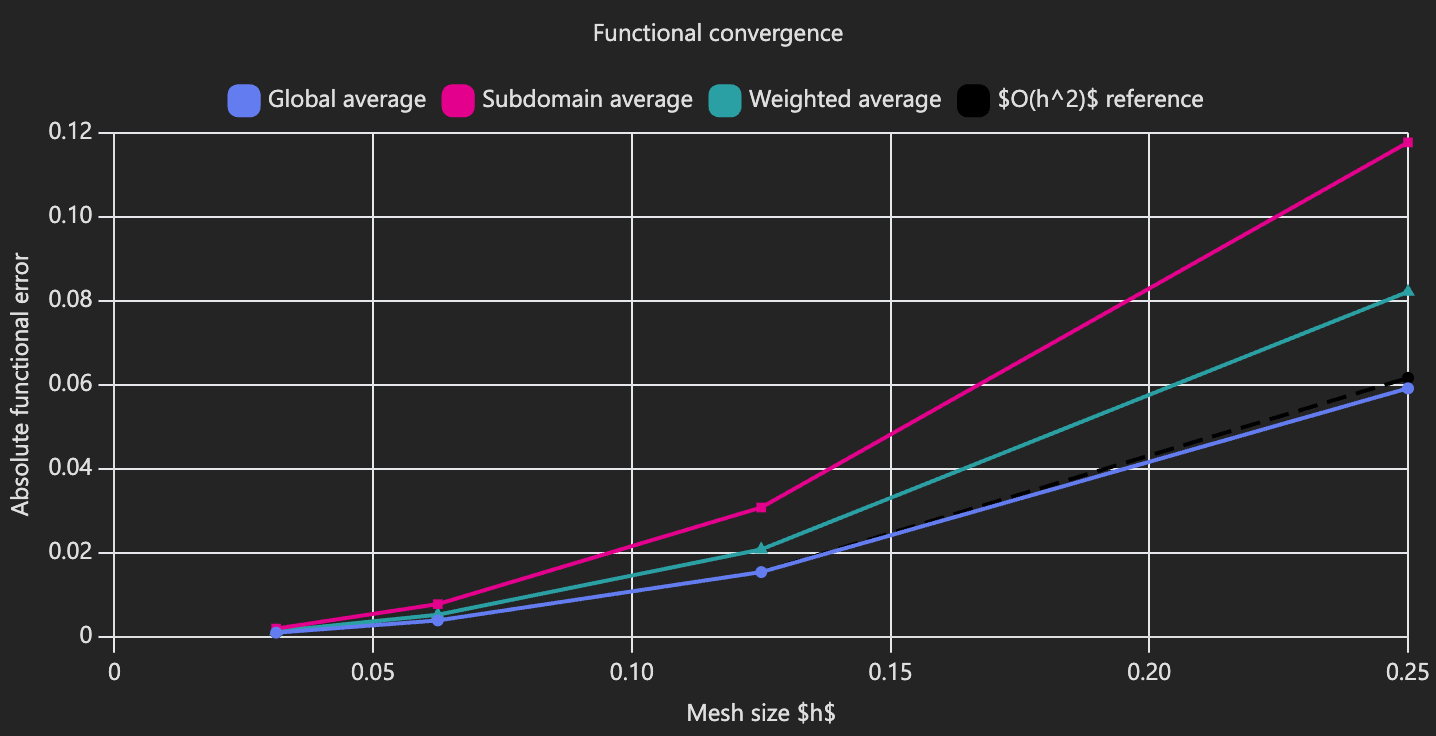

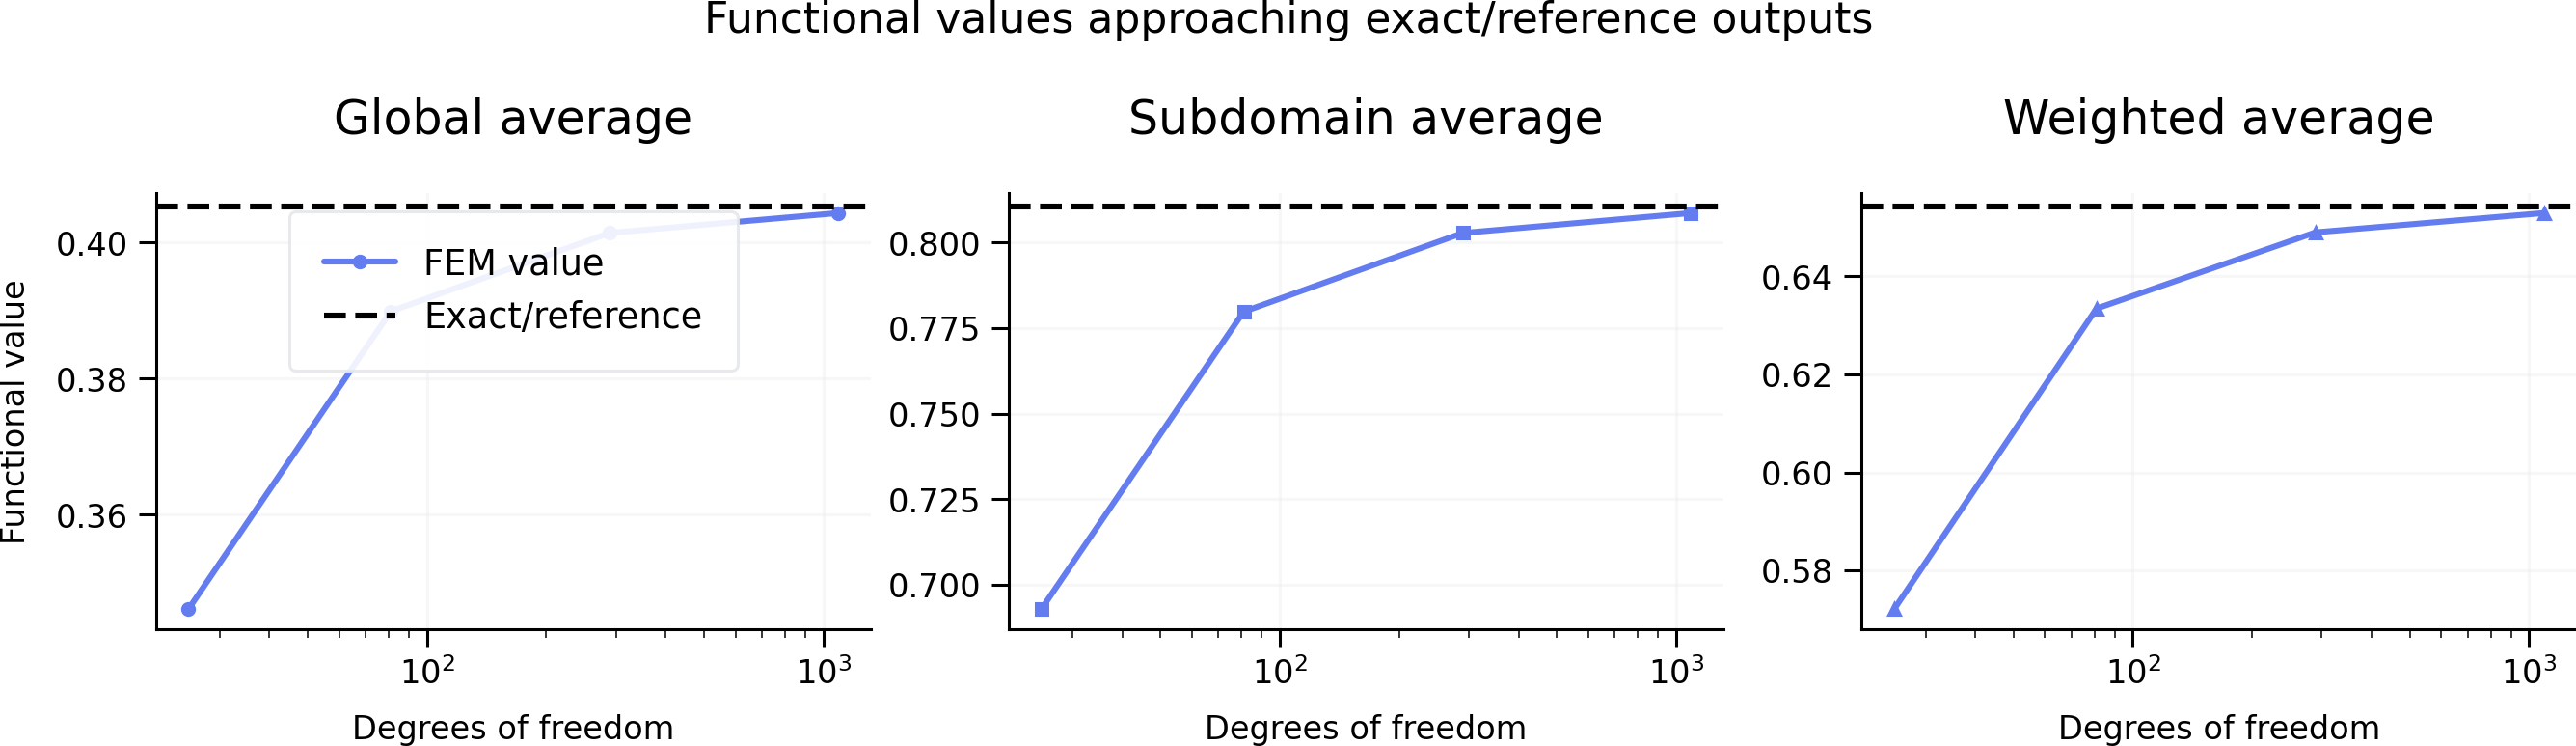

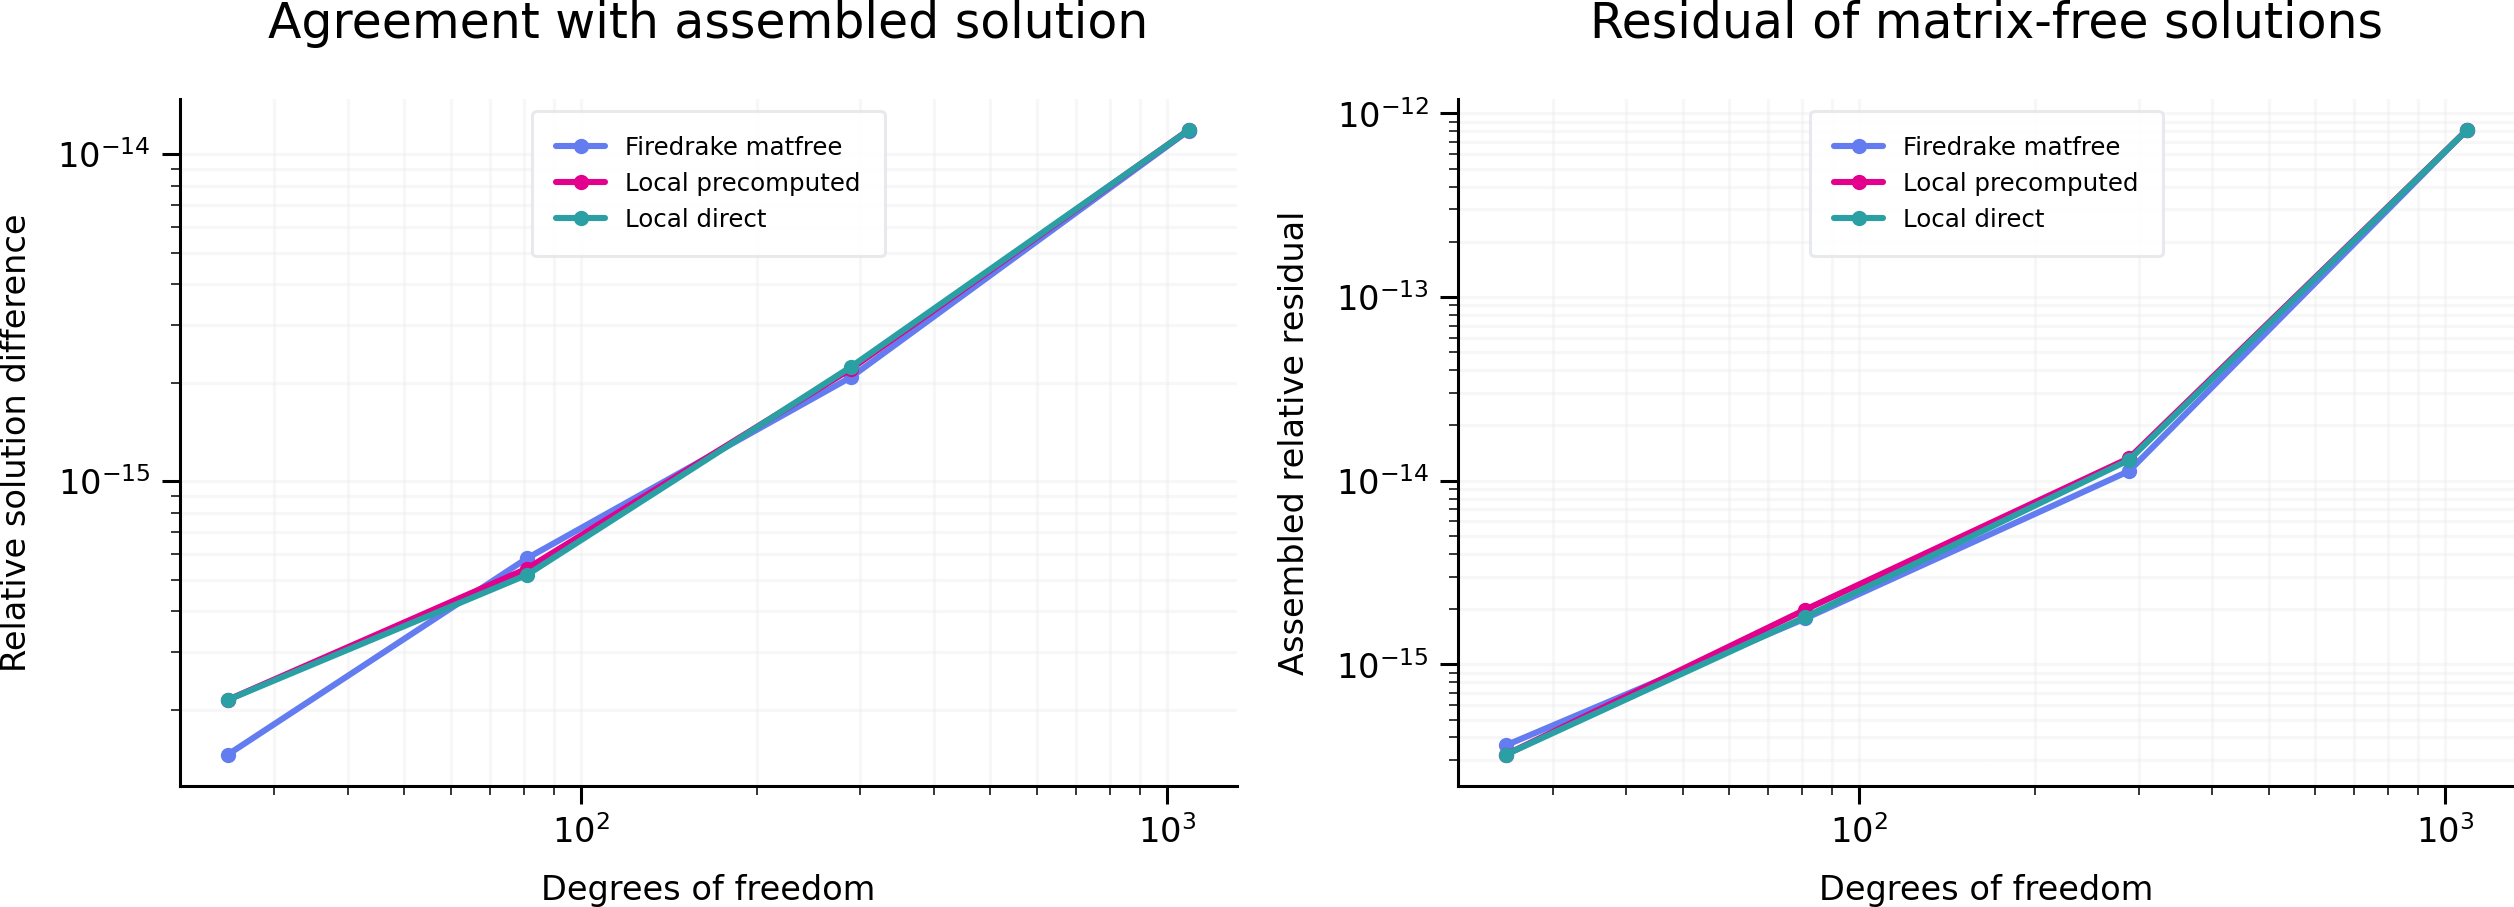

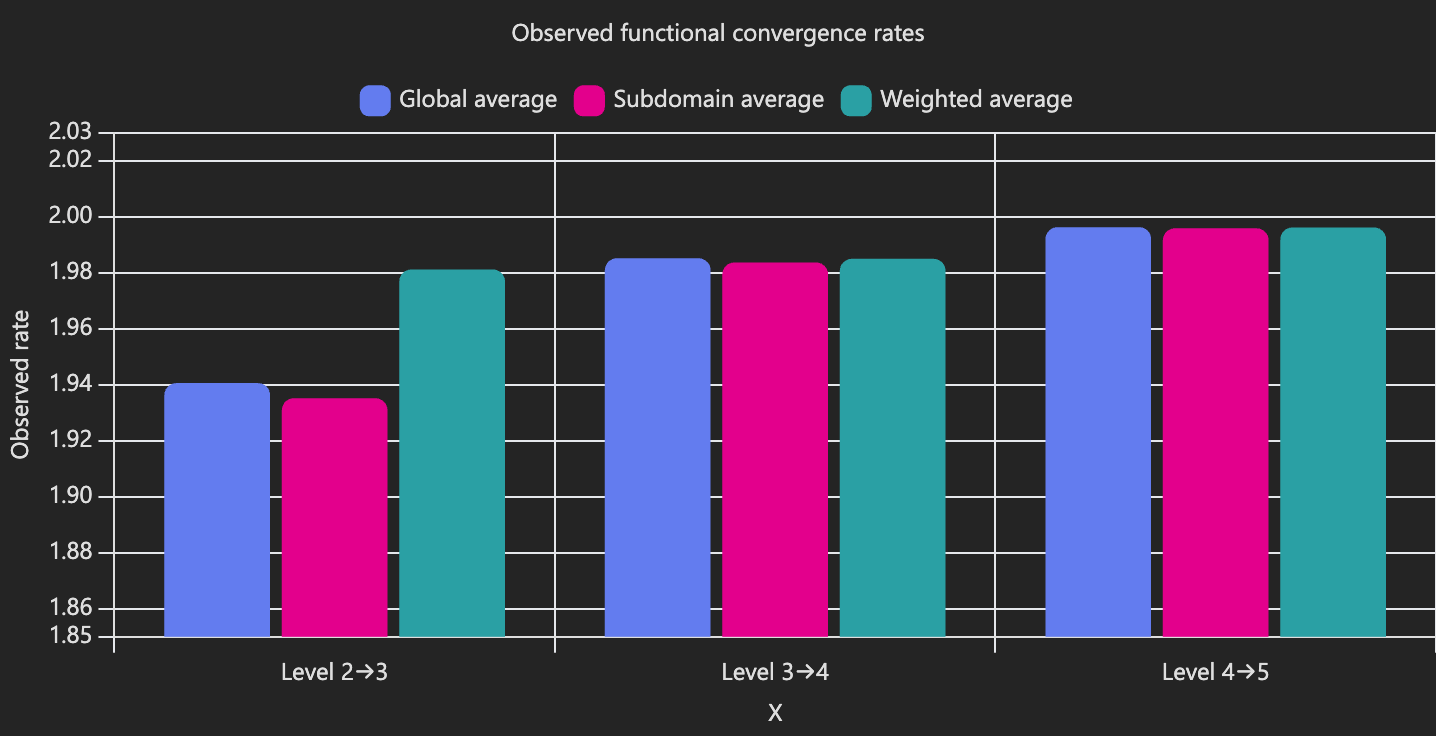

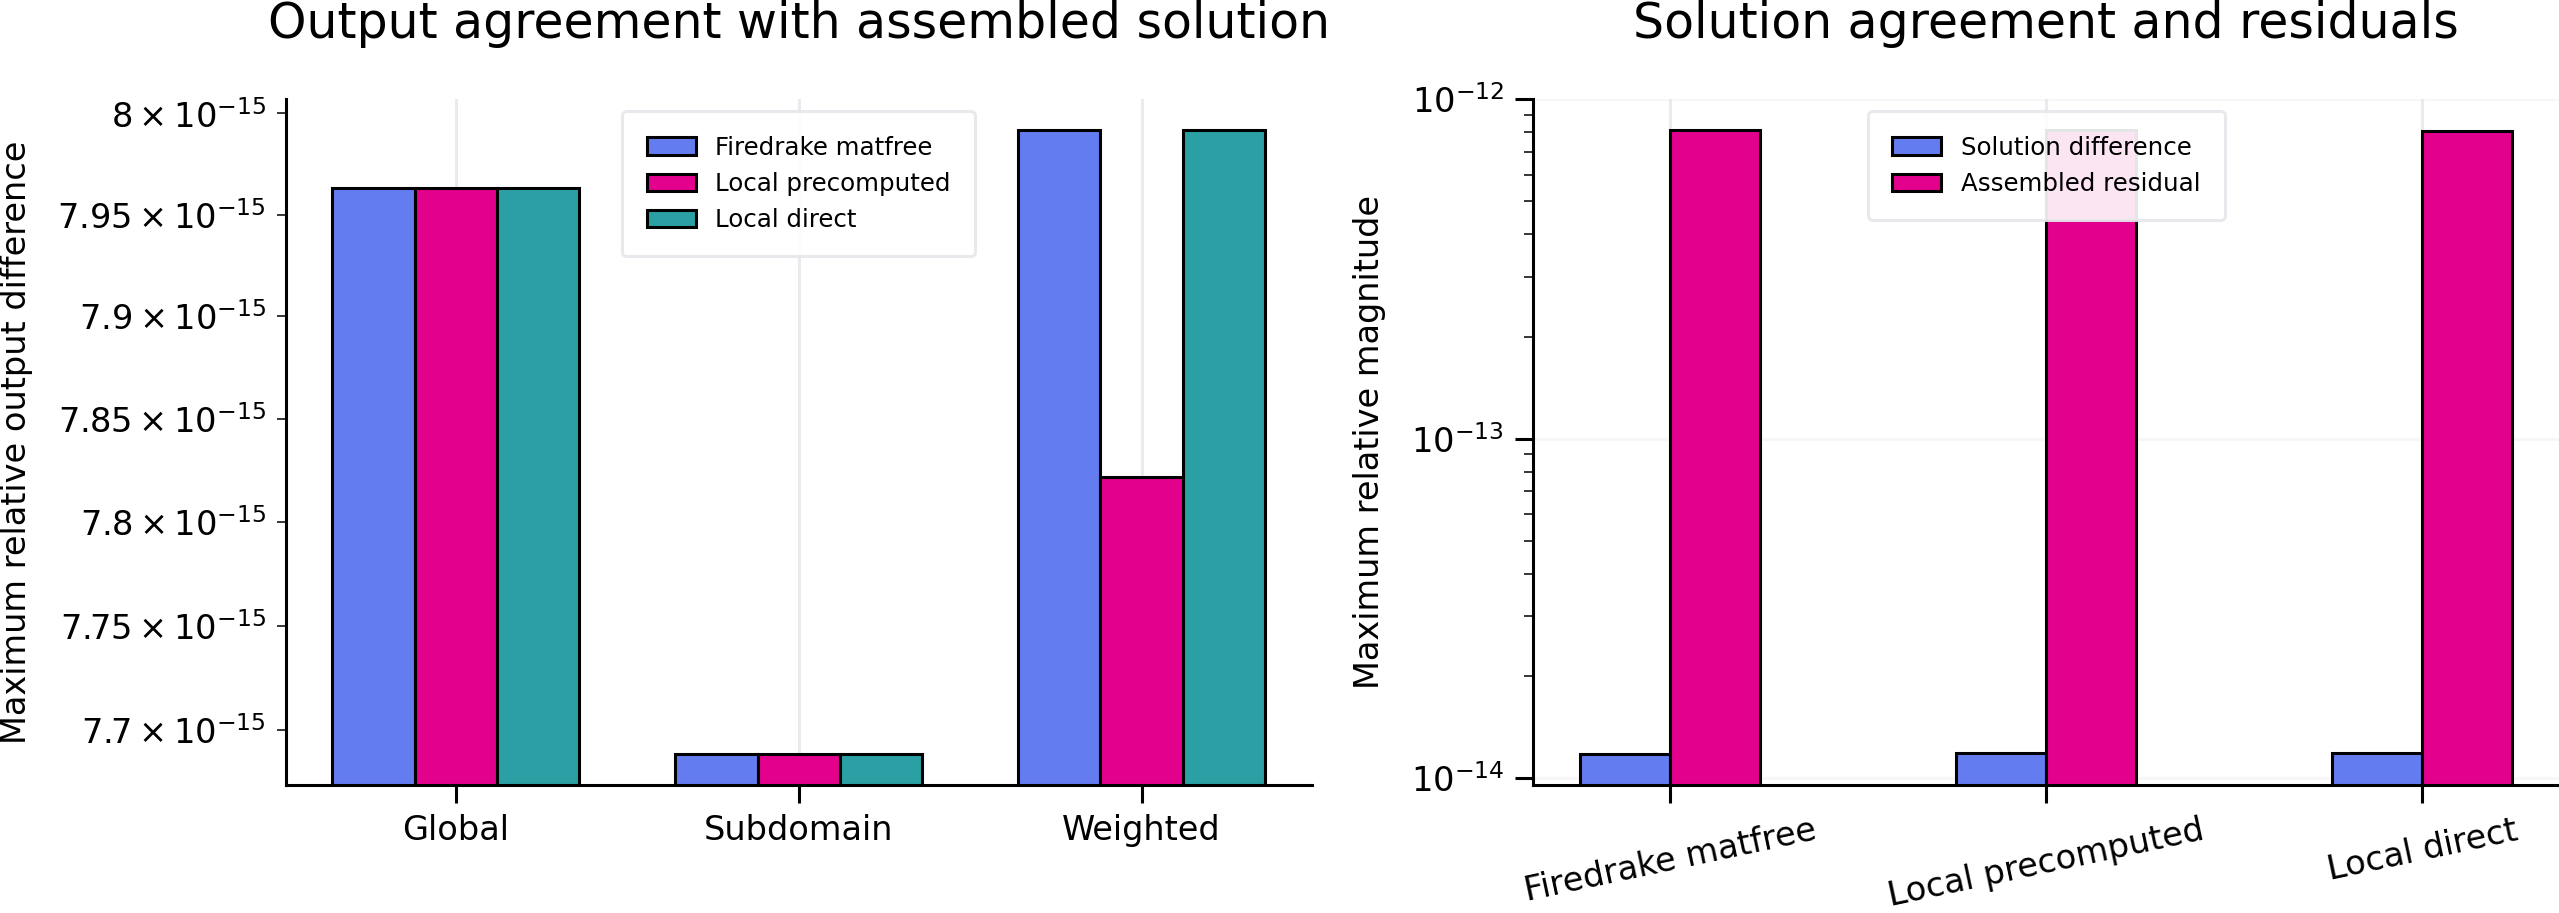

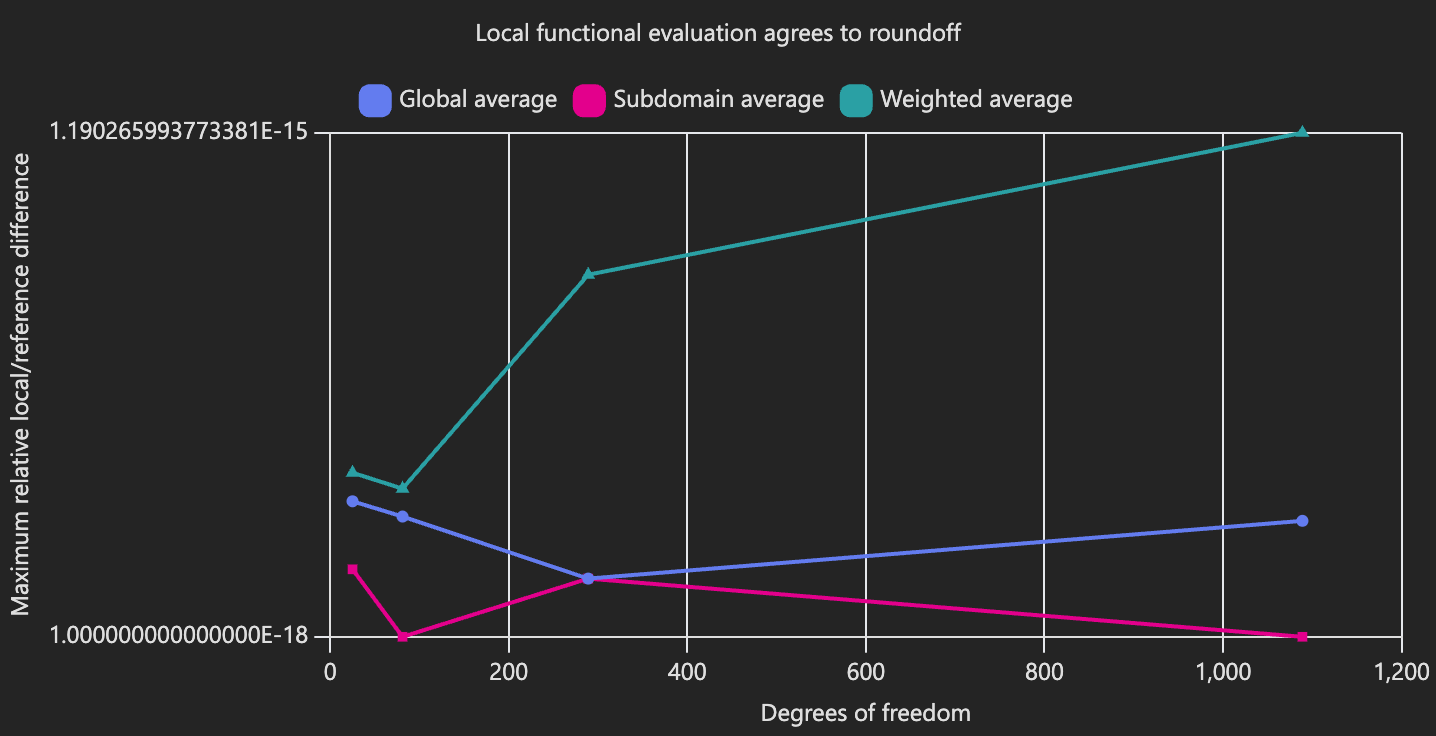

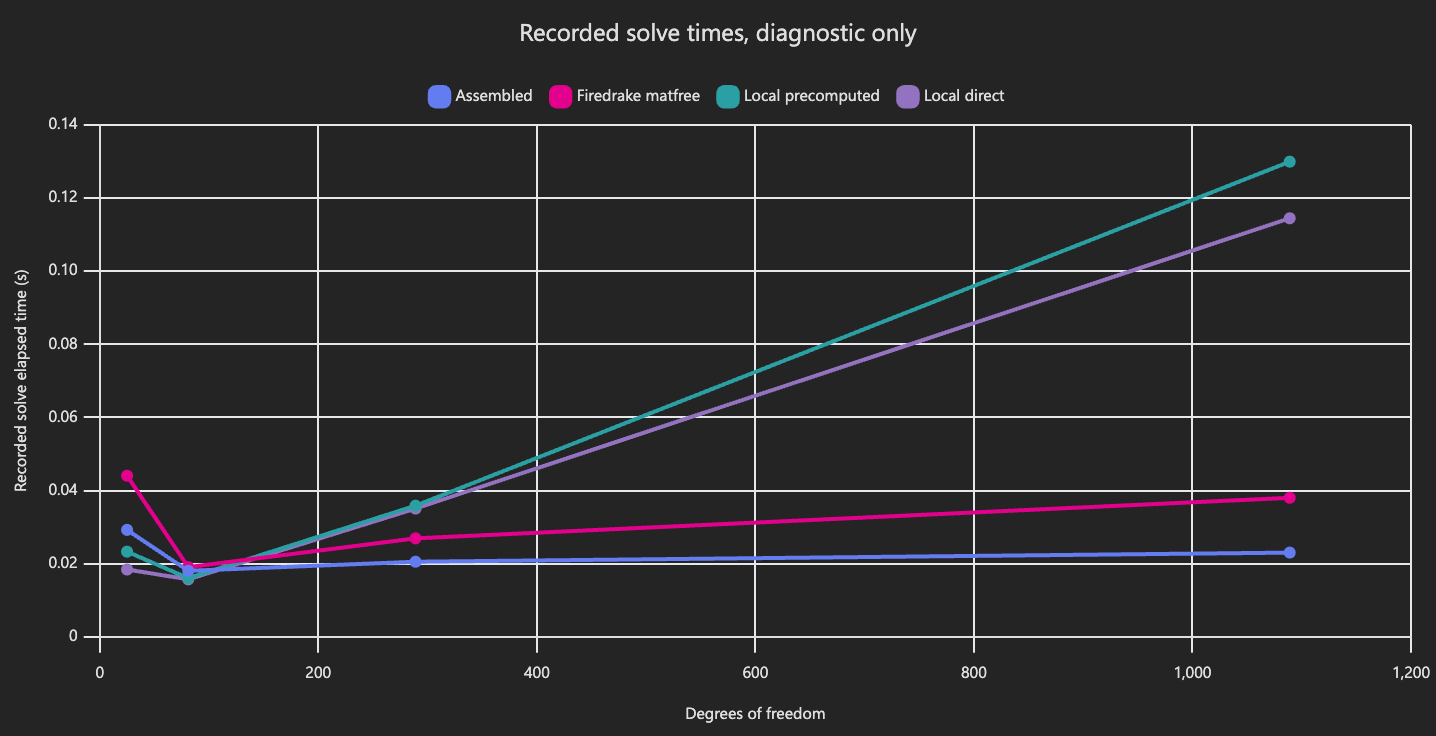

## experiments/access_model & Plotting Operator Equiv/Access

In [134]:
%%writefile experiments/access_model.py

"""
Phase 3: Logical local-access and persistent-storage model.

This experiment counts the mathematical data accessed by the current
operator and functional representations.

The counts are logical representation counts. They are not hardware
measurements and do not represent:

- cache or DRAM traffic;
- SIMD instructions;
- fused multiply-add instructions;
- NumPy temporary arrays;
- Python object overhead;
- PETSc internal storage;
- Firedrake mesh storage;
- MPI communication.

Storage conventions
-------------------
1. Floating-point storage includes persistent operation-specific
   local data.

2. Index storage includes operation-specific connectivity and,
   where applicable, selected-cell indices.

3. Global input and output vectors are excluded.

4. Shared mesh and Firedrake function-space storage are excluded.

5. The logical arithmetic counts describe the written formulas,
   not compiled hardware instruction counts.

Outputs
-------
results/access_model.csv

Run from the project root with:

    python experiments/access_model.py

or from a notebook with:

    %run experiments/access_model.py
"""

from pathlib import Path
import csv

from src.problem import create_problem
from src.local_operator import LocalP1Operator

from src.global_functional import (
    create_global_functional_data,
)

from src.subdomain_functional import (
    create_subdomain_functional_data,
)

from src.weighted_functional import (
    create_weighted_functional_data,
)


LEVELS = [
    2,
    3,
    4,
    5,
]


SUBDOMAIN_BOUNDS = (
    0.25,
    0.75,
    0.25,
    0.75,
)


WEIGHT_CENTER = (
    0.70,
    0.35,
)


WEIGHT_SIGMA = 0.10


WEIGHT_QUADRATURE_ORDER = 12


FLOAT_BYTES = 8
INDEX_BYTES = 8


def _validate_nonnegative_integer(
    value,
    name,
):
    """
    Validate a nonnegative integer model parameter.
    """

    if isinstance(
        value,
        bool,
    ):
        raise ValueError(
            f"{name} must be a nonnegative integer."
        )

    integer_value = int(
        value
    )

    if (
        integer_value < 0
        or integer_value != value
    ):
        raise ValueError(
            f"{name} must be a nonnegative integer."
        )

    return integer_value


def make_row(
    level,
    operator,
    operation,
    accessed_cells,
    storage_cells,
    integer_reads_per_accessed_cell,
    scalar_reads_per_accessed_cell,
    scalar_outputs_per_accessed_cell,
    vector_scatter_adds_per_accessed_cell,
    scalar_reduction_contributions_per_accessed_cell,
    persistent_float_scalars_per_stored_cell,
    persistent_integer_indices_per_stored_cell,
    logical_multiplications_per_accessed_cell,
    logical_additions_per_accessed_cell,
):
    """
    Construct one row of the logical access model.

    Parameters
    ----------
    accessed_cells:
        Number of cells visited during one evaluation.

    storage_cells:
        Number of cells carrying operation-specific persistent data.

    integer_reads_per_accessed_cell:
        Logical connectivity/index reads during one cell evaluation.

    scalar_reads_per_accessed_cell:
        Logical floating-point reads during one cell evaluation.
        These include gathered coefficients and operation-specific
        local data.

    scalar_outputs_per_accessed_cell:
        Number of local scalar values produced by one cell evaluation.

    vector_scatter_adds_per_accessed_cell:
        Number of updates into a global output vector.

    scalar_reduction_contributions_per_accessed_cell:
        Number of local scalar contributions entering a global
        reduction.

    persistent_float_scalars_per_stored_cell:
        Operation-specific persistent floating-point values per
        storage cell.

    persistent_integer_indices_per_stored_cell:
        Operation-specific persistent integer indices per storage cell.

    logical_multiplications_per_accessed_cell:
        Mathematical multiplication count for the represented formula.

    logical_additions_per_accessed_cell:
        Mathematical addition count for the represented formula.
    """

    total_cells = int(
        operator.num_cells
    )

    accessed_cells = _validate_nonnegative_integer(
        accessed_cells,
        "accessed_cells",
    )

    storage_cells = _validate_nonnegative_integer(
        storage_cells,
        "storage_cells",
    )

    if accessed_cells > total_cells:
        raise ValueError(
            "accessed_cells cannot exceed total_cells."
        )

    if storage_cells > total_cells:
        raise ValueError(
            "storage_cells cannot exceed total_cells."
        )

    count_parameters = {
        "integer_reads_per_accessed_cell":
            integer_reads_per_accessed_cell,

        "scalar_reads_per_accessed_cell":
            scalar_reads_per_accessed_cell,

        "scalar_outputs_per_accessed_cell":
            scalar_outputs_per_accessed_cell,

        "vector_scatter_adds_per_accessed_cell":
            vector_scatter_adds_per_accessed_cell,

        "scalar_reduction_contributions_per_accessed_cell":
            scalar_reduction_contributions_per_accessed_cell,

        "persistent_float_scalars_per_stored_cell":
            persistent_float_scalars_per_stored_cell,

        "persistent_integer_indices_per_stored_cell":
            persistent_integer_indices_per_stored_cell,

        "logical_multiplications_per_accessed_cell":
            logical_multiplications_per_accessed_cell,

        "logical_additions_per_accessed_cell":
            logical_additions_per_accessed_cell,
    }

    validated = {
        name: _validate_nonnegative_integer(
            value,
            name,
        )
        for name, value in count_parameters.items()
    }

    persistent_float_storage_bytes = (
        storage_cells
        * validated[
            "persistent_float_scalars_per_stored_cell"
        ]
        * FLOAT_BYTES
    )

    persistent_index_storage_bytes = (
        storage_cells
        * validated[
            "persistent_integer_indices_per_stored_cell"
        ]
        * INDEX_BYTES
    )

    return {
        "level": int(level),
        "h": float(
            operator.problem.h
        ),
        "ndofs": int(
            operator.num_dofs
        ),
        "total_cells": total_cells,
        "operation": operation,

        "accessed_cells": accessed_cells,
        "access_fraction": (
            accessed_cells
            / total_cells
        ),

        "storage_cells": storage_cells,
        "storage_fraction": (
            storage_cells
            / total_cells
        ),

        "integer_reads_per_accessed_cell": validated[
            "integer_reads_per_accessed_cell"
        ],

        "scalar_reads_per_accessed_cell": validated[
            "scalar_reads_per_accessed_cell"
        ],

        "scalar_outputs_per_accessed_cell": validated[
            "scalar_outputs_per_accessed_cell"
        ],

        "vector_scatter_adds_per_accessed_cell": validated[
            "vector_scatter_adds_per_accessed_cell"
        ],

        "scalar_reduction_contributions_per_accessed_cell": validated[
            "scalar_reduction_contributions_per_accessed_cell"
        ],

        "persistent_float_scalars_per_stored_cell": validated[
            "persistent_float_scalars_per_stored_cell"
        ],

        "persistent_integer_indices_per_stored_cell": validated[
            "persistent_integer_indices_per_stored_cell"
        ],

        "logical_multiplications_per_accessed_cell": validated[
            "logical_multiplications_per_accessed_cell"
        ],

        "logical_additions_per_accessed_cell": validated[
            "logical_additions_per_accessed_cell"
        ],

        "total_integer_reads": (
            accessed_cells
            * validated[
                "integer_reads_per_accessed_cell"
            ]
        ),

        "total_scalar_reads": (
            accessed_cells
            * validated[
                "scalar_reads_per_accessed_cell"
            ]
        ),

        "total_scalar_outputs": (
            accessed_cells
            * validated[
                "scalar_outputs_per_accessed_cell"
            ]
        ),

        "total_vector_scatter_adds": (
            accessed_cells
            * validated[
                "vector_scatter_adds_per_accessed_cell"
            ]
        ),

        "total_scalar_reduction_contributions": (
            accessed_cells
            * validated[
                "scalar_reduction_contributions_per_accessed_cell"
            ]
        ),

        "total_logical_multiplications": (
            accessed_cells
            * validated[
                "logical_multiplications_per_accessed_cell"
            ]
        ),

        "total_logical_additions": (
            accessed_cells
            * validated[
                "logical_additions_per_accessed_cell"
            ]
        ),

        "total_logical_arithmetic_operations": (
            accessed_cells
            * (
                validated[
                    "logical_multiplications_per_accessed_cell"
                ]
                + validated[
                    "logical_additions_per_accessed_cell"
                ]
            )
        ),

        "persistent_float_storage_bytes": (
            persistent_float_storage_bytes
        ),

        "persistent_index_storage_bytes": (
            persistent_index_storage_bytes
        ),

        "persistent_total_local_storage_bytes": (
            persistent_float_storage_bytes
            + persistent_index_storage_bytes
        ),
    }


def run_level(
    level,
):
    """
    Generate the access-model rows for one refinement level.
    """

    problem = create_problem(
        refinement_level=level
    )

    # This object supplies verified geometry and cell counts.
    # The operation rows below describe both supported local modes.
    operator = LocalP1Operator(
        problem,
        precompute_matrices=False,
    )

    global_data = (
        create_global_functional_data(
            problem
        )
    )

    subdomain_data = (
        create_subdomain_functional_data(
            problem,
            SUBDOMAIN_BOUNDS,
        )
    )

    weighted_data = (
        create_weighted_functional_data(
            problem,
            center=WEIGHT_CENTER,
            sigma=WEIGHT_SIGMA,
            quadrature_order=(
                WEIGHT_QUADRATURE_ORDER
            ),
        )
    )

    rows = []

    # ==================================================
    # Precomputed element-matrix operator
    # ==================================================
    #
    # Reads:
    #   3 gathered input coefficients
    #   9 entries of A_T
    #
    # Persistent local data:
    #   9 floating-point matrix entries
    #   3 cell-to-DoF indices
    #
    # Arithmetic:
    #   3 x 3 matrix-vector multiplication
    #   9 multiplications and 6 additions
    #
    # Accumulation:
    #   3 vector scatter-adds

    rows.append(
        make_row(
            level=level,
            operator=operator,
            operation=(
                "operator_precomputed"
            ),

            accessed_cells=(
                operator.num_cells
            ),

            storage_cells=(
                operator.num_cells
            ),

            integer_reads_per_accessed_cell=3,

            scalar_reads_per_accessed_cell=12,

            scalar_outputs_per_accessed_cell=3,

            vector_scatter_adds_per_accessed_cell=3,

            scalar_reduction_contributions_per_accessed_cell=0,

            persistent_float_scalars_per_stored_cell=9,

            persistent_integer_indices_per_stored_cell=3,

            logical_multiplications_per_accessed_cell=9,

            logical_additions_per_accessed_cell=6,
        )
    )

    # ==================================================
    # Direct gradient-factorized operator
    # ==================================================
    #
    # Reads:
    #   3 gathered input coefficients
    #   6 gradient components
    #   1 triangle area
    #
    # Persistent local data:
    #   6 gradient components
    #   1 triangle area
    #   3 cell-to-DoF indices
    #
    # Arithmetic:
    #   15 multiplications and 7 additions
    #
    # Accumulation:
    #   3 vector scatter-adds

    rows.append(
        make_row(
            level=level,
            operator=operator,
            operation=(
                "operator_direct"
            ),

            accessed_cells=(
                operator.num_cells
            ),

            storage_cells=(
                operator.num_cells
            ),

            integer_reads_per_accessed_cell=3,

            scalar_reads_per_accessed_cell=10,

            scalar_outputs_per_accessed_cell=3,

            vector_scatter_adds_per_accessed_cell=3,

            scalar_reduction_contributions_per_accessed_cell=0,

            persistent_float_scalars_per_stored_cell=7,

            persistent_integer_indices_per_stored_cell=3,

            logical_multiplications_per_accessed_cell=15,

            logical_additions_per_accessed_cell=7,
        )
    )

    # ==================================================
    # Global average
    # ==================================================
    #
    # Reads:
    #   3 gathered solution coefficients
    #   1 triangle area
    #
    # Persistent local data:
    #   1 triangle area
    #   3 cell-to-DoF indices
    #
    # Accumulation:
    #   1 scalar reduction contribution

    rows.append(
        make_row(
            level=level,
            operator=operator,
            operation=(
                "global_average"
            ),

            accessed_cells=(
                global_data.num_cells
            ),

            storage_cells=(
                global_data.num_cells
            ),

            integer_reads_per_accessed_cell=3,

            scalar_reads_per_accessed_cell=4,

            scalar_outputs_per_accessed_cell=1,

            vector_scatter_adds_per_accessed_cell=0,

            scalar_reduction_contributions_per_accessed_cell=1,

            persistent_float_scalars_per_stored_cell=1,

            persistent_integer_indices_per_stored_cell=3,

            logical_multiplications_per_accessed_cell=2,

            logical_additions_per_accessed_cell=2,
        )
    )

    # ==================================================
    # Mesh-aligned subdomain average
    # ==================================================
    #
    # The current representation stores copied connectivity and
    # areas only for selected cells.
    #
    # Persistent integer data:
    #   3 selected cell-to-DoF indices
    #   1 selected-cell index
    #
    # The selected-cell index is included as persistent storage.
    # It is not counted as an additional evaluation-stage read because
    # the selected data are already stored in compact selected arrays.

    rows.append(
        make_row(
            level=level,
            operator=operator,
            operation=(
                "subdomain_average"
            ),

            accessed_cells=(
                subdomain_data
                .num_selected_cells
            ),

            storage_cells=(
                subdomain_data
                .num_selected_cells
            ),

            integer_reads_per_accessed_cell=3,

            scalar_reads_per_accessed_cell=4,

            scalar_outputs_per_accessed_cell=1,

            vector_scatter_adds_per_accessed_cell=0,

            scalar_reduction_contributions_per_accessed_cell=1,

            persistent_float_scalars_per_stored_cell=1,

            persistent_integer_indices_per_stored_cell=4,

            logical_multiplications_per_accessed_cell=2,

            logical_additions_per_accessed_cell=2,
        )
    )

    # ==================================================
    # Gaussian-weighted average
    # ==================================================
    #
    # Evaluation reads:
    #   3 gathered solution coefficients
    #   3 precomputed local functional-vector entries
    #
    # Persistent local data:
    #   3 local functional-vector entries
    #   3 cell-to-DoF indices
    #
    # Quadrature work required to construct the local vectors is
    # setup cost and is not included in the evaluation-stage counts.

    rows.append(
        make_row(
            level=level,
            operator=operator,
            operation=(
                "weighted_average"
            ),

            accessed_cells=(
                weighted_data.num_cells
            ),

            storage_cells=(
                weighted_data.num_cells
            ),

            integer_reads_per_accessed_cell=3,

            scalar_reads_per_accessed_cell=6,

            scalar_outputs_per_accessed_cell=1,

            vector_scatter_adds_per_accessed_cell=0,

            scalar_reduction_contributions_per_accessed_cell=1,

            persistent_float_scalars_per_stored_cell=3,

            persistent_integer_indices_per_stored_cell=3,

            logical_multiplications_per_accessed_cell=3,

            logical_additions_per_accessed_cell=2,
        )
    )

    return rows


def print_summary(
    rows,
):
    """
    Print a compact access and storage summary.
    """

    print(
        "\nPhase 3: Logical local-access and storage model"
    )

    print(
        "=" * 151
    )

    header = (
        f"{'Level':>5} "
        f"{'DoFs':>8} "
        f"{'Cells':>8} "
        f"{'Operation':>23} "
        f"{'Accessed':>9} "
        f"{'Access frac':>11} "
        f"{'Scalar reads':>13} "
        f"{'Scatters':>10} "
        f"{'Reductions':>11} "
        f"{'Float bytes':>12} "
        f"{'Index bytes':>12} "
        f"{'Total bytes':>12}"
    )

    print(
        header
    )

    print(
        "-" * len(header)
    )

    for row in rows:
        print(
            f"{row['level']:5d} "
            f"{row['ndofs']:8d} "
            f"{row['total_cells']:8d} "
            f"{row['operation']:>23} "
            f"{row['accessed_cells']:9d} "
            f"{row['access_fraction']:11.3f} "
            f"{row['total_scalar_reads']:13d} "
            f"{row['total_vector_scatter_adds']:10d} "
            f"{row['total_scalar_reduction_contributions']:11d} "
            f"{row['persistent_float_storage_bytes']:12d} "
            f"{row['persistent_index_storage_bytes']:12d} "
            f"{row['persistent_total_local_storage_bytes']:12d}"
        )

    print(
        "=" * 151
    )

    print(
        "\nInterpretation:"
    )

    print(
        "  Scalar reads and arithmetic counts are logical "
        "representation counts."
    )

    print(
        "  Scatter-add counts describe global vector updates."
    )

    print(
        "  Reduction counts describe local scalar contributions."
    )

    print(
        "  Storage excludes global vectors, mesh objects, Python "
        "overhead, PETSc internals, and temporary arrays."
    )


def write_csv(
    rows,
    output_path=(
        "results/access_model.csv"
    ),
):
    """
    Write the access-model rows to CSV.
    """

    output_path = Path(
        output_path
    )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    if not rows:
        raise ValueError(
            "No access-model rows were generated."
        )

    fieldnames = list(
        rows[0].keys()
    )

    with output_path.open(
        "w",
        newline="",
        encoding="utf-8",
    ) as output_file:
        writer = csv.DictWriter(
            output_file,
            fieldnames=fieldnames,
        )

        writer.writeheader()

        writer.writerows(
            rows
        )

    print(
        f"\nSaved access-model results to: "
        f"{output_path}"
    )


def run_experiment(
    levels=None,
    output_path=(
        "results/access_model.csv"
    ),
):
    """
    Run the complete logical access-model experiment.
    """

    if levels is None:
        levels = LEVELS

    rows = []

    for level in levels:
        rows.extend(
            run_level(
                level
            )
        )

    print_summary(
        rows
    )

    write_csv(
        rows,
        output_path=output_path,
    )

    return rows


if __name__ == "__main__":
    run_experiment()

Overwriting experiments/access_model.py


In [135]:
%%writefile experiments/plot_operator_and_access_results.py

"""
Create operator-equivalence and logical access-model plots.

Inputs
------
results/operator_equivalence.csv
results/access_model.csv

Outputs
-------
Operator-equivalence figures:

    results/plots/operator_max_relative_difference.png
    results/plots/operator_seed_distribution.png
    results/plots/operator_max_entrywise_difference.png
    results/plots/operator_timings_diagnostic.png

Access-model figures:

    results/plots/access_total_scalar_reads.png
    results/plots/access_fraction.png
    results/plots/access_persistent_storage.png
    results/plots/access_accumulation_structure.png
    results/plots/access_arithmetic_vs_reads.png

Important interpretation
------------------------
The access-model plots report logical representation counts, not measured
cache or memory traffic.

The operator timing plot is diagnostic only. The custom local operators
are NumPy implementations and are not optimized reproductions of
compiled matrix-free kernels.

Run from the project root with:

    python experiments/plot_operator_and_access_results.py

or from a notebook with:

    %run experiments/plot_operator_and_access_results.py
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


OPERATOR_INPUT = Path(
    "results/operator_equivalence.csv"
)


ACCESS_INPUT = Path(
    "results/access_model.csv"
)


OUTPUT_DIRECTORY = Path(
    "results/plots"
)


COMPARISON_LABELS = {
    (
        "full_constrained",
        "local_precomputed",
    ): (
        "Precomputed, constrained"
    ),

    (
        "full_constrained",
        "local_direct",
    ): (
        "Direct, constrained"
    ),

    (
        "free_dofs",
        "local_precomputed",
    ): (
        "Precomputed, free DoFs"
    ),

    (
        "free_dofs",
        "local_direct",
    ): (
        "Direct, free DoFs"
    ),

    (
        "local_mode_difference",
        "direct_vs_precomputed",
    ): (
        "Direct vs precomputed"
    ),
}


OPERATION_LABELS = {
    "operator_precomputed": (
        "Precomputed operator"
    ),
    "operator_direct": (
        "Direct operator"
    ),
    "global_average": (
        "Global average"
    ),
    "subdomain_average": (
        "Subdomain average"
    ),
    "weighted_average": (
        "Weighted average"
    ),
}


OPERATION_ORDER = [
    "operator_precomputed",
    "operator_direct",
    "global_average",
    "subdomain_average",
    "weighted_average",
]


OPERATION_MARKERS = {
    "operator_precomputed": "o",
    "operator_direct": "s",
    "global_average": "^",
    "subdomain_average": "D",
    "weighted_average": "v",
}


def save_figure(
    figure,
    filename,
):
    """
    Save and close one figure.
    """

    output_path = (
        OUTPUT_DIRECTORY
        / filename
    )

    figure.tight_layout()

    figure.savefig(
        output_path,
        dpi=220,
        bbox_inches="tight",
    )

    plt.close(
        figure
    )

    print(
        f"Saved: {output_path}"
    )


def load_operator_results():
    """
    Load and validate operator-equivalence results.
    """

    if not OPERATOR_INPUT.exists():
        raise FileNotFoundError(
            f"Could not find {OPERATOR_INPUT}. "
            "Run experiments/operator_equivalence.py first."
        )

    data = pd.read_csv(
        OPERATOR_INPUT
    )

    required = {
        "level",
        "h",
        "ndofs",
        "num_cells",
        "seed",
        "comparison",
        "candidate",
        "absolute_l2",
        "relative_l2",
        "absolute_linf",
        "elapsed_seconds",
    }

    missing = (
        required
        - set(
            data.columns
        )
    )

    if missing:
        raise ValueError(
            "The operator-equivalence CSV is missing columns: "
            f"{sorted(missing)}"
        )

    if data.empty:
        raise ValueError(
            "The operator-equivalence CSV contains no data."
        )

    return data


def load_access_results():
    """
    Load and validate the corrected access-model CSV.
    """

    if not ACCESS_INPUT.exists():
        raise FileNotFoundError(
            f"Could not find {ACCESS_INPUT}. "
            "Run experiments/access_model.py first."
        )

    data = pd.read_csv(
        ACCESS_INPUT
    )

    required = {
        "level",
        "h",
        "ndofs",
        "total_cells",
        "operation",
        "accessed_cells",
        "access_fraction",
        "storage_cells",
        "storage_fraction",
        "total_scalar_reads",
        "total_vector_scatter_adds",
        "total_scalar_reduction_contributions",
        "total_logical_multiplications",
        "total_logical_additions",
        "total_logical_arithmetic_operations",
        "persistent_float_storage_bytes",
        "persistent_index_storage_bytes",
        "persistent_total_local_storage_bytes",
    }

    missing = (
        required
        - set(
            data.columns
        )
    )

    if missing:
        raise ValueError(
            "The access-model CSV is missing columns: "
            f"{sorted(missing)}"
        )

    if data.empty:
        raise ValueError(
            "The access-model CSV contains no data."
        )

    unknown_operations = (
        set(
            data[
                "operation"
            ].unique()
        )
        - set(
            OPERATION_ORDER
        )
    )

    if unknown_operations:
        raise ValueError(
            "The access-model CSV contains unknown operations: "
            f"{sorted(unknown_operations)}"
        )

    return data


def comparison_label(
    comparison,
    candidate,
):
    """
    Return a readable comparison label.
    """

    key = (
        comparison,
        candidate,
    )

    if key not in COMPARISON_LABELS:
        raise KeyError(
            f"Unknown operator comparison: {key}"
        )

    return COMPARISON_LABELS[
        key
    ]


def ordered_access_data(
    data,
):
    """
    Return access rows in a stable operation order.
    """

    ordered = data.copy()

    ordered["operation"] = pd.Categorical(
        ordered["operation"],
        categories=OPERATION_ORDER,
        ordered=True,
    )

    return ordered.sort_values(
        [
            "level",
            "operation",
        ]
    )


# ==================================================
# Operator-equivalence plots
# ==================================================


def plot_operator_max_relative_difference(
    data,
):
    """
    Plot maximum relative operator differences over random seeds.
    """

    numerical = data[
        data["comparison"]
        != "timing_only"
    ].copy()

    grouped = (
        numerical.groupby(
            [
                "level",
                "ndofs",
                "comparison",
                "candidate",
            ],
            as_index=False,
        )[
            "relative_l2"
        ].max()
    )

    figure, axis = plt.subplots(
        figsize=(
            8.0,
            5.2,
        )
    )

    for (
        comparison,
        candidate,
    ), group in grouped.groupby(
        [
            "comparison",
            "candidate",
        ]
    ):
        group = group.sort_values(
            "ndofs"
        )

        values = group[
            "relative_l2"
        ].to_numpy(
            dtype=np.float64
        )

        # Exact zeros cannot be placed on a logarithmic axis.
        values = np.where(
            values > 0.0,
            values,
            1.0e-18,
        )

        axis.semilogy(
            group["ndofs"],
            values,
            marker="o",
            linewidth=2,
            label=comparison_label(
                comparison,
                candidate,
            ),
        )

    axis.axhline(
        np.finfo(
            np.float64
        ).eps,
        linestyle="--",
        color="black",
        label=(
            "Double-precision epsilon"
        ),
    )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "Maximum relative operator difference"
    )

    axis.set_title(
        "Operator equivalence across mesh refinement"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend(
        fontsize=8
    )

    save_figure(
        figure,
        "operator_max_relative_difference.png",
    )


def plot_operator_seed_distribution(
    data,
):
    """
    Plot seed-level relative differences for principal comparisons.
    """

    numerical = data[
        data["comparison"].isin(
            [
                "full_constrained",
                "local_mode_difference",
            ]
        )
    ].copy()

    numerical["series"] = [
        comparison_label(
            comparison,
            candidate,
        )
        for comparison, candidate in zip(
            numerical["comparison"],
            numerical["candidate"],
        )
    ]

    series_order = [
        "Precomputed, constrained",
        "Direct, constrained",
        "Direct vs precomputed",
    ]

    levels = sorted(
        numerical[
            "level"
        ].unique()
    )

    figure, axes = plt.subplots(
        1,
        len(levels),
        figsize=(
            3.6 * len(levels),
            4.5,
        ),
        sharey=True,
    )

    if len(levels) == 1:
        axes = [
            axes
        ]

    rng = np.random.default_rng(
        2026
    )

    for axis, level in zip(
        axes,
        levels,
    ):
        level_data = numerical[
            numerical["level"]
            == level
        ]

        for (
            series_index,
            series,
        ) in enumerate(
            series_order
        ):
            values = level_data[
                level_data["series"]
                == series
            ][
                "relative_l2"
            ].to_numpy(
                dtype=np.float64
            )

            values = np.where(
                values > 0.0,
                values,
                1.0e-18,
            )

            jitter = rng.uniform(
                -0.08,
                0.08,
                size=values.size,
            )

            axis.scatter(
                (
                    np.full(
                        values.size,
                        series_index,
                    )
                    + jitter
                ),
                values,
                s=28,
                alpha=0.8,
            )

        axis.axhline(
            np.finfo(
                np.float64
            ).eps,
            linestyle="--",
            color="black",
            linewidth=1,
        )

        axis.set_yscale(
            "log"
        )

        axis.set_xticks(
            range(
                len(
                    series_order
                )
            ),
            [
                "Precomputed",
                "Direct",
                (
                    "Direct vs\n"
                    "precomputed"
                ),
            ],
            rotation=20,
        )

        axis.set_title(
            f"Level {level}"
        )

        axis.grid(
            True,
            axis="y",
            alpha=0.3,
        )

    axes[0].set_ylabel(
        "Relative operator difference"
    )

    figure.suptitle(
        "Operator differences across seeded vectors"
    )

    save_figure(
        figure,
        "operator_seed_distribution.png",
    )


def plot_operator_entrywise_difference(
    data,
):
    """
    Plot maximum absolute entrywise operator differences.
    """

    numerical = data[
        data["comparison"]
        != "timing_only"
    ].copy()

    grouped = (
        numerical.groupby(
            [
                "level",
                "ndofs",
                "comparison",
                "candidate",
            ],
            as_index=False,
        )[
            "absolute_linf"
        ].max()
    )

    figure, axis = plt.subplots(
        figsize=(
            8.0,
            5.2,
        )
    )

    for (
        comparison,
        candidate,
    ), group in grouped.groupby(
        [
            "comparison",
            "candidate",
        ]
    ):
        group = group.sort_values(
            "ndofs"
        )

        values = group[
            "absolute_linf"
        ].to_numpy(
            dtype=np.float64
        )

        values = np.where(
            values > 0.0,
            values,
            1.0e-18,
        )

        axis.semilogy(
            group["ndofs"],
            values,
            marker="o",
            linewidth=2,
            label=comparison_label(
                comparison,
                candidate,
            ),
        )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        (
            "Maximum absolute "
            r"$\ell^\infty$ difference"
        )
    )

    axis.set_title(
        "Maximum entrywise operator discrepancy"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend(
        fontsize=8
    )

    save_figure(
        figure,
        "operator_max_entrywise_difference.png",
    )


def plot_operator_timings(
    data,
):
    """
    Plot median operator-application timing by mesh size.

    Timing rows represent:
    - assembled AIJ application;
    - precomputed local action;
    - direct local action.
    """

    timed = data[
        data["elapsed_seconds"].notna()
    ].copy()

    timing_labels = {
        "assembled_aij": (
            "Assembled AIJ"
        ),
        "local_precomputed": (
            "Local precomputed"
        ),
        "local_direct": (
            "Local direct"
        ),
    }

    grouped = (
        timed.groupby(
            [
                "level",
                "ndofs",
                "candidate",
            ],
            as_index=False,
        )[
            "elapsed_seconds"
        ].median()
    )

    figure, axis = plt.subplots(
        figsize=(
            7.4,
            4.8,
        )
    )

    for candidate in [
        "assembled_aij",
        "local_precomputed",
        "local_direct",
    ]:
        group = grouped[
            grouped["candidate"]
            == candidate
        ].sort_values(
            "ndofs"
        )

        if group.empty:
            continue

        axis.loglog(
            group["ndofs"],
            group["elapsed_seconds"],
            marker="o",
            linewidth=2,
            label=timing_labels[
                candidate
            ],
        )

    axis.set_xlabel(
        "Degrees of freedom"
    )

    axis.set_ylabel(
        "Median application time (s)"
    )

    axis.set_title(
        "Operator-application timings, diagnostic only"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend()

    save_figure(
        figure,
        "operator_timings_diagnostic.png",
    )


# ==================================================
# Access-model plots
# ==================================================


def plot_total_scalar_reads(
    data,
):
    """
    Plot total logical scalar reads as the mesh grows.
    """

    ordered = ordered_access_data(
        data
    )

    figure, axis = plt.subplots(
        figsize=(
            7.6,
            5.0,
        )
    )

    for operation in OPERATION_ORDER:
        group = ordered[
            ordered["operation"]
            == operation
        ].sort_values(
            "total_cells"
        )

        axis.loglog(
            group["total_cells"],
            group["total_scalar_reads"],
            marker=OPERATION_MARKERS[
                operation
            ],
            linewidth=2,
            label=OPERATION_LABELS[
                operation
            ],
        )

    axis.set_xlabel(
        "Total mesh cells"
    )

    axis.set_ylabel(
        "Logical scalar reads per evaluation"
    )

    axis.set_title(
        "Logical scalar-access growth"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    axis.legend(
        fontsize=8
    )

    save_figure(
        figure,
        "access_total_scalar_reads.png",
    )


def plot_access_fraction(
    data,
):
    """
    Plot the fraction of mesh cells accessed at the finest level.
    """

    finest_level = int(
        data["level"].max()
    )

    finest = ordered_access_data(
        data[
            data["level"]
            == finest_level
        ]
    )

    labels = [
        OPERATION_LABELS[
            str(operation)
        ]
        for operation in finest[
            "operation"
        ]
    ]

    figure, axis = plt.subplots(
        figsize=(
            7.8,
            4.8,
        )
    )

    axis.bar(
        labels,
        finest[
            "access_fraction"
        ],
    )

    axis.set_ylim(
        0.0,
        1.05,
    )

    axis.set_ylabel(
        "Fraction of mesh cells accessed"
    )

    axis.set_title(
        (
            "Cell-access fraction at "
            f"level {finest_level}"
        )
    )

    axis.tick_params(
        axis="x",
        rotation=20,
    )

    axis.grid(
        True,
        axis="y",
        alpha=0.3,
    )

    save_figure(
        figure,
        "access_fraction.png",
    )


def plot_persistent_storage(
    data,
):
    """
    Plot operation-specific persistent storage at the finest level.
    """

    finest_level = int(
        data["level"].max()
    )

    finest = ordered_access_data(
        data[
            data["level"]
            == finest_level
        ]
    )

    labels = [
        OPERATION_LABELS[
            str(operation)
        ]
        for operation in finest[
            "operation"
        ]
    ]

    x_positions = np.arange(
        len(labels)
    )

    float_bytes = finest[
        "persistent_float_storage_bytes"
    ].to_numpy(
        dtype=np.float64
    )

    index_bytes = finest[
        "persistent_index_storage_bytes"
    ].to_numpy(
        dtype=np.float64
    )

    figure, axis = plt.subplots(
        figsize=(
            8.2,
            5.0,
        )
    )

    axis.bar(
        x_positions,
        float_bytes,
        label=(
            "Floating-point local data"
        ),
    )

    axis.bar(
        x_positions,
        index_bytes,
        bottom=float_bytes,
        label=(
            "Integer connectivity/index data"
        ),
    )

    axis.set_xticks(
        x_positions,
        labels,
        rotation=20,
    )

    axis.set_ylabel(
        "Persistent operation-specific storage (bytes)"
    )

    axis.set_title(
        (
            "Logical persistent local storage at "
            f"level {finest_level}"
        )
    )

    axis.grid(
        True,
        axis="y",
        alpha=0.3,
    )

    axis.legend()

    save_figure(
        figure,
        "access_persistent_storage.png",
    )


def plot_accumulation_structure(
    data,
):
    """
    Contrast vector scatter-adds with scalar reductions.
    """

    finest_level = int(
        data["level"].max()
    )

    finest = ordered_access_data(
        data[
            data["level"]
            == finest_level
        ]
    )

    labels = [
        OPERATION_LABELS[
            str(operation)
        ]
        for operation in finest[
            "operation"
        ]
    ]

    x_positions = np.arange(
        len(labels)
    )

    width = 0.36

    figure, axis = plt.subplots(
        figsize=(
            8.2,
            5.0,
        )
    )

    axis.bar(
        x_positions
        - width / 2.0,
        finest[
            "total_vector_scatter_adds"
        ],
        width=width,
        label=(
            "Vector scatter-adds"
        ),
    )

    axis.bar(
        x_positions
        + width / 2.0,
        finest[
            "total_scalar_reduction_contributions"
        ],
        width=width,
        label=(
            "Scalar reduction contributions"
        ),
    )

    axis.set_xticks(
        x_positions,
        labels,
        rotation=20,
    )

    axis.set_ylabel(
        "Total accumulation contributions"
    )

    axis.set_title(
        (
            "Accumulation structure at "
            f"level {finest_level}"
        )
    )

    axis.grid(
        True,
        axis="y",
        alpha=0.3,
    )

    axis.legend()

    save_figure(
        figure,
        "access_accumulation_structure.png",
    )


def plot_arithmetic_vs_reads(
    data,
):
    """
    Plot logical arithmetic against logical scalar reads.
    """

    finest_level = int(
        data["level"].max()
    )

    finest = ordered_access_data(
        data[
            data["level"]
            == finest_level
        ]
    )

    figure, axis = plt.subplots(
        figsize=(
            7.4,
            5.2,
        )
    )

    for _, row in finest.iterrows():
        operation = str(
            row["operation"]
        )

        scalar_reads = float(
            row[
                "total_scalar_reads"
            ]
        )

        arithmetic = float(
            row[
                "total_logical_arithmetic_operations"
            ]
        )

        axis.scatter(
            scalar_reads,
            arithmetic,
            s=75,
            marker=OPERATION_MARKERS[
                operation
            ],
        )

        axis.annotate(
            OPERATION_LABELS[
                operation
            ],
            (
                scalar_reads,
                arithmetic,
            ),
            xytext=(
                6,
                5,
            ),
            textcoords=(
                "offset points"
            ),
            fontsize=8,
        )

    axis.set_xscale(
        "log"
    )

    axis.set_yscale(
        "log"
    )

    axis.set_xlabel(
        "Logical scalar reads"
    )

    axis.set_ylabel(
        "Logical arithmetic operations"
    )

    axis.set_title(
        (
            "Arithmetic versus local-data access at "
            f"level {finest_level}"
        )
    )

    axis.grid(
        True,
        which="both",
        alpha=0.3,
    )

    save_figure(
        figure,
        "access_arithmetic_vs_reads.png",
    )


def run_all_plots():
    """
    Generate all operator-equivalence and access-model figures.
    """

    OUTPUT_DIRECTORY.mkdir(
        parents=True,
        exist_ok=True,
    )

    operator_data = (
        load_operator_results()
    )

    access_data = (
        load_access_results()
    )

    plot_operator_max_relative_difference(
        operator_data
    )

    plot_operator_seed_distribution(
        operator_data
    )

    plot_operator_entrywise_difference(
        operator_data
    )

    plot_operator_timings(
        operator_data
    )

    plot_total_scalar_reads(
        access_data
    )

    plot_access_fraction(
        access_data
    )

    plot_persistent_storage(
        access_data
    )

    plot_accumulation_structure(
        access_data
    )

    plot_arithmetic_vs_reads(
        access_data
    )

    print(
        "\nSaved all operator-equivalence and access-model plots to:"
    )

    print(
        f"  {OUTPUT_DIRECTORY}"
    )


if __name__ == "__main__":
    run_all_plots()

Overwriting experiments/plot_operator_and_access_results.py


In [136]:
%%writefile experiments/reproducibility_metadata.py

"""
Collect software, platform, solver, and experiment metadata.

Outputs
-------
results/reproducibility_metadata.json
results/reproducibility_metadata.md
results/pip_freeze.txt

The metadata record includes:

- operating system and processor information;
- Python, NumPy, pandas, Firedrake, PETSc, and mpi4py versions;
- thread-related environment variables;
- solver parameters;
- mesh and functional parameters;
- Git commit and working-tree status;
- a pip package snapshot.

Run from the project root with:

    python experiments/reproducibility_metadata.py

or from a notebook with:

    %run experiments/reproducibility_metadata.py
"""

from datetime import datetime, timezone
from pathlib import Path

import importlib.metadata
import json
import os
import platform
import socket
import subprocess
import sys

import numpy as np
import pandas as pd

import firedrake
from firedrake.petsc import PETSc


JSON_OUTPUT = Path(
    "results/reproducibility_metadata.json"
)


MARKDOWN_OUTPUT = Path(
    "results/reproducibility_metadata.md"
)


PIP_FREEZE_OUTPUT = Path(
    "results/pip_freeze.txt"
)


ASSEMBLED_SOLVER_PARAMETERS = {
    "mat_type": "aij",
    "ksp_type": "preonly",
    "pc_type": "lu",
}


FIREDRAKE_MATFREE_SOLVER_PARAMETERS = {
    "mat_type": "matfree",
    "pmat_type": "aij",
    "ksp_type": "cg",
    "ksp_rtol": 1.0e-12,
    "ksp_atol": 1.0e-14,
    "ksp_max_it": 1000,
    "pc_type": "jacobi",
}


LOCAL_OPERATOR_SOLVER_PARAMETERS = {
    "operator_type": "python",
    "preconditioner_matrix_type": "aij",
    "ksp_type": "cg",
    "ksp_rtol": 1.0e-12,
    "ksp_atol": 1.0e-14,
    "ksp_max_it": 1000,
    "pc_type": "jacobi",
}


EXPERIMENT_PARAMETERS = {
    "problem": "Manufactured Poisson problem",
    "domain": "(0, 1)^2",
    "exact_solution": (
        "sin(pi*x) * sin(pi*y)"
    ),
    "forcing": (
        "2*pi^2*sin(pi*x)*sin(pi*y)"
    ),
    "element": (
        "Continuous Lagrange P1 triangle"
    ),
    "boundary_condition": (
        "Homogeneous Dirichlet"
    ),
    "execution_mode": "Serial",
    "refinement_levels": [
        2,
        3,
        4,
        5,
    ],
    "operator_random_seeds": list(
        range(
            2026,
            2036,
        )
    ),
    "subdomain_bounds": [
        0.25,
        0.75,
        0.25,
        0.75,
    ],
    "gaussian_center": [
        0.70,
        0.35,
    ],
    "gaussian_sigma": 0.10,
    "weighted_local_quadrature_order": 12,
    "weighted_reference_quadrature_degree": 30,
    "floating_point_type": "float64",
    "operator_equivalence_target": 1.0e-11,
    "solution_agreement_target": 1.0e-9,
    "residual_target": 1.0e-9,
}


THREAD_ENVIRONMENT_VARIABLES = [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "PETSC_OPTIONS",
]


def command_output(
    command,
    cwd=None,
):
    """
    Return command output without failing metadata collection.
    """

    try:
        completed = subprocess.run(
            command,
            cwd=cwd,
            check=True,
            capture_output=True,
            text=True,
        )

        return completed.stdout.strip()

    except Exception:
        return None


def package_version(
    package_name,
    imported_package=None,
):
    """
    Return an installed package version when available.
    """

    if imported_package is not None:
        imported_version = getattr(
            imported_package,
            "__version__",
            None,
        )

        if imported_version is not None:
            return str(
                imported_version
            )

    try:
        return importlib.metadata.version(
            package_name
        )

    except importlib.metadata.PackageNotFoundError:
        return "unknown"


def cpu_model():
    """
    Return the Linux CPU model when available.
    """

    cpu_information = Path(
        "/proc/cpuinfo"
    )

    if not cpu_information.exists():
        return platform.processor()

    try:
        for line in cpu_information.read_text(
            encoding="utf-8"
        ).splitlines():
            if line.lower().startswith(
                "model name"
            ):
                return line.split(
                    ":",
                    maxsplit=1,
                )[1].strip()

    except Exception:
        pass

    return platform.processor()


def available_memory_bytes():
    """
    Return detected physical memory on POSIX systems.
    """

    try:
        page_size = os.sysconf(
            "SC_PAGE_SIZE"
        )

        physical_pages = os.sysconf(
            "SC_PHYS_PAGES"
        )

        return int(
            page_size
            * physical_pages
        )

    except (
        AttributeError,
        OSError,
        ValueError,
    ):
        return None


def collect_git_metadata():
    """
    Collect Git commit and working-tree information.
    """

    repository_root = Path.cwd()

    commit = command_output(
        [
            "git",
            "rev-parse",
            "HEAD",
        ],
        cwd=repository_root,
    )

    branch = command_output(
        [
            "git",
            "rev-parse",
            "--abbrev-ref",
            "HEAD",
        ],
        cwd=repository_root,
    )

    status = command_output(
        [
            "git",
            "status",
            "--short",
        ],
        cwd=repository_root,
    )

    remote = command_output(
        [
            "git",
            "remote",
            "get-url",
            "origin",
        ],
        cwd=repository_root,
    )

    return {
        "commit": commit,
        "branch": branch,
        "remote": remote,
        "working_tree_clean": (
            status == ""
            if status is not None
            else None
        ),
        "working_tree_status": status,
    }


def collect_petsc_metadata():
    """
    Collect PETSc version and configuration information.
    """

    try:
        version = PETSc.Sys.getVersion()
    except Exception:
        version = None

    try:
        version_info = PETSc.Sys.getVersionInfo()
    except Exception:
        version_info = None

    try:
        scalar_type = str(
            PETSc.ScalarType
        )
    except Exception:
        scalar_type = None

    try:
        integer_type = str(
            PETSc.IntType
        )
    except Exception:
        integer_type = None

    return {
        "version": version,
        "version_info": version_info,
        "scalar_type": scalar_type,
        "integer_type": integer_type,
    }


def collect_environment_metadata():
    """
    Collect thread and PETSc environment variables.
    """

    return {
        variable: os.environ.get(
            variable
        )
        for variable
        in THREAD_ENVIRONMENT_VARIABLES
    }


def collect_metadata():
    """
    Construct the complete reproducibility record.
    """

    metadata = {
        "generated_at_utc": (
            datetime.now(
                timezone.utc
            ).isoformat()
        ),

        "project": {
            "working_directory": (
                str(
                    Path.cwd().resolve()
                )
            ),
            "python_executable": (
                sys.executable
            ),
        },

        "platform": {
            "hostname": (
                socket.gethostname()
            ),
            "platform": (
                platform.platform()
            ),
            "system": (
                platform.system()
            ),
            "release": (
                platform.release()
            ),
            "machine": (
                platform.machine()
            ),
            "processor": (
                platform.processor()
            ),
            "cpu_model": (
                cpu_model()
            ),
            "logical_cpu_count": (
                os.cpu_count()
            ),
            "physical_memory_bytes": (
                available_memory_bytes()
            ),
        },

        "python": {
            "version": (
                sys.version
            ),
            "version_info": {
                "major": (
                    sys.version_info.major
                ),
                "minor": (
                    sys.version_info.minor
                ),
                "micro": (
                    sys.version_info.micro
                ),
            },
        },

        "software": {
            "firedrake_version": (
                package_version(
                    "firedrake",
                    firedrake,
                )
            ),
            "numpy_version": (
                np.__version__
            ),
            "pandas_version": (
                pd.__version__
            ),
            "matplotlib_version": (
                package_version(
                    "matplotlib"
                )
            ),
            "mpi4py_version": (
                package_version(
                    "mpi4py"
                )
            ),
            "petsc4py_version": (
                package_version(
                    "petsc4py"
                )
            ),
            "pyop2_version": (
                package_version(
                    "pyop2"
                )
            ),
            "ufl_version": (
                package_version(
                    "fenics-ufl"
                )
            ),
        },

        "petsc": (
            collect_petsc_metadata()
        ),

        "environment": (
            collect_environment_metadata()
        ),

        "solver_configurations": {
            "assembled": (
                ASSEMBLED_SOLVER_PARAMETERS
            ),
            "firedrake_matfree": (
                FIREDRAKE_MATFREE_SOLVER_PARAMETERS
            ),
            "local_precomputed": (
                {
                    **LOCAL_OPERATOR_SOLVER_PARAMETERS,
                    "precompute_matrices": True,
                }
            ),
            "local_direct": (
                {
                    **LOCAL_OPERATOR_SOLVER_PARAMETERS,
                    "precompute_matrices": False,
                }
            ),
        },

        "experiment": (
            EXPERIMENT_PARAMETERS
        ),

        "version_control": (
            collect_git_metadata()
        ),
    }

    return metadata


def write_pip_freeze():
    """
    Write a pip package snapshot.

    This file supplements the metadata record. A pip snapshot alone
    may not reproduce a complete Firedrake installation.
    """

    output = command_output(
        [
            sys.executable,
            "-m",
            "pip",
            "freeze",
        ]
    )

    if output is None:
        output = (
            "pip freeze could not be collected."
        )

    PIP_FREEZE_OUTPUT.write_text(
        output + "\n",
        encoding="utf-8",
    )


def markdown_value(
    value,
):
    """
    Format metadata values for Markdown.
    """

    if value is None:
        return "Not available"

    if isinstance(
        value,
        (
            dict,
            list,
            tuple,
        ),
    ):
        return (
            "`"
            + json.dumps(
                value,
                default=str,
            )
            + "`"
        )

    return str(
        value
    )


def append_section(
    lines,
    title,
    mapping,
):
    """
    Append a Markdown metadata section.
    """

    lines.extend(
        [
            "",
            f"## {title}",
            "",
        ]
    )

    for key, value in mapping.items():
        lines.append(
            f"- **{key}:** "
            f"{markdown_value(value)}"
        )


def write_markdown(
    metadata,
):
    """
    Write a human-readable metadata summary.
    """

    lines = [
        "# Reproducibility Metadata",
        "",
        (
            "This file records the software, platform, solver, "
            "and experiment configuration used for the finite-element "
            "verification study."
        ),
    ]

    append_section(
        lines,
        "Project",
        metadata["project"],
    )

    append_section(
        lines,
        "Platform",
        metadata["platform"],
    )

    append_section(
        lines,
        "Python",
        metadata["python"],
    )

    append_section(
        lines,
        "Software",
        metadata["software"],
    )

    append_section(
        lines,
        "PETSc",
        metadata["petsc"],
    )

    append_section(
        lines,
        "Environment",
        metadata["environment"],
    )

    append_section(
        lines,
        "Experiment",
        metadata["experiment"],
    )

    lines.extend(
        [
            "",
            "## Solver configurations",
            "",
        ]
    )

    for method, configuration in metadata[
        "solver_configurations"
    ].items():
        lines.append(
            f"- **{method}:** "
            f"`{json.dumps(configuration)}`"
        )

    append_section(
        lines,
        "Version control",
        metadata["version_control"],
    )

    lines.extend(
        [
            "",
            "## Environment snapshot",
            "",
            (
                f"A package snapshot is stored in "
                f"`{PIP_FREEZE_OUTPUT}`."
            ),
            "",
            (
                "A pip snapshot may not fully reproduce a Firedrake "
                "installation. The original Firedrake environment, "
                "container image, or installation procedure should "
                "also be retained when available."
            ),
        ]
    )

    MARKDOWN_OUTPUT.write_text(
        "\n".join(
            lines
        )
        + "\n",
        encoding="utf-8",
    )


def write_outputs(
    metadata,
):
    """
    Write JSON, Markdown, and package-snapshot outputs.
    """

    JSON_OUTPUT.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    JSON_OUTPUT.write_text(
        json.dumps(
            metadata,
            indent=2,
            default=str,
        )
        + "\n",
        encoding="utf-8",
    )

    write_markdown(
        metadata
    )

    write_pip_freeze()

    print(
        "Saved reproducibility outputs:"
    )

    for path in [
        JSON_OUTPUT,
        MARKDOWN_OUTPUT,
        PIP_FREEZE_OUTPUT,
    ]:
        print(
            f"  {path}"
        )


def run():
    """
    Collect and write reproducibility metadata.
    """

    metadata = collect_metadata()

    write_outputs(
        metadata
    )

    return metadata


if __name__ == "__main__":
    run()

Overwriting experiments/reproducibility_metadata.py


In [141]:
%%writefile experiments/setup_and_memory.py

"""
Measure first-call time and process memory in isolated subprocesses.

Why subprocess isolation is required
------------------------------------
Firedrake, PETSc, Python, NumPy, and system allocators may retain memory
after objects are destroyed. Peak resident memory is also monotone
within a process. Measuring all methods in one notebook kernel would
therefore bias later methods.

This script launches a fresh subprocess for every:

    repetition x refinement level x solution method

Multiple repetitions are used because process startup, JIT-cache access,
filesystem caching, CPU scheduling, and allocator behavior can produce
substantial variation for these short experiments.

The worker records:

- problem-construction time;
- first complete method-call time;
- resident-set size before and after each stage;
- absolute peak resident-set size after the solve;
- solution-vector payload;
- actual NumPy array payload for local operators;
- available PETSc matrix metadata;
- solver convergence information.

Timing interpretation
---------------------
The field

    setup_and_first_solve_seconds

measures the first complete method call in a fresh process. Depending on
the method, this call may include:

- operator construction;
- right-hand-side assembly;
- matrix or preconditioner assembly;
- Firedrake/PETSc object construction;
- first-use kernel compilation;
- the linear solve.

It is not a pure steady-state solve time.

Memory interpretation
---------------------
Process RSS includes Python, Firedrake, PETSc, shared libraries,
allocator behavior, JIT infrastructure, and the finite-element objects.
RSS should therefore be treated as a coarse process diagnostic.

The NumPy payload is more precise for comparing the two custom local
representations. It counts retained NumPy array data but excludes Python
object overhead.

Outputs
-------
results/setup_and_memory.csv
    Raw subprocess measurements.

results/setup_and_memory.json
    Raw subprocess measurements in JSON format.

results/setup_and_memory_summary.csv
    Median and interquartile-range summaries.

results/setup_and_memory.md
    Human-readable summary and qualifications.

Run from the project root with:

    python experiments/setup_and_memory.py

or from a notebook with:

    %run experiments/setup_and_memory.py
"""

from pathlib import Path

import argparse
import gc
import json
import os
import platform
import resource
import subprocess
import sys
import time


# ==================================================
# Project import path
# ==================================================


PROJECT_ROOT = Path(
    __file__
).resolve().parents[1]


PROJECT_ROOT_STRING = str(
    PROJECT_ROOT
)


if (
    PROJECT_ROOT_STRING
    not in sys.path
):
    sys.path.insert(
        0,
        PROJECT_ROOT_STRING,
    )


import numpy as np
import pandas as pd


# ==================================================
# Output paths
# ==================================================


OUTPUT_CSV = Path(
    "results/setup_and_memory.csv"
)


OUTPUT_JSON = Path(
    "results/setup_and_memory.json"
)


SUMMARY_CSV = Path(
    "results/setup_and_memory_summary.csv"
)


OUTPUT_MARKDOWN = Path(
    "results/setup_and_memory.md"
)


# ==================================================
# Experiment configuration
# ==================================================


LEVELS = [
    2,
    3,
    4,
    5,
]


METHODS = [
    "assembled",
    "firedrake_matfree",
    "local_precomputed",
    "local_direct",
]


METHOD_LABELS = {
    "assembled": "Assembled AIJ",
    "firedrake_matfree": (
        "Firedrake matfree"
    ),
    "local_precomputed": (
        "Local precomputed"
    ),
    "local_direct": (
        "Local direct"
    ),
}


# Three repetitions are sufficient for a first median/IQR diagnostic.
# Increase to five for final archived measurements.
DEFAULT_REPETITIONS = 3


RESULT_PREFIX = (
    "SETUP_MEMORY_RESULT="
)


# ==================================================
# Process-memory helpers
# ==================================================


def current_rss_bytes():
    """
    Return current resident-set size.

    On Linux, /proc/self/status is preferred. If /proc is unavailable,
    psutil is used when installed.
    """

    status_path = Path(
        "/proc/self/status"
    )

    if status_path.exists():
        try:
            for line in status_path.read_text(
                encoding="utf-8"
            ).splitlines():
                if line.startswith(
                    "VmRSS:"
                ):
                    kilobytes = int(
                        line.split()[1]
                    )

                    return int(
                        kilobytes
                        * 1024
                    )

        except Exception:
            pass

    try:
        import psutil

        process = psutil.Process(
            os.getpid()
        )

        return int(
            process.memory_info().rss
        )

    except Exception:
        return None


def peak_rss_bytes():
    """
    Return absolute peak process RSS.

    On Linux, ru_maxrss is reported in KiB. On macOS, ru_maxrss is
    commonly reported in bytes.

    The returned value includes imports, shared libraries, runtime
    initialization, and all computations performed by this worker.
    """

    maximum_rss = resource.getrusage(
        resource.RUSAGE_SELF
    ).ru_maxrss

    if platform.system() == "Darwin":
        return int(
            maximum_rss
        )

    return int(
        maximum_rss
        * 1024
    )


def safe_difference(
    final_value,
    initial_value,
):
    """
    Return final_value - initial_value when both values are available.
    """

    if (
        final_value is None
        or initial_value is None
    ):
        return None

    return int(
        final_value
        - initial_value
    )


def finite_positive_or_none(
    value,
):
    """
    Return a positive finite float, otherwise None.
    """

    if value is None:
        return None

    try:
        value = float(
            value
        )

    except (
        TypeError,
        ValueError,
        OverflowError,
    ):
        return None

    if (
        not np.isfinite(value)
        or value <= 0.0
    ):
        return None

    return value


# ==================================================
# Representation-payload helpers
# ==================================================


def array_payload_bytes(
    arrays,
):
    """
    Sum NumPy array payload sizes.

    Python object overhead, allocator metadata, and temporary arrays
    are excluded.
    """

    total = 0

    for array in arrays:
        if array is None:
            continue

        if hasattr(
            array,
            "nbytes",
        ):
            total += int(
                array.nbytes
            )

    return int(
        total
    )


def local_operator_payload(
    operator,
):
    """
    Return the actual retained NumPy payload of LocalP1Operator.

    This payload includes the arrays retained by the current Python
    implementation, including coordinate data and, in precomputed mode,
    the element stiffness matrices.
    """

    arrays = [
        getattr(
            operator,
            "dof_connectivity",
            None,
        ),
        getattr(
            operator,
            "boundary_dofs",
            None,
        ),
        getattr(
            operator,
            "dof_coordinates",
            None,
        ),
        getattr(
            operator,
            "cell_coordinates",
            None,
        ),
        getattr(
            operator,
            "areas",
            None,
        ),
        getattr(
            operator,
            "gradients",
            None,
        ),
        getattr(
            operator,
            "element_matrices",
            None,
        ),
    ]

    return array_payload_bytes(
        arrays
    )


def petsc_matrix_information(
    matrix,
):
    """
    Extract PETSc matrix metadata when the installed build exposes it.

    A zero or nonfinite memory value is treated as unavailable. An
    assembled matrix cannot physically require zero bytes.
    """

    information = {
        "petsc_matrix_memory_bytes":
            None,

        "petsc_nz_used":
            None,

        "petsc_nz_allocated":
            None,
    }

    if matrix is None:
        return information

    try:
        info = matrix.getInfo()

    except Exception:
        return information

    memory = finite_positive_or_none(
        info.get(
            "memory"
        )
    )

    nonzeros_used = finite_positive_or_none(
        info.get(
            "nz_used"
        )
    )

    nonzeros_allocated = finite_positive_or_none(
        info.get(
            "nz_allocated"
        )
    )

    information[
        "petsc_matrix_memory_bytes"
    ] = memory

    information[
        "petsc_nz_used"
    ] = nonzeros_used

    information[
        "petsc_nz_allocated"
    ] = nonzeros_allocated

    return information


# ==================================================
# Worker measurement
# ==================================================


def worker_measure(
    level,
    method,
    repetition,
):
    """
    Run one isolated level-method measurement.
    """

    # Import Firedrake-dependent project modules only in the isolated
    # worker. Import initialization is not included in the problem or
    # method timers but is included in process RSS and absolute peak RSS.
    from src.problem import (
        create_problem,
    )

    from src.assembled import (
        DIRECT_SOLVER_PARAMETERS,
        assemble_system,
        solve_assembled,
    )

    from src.firedrake_matfree import (
        solve_firedrake_matfree,
    )

    from src.local_operator import (
        LocalP1Operator,
        solve_local_operator,
    )

    if method not in METHODS:
        raise ValueError(
            f"Unknown method: {method}"
        )

    gc.collect()

    initial_rss = (
        current_rss_bytes()
    )

    # --------------------------------------------------
    # Shared problem construction
    # --------------------------------------------------

    problem_start = (
        time.perf_counter()
    )

    problem = create_problem(
        refinement_level=level
    )

    problem_stop = (
        time.perf_counter()
    )

    after_problem_rss = (
        current_rss_bytes()
    )

    # --------------------------------------------------
    # First complete method call
    # --------------------------------------------------

    method_start = (
        time.perf_counter()
    )

    petsc_information = (
        petsc_matrix_information(
            None
        )
    )

    local_numpy_payload_bytes = None

    iterations = None
    convergence_reason = None
    ksp_residual_norm = None
    assembled_relative_residual = None

    local_payload_mode = None

    if method == "assembled":
        system = assemble_system(
            problem
        )

        result = solve_assembled(
            problem,
            system=system,
            solver_parameters=(
                DIRECT_SOLVER_PARAMETERS
            ),
        )

        petsc_matrix = None

        try:
            petsc_matrix = (
                system.A.petscmat
            )

        except Exception:
            try:
                petsc_matrix = (
                    system.matrix.petscmat
                )

            except Exception:
                petsc_matrix = None

        petsc_information = (
            petsc_matrix_information(
                petsc_matrix
            )
        )

        iterations = getattr(
            result,
            "iterations",
            None,
        )

        convergence_reason = getattr(
            result,
            "converged_reason",
            None,
        )

        ksp_residual_norm = getattr(
            result,
            "residual_norm",
            None,
        )

        assembled_relative_residual = getattr(
            result,
            "relative_residual",
            None,
        )

        solution = result.solution

    elif method == "firedrake_matfree":
        result = solve_firedrake_matfree(
            problem
        )

        iterations = getattr(
            result,
            "iterations",
            None,
        )

        convergence_reason = getattr(
            result,
            "converged_reason",
            None,
        )

        ksp_residual_norm = getattr(
            result,
            "ksp_residual_norm",
            None,
        )

        solution = result.solution

    elif method == "local_precomputed":
        result = solve_local_operator(
            problem,
            precompute_matrices=True,
        )

        iterations = getattr(
            result,
            "iterations",
            None,
        )

        convergence_reason = getattr(
            result,
            "converged_reason",
            None,
        )

        ksp_residual_norm = getattr(
            result,
            "ksp_residual_norm",
            None,
        )

        solution = result.solution

        local_payload_mode = True

    elif method == "local_direct":
        result = solve_local_operator(
            problem,
            precompute_matrices=False,
        )

        iterations = getattr(
            result,
            "iterations",
            None,
        )

        convergence_reason = getattr(
            result,
            "converged_reason",
            None,
        )

        ksp_residual_norm = getattr(
            result,
            "ksp_residual_norm",
            None,
        )

        solution = result.solution

        local_payload_mode = False

    else:
        raise RuntimeError(
            "Unreachable method branch."
        )

    method_stop = (
        time.perf_counter()
    )

    after_solve_rss = (
        current_rss_bytes()
    )

    absolute_peak_after_solve = (
        peak_rss_bytes()
    )

    solution_payload_bytes = int(
        solution.dat.data_ro.nbytes
    )

    # --------------------------------------------------
    # Actual local NumPy payload
    # --------------------------------------------------
    #
    # solve_local_operator does not return its internal LocalP1Operator.
    # Construct a representative object after stopping the method timer.
    # This does not affect setup_and_first_solve_seconds or the recorded
    # solve-stage RSS and peak values.

    if method in (
        "local_precomputed",
        "local_direct",
    ):
        representative_operator = (
            LocalP1Operator(
                problem,
                precompute_matrices=(
                    local_payload_mode
                ),
            )
        )

        local_numpy_payload_bytes = (
            local_operator_payload(
                representative_operator
            )
        )

        del representative_operator

        gc.collect()

    record = {
        "repetition": int(
            repetition
        ),

        "level": int(
            level
        ),

        "h": float(
            problem.h
        ),

        "ndofs": int(
            problem.V.dim()
        ),

        "method": method,

        "method_label": (
            METHOD_LABELS[
                method
            ]
        ),

        "problem_setup_seconds": (
            problem_stop
            - problem_start
        ),

        "setup_and_first_solve_seconds": (
            method_stop
            - method_start
        ),

        "initial_rss_bytes": (
            initial_rss
        ),

        "after_problem_rss_bytes": (
            after_problem_rss
        ),

        "after_solve_rss_bytes": (
            after_solve_rss
        ),

        "problem_rss_delta_bytes": (
            safe_difference(
                after_problem_rss,
                initial_rss,
            )
        ),

        "method_rss_delta_bytes": (
            safe_difference(
                after_solve_rss,
                after_problem_rss,
            )
        ),

        "total_rss_delta_bytes": (
            safe_difference(
                after_solve_rss,
                initial_rss,
            )
        ),

        # This is an absolute process peak, not operator-only memory.
        "absolute_peak_rss_bytes": (
            absolute_peak_after_solve
        ),

        "solution_payload_bytes": (
            solution_payload_bytes
        ),

        "local_numpy_payload_bytes": (
            local_numpy_payload_bytes
        ),

        "iterations": (
            int(
                iterations
            )
            if iterations is not None
            else None
        ),

        "convergence_reason": (
            int(
                convergence_reason
            )
            if convergence_reason is not None
            else None
        ),

        "ksp_residual_norm": (
            float(
                ksp_residual_norm
            )
            if ksp_residual_norm is not None
            else None
        ),

        "assembled_relative_residual": (
            float(
                assembled_relative_residual
            )
            if assembled_relative_residual is not None
            else None
        ),

        **petsc_information,

        "python_version": (
            sys.version
        ),

        "platform": (
            platform.platform()
        ),
    }

    return record


def run_worker(
    level,
    method,
    repetition,
):
    """
    Execute one worker and emit one identifiable JSON result line.
    """

    record = worker_measure(
        level=level,
        method=method,
        repetition=repetition,
    )

    print(
        RESULT_PREFIX
        + json.dumps(
            record,
            default=str,
        )
    )


# ==================================================
# Parent subprocess orchestration
# ==================================================


def extract_worker_result(
    stdout,
):
    """
    Extract the JSON record from worker stdout.
    """

    matching_lines = [
        line
        for line in stdout.splitlines()
        if line.startswith(
            RESULT_PREFIX
        )
    ]

    if not matching_lines:
        raise RuntimeError(
            "The worker did not produce a measurement record.\n"
            f"Worker output:\n{stdout}"
        )

    payload = matching_lines[-1][
        len(
            RESULT_PREFIX
        ):
    ]

    return json.loads(
        payload
    )


def launch_worker(
    level,
    method,
    repetition,
):
    """
    Launch one isolated worker subprocess.

    The repository root is the subprocess working directory and is
    explicitly prepended to PYTHONPATH.
    """

    script_path = Path(
        __file__
    ).resolve()

    project_root = (
        script_path.parents[1]
    )

    command = [
        sys.executable,
        str(
            script_path
        ),
        "--worker",
        "--level",
        str(
            level
        ),
        "--method",
        method,
        "--repetition",
        str(
            repetition
        ),
    ]

    environment = (
        os.environ.copy()
    )

    existing_pythonpath = (
        environment.get(
            "PYTHONPATH",
            "",
        )
    )

    if existing_pythonpath:
        environment[
            "PYTHONPATH"
        ] = (
            str(
                project_root
            )
            + os.pathsep
            + existing_pythonpath
        )

    else:
        environment[
            "PYTHONPATH"
        ] = str(
            project_root
        )

    completed = subprocess.run(
        command,
        check=False,
        capture_output=True,
        text=True,
        cwd=project_root,
        env=environment,
    )

    if completed.returncode != 0:
        raise RuntimeError(
            "Worker process failed.\n"
            f"Command: {' '.join(command)}\n"
            f"Working directory: {project_root}\n"
            f"PYTHONPATH: "
            f"{environment.get('PYTHONPATH')}\n"
            f"stdout:\n{completed.stdout}\n"
            f"stderr:\n{completed.stderr}"
        )

    return extract_worker_result(
        completed.stdout
    )


# ==================================================
# Aggregation
# ==================================================


def percentile_25(
    values,
):
    """
    Return the first quartile.
    """

    return float(
        np.nanpercentile(
            values,
            25.0,
        )
    )


def percentile_75(
    values,
):
    """
    Return the third quartile.
    """

    return float(
        np.nanpercentile(
            values,
            75.0,
        )
    )


def first_nonmissing(
    values,
):
    """
    Return the first nonmissing value.
    """

    valid = values.dropna()

    if valid.empty:
        return np.nan

    return valid.iloc[0]


def build_summary(
    data,
):
    """
    Build median and interquartile-range summaries.

    Payload and solver fields should normally be deterministic across
    repetitions. Timing and RSS fields are summarized statistically.
    """

    summary = (
        data.groupby(
            [
                "level",
                "h",
                "ndofs",
                "method",
                "method_label",
            ],
            as_index=False,
        )
        .agg(
            repetitions=(
                "repetition",
                "count",
            ),

            problem_setup_median_seconds=(
                "problem_setup_seconds",
                "median",
            ),

            problem_setup_q1_seconds=(
                "problem_setup_seconds",
                percentile_25,
            ),

            problem_setup_q3_seconds=(
                "problem_setup_seconds",
                percentile_75,
            ),

            setup_and_first_solve_median_seconds=(
                "setup_and_first_solve_seconds",
                "median",
            ),

            setup_and_first_solve_q1_seconds=(
                "setup_and_first_solve_seconds",
                percentile_25,
            ),

            setup_and_first_solve_q3_seconds=(
                "setup_and_first_solve_seconds",
                percentile_75,
            ),

            total_rss_delta_median_bytes=(
                "total_rss_delta_bytes",
                "median",
            ),

            total_rss_delta_q1_bytes=(
                "total_rss_delta_bytes",
                percentile_25,
            ),

            total_rss_delta_q3_bytes=(
                "total_rss_delta_bytes",
                percentile_75,
            ),

            absolute_peak_rss_median_bytes=(
                "absolute_peak_rss_bytes",
                "median",
            ),

            solution_payload_bytes=(
                "solution_payload_bytes",
                first_nonmissing,
            ),

            local_numpy_payload_bytes=(
                "local_numpy_payload_bytes",
                first_nonmissing,
            ),

            petsc_matrix_memory_bytes=(
                "petsc_matrix_memory_bytes",
                first_nonmissing,
            ),

            petsc_nz_used=(
                "petsc_nz_used",
                first_nonmissing,
            ),

            petsc_nz_allocated=(
                "petsc_nz_allocated",
                first_nonmissing,
            ),

            iterations=(
                "iterations",
                first_nonmissing,
            ),

            convergence_reason=(
                "convergence_reason",
                first_nonmissing,
            ),

            ksp_residual_norm=(
                "ksp_residual_norm",
                first_nonmissing,
            ),

            assembled_relative_residual=(
                "assembled_relative_residual",
                first_nonmissing,
            ),
        )
    )

    method_order = {
        method: index
        for index, method
        in enumerate(
            METHODS
        )
    }

    summary[
        "_method_order"
    ] = summary[
        "method"
    ].map(
        method_order
    )

    summary = summary.sort_values(
        [
            "level",
            "_method_order",
        ]
    ).drop(
        columns=[
            "_method_order",
        ]
    ).reset_index(
        drop=True
    )

    return summary


def add_local_payload_comparison(
    summary,
):
    """
    Add direct-versus-precomputed local payload diagnostics.

    For P1 triangles, the expected precomputed-minus-direct difference
    is nine float64 element-matrix entries per cell.
    """

    summary = (
        summary.copy()
    )

    summary[
        "expected_matrix_payload_difference_bytes"
    ] = np.nan

    summary[
        "observed_matrix_payload_difference_bytes"
    ] = np.nan

    summary[
        "payload_difference_matches_expected"
    ] = pd.NA

    for level in sorted(
        summary[
            "level"
        ].unique()
    ):
        direct_mask = (
            (
                summary["level"]
                == level
            )
            & (
                summary["method"]
                == "local_direct"
            )
        )

        precomputed_mask = (
            (
                summary["level"]
                == level
            )
            & (
                summary["method"]
                == "local_precomputed"
            )
        )

        if (
            not direct_mask.any()
            or not precomputed_mask.any()
        ):
            continue

        direct_payload = summary.loc[
            direct_mask,
            "local_numpy_payload_bytes",
        ].iloc[0]

        precomputed_payload = summary.loc[
            precomputed_mask,
            "local_numpy_payload_bytes",
        ].iloc[0]

        ndofs = int(
            summary.loc[
                direct_mask,
                "ndofs",
            ].iloc[0]
        )

        # For a UnitSquareMesh with N = sqrt(ndofs)-1 subdivisions,
        # the number of triangles is 2*N^2.
        subdivisions = int(
            round(
                np.sqrt(
                    ndofs
                )
                - 1
            )
        )

        num_cells = int(
            2
            * subdivisions**2
        )

        expected_difference = int(
            num_cells
            * 9
            * np.dtype(
                np.float64
            ).itemsize
        )

        if (
            pd.isna(
                direct_payload
            )
            or pd.isna(
                precomputed_payload
            )
        ):
            observed_difference = np.nan
            matches = pd.NA

        else:
            observed_difference = int(
                precomputed_payload
                - direct_payload
            )

            matches = bool(
                observed_difference
                == expected_difference
            )

        local_mask = (
            summary["level"]
            == level
        ) & summary[
            "method"
        ].isin(
            [
                "local_direct",
                "local_precomputed",
            ]
        )

        summary.loc[
            local_mask,
            "expected_matrix_payload_difference_bytes",
        ] = expected_difference

        summary.loc[
            local_mask,
            "observed_matrix_payload_difference_bytes",
        ] = observed_difference

        summary.loc[
            local_mask,
            "payload_difference_matches_expected",
        ] = matches

    return summary


# ==================================================
# Formatting and reporting
# ==================================================


def format_bytes(
    value,
):
    """
    Format bytes using binary units.

    Missing, NaN, infinite, and negative values are displayed as an
    en dash.
    """

    if value is None:
        return "–"

    try:
        value = float(
            value
        )

    except (
        TypeError,
        ValueError,
        OverflowError,
    ):
        return "–"

    if (
        not np.isfinite(value)
        or value < 0.0
    ):
        return "–"

    units = [
        "B",
        "KiB",
        "MiB",
        "GiB",
    ]

    unit_index = 0

    while (
        abs(value) >= 1024.0
        and unit_index
        < len(units) - 1
    ):
        value /= 1024.0
        unit_index += 1

    return (
        f"{value:.2f} "
        f"{units[unit_index]}"
    )


def print_summary(
    summary,
):
    """
    Print median setup-time and memory diagnostics.
    """

    print(
        "\nIsolated setup and memory summary"
    )

    print(
        "=" * 136
    )

    header = (
        f"{'Level':>5} "
        f"{'DoFs':>8} "
        f"{'Method':>22} "
        f"{'Problem median':>15} "
        f"{'Setup+solve':>15} "
        f"{'RSS delta':>12} "
        f"{'Absolute peak':>13} "
        f"{'NumPy payload':>14} "
        f"{'PETSc memory':>13}"
    )

    print(
        header
    )

    print(
        "-" * len(header)
    )

    for _, row in summary.iterrows():
        print(
            f"{int(row['level']):5d} "
            f"{int(row['ndofs']):8d} "
            f"{row['method_label']:>22} "
            f"{row['problem_setup_median_seconds']:15.6e} "
            f"{row['setup_and_first_solve_median_seconds']:15.6e} "
            f"{format_bytes(row['total_rss_delta_median_bytes']):>12} "
            f"{format_bytes(row['absolute_peak_rss_median_bytes']):>13} "
            f"{format_bytes(row['local_numpy_payload_bytes']):>14} "
            f"{format_bytes(row['petsc_matrix_memory_bytes']):>13}"
        )

    print(
        "=" * 136
    )

    print(
        "\nMeasurement qualifications:"
    )

    print(
        "  Every repetition ran in a fresh subprocess."
    )

    print(
        "  Timing columns report medians; the summary CSV also "
        "contains first and third quartiles."
    )

    print(
        "  Problem-setup variations among methods reflect worker "
        "startup and runtime noise, not method-specific setup."
    )

    print(
        "  RSS includes the complete process and should not be used "
        "for fine representation-level comparisons."
    )

    print(
        "  Absolute peak RSS includes module imports and runtime "
        "initialization."
    )

    print(
        "  NumPy payload is the preferred empirical comparison for "
        "the two local representations."
    )

    print(
        "  PETSc matrix memory is shown only when PETSc provides a "
        "positive finite value."
    )


def print_local_payload_validation(
    summary,
):
    """
    Print direct-versus-precomputed NumPy payload validation.
    """

    local_rows = summary[
        summary["method"].isin(
            [
                "local_direct",
                "local_precomputed",
            ]
        )
    ]

    print(
        "\nLocal NumPy payload validation"
    )

    print(
        "=" * 91
    )

    header = (
        f"{'Level':>5} "
        f"{'Direct':>14} "
        f"{'Precomputed':>14} "
        f"{'Observed diff':>14} "
        f"{'Expected diff':>14} "
        f"{'Match':>8}"
    )

    print(
        header
    )

    print(
        "-" * len(header)
    )

    for level in sorted(
        local_rows[
            "level"
        ].unique()
    ):
        level_rows = local_rows[
            local_rows["level"]
            == level
        ]

        direct = level_rows[
            level_rows["method"]
            == "local_direct"
        ].iloc[0]

        precomputed = level_rows[
            level_rows["method"]
            == "local_precomputed"
        ].iloc[0]

        observed = direct[
            "observed_matrix_payload_difference_bytes"
        ]

        expected = direct[
            "expected_matrix_payload_difference_bytes"
        ]

        matches = direct[
            "payload_difference_matches_expected"
        ]

        print(
            f"{int(level):5d} "
            f"{format_bytes(direct['local_numpy_payload_bytes']):>14} "
            f"{format_bytes(precomputed['local_numpy_payload_bytes']):>14} "
            f"{format_bytes(observed):>14} "
            f"{format_bytes(expected):>14} "
            f"{str(matches):>8}"
        )

    print(
        "=" * 91
    )


def markdown_summary_table(
    summary,
):
    """
    Construct a Markdown summary table.
    """

    lines = [
        (
            "| Level | DoFs | Method | Repetitions | "
            "Problem setup median (s) | Setup + first solve median (s) | "
            "RSS delta median | Absolute peak RSS | "
            "Local NumPy payload | PETSc matrix memory |"
        ),
        (
            "|---:|---:|---|---:|---:|---:|---:|---:|---:|---:|"
        ),
    ]

    for _, row in summary.iterrows():
        lines.append(
            "| "
            + " | ".join(
                [
                    str(
                        int(
                            row["level"]
                        )
                    ),
                    str(
                        int(
                            row["ndofs"]
                        )
                    ),
                    str(
                        row["method_label"]
                    ),
                    str(
                        int(
                            row["repetitions"]
                        )
                    ),
                    (
                        f"{row['problem_setup_median_seconds']:.6e}"
                    ),
                    (
                        f"{row['setup_and_first_solve_median_seconds']:.6e}"
                    ),
                    format_bytes(
                        row[
                            "total_rss_delta_median_bytes"
                        ]
                    ),
                    format_bytes(
                        row[
                            "absolute_peak_rss_median_bytes"
                        ]
                    ),
                    format_bytes(
                        row[
                            "local_numpy_payload_bytes"
                        ]
                    ),
                    format_bytes(
                        row[
                            "petsc_matrix_memory_bytes"
                        ]
                    ),
                ]
            )
            + " |"
        )

    return "\n".join(
        lines
    )


def markdown_payload_table(
    summary,
):
    """
    Construct a Markdown local-payload validation table.
    """

    lines = [
        (
            "| Level | Cells | Direct payload | Precomputed payload | "
            "Observed difference | Expected matrix difference | Match |"
        ),
        (
            "|---:|---:|---:|---:|---:|---:|---:|"
        ),
    ]

    for level in sorted(
        summary[
            "level"
        ].unique()
    ):
        direct_rows = summary[
            (
                summary["level"]
                == level
            )
            & (
                summary["method"]
                == "local_direct"
            )
        ]

        precomputed_rows = summary[
            (
                summary["level"]
                == level
            )
            & (
                summary["method"]
                == "local_precomputed"
            )
        ]

        if (
            direct_rows.empty
            or precomputed_rows.empty
        ):
            continue

        direct = direct_rows.iloc[0]
        precomputed = (
            precomputed_rows.iloc[0]
        )

        subdivisions = int(
            round(
                np.sqrt(
                    direct["ndofs"]
                )
                - 1
            )
        )

        num_cells = int(
            2
            * subdivisions**2
        )

        lines.append(
            "| "
            + " | ".join(
                [
                    str(
                        int(
                            level
                        )
                    ),
                    str(
                        num_cells
                    ),
                    format_bytes(
                        direct[
                            "local_numpy_payload_bytes"
                        ]
                    ),
                    format_bytes(
                        precomputed[
                            "local_numpy_payload_bytes"
                        ]
                    ),
                    format_bytes(
                        direct[
                            "observed_matrix_payload_difference_bytes"
                        ]
                    ),
                    format_bytes(
                        direct[
                            "expected_matrix_payload_difference_bytes"
                        ]
                    ),
                    str(
                        direct[
                            "payload_difference_matches_expected"
                        ]
                    ),
                ]
            )
            + " |"
        )

    return "\n".join(
        lines
    )


# ==================================================
# Output generation
# ==================================================


def write_outputs(
    records,
):
    """
    Write raw and summarized diagnostics.
    """

    OUTPUT_CSV.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    data = pd.DataFrame(
        records
    )

    method_order = {
        method: index
        for index, method
        in enumerate(
            METHODS
        )
    }

    data[
        "_method_order"
    ] = data[
        "method"
    ].map(
        method_order
    )

    data = data.sort_values(
        [
            "level",
            "_method_order",
            "repetition",
        ]
    ).drop(
        columns=[
            "_method_order",
        ]
    ).reset_index(
        drop=True
    )

    summary = build_summary(
        data
    )

    summary = add_local_payload_comparison(
        summary
    )

    data.to_csv(
        OUTPUT_CSV,
        index=False,
    )

    summary.to_csv(
        SUMMARY_CSV,
        index=False,
    )

    OUTPUT_JSON.write_text(
        json.dumps(
            data.to_dict(
                orient="records"
            ),
            indent=2,
            default=str,
        )
        + "\n",
        encoding="utf-8",
    )

    summary_table = (
        markdown_summary_table(
            summary
        )
    )

    payload_table = (
        markdown_payload_table(
            summary
        )
    )

    markdown_content = (
        "# Isolated Setup and Memory Diagnostics\n\n"
        "Every repetition and level-method combination was executed "
        "in a fresh subprocess to prevent retained Python, Firedrake, "
        "PETSc, NumPy, and allocator state from contaminating later "
        "measurements.\n\n"
        "## Summary\n\n"
        f"{summary_table}\n\n"
        "## Local representation payload validation\n\n"
        "The expected difference between the precomputed and direct "
        "local payloads is nine double-precision element-matrix entries "
        "per triangle:\n\n"
        "$$\n"
        "N_T \\times 9 \\times 8\\text{ bytes}.\n"
        "$$\n\n"
        f"{payload_table}\n\n"
        "## Important limitations\n\n"
        "- `setup_and_first_solve_seconds` is the first complete method "
        "call. It may include construction, assembly, JIT compilation, "
        "preconditioner creation, and the linear solve.\n"
        "- Timing medians summarize fresh-process repetitions. The "
        "summary CSV also records the first and third quartiles.\n"
        "- Problem setup is mathematically identical across methods. "
        "Differences in measured problem-setup time therefore represent "
        "worker startup, caching, scheduling, and runtime variation.\n"
        "- RSS measures the complete process, including loaded "
        "libraries and allocator behavior. RSS is too coarse for fine "
        "operator-storage comparisons at the tested problem sizes.\n"
        "- Absolute peak RSS includes imports and runtime initialization "
        "and is not operator-only memory.\n"
        "- Local NumPy payload counts retained array data only and "
        "excludes Python object overhead.\n"
        "- PETSc matrix memory is reported only when PETSc provides a "
        "positive finite value. Zero and nonfinite values are treated "
        "as unavailable.\n"
        "- These diagnostics are not a controlled performance "
        "benchmark.\n"
    )

    OUTPUT_MARKDOWN.write_text(
        markdown_content,
        encoding="utf-8",
    )

    print_summary(
        summary
    )

    print_local_payload_validation(
        summary
    )

    print(
        "\nSaved setup-and-memory outputs:"
    )

    for path in [
        OUTPUT_CSV,
        OUTPUT_JSON,
        SUMMARY_CSV,
        OUTPUT_MARKDOWN,
    ]:
        print(
            f"  {path}"
        )

    return (
        data,
        summary,
    )


def run_parent(
    levels=None,
    methods=None,
    repetitions=(
        DEFAULT_REPETITIONS
    ),
):
    """
    Launch all isolated measurements.
    """

    if levels is None:
        levels = LEVELS

    if methods is None:
        methods = METHODS

    if (
        isinstance(
            repetitions,
            bool,
        )
        or repetitions <= 0
    ):
        raise ValueError(
            "repetitions must be a positive integer."
        )

    records = []

    print(
        "Running isolated setup and memory measurements"
    )

    print(
        "----------------------------------------------"
    )

    print(
        f"Repetitions per level-method pair: "
        f"{repetitions}"
    )

    for repetition in range(
        1,
        repetitions + 1,
    ):
        print(
            f"\nRepetition {repetition}"
        )

        for level in levels:
            for method in methods:
                print(
                    f"  Level {level}, "
                    f"method {method}..."
                )

                record = launch_worker(
                    level=level,
                    method=method,
                    repetition=repetition,
                )

                records.append(
                    record
                )

    return write_outputs(
        records
    )


# ==================================================
# Command-line interface
# ==================================================


def parse_arguments():
    """
    Parse parent and worker arguments.
    """

    parser = argparse.ArgumentParser(
        description=(
            "Measure FEM first-call time and process memory."
        )
    )

    parser.add_argument(
        "--worker",
        action="store_true",
        help=(
            "Run one isolated worker measurement."
        ),
    )

    parser.add_argument(
        "--level",
        type=int,
        default=None,
        help=(
            "Refinement level for worker mode."
        ),
    )

    parser.add_argument(
        "--method",
        choices=METHODS,
        default=None,
        help=(
            "Solution method for worker mode."
        ),
    )

    parser.add_argument(
        "--repetition",
        type=int,
        default=1,
        help=(
            "Repetition identifier for worker mode."
        ),
    )

    parser.add_argument(
        "--repetitions",
        type=int,
        default=DEFAULT_REPETITIONS,
        help=(
            "Fresh subprocess repetitions per level-method pair "
            "in parent mode."
        ),
    )

    return parser.parse_args()


def main():
    """
    Execute parent or worker mode.
    """

    arguments = parse_arguments()

    if arguments.worker:
        if arguments.level is None:
            raise ValueError(
                "--level is required in worker mode."
            )

        if arguments.method is None:
            raise ValueError(
                "--method is required in worker mode."
            )

        run_worker(
            level=arguments.level,
            method=arguments.method,
            repetition=(
                arguments.repetition
            ),
        )

    else:
        run_parent(
            repetitions=(
                arguments.repetitions
            )
        )


if __name__ == "__main__":
    main()

Overwriting experiments/setup_and_memory.py


In [142]:
%run experiments/access_model.py
%run experiments/plot_operator_and_access_results.py
%run experiments/reproducibility_metadata.py
%run experiments/setup_and_memory.py

Running isolated setup and memory measurements
----------------------------------------------
Repetitions per level-method pair: 3

Repetition 1
  Level 2, method assembled...
  Level 2, method firedrake_matfree...
  Level 2, method local_precomputed...
  Level 2, method local_direct...
  Level 3, method assembled...
  Level 3, method firedrake_matfree...
  Level 3, method local_precomputed...
  Level 3, method local_direct...
  Level 4, method assembled...
  Level 4, method firedrake_matfree...
  Level 4, method local_precomputed...
  Level 4, method local_direct...
  Level 5, method assembled...
  Level 5, method firedrake_matfree...
  Level 5, method local_precomputed...
  Level 5, method local_direct...

Repetition 2
  Level 2, method assembled...
  Level 2, method firedrake_matfree...
  Level 2, method local_precomputed...
  Level 2, method local_direct...
  Level 3, method assembled...
  Level 3, method firedrake_matfree...
  Level 3, method local_precomputed...
  Level 3, method